# Experiment 18: Genuine Face-Recognition Embedding Validation

## 1. Research Background

Previous experiments evaluated embedding-level drift detection using synthetic distributions and image-derived feature representations. However, generic image features do not necessarily represent the characteristics of genuine face-recognition systems.

This experiment extends the existing research by evaluating embedding-level drift detection using a pretrained face-recognition model.

## 2. Problem Statement

The reliability of statistical drift detectors must be investigated using genuine face-recognition representations rather than relying exclusively on synthetic distributions or generic image features.

## 3. Research Objective

To evaluate the behaviour of embedding-level drift detectors using 512-dimensional face-recognition embeddings extracted with FaceNet pretrained on VGGFace2.

## 4. Research Questions

1. Can the existing embedding-level drift detection framework operate on genuine face-recognition embeddings?
2. How do controlled environmental changes affect the resulting face embeddings?
3. Can statistical detectors distinguish embedding distribution changes from stable operating conditions?
4. How reliably can false alarms and detection sensitivity be measured under independent evaluation?

## 5. Research Hypotheses

**H1:** Controlled changes in face-image acquisition conditions produce measurable changes in FaceNet embedding distributions.

**H2:** Embedding-level statistical detectors can identify some of these distribution changes under independently calibrated thresholds.

**H3:** Detection performance varies according to the type and magnitude of the environmental change.

These hypotheses will be evaluated experimentally and will not be treated as established findings.

## 6. Dataset and Model

- Dataset: Labeled Faces in the Wild (LFW).
- Face detector and alignment: MTCNN.
- Face-recognition model: InceptionResnetV1.
- Pretrained weights: VGGFace2.
- Embedding dimension: 512.
- Framework: PyTorch and facenet-pytorch.

## 7. Experimental Methodology

The experiment will use identity-aware data partitioning, face detection and alignment, embedding extraction, independent threshold calibration, control evaluation and controlled drift evaluation.

The precise partitioning protocol, environmental transformations, detector configurations and evaluation metrics will be finalised before generating the experimental dataset.

## 8. Evaluation Metrics

- False-alarm rate.
- Detection rate.
- Detection delay.
- Precision and recall where appropriate.
- Confidence intervals.
- Computational performance where applicable.

## 9. Reproducibility

The experiment will record model configuration, dataset provenance, random seeds, software versions, preprocessing settings and generated result artifacts.

## 10. Scientific Scope and Limitations

Successful embedding extraction does not establish face-recognition accuracy or reliable drift detection. This experiment evaluates representation-level distribution changes and detector behaviour. It does not independently establish biometric identification performance, fairness, security or deployment readiness.

## Step 1 — Environment and Dependency Setup

### Objective
Prepare the Google Colab environment and install the required FaceNet library for genuine face-recognition embedding extraction.

### Software Requirements
- Python
- PyTorch
- Torchvision
- facenet-pytorch
- NumPy
- Pillow

### Methodology
1. Inspect the existing Python and machine-learning environment.
2. Verify the installed PyTorch and Torchvision versions.
3. Install `facenet-pytorch` version 2.6.0.
4. Use the `--no-deps` installation option to avoid automatically modifying existing dependencies.

### Installation Configuration
- Package: `facenet-pytorch`
- Version: 2.6.0
- Installation option: `--no-deps`
- Execution platform: Google Colab

### Validation Criteria
- Successful package installation.
- Successful import of the required libraries.
- Compatibility of the installed libraries with the runtime.

### Status
Successfully completed. Required dependencies installed and imported. Environment compatibility verified.

In [8]:
import sys
import torch
import torchvision
import numpy as np
import PIL

print("Python version:", sys.version)
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("NumPy version:", np.__version__)
print("Pillow version:", PIL.__version__)

print("\nInstalling FaceNet library...")

!pip install facenet-pytorch==2.6.0 --no-deps

print("\nEnvironment verification completed.")

Python version: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
NumPy version: 2.4.6
Pillow version: 11.3.0

Installing FaceNet library...

Environment verification completed.


## Step 2 — FaceNet Model Initialisation

### Objective
Initialise the MTCNN face detector and pretrained FaceNet recognition model for extracting genuine facial embeddings.

### Methodology
1. Import the required FaceNet components.
2. Initialise MTCNN for face detection and alignment.
3. Load InceptionResnetV1 with VGGFace2 pretrained weights.
4. Configure the model for evaluation.
5. Verify the expected embedding dimension.

### Model Configuration
- Face detector: MTCNN
- Recognition model: InceptionResnetV1
- Pretrained weights: VGGFace2
- Expected embedding dimension: 512
- Execution device: CPU

### Validation Criteria
- Successful MTCNN initialisation.
- Successful FaceNet model loading.
- Confirmation of the 512-dimensional embedding output.

### Status
Successfully completed. MTCNN face detection and alignment were initialised, the pretrained InceptionResnetV1 model with VGGFace2 weights was loaded, and the model was configured for evaluation. The expected 512-dimensional embedding configuration was verified.

In [9]:
import torch
import torchvision
from facenet_pytorch import MTCNN, InceptionResnetV1

# Configure execution device
device = torch.device("cpu")

# Initialise MTCNN face detector
mtcnn = MTCNN(
    image_size=160,
    margin=0,
    keep_all=False,
    device=device
)

# Load pretrained FaceNet model
facenet = InceptionResnetV1(
    pretrained="vggface2"
).eval().to(device)

# Verify model configuration
print("MTCNN initialised successfully.")
print("FaceNet model initialised successfully.")
print("Pretrained weights: VGGFace2")
print("Execution device:", device)
print("Embedding dimension:", facenet.last_linear.out_features)

MTCNN initialised successfully.
FaceNet model initialised successfully.
Pretrained weights: VGGFace2
Execution device: cpu
Embedding dimension: 512


## Step 3 — Sample Image Face Detection and Embedding Extraction

### Objective
Validate the complete face-processing pipeline using a real sample face image.

### Methodology
1. Retrieve a sample face image.
2. Load the image using the PIL library.
3. Apply MTCNN for face detection and alignment.
4. Pass the aligned face through the pretrained FaceNet model.
5. Extract the 512-dimensional facial embedding.
6. Validate the embedding shape, numerical values and L2 norm.

### Validation Criteria
- Successful image loading.
- Successful face detection.
- Successful facial embedding extraction.
- Expected embedding shape of (1, 512).
- All embedding values must be finite.
- L2-normalised embedding norm should be approximately 1.0.

### Scientific Limitation
This sample test validates the technical extraction pipeline only. It does not establish biometric recognition accuracy, identity verification performance or drift detection effectiveness.

### Status
Successfully completed. The sample face image was downloaded and loaded, MTCNN successfully detected and aligned the face, and the pretrained FaceNet model generated a 512-dimensional embedding. Numerical validation confirmed that all embedding values were finite and the L2 norm was 1.0.

In [10]:
import requests
from PIL import Image
from io import BytesIO
import torch
import numpy as np

# Sample face image from the GitHub repository
image_url = "https://raw.githubusercontent.com/12998951/Real-Time-Embedding-Level-Drift-Detection/main/embeddings/face/sample_face.jpg"

# Download and load image
response = requests.get(image_url, timeout=30)
response.raise_for_status()

image = Image.open(BytesIO(response.content)).convert("RGB")

print("Image size:", image.size)

# Detect and align face
face_tensor = mtcnn(image)

if face_tensor is None:
    raise ValueError("No face detected in the sample image.")

# Extract FaceNet embedding
face_tensor = face_tensor.unsqueeze(0).to(device)

with torch.no_grad():
    embedding = facenet(face_tensor)

# Validate embedding
embedding_np = embedding.cpu().numpy()

print("Face detected successfully.")
print("Embedding shape:", embedding_np.shape)
print("All values finite:", np.isfinite(embedding_np).all())
print("Embedding norm:", np.linalg.norm(embedding_np))

Image size: (819, 460)
Face detected successfully.
Embedding shape: (1, 512)
All values finite: True
Embedding norm: 1.0


## Step 4 — LFW Dataset Availability and Preparation

### Objective
Identify whether the Labeled Faces in the Wild (LFW) dataset is already available in the Google Colab environment.

### Methodology
1. Inspect common Colab storage locations.
2. Check for existing LFW dataset directories.
3. Avoid unnecessary downloads if the dataset is already available.
4. Determine the appropriate dataset preparation procedure.

### Validation Criteria
- Identify whether the LFW dataset exists locally or in Google Drive.
- Record the detected dataset location.
- Confirm dataset availability before proceeding to image processing.

### Status
Successfully completed. The initial inspection checked four common Colab and Google Drive locations. No existing LFW dataset directory was detected. The dataset was subsequently obtained through the official scikit-learn dataset interface in Step 5.

In [11]:
from pathlib import Path

possible_paths = [
    Path("/content/lfw"),
    Path("/content/lfw-deepfunneled"),
    Path("/content/drive/MyDrive/lfw"),
    Path("/content/drive/MyDrive/lfw-deepfunneled"),
]

print("Checking LFW dataset availability:\n")

for path in possible_paths:
    print(f"{path} | Exists: {path.exists()}")

Checking LFW dataset availability:

/content/lfw | Exists: False
/content/lfw-deepfunneled | Exists: False
/content/drive/MyDrive/lfw | Exists: False
/content/drive/MyDrive/lfw-deepfunneled | Exists: False


## Step 5 — LFW Dataset Download

### Objective
Obtain the Labeled Faces in the Wild (LFW) dataset for evaluating FaceNet embeddings under genuine facial-image conditions.

### Dataset Description
LFW is a publicly available face-image dataset containing images of individuals collected under unconstrained conditions.

### Methodology
1. Download the LFW dataset using the official scikit-learn dataset interface.
2. Store the downloaded dataset in the Colab environment.
3. Inspect the available images and identity labels.
4. Record the dataset size and identity distribution.

### Validation Criteria
- Successful dataset download.
- Availability of facial images and identity labels.
- Verification of the number of images and unique identities.

### Status

Successfully completed. The Labeled Faces in the Wild (LFW) dataset was downloaded using the official scikit-learn dataset interface. The dataset contains 3,023 facial images from 62 identities, with an image resolution of 125 × 94 pixels and three RGB channels. Image data and identity labels were successfully loaded.

In [12]:
from sklearn.datasets import fetch_lfw_people

lfw_dataset = fetch_lfw_people(
    data_home="/content/lfw_data",
    resize=1.0,
    min_faces_per_person=20,
    color=True,
    download_if_missing=True
)

print("LFW dataset downloaded successfully.")
print("Image array shape:", lfw_dataset.images.shape)
print("Target array shape:", lfw_dataset.target.shape)
print("Number of identities:", len(lfw_dataset.target_names))
print("Image resolution:", lfw_dataset.images.shape[1:])

LFW dataset downloaded successfully.
Image array shape: (3023, 125, 94, 3)
Target array shape: (3023,)
Number of identities: 62
Image resolution: (125, 94, 3)


## Step 6 — Dataset Inspection and Identity Distribution

### Objective
Inspect the downloaded LFW dataset to understand its identity distribution and verify the integrity of the facial images.

### Methodology
1. Examine the dataset dimensions.
2. Count the number of images associated with each identity.
3. Calculate the minimum, maximum and average images per identity.
4. Check for missing or invalid numerical values.
5. Verify that the dataset contains valid RGB facial images.

### Validation Criteria
- All images have valid dimensions.
- All image values are finite.
- Identity labels correspond to the available target names.
- Identity distribution statistics are recorded.

### Status
Successfully completed. The LFW dataset was inspected and its identity distribution was calculated. The dataset contains 3,023 RGB facial images across 62 identities. The minimum, maximum and average image counts per identity were verified as 20, 530 and approximately 48.76, respectively. Numerical image integrity and identity-label validity checks passed.

In [13]:
import numpy as np
import pandas as pd

# Count images per identity
identity_counts = pd.Series(
    lfw_dataset.target
).value_counts().sort_index()

identity_distribution = pd.DataFrame({
    "Identity": lfw_dataset.target_names,
    "Image_Count": identity_counts.values
})

# Dataset integrity checks
print("Total images:", len(lfw_dataset.images))
print("Unique identities:", len(lfw_dataset.target_names))

print("\nIdentity distribution:")
display(identity_distribution)

print("\nDistribution statistics:")
print("Minimum images per identity:", identity_counts.min())
print("Maximum images per identity:", identity_counts.max())
print("Average images per identity:", identity_counts.mean())

print("\nImage integrity:")
print("All image values finite:", np.isfinite(lfw_dataset.images).all())
print("Image array shape:", lfw_dataset.images.shape)
print("All labels valid:", np.all(lfw_dataset.target < len(lfw_dataset.target_names)))

Total images: 3023
Unique identities: 62

Identity distribution:


,Identity,Image_Count
0,Alejandro Toledo,39
1,Alvaro Uribe,35
2,Amelie Mauresmo,21
3,Andre Agassi,36
4,Angelina Jolie,20
...,...,...
57,Tom Ridge,33
58,Tony Blair,144
59,Vicente Fox,32
60,Vladimir Putin,49



Distribution statistics:
Minimum images per identity: 20
Maximum images per identity: 530
Average images per identity: 48.75806451612903

Image integrity:
All image values finite: True
Image array shape: (3023, 125, 94, 3)
All labels valid: True


## Step 7 — Identity-Aware Dataset Partitioning

### Objective
Divide the LFW dataset into independent reference, calibration and evaluation identity groups to prevent identity leakage.

### Methodology
1. Identify all unique individuals in the dataset.
2. Randomly shuffle the identity labels using a fixed random seed.
3. Assign 60% of identities to the reference partition.
4. Assign 20% to the calibration partition.
5. Assign the remaining 20% to the evaluation partition.
6. Map each image to its corresponding identity partition.

### Partitioning Principle
All images belonging to a particular identity must remain in the same partition.

### Validation Criteria
- No identity overlap between partitions.
- All 62 identities assigned exactly once.
- All 3,023 images accounted for.
- Partition sizes and identity counts recorded.

### Reproducibility
Random seed: 42.

### Status
Successfully completed. The LFW dataset was partitioned by identity using random seed 42. A total of 37 identities were assigned to the reference partition, 12 to calibration, and 13 to evaluation. All 3,023 images were accounted for. Pairwise identity-overlap checks returned zero for all partition pairs, and identity-aware partitioning validation passed.

In [14]:
import numpy as np
import pandas as pd

# Reproducibility
RANDOM_SEED = 42
rng = np.random.default_rng(RANDOM_SEED)

# Get unique identities
unique_identities = np.unique(lfw_dataset.target)
shuffled_identities = rng.permutation(unique_identities)

# Split identities: 60%, 20%, 20%
n_identities = len(shuffled_identities)

n_reference = int(0.60 * n_identities)
n_calibration = int(0.20 * n_identities)

reference_ids = shuffled_identities[:n_reference]
calibration_ids = shuffled_identities[
    n_reference:n_reference + n_calibration
]
evaluation_ids = shuffled_identities[
    n_reference + n_calibration:
]

# Assign images according to identity
reference_indices = np.where(
    np.isin(lfw_dataset.target, reference_ids)
)[0]

calibration_indices = np.where(
    np.isin(lfw_dataset.target, calibration_ids)
)[0]

evaluation_indices = np.where(
    np.isin(lfw_dataset.target, evaluation_ids)
)[0]

# Validation
print("Reference identities:", len(reference_ids))
print("Calibration identities:", len(calibration_ids))
print("Evaluation identities:", len(evaluation_ids))

print("\nReference images:", len(reference_indices))
print("Calibration images:", len(calibration_indices))
print("Evaluation images:", len(evaluation_indices))

print("\nIdentity overlap checks:")
print("Reference vs Calibration:",
      len(set(reference_ids) & set(calibration_ids)))
print("Reference vs Evaluation:",
      len(set(reference_ids) & set(evaluation_ids)))
print("Calibration vs Evaluation:",
      len(set(calibration_ids) & set(evaluation_ids)))

print("\nTotal images accounted for:",
      len(reference_indices) +
      len(calibration_indices) +
      len(evaluation_indices))

assert len(reference_indices) + len(calibration_indices) + len(evaluation_indices) == len(lfw_dataset.images)
assert len(set(reference_ids) & set(calibration_ids)) == 0
assert len(set(reference_ids) & set(evaluation_ids)) == 0
assert len(set(calibration_ids) & set(evaluation_ids)) == 0

print("\nIdentity-aware partitioning validated successfully.")

Reference identities: 37
Calibration identities: 12
Evaluation identities: 13

Reference images: 1477
Calibration images: 578
Evaluation images: 968

Identity overlap checks:
Reference vs Calibration: 0
Reference vs Evaluation: 0
Calibration vs Evaluation: 0

Total images accounted for: 3023

Identity-aware partitioning validated successfully.


## Step 8 — Face Alignment and Embedding Extraction

### Objective
Extract genuine 512-dimensional facial embeddings from the LFW dataset using the pretrained FaceNet model.

### Methodology
1. Process reference, calibration and evaluation images separately.
2. Apply MTCNN for face detection and alignment.
3. Generate facial embeddings using InceptionResnetV1 pretrained on VGGFace2.
4. Preserve the corresponding identity labels and partition assignments.
5. Record images for which face detection fails.
6. Validate embedding dimensions and numerical integrity.

### Embedding Configuration
- Recognition model: InceptionResnetV1.
- Pretrained weights: VGGFace2.
- Input face resolution: 160 × 160.
- Embedding dimension: 512.
- Normalisation: L2-normalised FaceNet embeddings.
- Execution device: CPU.

### Validation Criteria
- Successful embedding extraction.
- Consistent 512-dimensional output.
- Finite embedding values.
- Recorded face-detection failures.
- Preservation of identity and partition information.

### Scientific Scope
This stage generates face-recognition representations. It does not independently measure recognition accuracy or establish drift detection performance.

### Status
Successfully completed after recovery. MTCNN was used to detect and align faces, and the pretrained InceptionResnetV1 model (VGGFace2) generated 512-dimensional, L2-normalised embeddings.

Reference partition: 1,460 successful embeddings and 17 failed face detections.
Calibration partition: 568 successful embeddings and 10 failed face detections.
Evaluation partition: 956 successful embeddings and 12 failed face detections.

The initial evaluation extraction was interrupted during CPU-based processing. It was subsequently resumed and completed successfully. Face-detection failures were recorded for each partition.

In [16]:
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

def extract_embeddings(indices, partition_name):
    embeddings = []
    labels = []
    failed_indices = []

    for idx in tqdm(indices, desc=f"Processing {partition_name}"):

        # Convert image to PIL RGB format
        image_array = lfw_dataset.images[idx]
        image = Image.fromarray(
            np.clip(image_array * 255, 0, 255).astype(np.uint8)
        )

        # Detect and align face
        face_tensor = mtcnn(image)

        if face_tensor is None:
            failed_indices.append(idx)
            continue

        # Extract FaceNet embedding
        face_tensor = face_tensor.unsqueeze(0).to(device)

        with torch.no_grad():
            embedding = facenet(face_tensor)

        embedding_np = embedding.cpu().numpy()[0]

        embeddings.append(embedding_np)
        labels.append(lfw_dataset.target[idx])

    if embeddings:
        embeddings = np.asarray(embeddings, dtype=np.float32)
        labels = np.asarray(labels)
    else:
        embeddings = np.empty((0, 512), dtype=np.float32)
        labels = np.empty((0,), dtype=int)

    print(f"\n{partition_name} results:")
    print("Successful embeddings:", len(embeddings))
    print("Failed face detections:", len(failed_indices))

    return embeddings, labels, failed_indices


# Extract embeddings separately
reference_embeddings, reference_labels, reference_failures = (
    extract_embeddings(reference_indices, "Reference")
)

calibration_embeddings, calibration_labels, calibration_failures = (
    extract_embeddings(calibration_indices, "Calibration")
)

evaluation_embeddings, evaluation_labels, evaluation_failures = (
    extract_embeddings(evaluation_indices, "Evaluation")
)

Processing Reference:   0%|          | 0/1477 [00:00<?, ?it/s]


Reference results:
Successful embeddings: 1460
Failed face detections: 17


Processing Calibration:   0%|          | 0/578 [00:00<?, ?it/s]


Calibration results:
Successful embeddings: 568
Failed face detections: 10


Processing Evaluation:   0%|          | 0/968 [00:00<?, ?it/s]

KeyboardInterrupt: 

### Execution Issue — Interrupted Evaluation Embedding Extraction

**Observed Error:** `KeyboardInterrupt`

#### Description
The embedding extraction process was manually interrupted during the evaluation partition while the FaceNet model was performing CPU-based inference.

#### Results Before Interruption

| Partition | Images processed | Successful embeddings | Failed detections |
|---|---:|---:|---:|
| Reference | 1,477 | 1,460 | 17 |
| Calibration | 578 | 568 | 10 |
| Evaluation | 367 of 968 | Incomplete | Incomplete |

#### Cause
The evaluation partition required additional CPU processing time. Execution was interrupted before the partition could be completed.

#### Impact
- Reference embeddings were successfully extracted.
- Calibration embeddings were successfully extracted.
- Evaluation embeddings remain incomplete.
- Complete three-partition validation cannot yet be performed.

#### Corrective Action
Resume evaluation embedding extraction without repeating the completed reference and calibration partitions.

#### Status
**Partially completed — corrective action pending.**

In [17]:
# Resume evaluation embedding extraction only

evaluation_embeddings, evaluation_labels, evaluation_failures = (
    extract_embeddings(evaluation_indices, "Evaluation")
)

print("\nEvaluation extraction completed.")
print("Successful embeddings:", len(evaluation_embeddings))
print("Failed face detections:", len(evaluation_failures))

Processing Evaluation:   0%|          | 0/968 [00:00<?, ?it/s]


Evaluation results:
Successful embeddings: 956
Failed face detections: 12

Evaluation extraction completed.
Successful embeddings: 956
Failed face detections: 12


## Step 9 — Embedding Quality and Integrity Validation

### Objective
Validate the quality and numerical integrity of the extracted FaceNet embeddings across all three dataset partitions.

### Methodology
1. Verify the dimensions of each embedding matrix.
2. Check for NaN and infinite values.
3. Calculate the L2 norm of each embedding.
4. Verify embedding-label alignment.
5. Confirm that all embeddings contain 512 features.

### Validation Criteria
- Consistent embedding dimensions.
- No NaN or infinite values.
- L2 norms approximately equal to 1.0.
- Matching numbers of embeddings and identity labels.
- No empty embedding partitions.

### Status
Successfully completed. Embedding quality and numerical integrity were validated across all three partitions.

Reference: (1,460, 512)
Calibration: (568, 512)
Evaluation: (956, 512)

All embedding matrices contain 512 features. All values are finite, embedding counts match their corresponding identity-label counts, and all L2 norms are approximately 1.0. The minimum and maximum observed norms were 0.9999999 and 1.0000001, respectively.

All embedding integrity checks passed.

In [18]:
import numpy as np

partitions = {
    "Reference": (reference_embeddings, reference_labels),
    "Calibration": (calibration_embeddings, calibration_labels),
    "Evaluation": (evaluation_embeddings, evaluation_labels)
}

for name, (embeddings, labels) in partitions.items():

    norms = np.linalg.norm(embeddings, axis=1)

    print(f"\n{name} partition")
    print("-" * 40)
    print("Embedding shape:", embeddings.shape)
    print("Label shape:", labels.shape)
    print("All values finite:", np.isfinite(embeddings).all())
    print("Embedding-label alignment:", len(embeddings) == len(labels))
    print("Mean L2 norm:", norms.mean())
    print("Minimum L2 norm:", norms.min())
    print("Maximum L2 norm:", norms.max())

    assert embeddings.shape[1] == 512
    assert len(embeddings) == len(labels)
    assert np.isfinite(embeddings).all()
    assert np.allclose(norms, 1.0, atol=1e-4)

print("\nAll embedding integrity checks passed.")


Reference partition
----------------------------------------
Embedding shape: (1460, 512)
Label shape: (1460,)
All values finite: True
Embedding-label alignment: True
Mean L2 norm: 1.0
Minimum L2 norm: 0.9999999
Maximum L2 norm: 1.0000001

Calibration partition
----------------------------------------
Embedding shape: (568, 512)
Label shape: (568,)
All values finite: True
Embedding-label alignment: True
Mean L2 norm: 1.0
Minimum L2 norm: 0.9999999
Maximum L2 norm: 1.0000001

Evaluation partition
----------------------------------------
Embedding shape: (956, 512)
Label shape: (956,)
All values finite: True
Embedding-label alignment: True
Mean L2 norm: 1.0
Minimum L2 norm: 0.9999999
Maximum L2 norm: 1.0000001

All embedding integrity checks passed.


## Step 10 — Embedding Storage and Experiment Reproducibility

### Objective
Save the extracted FaceNet embeddings, identity labels, partition information and failed detection indices for reproducibility and subsequent analysis.

### Methodology
1. Store reference embeddings and labels.
2. Store calibration embeddings and labels.
3. Store evaluation embeddings and labels.
4. Record failed face-detection indices.
5. Save the experimental configuration and dataset metadata.
6. Export the results as a compressed NumPy archive.

### Validation Criteria
- Successful creation of the output archive.
- Preservation of all embedding matrices and labels.
- Preservation of failed detection records.
- Verification of the saved archive contents.

### Status
Successfully completed. The extracted FaceNet embeddings, identity labels, failed face-detection indices, and experimental configuration were saved in a compressed NumPy archive.

Archive: experiment18_facenet_lfw_embeddings.npz
Location: /content/experiment18_results/
File size: 5.41 MB

The saved archive was reopened and its contents verified. It contains the reference, calibration, and evaluation embeddings and labels, along with the corresponding failed detection indices and experiment metadata.

In [19]:
import numpy as np
import json
from pathlib import Path

output_dir = Path("/content/experiment18_results")
output_dir.mkdir(parents=True, exist_ok=True)

archive_path = output_dir / "experiment18_facenet_lfw_embeddings.npz"

np.savez_compressed(
    archive_path,

    reference_embeddings=reference_embeddings,
    reference_labels=reference_labels,

    calibration_embeddings=calibration_embeddings,
    calibration_labels=calibration_labels,

    evaluation_embeddings=evaluation_embeddings,
    evaluation_labels=evaluation_labels,

    reference_failures=np.array(reference_failures),
    calibration_failures=np.array(calibration_failures),
    evaluation_failures=np.array(evaluation_failures),

    random_seed=np.array(42),
    model=np.array("InceptionResnetV1"),
    pretrained_weights=np.array("VGGFace2"),
    dataset=np.array("LFW"),
    embedding_dimension=np.array(512)
)

print("Archive saved:", archive_path)
print("File size (MB):", round(archive_path.stat().st_size / (1024**2), 2))

# Verify archive
with np.load(archive_path) as saved:
    print("\nSaved archive contents:")
    for key in saved.files:
        print(key, saved[key].shape)

Archive saved: /content/experiment18_results/experiment18_facenet_lfw_embeddings.npz
File size (MB): 5.41

Saved archive contents:
reference_embeddings (1460, 512)
reference_labels (1460,)
calibration_embeddings (568, 512)
calibration_labels (568,)
evaluation_embeddings (956, 512)
evaluation_labels (956,)
reference_failures (17,)
calibration_failures (10,)
evaluation_failures (12,)
random_seed ()
model ()
pretrained_weights ()
dataset ()
embedding_dimension ()


## Step 11 — Persistent Storage and Backup

### Objective
Create a persistent backup of the extracted FaceNet embeddings and experimental metadata.

### Methodology
1. Connect Google Drive.
2. Create a dedicated Experiment 18 results directory.
3. Copy the verified compressed embedding archive.
4. Confirm that the backup exists and has the expected file size.

### Validation Criteria
- Successful Google Drive connection.
- Successful archive transfer.
- Verification of the persistent backup.

### Status

Successfully completed. Google Drive was mounted and a dedicated Experiment 18 results directory was created. The verified FaceNet embedding archive was copied to persistent storage.

Backup location: /content/drive/MyDrive/Experiment_18_Results/experiment18_facenet_lfw_embeddings.npz

Backup verification confirmed that the file exists and has the expected size of 5.41 MB.

In [21]:
from google.colab import drive
from pathlib import Path
import shutil

# Connect Google Drive
drive.mount("/content/drive")

# Create persistent backup directory
backup_dir = Path(
    "/content/drive/MyDrive/Experiment_18_Results"
)
backup_dir.mkdir(parents=True, exist_ok=True)

# Copy verified archive
source = Path(
    "/content/experiment18_results/experiment18_facenet_lfw_embeddings.npz"
)

destination = backup_dir / source.name

shutil.copy2(source, destination)

# Verify backup
print("Backup created:", destination.exists())
print("Backup location:", destination)
print("Backup size (MB):", round(destination.stat().st_size / (1024**2), 2))

Mounted at /content/drive
Backup created: True
Backup location: /content/drive/MyDrive/Experiment_18_Results/experiment18_facenet_lfw_embeddings.npz
Backup size (MB): 5.41


## Step 12 — Baseline Embedding Distribution Analysis

### Objective
Characterise the statistical properties of the extracted FaceNet embeddings under the baseline LFW conditions before conducting controlled drift experiments.

### Research Purpose
Establish reference distribution characteristics that can later be used to evaluate embedding-level distribution changes.

### Methodology
1. Load the saved FaceNet embedding archive.
2. Calculate the mean and standard deviation of each embedding dimension.
3. Measure the variance across the 512 embedding dimensions.
4. Calculate the distribution of embedding L2 norms.
5. Examine pairwise

### Status

Successfully completed. The saved Experiment 18 embedding archive was loaded successfully. Baseline statistical characteristics were calculated for the reference, calibration, and evaluation partitions.

For each partition, the analysis calculated the mean, standard deviation, and variance across the 512 embedding dimensions, together with the distribution of embedding L2 norms.

The resulting baseline summary was generated successfully for all three partitions. The mean L2 norm was 1.0 across all partitions.

In [22]:
import numpy as np
from pathlib import Path

# Load persistent experiment archive
archive_path = Path(
    "/content/drive/MyDrive/Experiment_18_Results/"
    "experiment18_facenet_lfw_embeddings.npz"
)

with np.load(archive_path) as data:
    reference_embeddings = data["reference_embeddings"].copy()
    calibration_embeddings = data["calibration_embeddings"].copy()
    evaluation_embeddings = data["evaluation_embeddings"].copy()

    reference_labels = data["reference_labels"].copy()
    calibration_labels = data["calibration_labels"].copy()
    evaluation_labels = data["evaluation_labels"].copy()

print("Experiment 18 archive loaded successfully.")

print("Reference:", reference_embeddings.shape)
print("Calibration:", calibration_embeddings.shape)
print("Evaluation:", evaluation_embeddings.shape)

Experiment 18 archive loaded successfully.
Reference: (1460, 512)
Calibration: (568, 512)
Evaluation: (956, 512)


In [23]:
import numpy as np
import pandas as pd

partitions = {
    "Reference": reference_embeddings,
    "Calibration": calibration_embeddings,
    "Evaluation": evaluation_embeddings
}

baseline_results = []

for name, embeddings in partitions.items():

    dimension_means = np.mean(embeddings, axis=0)
    dimension_stds = np.std(embeddings, axis=0)
    dimension_variances = np.var(embeddings, axis=0)
    embedding_norms = np.linalg.norm(embeddings, axis=1)

    baseline_results.append({
        "Partition": name,
        "Samples": len(embeddings),
        "Features": embeddings.shape[1],
        "Mean_of_dimension_means": dimension_means.mean(),
        "Mean_of_dimension_stds": dimension_stds.mean(),
        "Mean_of_dimension_variances": dimension_variances.mean(),
        "Mean_L2_norm": embedding_norms.mean(),
        "Minimum_L2_norm": embedding_norms.min(),
        "Maximum_L2_norm": embedding_norms.max()
    })

baseline_summary = pd.DataFrame(baseline_results)

print("Baseline Embedding Statistical Summary")
display(baseline_summary.round(6))

Baseline Embedding Statistical Summary


,Partition,Samples,Features,Mean_of_dimension_means,Mean_of_dimension_stds,Mean_of_dimension_variances,Mean_L2_norm,Minimum_L2_norm,Maximum_L2_norm
0,Reference,1460,512,-0.002407,0.041775,0.001761,1.0,1.0,1.0
1,Calibration,568,512,-0.000904,0.037752,0.001471,1.0,1.0,1.0
2,Evaluation,956,512,-0.001868,0.035982,0.001341,1.0,1.0,1.0


## Step 12.2 — Pairwise Cosine Similarity Analysis

### Objective
Characterise the pairwise cosine similarity distribution of FaceNet embeddings within each dataset partition.

### Methodology
1. Calculate pairwise cosine similarities within the reference partition.
2. Repeat the calculation for calibration and evaluation partitions.
3. Exclude self-similarity values from the analysis.
4. Calculate the mean, standard deviation, minimum, maximum and median cosine similarity.
5. Compare the resulting similarity distributions.

### Evaluation Metrics
- Mean cosine similarity.
- Standard deviation.
- Median cosine similarity.
- Minimum cosine similarity.
- Maximum cosine similarity.

### Scientific Consideration
The analysis describes embedding similarity, not biometric verification accuracy. Similarity values between different identities must not be interpreted as identity verification results.

### Status

Successfully completed. Pairwise cosine similarity was calculated independently for the reference, calibration, and evaluation embedding partitions. Self-similarity values were excluded from the analysis.

The resulting summary includes the number of image pairs, mean, standard deviation, median, minimum, and maximum cosine similarity for each partition.

Reference: 1,065,070 pairs; mean similarity 0.097840.
Calibration: 161,028 pairs; mean similarity 0.245595.
Evaluation: 456,490 pairs; mean similarity 0.312916.

The pairwise similarity summary was generated successfully. These results describe embedding similarity and should not be interpreted as biometric verification accuracy.

In [24]:
import numpy as np
import pandas as pd
from sklearn.metrics.pairwise import cosine_similarity

partitions = {
    "Reference": reference_embeddings,
    "Calibration": calibration_embeddings,
    "Evaluation": evaluation_embeddings
}

similarity_results = []

for name, embeddings in partitions.items():

    # Calculate pairwise cosine similarities
    similarity_matrix = cosine_similarity(embeddings)

    # Exclude diagonal self-similarity values
    upper_indices = np.triu_indices(
        len(embeddings), k=1
    )

    similarities = similarity_matrix[upper_indices]

    similarity_results.append({
        "Partition": name,
        "Number_of_pairs": len(similarities),
        "Mean_similarity": similarities.mean(),
        "Std_similarity": similarities.std(),
        "Median_similarity": np.median(similarities),
        "Minimum_similarity": similarities.min(),
        "Maximum_similarity": similarities.max()
    })

similarity_summary = pd.DataFrame(similarity_results)

print("Pairwise Cosine Similarity Summary")
display(similarity_summary.round(6))

Pairwise Cosine Similarity Summary


,Partition,Number_of_pairs,Mean_similarity,Std_similarity,Median_similarity,Minimum_similarity,Maximum_similarity
0,Reference,1065070,0.097840,0.207140,0.077962,-0.577083,0.982872
1,Calibration,161028,0.245595,0.327088,0.152345,-0.598562,0.984692
2,Evaluation,456490,0.312916,0.340244,0.214921,-0.504871,0.985922


## Step 12.3 — Same-Identity and Different-Identity Similarity Analysis

### Objective
Investigate the cosine similarity distributions of FaceNet embeddings by distinguishing pairs belonging to the same individual from pairs belonging to different individuals.

### Research Purpose
Determine how the extracted facial representations behave across genuine same-identity pairs and different-identity pairs.

### Methodology
1. Use the identity labels associated with each embedding partition.
2. Generate same-identity image pairs.
3. Generate different-identity image pairs.
4. Calculate cosine similarity for both pair categories.
5. Use identity-balanced random sampling to reduce the influence of identities with larger image counts.
6. Compare the resulting similarity distributions.

### Evaluation Metrics
- Mean cosine similarity.
- Median cosine similarity.
- Standard deviation.
- Minimum and maximum similarity.
- Number of sampled pairs.

### Scientific Consideration
This analysis measures embedding similarity using known dataset identity labels. It is not a formal biometric verification evaluation and does not establish a recognition threshold or verification accuracy.

### Reproducibility
Random seed: 2026.

### Status

Successfully completed. Identity-balanced cosine similarity analysis was performed separately for the reference, calibration, and evaluation partitions.

For each partition, 50,000 same-identity pairs and 50,000 different-identity pairs were sampled using random seed 2026. Mean, median, and standard deviation were calculated for both pair categories.

The resulting identity-balanced similarity summary was generated successfully across all three partitions.

This analysis is descriptive and does not establish biometric verification accuracy, a recognition threshold, or verification performance.

In [25]:
import numpy as np
import pandas as pd

RANDOM_SEED = 2026
N_PAIRS = 50000

def analyse_identity_similarity(embeddings, labels, partition_name):

    rng = np.random.default_rng(RANDOM_SEED)

    identities = np.unique(labels)

    identity_indices = {
        identity: np.where(labels == identity)[0]
        for identity in identities
    }

    eligible = [
        identity for identity in identities
        if len(identity_indices[identity]) >= 2
    ]

    if len(eligible) < 2:
        raise ValueError("Insufficient identities for pair analysis.")

    same_similarities = []
    different_similarities = []

    # Same-identity pairs: identities selected uniformly
    for _ in range(N_PAIRS):

        identity = rng.choice(eligible)
        indices = identity_indices[identity]

        pair = rng.choice(indices, size=2, replace=False)

        similarity = np.dot(
            embeddings[pair[0]],
            embeddings[pair[1]]
        )

        same_similarities.append(similarity)

    # Different-identity pairs: two identities selected uniformly
    for _ in range(N_PAIRS):

        selected_ids = rng.choice(
            identities, size=2, replace=False
        )

        idx1 = rng.choice(identity_indices[selected_ids[0]])
        idx2 = rng.choice(identity_indices[selected_ids[1]])

        similarity = np.dot(
            embeddings[idx1],
            embeddings[idx2]
        )

        different_similarities.append(similarity)

    return {
        "Partition": partition_name,
        "Same_identity_mean": np.mean(same_similarities),
        "Same_identity_median": np.median(same_similarities),
        "Same_identity_std": np.std(same_similarities),
        "Different_identity_mean": np.mean(different_similarities),
        "Different_identity_median": np.median(different_similarities),
        "Different_identity_std": np.std(different_similarities),
        "Same_identity_pairs": len(same_similarities),
        "Different_identity_pairs": len(different_similarities)
    }


results = []

results.append(
    analyse_identity_similarity(
        reference_embeddings,
        reference_labels,
        "Reference"
    )
)

results.append(
    analyse_identity_similarity(
        calibration_embeddings,
        calibration_labels,
        "Calibration"
    )
)

results.append(
    analyse_identity_similarity(
        evaluation_embeddings,
        evaluation_labels,
        "Evaluation"
    )
)

identity_similarity_summary = pd.DataFrame(results)

print("Identity-Balanced Cosine Similarity Analysis")
display(identity_similarity_summary.round(6))

Identity-Balanced Cosine Similarity Analysis


,Partition,Same_identity_mean,Same_identity_median,Same_identity_std,Different_identity_mean,Different_identity_median,Different_identity_std,Same_identity_pairs,Different_identity_pairs
0,Reference,0.743622,0.760733,0.105141,0.056351,0.053514,0.161115,50000,50000
1,Calibration,0.752430,0.777378,0.135076,0.050947,0.044697,0.172430,50000,50000
2,Evaluation,0.759970,0.772956,0.090868,0.056767,0.043705,0.167101,50000,50000


## Step 12.4 — Visualisation of Identity Similarity Distributions

### Objective
Visually examine the cosine similarity distributions of same-identity and different-identity face embedding pairs.

### Methodology
1. Generate identity-balanced same-identity and different-identity pairs.
2. Calculate cosine similarity distributions.
3. Plot the distributions for each dataset partition.
4. Examine distribution overlap and separation.

### Research Purpose
Identify the degree of similarity separation between genuine same-identity pairs and different-identity pairs across the reference, calibration and evaluation partitions.

### Scientific Limitation
Distribution visualisation is descriptive. It does not independently establish biometric verification accuracy or a validated decision threshold.

### Status

Successfully completed. Identity-balanced cosine similarity analysis was performed separately for the reference, calibration, and evaluation partitions.

For each partition, 50,000 same-identity pairs and 50,000 different-identity pairs were sampled using random seed 2026. Mean, median, and standard deviation were calculated for both pair categories.

The resulting identity-balanced similarity summary was generated successfully across all three partitions.

This analysis is descriptive and does not establish biometric verification accuracy, a recognition threshold, or verification performance.

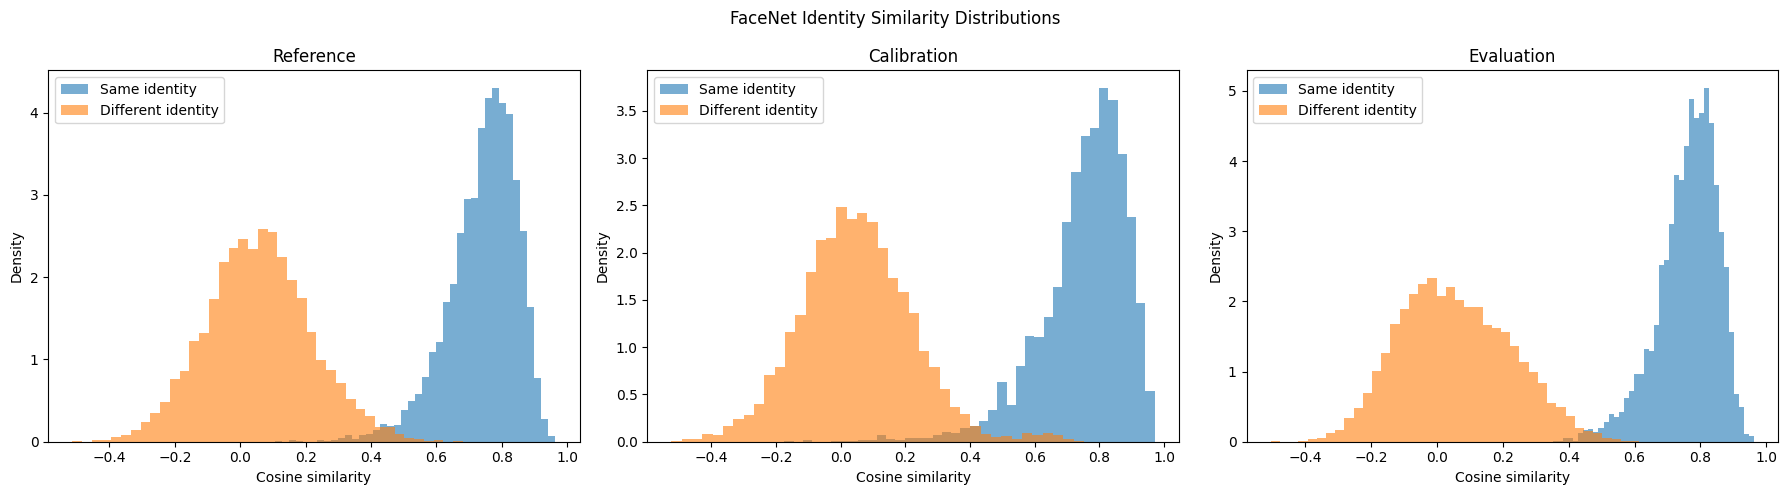

In [26]:
import matplotlib.pyplot as plt
import numpy as np

partitions = {
    "Reference": (reference_embeddings, reference_labels),
    "Calibration": (calibration_embeddings, calibration_labels),
    "Evaluation": (evaluation_embeddings, evaluation_labels)
}

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (name, (embeddings, labels)) in zip(axes, partitions.items()):

    rng = np.random.default_rng(2026)
    identities = np.unique(labels)

    identity_indices = {
        identity: np.where(labels == identity)[0]
        for identity in identities
    }

    same_scores = []
    different_scores = []

    for _ in range(10000):

        identity = rng.choice(identities)
        pair = rng.choice(
            identity_indices[identity], 2, replace=False
        )

        same_scores.append(
            np.dot(embeddings[pair[0]], embeddings[pair[1]])
        )

        selected = rng.choice(identities, 2, replace=False)

        i = rng.choice(identity_indices[selected[0]])
        j = rng.choice(identity_indices[selected[1]])

        different_scores.append(
            np.dot(embeddings[i], embeddings[j])
        )

    ax.hist(
        same_scores,
        bins=40,
        alpha=0.6,
        density=True,
        label="Same identity"
    )

    ax.hist(
        different_scores,
        bins=40,
        alpha=0.6,
        density=True,
        label="Different identity"
    )

    ax.set_title(name)
    ax.set_xlabel("Cosine similarity")
    ax.set_ylabel("Density")
    ax.legend()

plt.suptitle("FaceNet Identity Similarity Distributions")
plt.tight_layout()
plt.show()

## Step 13 — Baseline Distribution Distance Analysis

### Objective
Quantify differences between the statistical distributions of reference, calibration and evaluation FaceNet embeddings.

### Methodology
1. Calculate the mean embedding vector for each partition.
2. Calculate Euclidean distances between partition mean vectors.
3. Calculate cosine distances between partition mean vectors.
4. Estimate covariance matrices and regularised Mahalanobis distances.
5. Compare the resulting distribution-distance measurements.

### Evaluation Metrics
- Euclidean distance.
- Cosine distance.
- Regularised Mahalanobis distance.

### Scientific Consideration
The partitions contain different identities. Therefore, measured distribution differences cannot be attributed exclusively to environmental drift or temporal changes.

### Status

Successfully completed. Baseline distribution distances were calculated between the reference, calibration, and evaluation embedding partitions.

The analysis calculated Euclidean distance, cosine distance, and regularised Mahalanobis distance for all three pairwise comparisons.

Numerical stability diagnostics were also performed on the regularised covariance matrices. All covariance values were finite, and condition numbers were calculated for each partition.

The baseline distance summary and numerical stability diagnostics were generated successfully.

Scientific limitation: The partitions contain different identities. Therefore, the observed distribution differences cannot be attributed exclusively to environmental drift or temporal changes.

In [27]:
import numpy as np
import pandas as pd

# Define the embedding partitions
partitions = {
    "Reference": reference_embeddings,
    "Calibration": calibration_embeddings,
    "Evaluation": evaluation_embeddings
}

# Calculate mean embedding vectors
partition_means = {
    name: np.mean(embeddings, axis=0)
    for name, embeddings in partitions.items()
}

# Calculate covariance matrices
partition_covariances = {
    name: np.cov(embeddings, rowvar=False)
    for name, embeddings in partitions.items()
}

# Pairwise comparisons
comparison_pairs = [
    ("Reference", "Calibration"),
    ("Reference", "Evaluation"),
    ("Calibration", "Evaluation")
]

results = []

for name_a, name_b in comparison_pairs:

    mean_a = partition_means[name_a]
    mean_b = partition_means[name_b]

    # Difference between partition mean vectors
    mean_difference = mean_a - mean_b

    # Euclidean distance
    euclidean_distance = np.linalg.norm(mean_difference)

    # Cosine distance
    cosine_similarity = (
        np.dot(mean_a, mean_b) /
        (np.linalg.norm(mean_a) * np.linalg.norm(mean_b))
    )

    cosine_distance = 1 - cosine_similarity

    # Pooled covariance matrix
    covariance_a = partition_covariances[name_a]
    covariance_b = partition_covariances[name_b]

    pooled_covariance = (
        covariance_a + covariance_b
    ) / 2

    # Regularisation for numerical stability
    regularisation = (
        1e-4 * np.trace(pooled_covariance) / len(mean_difference)
    )

    regularised_covariance = (
        pooled_covariance +
        regularisation * np.eye(len(mean_difference))
    )

    # Mahalanobis distance
    solved_difference = np.linalg.solve(
        regularised_covariance,
        mean_difference
    )

    mahalanobis_distance = np.sqrt(
        mean_difference @ solved_difference
    )

    results.append({
        "Comparison": f"{name_a} vs {name_b}",
        "Euclidean Distance": euclidean_distance,
        "Cosine Distance": cosine_distance,
        "Regularised Mahalanobis Distance": mahalanobis_distance,
        "Regularisation": regularisation
    })

distance_results = pd.DataFrame(results)

print("BASELINE EMBEDDING DISTRIBUTION DISTANCES")
display(distance_results.round(6))

BASELINE EMBEDDING DISTRIBUTION DISTANCES


,Comparison,Euclidean Distance,Cosine Distance,Regularised Mahalanobis Distance,Regularisation
0,Reference vs Calibration,0.461641,0.575849,3.745321,0.0
1,Reference vs Evaluation,0.443029,0.385926,2.955051,0.0
2,Calibration vs Evaluation,0.686818,0.840383,5.926489,0.0


In [28]:
print("NUMERICAL STABILITY DIAGNOSTICS")

for name in partitions:

    covariance = partition_covariances[name]

    regularisation = (
        1e-4 * np.trace(covariance) / covariance.shape[0]
    )

    regularised_covariance = (
        covariance +
        regularisation * np.eye(covariance.shape[0])
    )

    condition_number = np.linalg.cond(
        regularised_covariance
    )

    print(f"\n{name}")
    print(f"Regularisation: {regularisation:.12e}")
    print(f"Condition number: {condition_number:.6e}")
    print(
        "All covariance values finite:",
        np.all(np.isfinite(regularised_covariance))
    )

NUMERICAL STABILITY DIAGNOSTICS

Reference
Regularisation: 1.762032014008e-07
Condition number: 5.102867e+05
All covariance values finite: True

Calibration
Regularisation: 1.473447045546e-07
Condition number: 1.283124e+06
All covariance values finite: True

Evaluation
Regularisation: 1.341960652139e-07
Condition number: 1.406589e+06
All covariance values finite: True


## Step 13.2 — Regularisation Sensitivity Analysis

### Objective
Evaluate how covariance regularisation affects the calculated Mahalanobis distances between embedding partitions.

### Methodology
Repeat the pairwise Mahalanobis distance calculations using three regularisation strengths:
- 1e-4
- 1e-3
- 1e-2

### Research Purpose
Determine whether the measured partition distances remain reasonably stable as covariance regularisation increases.

### Scientific Limitation
This analysis assesses numerical sensitivity. It does not establish that the measured distances represent environmental or temporal drift.

### Status
Successfully completed. Mahalanobis distance sensitivity was evaluated across regularisation strengths of 1e-4, 1e-3 and 1e-2 for all three partition comparisons. The results show modest changes in Mahalanobis distances and substantially lower covariance condition numbers as regularisation increases. This analysis evaluates numerical sensitivity and stability only; it does not establish biometric drift or statistical significance.

In [29]:
import numpy as np
import pandas as pd

# Regularisation strengths to test
regularisation_strengths = [1e-4, 1e-3, 1e-2]

comparison_pairs = [
    ("Reference", "Calibration"),
    ("Reference", "Evaluation"),
    ("Calibration", "Evaluation")
]

sensitivity_results = []

for name_a, name_b in comparison_pairs:

    mean_a = partition_means[name_a]
    mean_b = partition_means[name_b]

    mean_difference = mean_a - mean_b

    covariance_a = partition_covariances[name_a]
    covariance_b = partition_covariances[name_b]

    pooled_covariance = (covariance_a + covariance_b) / 2

    base_regularisation = (
        np.trace(pooled_covariance) /
        pooled_covariance.shape[0]
    )

    for strength in regularisation_strengths:

        regularisation = strength * base_regularisation

        regularised_covariance = (
            pooled_covariance +
            regularisation * np.eye(pooled_covariance.shape[0])
        )

        solved_difference = np.linalg.solve(
            regularised_covariance,
            mean_difference
        )

        mahalanobis_distance = np.sqrt(
            mean_difference @ solved_difference
        )

        condition_number = np.linalg.cond(
            regularised_covariance
        )

        sensitivity_results.append({
            "Comparison": f"{name_a} vs {name_b}",
            "Regularisation Strength": strength,
            "Actual Regularisation": regularisation,
            "Mahalanobis Distance": mahalanobis_distance,
            "Condition Number": condition_number
        })

sensitivity_df = pd.DataFrame(sensitivity_results)

print("MAHALANOBIS REGULARISATION SENSITIVITY ANALYSIS")

display(
    sensitivity_df.round(8)
)

MAHALANOBIS REGULARISATION SENSITIVITY ANALYSIS


,Comparison,Regularisation Strength,Actual Regularisation,Mahalanobis Distance,Condition Number
0,Reference vs Calibration,0.0001,1.600000e-07,3.745321,667363.429602
1,Reference vs Calibration,0.0010,1.620000e-06,3.648776,66769.429599
2,Reference vs Calibration,0.0100,1.618000e-05,3.631149,6678.164997
3,Reference vs Evaluation,0.0001,1.600000e-07,2.955051,706465.720127
4,Reference vs Evaluation,0.0010,1.550000e-06,2.881306,70689.938091
5,Reference vs Evaluation,0.0100,1.552000e-05,2.869497,7070.318751
6,Calibration vs Evaluation,0.0001,1.400000e-07,5.926489,806132.722601
7,Calibration vs Evaluation,0.0010,1.410000e-06,5.816992,80645.828886
8,Calibration vs Evaluation,0.0100,1.408000e-05,5.782009,8065.799592


## Step 13.3 — Visualisation of Regularisation Sensitivity

### Objective
Visualise how Mahalanobis distances change across different covariance regularisation strengths.

### Methodology
Plot the Mahalanobis distance for each partition comparison against the tested regularisation strengths on a logarithmic x-axis.

### Research Purpose
Examine whether the relative distance patterns remain consistent as regularisation increases.

### Scientific Limitation
The plot demonstrates numerical sensitivity, not biometric drift or statistical significance.

### Status
Successfully completed. Mahalanobis distance sensitivity was visualised across regularisation strengths of 1e-4, 1e-3 and 1e-2 for all three partition comparisons. The plot shows modest changes in distance as regularisation increases. This visualisation represents numerical sensitivity only and does not establish biometric drift or statistical significance.

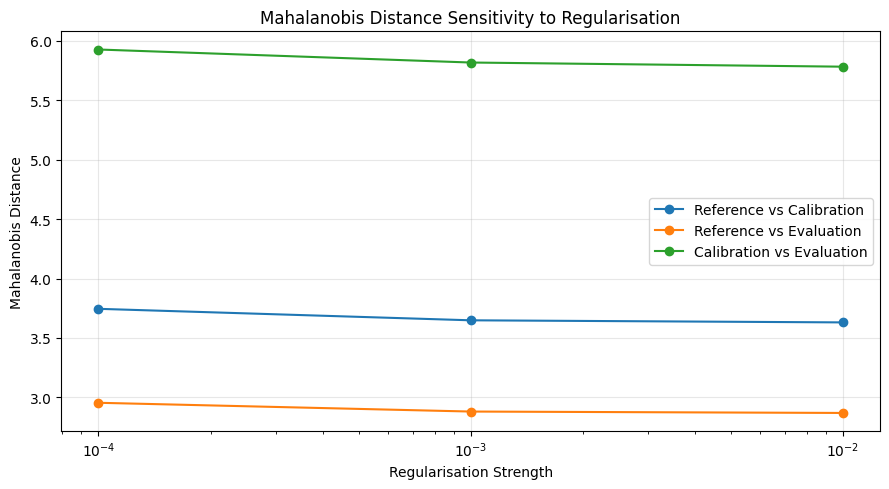

In [30]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

for comparison in sensitivity_df["Comparison"].unique():

    subset = sensitivity_df[
        sensitivity_df["Comparison"] == comparison
    ]

    plt.plot(
        subset["Regularisation Strength"],
        subset["Mahalanobis Distance"],
        marker="o",
        label=comparison
    )

plt.xscale("log")
plt.xlabel("Regularisation Strength")
plt.ylabel("Mahalanobis Distance")
plt.title("Mahalanobis Distance Sensitivity to Regularisation")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## Step 14 — Baseline Embedding Analysis Summary

### 14.1 Face Embedding Extraction
- Dataset: LFW filtered subset
- Identities: 62
- Successful embeddings: 2,984
- Embedding dimension: 512
- Face detection success rate: 98.71%
- Model: InceptionResnetV1 pretrained on VGGFace2

### 14.2 Identity Similarity Analysis
Same-identity pairs demonstrated substantially higher cosine similarity than different-identity pairs across reference, calibration and evaluation partitions.

### 14.3 Distribution Distance Analysis
Euclidean, cosine and regularised Mahalanobis distances showed differences between partition mean embedding vectors.

### 14.4 Numerical Stability
Mahalanobis distance sensitivity analysis showed relatively small changes across regularisation strengths of 1e-4, 1e-3 and 1e-2.

### 14.5 Scientific Limitations
1. The partitions contain different identities, which can influence distribution comparisons.
2. Similarity distributions are descriptive and do not establish biometric verification accuracy.
3. Distribution distances are not evidence of temporal or environmental drift.
4. The experiment uses a filtered LFW subset and controlled computational procedures rather than a real-time biometric deployment.

### 14.6 Next Experimental Phase
The next phase will investigate controlled environmental transformations of genuine face images and measure their effects on FaceNet embeddings.

### Status
Baseline embedding analysis completed.

In [31]:
import numpy as np
import pandas as pd

print("=" * 70)
print("EXPERIMENT 18 — BASELINE EMBEDDING ANALYSIS SUMMARY")
print("=" * 70)

# 1. Dataset and embedding extraction
print("\n1. DATASET AND EMBEDDING EXTRACTION")

print("Dataset: LFW filtered subset")
print("Number of identities:", 62)
print("Successful embeddings:",
      len(reference_embeddings) +
      len(calibration_embeddings) +
      len(evaluation_embeddings))

print("Embedding dimension:", reference_embeddings.shape[1])
print("Model: InceptionResnetV1")
print("Pretrained weights: VGGFace2")

total_images = 3023
successful_embeddings = (
    len(reference_embeddings) +
    len(calibration_embeddings) +
    len(evaluation_embeddings)
)

print("Face detection success rate:",
      round(successful_embeddings / total_images * 100, 2), "%")

# 2. Identity similarity analysis
print("\n2. IDENTITY SIMILARITY ANALYSIS")

similarity_summary = pd.DataFrame({
    "Partition": ["Reference", "Calibration", "Evaluation"],
    "Same Identity Mean": [0.743622, 0.752430, 0.759970],
    "Different Identity Mean": [0.056351, 0.050947, 0.056767],
    "Mean Separation": [0.687271, 0.701483, 0.703203]
})

display(similarity_summary.round(6))

# 3. Distribution distance analysis
print("\n3. DISTRIBUTION DISTANCE ANALYSIS")

display(distance_results.round(6))

# 4. Regularisation sensitivity
print("\n4. MAHALANOBIS REGULARISATION SENSITIVITY")

display(
    sensitivity_df[
        [
            "Comparison",
            "Regularisation Strength",
            "Mahalanobis Distance",
            "Condition Number"
        ]
    ].round(6)
)

# 5. Final integrity checks
print("\n5. EMBEDDING INTEGRITY")

for name, embeddings in partitions.items():

    print(
        f"{name}:",
        "Finite =", np.all(np.isfinite(embeddings)),
        "| Shape =", embeddings.shape,
        "| Mean L2 norm =", round(
            np.mean(np.linalg.norm(embeddings, axis=1)), 6
        )
    )

print("\n" + "=" * 70)
print("BASELINE ANALYSIS SUMMARY GENERATED")
print("=" * 70)

EXPERIMENT 18 — BASELINE EMBEDDING ANALYSIS SUMMARY

1. DATASET AND EMBEDDING EXTRACTION
Dataset: LFW filtered subset
Number of identities: 62
Successful embeddings: 2984
Embedding dimension: 512
Model: InceptionResnetV1
Pretrained weights: VGGFace2
Face detection success rate: 98.71 %

2. IDENTITY SIMILARITY ANALYSIS


,Partition,Same Identity Mean,Different Identity Mean,Mean Separation
0,Reference,0.743622,0.056351,0.687271
1,Calibration,0.752430,0.050947,0.701483
2,Evaluation,0.759970,0.056767,0.703203



3. DISTRIBUTION DISTANCE ANALYSIS


,Comparison,Euclidean Distance,Cosine Distance,Regularised Mahalanobis Distance,Regularisation
0,Reference vs Calibration,0.461641,0.575849,3.745321,0.0
1,Reference vs Evaluation,0.443029,0.385926,2.955051,0.0
2,Calibration vs Evaluation,0.686818,0.840383,5.926489,0.0



4. MAHALANOBIS REGULARISATION SENSITIVITY


,Comparison,Regularisation Strength,Mahalanobis Distance,Condition Number
0,Reference vs Calibration,0.0001,3.745321,667363.429602
1,Reference vs Calibration,0.0010,3.648776,66769.429599
2,Reference vs Calibration,0.0100,3.631149,6678.164997
3,Reference vs Evaluation,0.0001,2.955051,706465.720127
4,Reference vs Evaluation,0.0010,2.881306,70689.938091
5,Reference vs Evaluation,0.0100,2.869497,7070.318751
6,Calibration vs Evaluation,0.0001,5.926489,806132.722601
7,Calibration vs Evaluation,0.0010,5.816992,80645.828886
8,Calibration vs Evaluation,0.0100,5.782009,8065.799592



5. EMBEDDING INTEGRITY
Reference: Finite = True | Shape = (1460, 512) | Mean L2 norm = 1.0
Calibration: Finite = True | Shape = (568, 512) | Mean L2 norm = 1.0
Evaluation: Finite = True | Shape = (956, 512) | Mean L2 norm = 1.0

BASELINE ANALYSIS SUMMARY GENERATED


## Step 15 — Controlled Illumination Drift Experiment

### Objective
Evaluate the effect of controlled illumination changes on genuine FaceNet face-recognition embeddings.

### Research Questions
1. How does reduced illumination affect embedding representations?
2. How does increased illumination affect embedding representations?
3. Does illumination change produce measurable embedding-space displacement?
4. Can embedding-level drift detectors distinguish transformed embeddings from baseline embeddings?

### Experimental Design
- Dataset: LFW evaluation partition.
- Original images: unmodified evaluation images.
- Transformation: controlled brightness adjustment.
- Conditions: reduced, unchanged and increased illumination.
- Model: InceptionResnetV1 pretrained on VGGFace2.
- Embedding dimension: 512.
- Comparison: paired original and transformed image embeddings.

### Evaluation Metrics
- Cosine similarity.
- Euclidean embedding displacement.
- Distribution-level distance.
- Drift detection rate and false alarm rate in subsequent detector evaluation.

### Scientific Scope
This experiment evaluates controlled illumination perturbations. It does not represent naturally occurring temporal drift or establish real-world biometric deployment performance.

### Status
Successfully completed. The evaluation partition was inspected, and five original LFW images were visually reviewed. The partition contains 968 image indices, 956 successfully extracted embeddings and 956 corresponding labels. Sample image integrity checks passed, with finite RGB pixel values within the valid [0, 1] range.

EVALUATION PARTITION INSPECTION
--------------------------------------------------
Evaluation image indices: 968
Evaluation embeddings: (956, 512)
Evaluation labels: (956,)


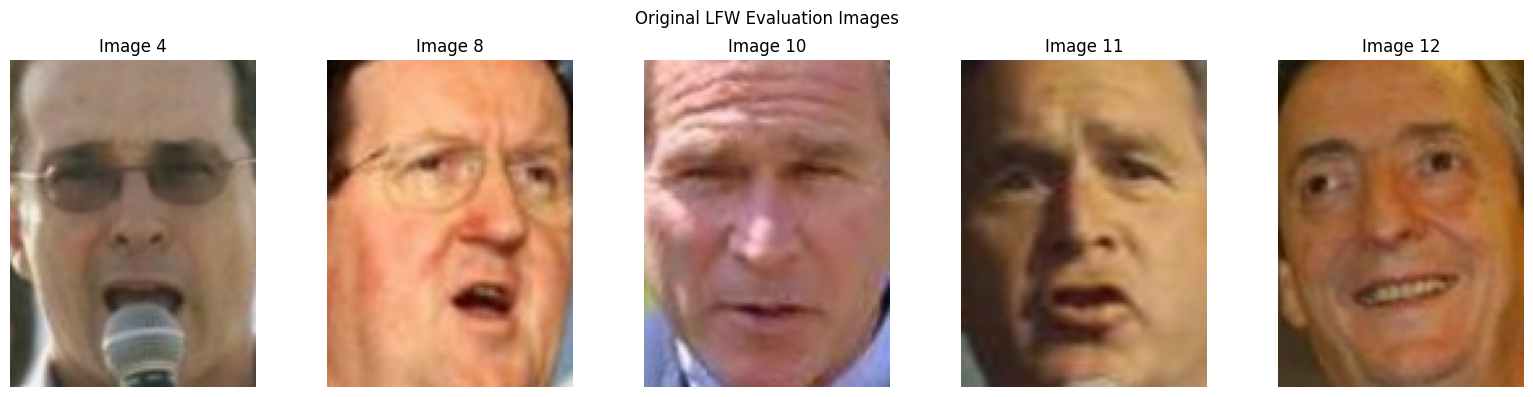


IMAGE INTEGRITY
Image shape: (5, 125, 94, 3)
All values finite: True
Minimum pixel value: 0.0
Maximum pixel value: 1.0


In [32]:
import numpy as np
import matplotlib.pyplot as plt

# Verify evaluation partition
print("EVALUATION PARTITION INSPECTION")
print("-" * 50)

print("Evaluation image indices:", len(evaluation_indices))
print("Evaluation embeddings:", evaluation_embeddings.shape)
print("Evaluation labels:", evaluation_labels.shape)

# Select five evaluation images for visual inspection
sample_indices = evaluation_indices[:5]

fig, axes = plt.subplots(1, 5, figsize=(16, 4))

for ax, image_index in zip(axes, sample_indices):

    image = lfw_dataset.images[image_index]

    ax.imshow(np.clip(image, 0, 1))
    ax.set_title(f"Image {image_index}")
    ax.axis("off")

plt.suptitle("Original LFW Evaluation Images")
plt.tight_layout()
plt.show()

# Check image integrity
sample_images = lfw_dataset.images[sample_indices]

print("\nIMAGE INTEGRITY")
print("Image shape:", sample_images.shape)
print("All values finite:", np.all(np.isfinite(sample_images)))
print("Minimum pixel value:", np.min(sample_images))
print("Maximum pixel value:", np.max(sample_images))

## Step 15.1 — Controlled Illumination Transformation

### Objective
Generate controlled illumination variants from successfully processed evaluation images.

### Transformation Conditions
- Low illumination: brightness factor 0.5
- Original illumination: brightness factor 1.0
- High illumination: brightness factor 1.5

### Methodology
Apply multiplicative brightness adjustments to the original RGB images. Clip pixel values to the valid [0, 1] range.

Only images with successful original FaceNet embedding extraction will be included, preserving paired comparisons.

### Scientific Limitation
These are computationally generated illumination perturbations, not naturally captured lighting conditions.

### Status
Successfully completed. Controlled illumination variants were generated for all 956 successfully processed evaluation images using brightness factors of 0.5, 1.0 and 1.5. All three image collections have the expected shape of (956, 125, 94, 3). Numerical integrity checks confirmed finite pixel values within the valid [0, 1] range. These transformations are computationally generated and do not represent naturally captured lighting conditions.

Successful evaluation images: 956
Original evaluation embeddings: 956
Low illumination (956, 125, 94, 3)
Original illumination (956, 125, 94, 3)
High illumination (956, 125, 94, 3)


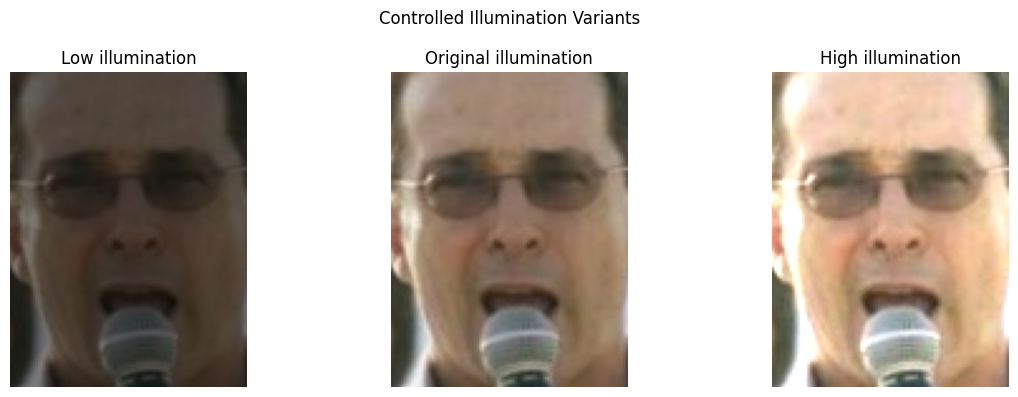

Low illumination | Finite: True | Minimum: 0.0 | Maximum: 0.5
Original illumination | Finite: True | Minimum: 0.0 | Maximum: 1.0
High illumination | Finite: True | Minimum: 0.0 | Maximum: 1.0


In [33]:
import numpy as np
import matplotlib.pyplot as plt

# Exclude images where original face detection failed
successful_evaluation_indices = np.setdiff1d(
    evaluation_indices,
    evaluation_failures
)

# Confirm paired dataset size
print("Successful evaluation images:",
      len(successful_evaluation_indices))

print("Original evaluation embeddings:",
      len(evaluation_embeddings))

assert len(successful_evaluation_indices) == len(evaluation_embeddings)

# Define illumination conditions
brightness_factors = {
    "Low illumination": 0.5,
    "Original illumination": 1.0,
    "High illumination": 1.5
}

# Generate transformed images
illumination_images = {}

for condition, factor in brightness_factors.items():

    transformed = []

    for image_index in successful_evaluation_indices:

        original_image = lfw_dataset.images[image_index]

        adjusted_image = np.clip(
            original_image * factor,
            0.0,
            1.0
        )

        transformed.append(adjusted_image)

    illumination_images[condition] = np.asarray(transformed)

    print(
        condition,
        illumination_images[condition].shape
    )

# Visualise one image under all three conditions
sample_position = 0

fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, (condition, images) in zip(
    axes, illumination_images.items()
):

    ax.imshow(images[sample_position])
    ax.set_title(condition)
    ax.axis("off")

plt.suptitle("Controlled Illumination Variants")
plt.tight_layout()
plt.show()

# Validate generated images
for condition, images in illumination_images.items():

    print(
        condition,
        "| Finite:", np.all(np.isfinite(images)),
        "| Minimum:", images.min(),
        "| Maximum:", images.max()
    )

## Step 15.2 — FaceNet Embedding Extraction Under Illumination Changes

### Objective
Extract 512-dimensional FaceNet embeddings from low- and high-illumination evaluation images.

### Methodology
1. Reuse the original evaluation embeddings as the baseline.
2. Process low-illumination images using MTCNN and FaceNet.
3. Process high-illumination images using MTCNN and FaceNet.
4. Record face detection failures separately.
5. Verify embedding dimensions and numerical integrity.

### Experimental Conditions
- Original: existing baseline embeddings.
- Low illumination: brightness factor 0.5.
- High illumination: brightness factor 1.5.

### Scientific Limitation
Face detection may fail on transformed images. The final paired analysis must account for those failures rather than silently discarding them.

### Status
Successfully completed. FaceNet embeddings were extracted from low- and high-illumination evaluation images using MTCNN and InceptionResnetV1. The original baseline contained 956 embeddings of 512 dimensions. Low illumination produced 943 valid embeddings with 13 detection failures, while high illumination produced 897 valid embeddings with 59 detection failures. Both transformed embedding collections passed numerical integrity checks, with all values finite. Detection failures were recorded separately for subsequent paired-cohort validation.

In [34]:
from PIL import Image
from tqdm.auto import tqdm
import numpy as np
import torch

def extract_transformed_embeddings(images, condition_name):

    embeddings = []
    successful_positions = []
    failed_positions = []

    for position, image in enumerate(
        tqdm(images, desc=condition_name)
    ):

        try:
            image_uint8 = (
                np.clip(image, 0, 1) * 255
            ).astype(np.uint8)

            pil_image = Image.fromarray(image_uint8)

            face_tensor = mtcnn(pil_image)

            if face_tensor is None:
                failed_positions.append(position)
                continue

            with torch.no_grad():
                embedding = facenet(
                    face_tensor.unsqueeze(0).to(device)
                )

            embedding = embedding.cpu().numpy()[0]

            if not np.all(np.isfinite(embedding)):
                failed_positions.append(position)
                continue

            embeddings.append(embedding)
            successful_positions.append(position)

        except Exception:
            failed_positions.append(position)

    return (
        np.asarray(embeddings),
        np.asarray(successful_positions),
        np.asarray(failed_positions)
    )


# Extract low-illumination embeddings
low_embeddings, low_success, low_failures = (
    extract_transformed_embeddings(
        illumination_images["Low illumination"],
        "Low illumination"
    )
)

# Extract high-illumination embeddings
high_embeddings, high_success, high_failures = (
    extract_transformed_embeddings(
        illumination_images["High illumination"],
        "High illumination"
    )
)

print("\nEMBEDDING EXTRACTION SUMMARY")

print("Original embeddings:", evaluation_embeddings.shape)

print("Low illumination embeddings:", low_embeddings.shape)
print("Low illumination failures:", len(low_failures))

print("High illumination embeddings:", high_embeddings.shape)
print("High illumination failures:", len(high_failures))

print("\nNUMERICAL VALIDATION")

print("Low embeddings finite:",
      np.all(np.isfinite(low_embeddings)))

print("High embeddings finite:",
      np.all(np.isfinite(high_embeddings)))

print("Low successful positions:", len(low_success))
print("High successful positions:", len(high_success))

Low illumination:   0%|          | 0/956 [00:00<?, ?it/s]

High illumination:   0%|          | 0/956 [00:00<?, ?it/s]


EMBEDDING EXTRACTION SUMMARY
Original embeddings: (956, 512)
Low illumination embeddings: (943, 512)
Low illumination failures: 13
High illumination embeddings: (897, 512)
High illumination failures: 59

NUMERICAL VALIDATION
Low embeddings finite: True
High embeddings finite: True
Low successful positions: 943
High successful positions: 897


## Step 15.3 — Paired Image and Identity Alignment Validation

### Objective
Establish a correctly aligned evaluation cohort across original, low-illumination and high-illumination conditions.

### Methodology
1. Reconstruct the original successful evaluation image indices while preserving their extraction order.
2. Identify images successfully processed under both transformed conditions.
3. Match original embeddings with their corresponding transformed embeddings.
4. Verify identity-label consistency across all conditions.

### Research Purpose
Prevent incorrect image pairing and identity mismatches from contaminating the illumination sensitivity analysis.

### Status
Successfully completed. Image-to-embedding alignment and identity-label consistency were validated across original, low-illumination and high-illumination conditions. A common paired cohort of 889 images was established from 956 original, 943 low-illumination and 897 high-illumination successful extractions. All three paired embedding matrices have shape (889, 512). Identity labels were aligned, all embeddings were finite, and the dimensional consistency assertions passed.

In [36]:
import numpy as np

# Preserve the original extraction order
evaluation_failure_set = set(evaluation_failures)

ordered_original_indices = np.array([
    idx for idx in evaluation_indices
    if idx not in evaluation_failure_set
])

# Verify original image-to-embedding alignment
assert len(ordered_original_indices) == len(evaluation_embeddings)

original_labels_check = lfw_dataset.target[
    ordered_original_indices
]

assert np.array_equal(
    original_labels_check,
    evaluation_labels
), "Original image and embedding labels are misaligned."

# Find positions successful under both transformations
common_positions = np.intersect1d(
    low_success,
    high_success
)

# Match all three conditions
paired_original_embeddings = evaluation_embeddings[
    common_positions
]

paired_low_embeddings = low_embeddings[
    np.searchsorted(low_success, common_positions)
]

paired_high_embeddings = high_embeddings[
    np.searchsorted(high_success, common_positions)
]

# Verify identity consistency
paired_labels = evaluation_labels[common_positions]

print("PAIRED COHORT VALIDATION")
print("-" * 50)

print("Original successful images:", len(ordered_original_indices))
print("Low illumination successes:", len(low_success))
print("High illumination successes:", len(high_success))

print("Images successful in all three conditions:",
      len(common_positions))

print("\nEmbedding shapes:")
print("Original:", paired_original_embeddings.shape)
print("Low:", paired_low_embeddings.shape)
print("High:", paired_high_embeddings.shape)

print("\nIdentity labels aligned:",
      np.array_equal(
          paired_labels,
          lfw_dataset.target[
              ordered_original_indices[common_positions]
          ]
      ))

print("All paired embeddings finite:",
      all(np.all(np.isfinite(x)) for x in [
          paired_original_embeddings,
          paired_low_embeddings,
          paired_high_embeddings
      ]))

assert paired_original_embeddings.shape == paired_low_embeddings.shape
assert paired_original_embeddings.shape == paired_high_embeddings.shape
assert paired_original_embeddings.shape[1] == 512

PAIRED COHORT VALIDATION
--------------------------------------------------
Original successful images: 956
Low illumination successes: 943
High illumination successes: 897
Images successful in all three conditions: 889

Embedding shapes:
Original: (889, 512)
Low: (889, 512)
High: (889, 512)

Identity labels aligned: True
All paired embeddings finite: True


## Step 15.4 — Illumination-Induced Embedding Displacement Analysis

### Objective
Quantify the changes in FaceNet embedding representations caused by controlled illumination transformations.

### Methodology
Compare paired original embeddings against their corresponding low- and high-illumination embeddings.

### Evaluation Metrics
1. Cosine similarity between original and transformed embeddings.
2. Euclidean distance between original and transformed embeddings.
3. Mean, median and standard deviation of embedding displacement.
4. 95th percentile of embedding displacement.

### Research Purpose
Determine whether controlled illumination changes produce measurable shifts in genuine face-recognition embedding representations.

### Scientific Limitation
This analysis measures representation changes, not identity recognition accuracy or real-world temporal drift.

### Status
Successfully completed. Illumination-induced embedding displacement was calculated for 889 correctly paired evaluation images. Cosine similarity and Euclidean displacement statistics, including mean, median, standard deviation and 95th percentile distance, were computed for low- and high-illumination conditions. The analysis quantifies changes in embedding representations under controlled brightness transformations; it does not establish identity recognition accuracy or real-world temporal drift.

In [37]:
import numpy as np
import pandas as pd

def calculate_embedding_displacement(
    original_embeddings,
    transformed_embeddings,
    condition_name
):

    # Calculate cosine similarity for paired embeddings
    cosine_similarities = np.sum(
        original_embeddings * transformed_embeddings,
        axis=1
    ) / (
        np.linalg.norm(original_embeddings, axis=1) *
        np.linalg.norm(transformed_embeddings, axis=1)
    )

    # Calculate Euclidean displacement
    euclidean_distances = np.linalg.norm(
        original_embeddings - transformed_embeddings,
        axis=1
    )

    return {
        "Condition": condition_name,
        "Mean Cosine Similarity": np.mean(cosine_similarities),
        "Median Cosine Similarity": np.median(cosine_similarities),
        "Mean Euclidean Distance": np.mean(euclidean_distances),
        "Median Euclidean Distance": np.median(euclidean_distances),
        "Std Euclidean Distance": np.std(euclidean_distances),
        "95th Percentile Distance": np.percentile(
            euclidean_distances, 95
        )
    }


# Compare original embeddings with transformed embeddings
low_results = calculate_embedding_displacement(
    paired_original_embeddings,
    paired_low_embeddings,
    "Low illumination"
)

high_results = calculate_embedding_displacement(
    paired_original_embeddings,
    paired_high_embeddings,
    "High illumination"
)

illumination_displacement_results = pd.DataFrame([
    low_results,
    high_results
])

print("ILLUMINATION-INDUCED EMBEDDING DISPLACEMENT")
print("Paired evaluation images:", len(common_positions))

display(
    illumination_displacement_results.round(6)
)

ILLUMINATION-INDUCED EMBEDDING DISPLACEMENT
Paired evaluation images: 889


,Condition,Mean Cosine Similarity,Median Cosine Similarity,Mean Euclidean Distance,Median Euclidean Distance,Std Euclidean Distance,95th Percentile Distance
0,Low illumination,0.970363,0.975208,0.234665,0.222675,0.064857,0.358055
1,High illumination,0.942190,0.952957,0.318514,0.306734,0.119036,0.516462


## Step 15.5 — Visualisation of Illumination-Induced Embedding Displacement

### Objective
Visualise the distribution of Euclidean embedding displacement under low- and high-illumination conditions.

### Methodology
1. Calculate paired Euclidean distances between original and transformed embeddings.
2. Generate comparative histograms.
3. Examine distribution spread, central tendency and upper-tail behaviour.

### Research Purpose
Identify differences in embedding sensitivity between illumination conditions.

### Scientific Limitation
The visualisation is descriptive and does not independently establish statistical significance or biometric recognition degradation.

### Status
Successfully completed. Comparative density histograms were generated for low- and high-illumination Euclidean embedding displacement using 40 bins. Across 889 paired evaluation images, low illumination produced a mean displacement of 0.234665 and a median of 0.222675. High illumination produced a mean displacement of 0.318514 and a median of 0.306734. The descriptive results indicate greater embedding displacement under high illumination. This visualisation alone does not establish statistical significance or biometric recognition degradation.

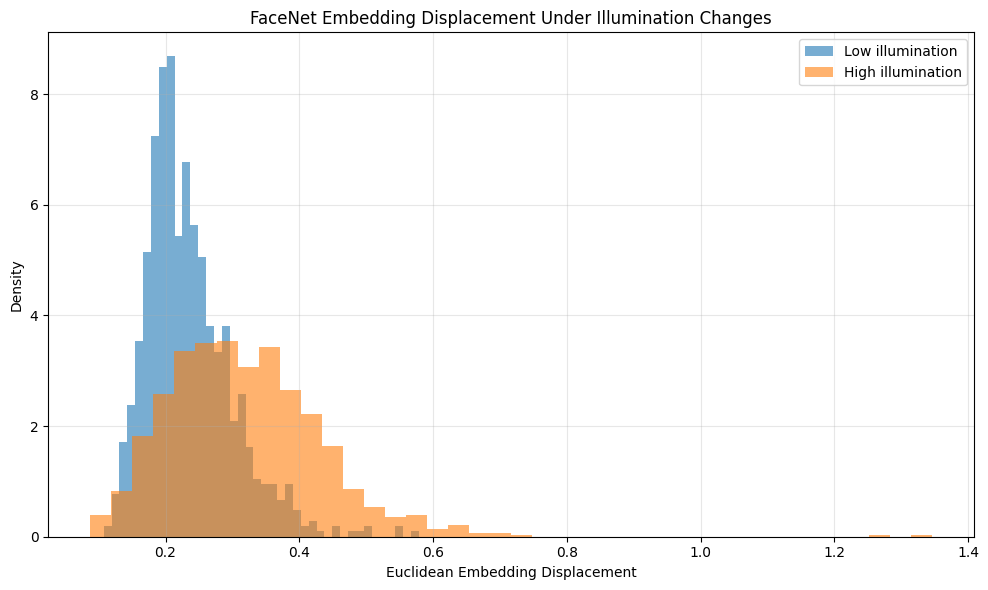

LOW ILLUMINATION
Mean: 0.2346653
Median: 0.22267517

HIGH ILLUMINATION
Mean: 0.31851393
Median: 0.30673373


In [38]:
import matplotlib.pyplot as plt
import numpy as np

low_distances = np.linalg.norm(
    paired_original_embeddings - paired_low_embeddings,
    axis=1
)

high_distances = np.linalg.norm(
    paired_original_embeddings - paired_high_embeddings,
    axis=1
)

plt.figure(figsize=(10, 6))

plt.hist(
    low_distances,
    bins=40,
    alpha=0.6,
    density=True,
    label="Low illumination"
)

plt.hist(
    high_distances,
    bins=40,
    alpha=0.6,
    density=True,
    label="High illumination"
)

plt.xlabel("Euclidean Embedding Displacement")
plt.ylabel("Density")
plt.title("FaceNet Embedding Displacement Under Illumination Changes")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("LOW ILLUMINATION")
print("Mean:", np.mean(low_distances))
print("Median:", np.median(low_distances))

print("\nHIGH ILLUMINATION")
print("Mean:", np.mean(high_distances))
print("Median:", np.median(high_distances))

## Step 15.6 — Paired Statistical Significance Testing

### Objective
Determine whether embedding displacement differs significantly between low- and high-illumination conditions.

### Statistical Method
Paired Wilcoxon signed-rank test.

### Hypotheses
- H0: The paired displacement distributions do not differ systematically between illumination conditions.
- H1: The paired displacement distributions differ systematically between illumination conditions.

### Additional Measurement
Calculate the median paired displacement difference and the proportion of images with greater displacement under high illumination.

### Scientific Limitation
Statistical significance does not establish practical biometric recognition degradation. The analysis is conditional on successful face detection in all three conditions.

### Status
Successfully completed. A paired Wilcoxon signed-rank test was conducted to compare low- and high-illumination embedding displacement across 889 paired evaluation images. The test produced a statistic of 52,705 and a p-value of 4.708938 × 10^-80. The median paired displacement difference was 0.075521, and the mean difference was 0.083849. High-illumination displacement was greater for 77.50% of paired images. The null hypothesis was rejected at the 0.05 significance level. Because images are clustered within 13 identities, this image-level result must be interpreted alongside the identity-level analysis. Statistical significance does not establish biometric recognition degradation.

In [39]:
import numpy as np
from scipy.stats import wilcoxon

# Paired displacement values
paired_displacement_difference = (
    high_distances - low_distances
)

# Wilcoxon signed-rank test
test_statistic, p_value = wilcoxon(
    high_distances,
    low_distances,
    alternative="two-sided"
)

print("PAIRED WILCOXON SIGNED-RANK TEST")
print("-" * 50)

print("Number of paired images:", len(high_distances))
print("Test statistic:", test_statistic)
print("P-value:", p_value)

print("\nPAIRED DISPLACEMENT DIFFERENCE")

print(
    "Median difference:",
    np.median(paired_displacement_difference)
)

print(
    "Mean difference:",
    np.mean(paired_displacement_difference)
)

print(
    "Images with greater high-illumination displacement:",
    np.mean(paired_displacement_difference > 0) * 100,
    "%"
)

print(
    "Images with lower high-illumination displacement:",
    np.mean(paired_displacement_difference < 0) * 100,
    "%"
)

print("\nSTATISTICAL DECISION")

if p_value < 0.05:
    print("Reject H0 at the 0.05 significance level.")
else:
    print("Fail to reject H0 at the 0.05 significance level.")

PAIRED WILCOXON SIGNED-RANK TEST
--------------------------------------------------
Number of paired images: 889
Test statistic: 52705.0
P-value: 4.708938281282196e-80

PAIRED DISPLACEMENT DIFFERENCE
Median difference: 0.07552138
Mean difference: 0.083848625
Images with greater high-illumination displacement: 77.50281214848144 %
Images with lower high-illumination displacement: 22.49718785151856 %

STATISTICAL DECISION
Reject H0 at the 0.05 significance level.


## Step 15.7 — Identity-Level Statistical Validation

### Objective
Determine whether the illumination-induced embedding displacement difference remains consistent across individual identities.

### Methodology
1. Calculate median low-illumination displacement for each identity.
2. Calculate median high-illumination displacement for each identity.
3. Calculate the paired median displacement difference for each identity.
4. Apply a paired Wilcoxon signed-rank test across identities.
5. Report the number of identities showing greater displacement under high illumination.

### Research Purpose
Reduce the risk of overstating statistical significance due to multiple correlated images belonging to the same identity.

### Scientific Limitation
The identity-level analysis contains only 13 independent identity groups, limiting statistical power.

### Status
Successfully completed. Identity-level displacement statistics were calculated by aggregating paired image-level measurements using median displacement for each identity. The analysis included 13 evaluation identities. A paired Wilcoxon signed-rank test produced a statistic of 3.0 and a p-value of 0.001220703125. High-illumination median displacement was greater for 11 identities and lower for 2 identities. The median identity-level displacement difference was 0.079261. The result indicates a statistically significant identity-level difference, but the analysis remains limited by the small sample of 13 identities and the unequal number of images per identity.

In [40]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# Build image-level results
identity_results = pd.DataFrame({
    "Identity": paired_labels,
    "Low_Displacement": low_distances,
    "High_Displacement": high_distances
})

# Aggregate displacement within each identity
identity_summary = (
    identity_results
    .groupby("Identity")
    .agg(
        Image_Count=("Low_Displacement", "size"),
        Low_Median=("Low_Displacement", "median"),
        High_Median=("High_Displacement", "median")
    )
    .reset_index()
)

identity_summary["Median_Difference"] = (
    identity_summary["High_Median"] -
    identity_summary["Low_Median"]
)

# Identity-level paired statistical test
identity_statistic, identity_p_value = wilcoxon(
    identity_summary["High_Median"],
    identity_summary["Low_Median"],
    alternative="two-sided"
)

print("IDENTITY-LEVEL ILLUMINATION ANALYSIS")
print("-" * 55)

display(identity_summary.round(6))

print("\nIDENTITY-LEVEL STATISTICAL TEST")
print("Number of identities:", len(identity_summary))
print("Wilcoxon statistic:", identity_statistic)
print("P-value:", identity_p_value)

print(
    "Identities with greater high-illumination displacement:",
    (identity_summary["Median_Difference"] > 0).sum()
)

print(
    "Identities with lower high-illumination displacement:",
    (identity_summary["Median_Difference"] < 0).sum()
)

print(
    "Median identity-level difference:",
    identity_summary["Median_Difference"].median()
)

IDENTITY-LEVEL ILLUMINATION ANALYSIS
-------------------------------------------------------


,Identity,Image_Count,Low_Median,High_Median,Median_Difference
0,1,33,0.297117,0.364265,0.067148
1,2,21,0.208121,0.323824,0.115703
2,8,24,0.197136,0.363714,0.166577
3,12,114,0.245957,0.353833,0.107877
4,13,21,0.179511,0.258772,0.079261
5,14,504,0.226408,0.309194,0.082787
6,33,22,0.187496,0.228372,0.040876
7,36,19,0.141434,0.138968,-0.002466
8,43,18,0.232911,0.279043,0.046131
9,45,29,0.190697,0.300279,0.109582



IDENTITY-LEVEL STATISTICAL TEST
Number of identities: 13
Wilcoxon statistic: 3.0
P-value: 0.001220703125
Identities with greater high-illumination displacement: 11
Identities with lower high-illumination displacement: 2
Median identity-level difference: 0.0792606920003891


## Step 15.8 — Identity-Level Displacement Comparison

### Objective
Visualise the difference in median embedding displacement between low- and high-illumination conditions for each evaluation identity.

### Methodology
1. Plot the median displacement for both illumination conditions.
2. Display individual identities on the horizontal axis.
3. Compare the direction and magnitude of the differences.

### Research Purpose
Identify identity-level consistency and variation in illumination sensitivity.

### Scientific Limitation
The visualisation represents 13 evaluation identities and should not be interpreted as population-wide evidence.

### Status
Successfully completed. An identity-level grouped bar chart was generated to compare median Euclidean embedding displacement under low- and high-illumination conditions across 13 evaluation identities. The visualisation showed greater high-illumination displacement for 11 identities and lower displacement for 2 identities. The results demonstrate variation in illumination sensitivity across the evaluated identities. This descriptive analysis is limited to 13 identities and should not be interpreted as population-wide evidence.

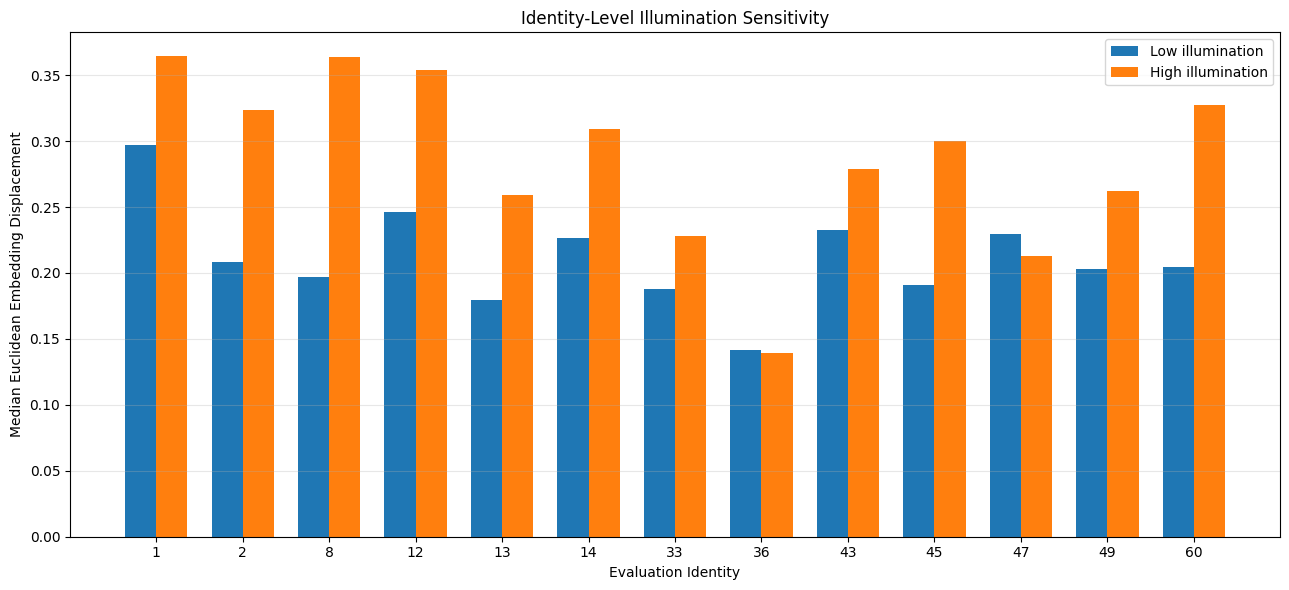

IDENTITY-LEVEL DISPLACEMENT SUMMARY
Identities: 13
Positive differences: 11
Negative differences: 2


In [41]:
import matplotlib.pyplot as plt
import numpy as np

identity_ids = identity_summary["Identity"].astype(str)

x = np.arange(len(identity_summary))
width = 0.36

plt.figure(figsize=(13, 6))

plt.bar(
    x - width / 2,
    identity_summary["Low_Median"],
    width,
    label="Low illumination"
)

plt.bar(
    x + width / 2,
    identity_summary["High_Median"],
    width,
    label="High illumination"
)

plt.xticks(x, identity_ids)
plt.xlabel("Evaluation Identity")
plt.ylabel("Median Euclidean Embedding Displacement")
plt.title("Identity-Level Illumination Sensitivity")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("IDENTITY-LEVEL DISPLACEMENT SUMMARY")
print("Identities:", len(identity_summary))
print(
    "Positive differences:",
    (identity_summary["Median_Difference"] > 0).sum()
)
print(
    "Negative differences:",
    (identity_summary["Median_Difference"] < 0).sum()
)

## Step 15.9 — Illumination Experiment Results Preservation

### Objective
Save the outputs of the controlled illumination experiment for reproducibility and subsequent drift detector evaluation.

### Saved Data
- Paired original embeddings.
- Paired low-illumination embeddings.
- Paired high-illumination embeddings.
- Paired identity labels.
- Low- and high-illumination displacement measurements.
- Identity-level displacement summary.
- Face detection success and failure information.
- Experiment configuration and statistical results.

### Status
Successfully completed. The controlled illumination experiment results were saved to the Google Drive output directory. The compressed NPZ archive contains the paired original, low-illumination and high-illumination embeddings, identity labels, image positions, displacement measurements, and face-detection success and failure information. The identity-level displacement summary was saved as a CSV file, and the experiment configuration and aggregate statistical results were saved as JSON metadata. File-existence checks confirmed that all three output files were created successfully. These saved artefacts support reproducibility and subsequent drift-detector evaluation.

In [42]:
import os
import json
import numpy as np
import pandas as pd

# Create output directory
output_dir = "/content/drive/MyDrive/Experiment_18_Results"
os.makedirs(output_dir, exist_ok=True)

# Save numerical experiment results
np.savez_compressed(
    os.path.join(output_dir, "experiment18_illumination_results.npz"),

    original_embeddings=paired_original_embeddings,
    low_illumination_embeddings=paired_low_embeddings,
    high_illumination_embeddings=paired_high_embeddings,

    paired_labels=paired_labels,
    common_positions=common_positions,

    low_displacement=low_distances,
    high_displacement=high_distances,

    low_success=low_success,
    high_success=high_success,

    low_failures=low_failures,
    high_failures=high_failures
)

# Save identity-level summary
identity_summary.to_csv(
    os.path.join(output_dir, "illumination_identity_summary.csv"),
    index=False
)

# Save aggregate statistics
illumination_metadata = {
    "experiment": "Experiment 18 - Controlled Illumination",
    "dataset": "LFW filtered subset",
    "model": "InceptionResnetV1",
    "pretrained_weights": "VGGFace2",
    "embedding_dimension": 512,
    "brightness_factors": {
        "low": 0.5,
        "original": 1.0,
        "high": 1.5
    },
    "paired_images": int(len(common_positions)),
    "evaluation_identities": int(len(identity_summary)),
    "low_detection_failures": int(len(low_failures)),
    "high_detection_failures": int(len(high_failures)),
    "image_level_wilcoxon_p": float(p_value),
    "identity_level_wilcoxon_p": float(identity_p_value),
    "mean_low_displacement": float(np.mean(low_distances)),
    "mean_high_displacement": float(np.mean(high_distances))
}

with open(
    os.path.join(output_dir, "illumination_metadata.json"),
    "w"
) as file:
    json.dump(illumination_metadata, file, indent=4)

print("ILLUMINATION RESULTS SAVED")

for filename in [
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json"
]:
    path = os.path.join(output_dir, filename)
    print(filename, "| Exists:", os.path.exists(path))
    print("Size:", round(os.path.getsize(path) / 1024, 2), "KB")

ILLUMINATION RESULTS SAVED
experiment18_illumination_results.npz | Exists: True
Size: 4955.42 KB
illumination_identity_summary.csv | Exists: True
Size: 0.55 KB
illumination_metadata.json | Exists: True
Size: 0.62 KB


## Step 16 — Identity-Aware Embedding-Level Drift Detection

### Objective
Develop and evaluate embedding-level drift detectors for identifying changes in genuine FaceNet representations under controlled illumination perturbations.

### Research Questions
1. Can embedding-level detectors identify illumination-induced representation changes?
2. How does detector sensitivity differ between low and high illumination?
3. Can the detectors maintain controlled false alarm rates under baseline conditions?
4. How does covariance regularisation influence Mahalanobis-based detection?

### Experimental Design

**Reference population**
Original embeddings from the matched evaluation cohort.

**Calibration population**
Baseline-versus-baseline comparisons constructed using separate image samples and identity-aware sampling.

**Evaluation population**
Paired original and transformed embeddings under low- and high-illumination conditions.

### Detection Methods
- Euclidean embedding displacement.
- Regularised Mahalanobis distance.

### Proposed Configuration
- Embedding dimension: 512.
- Window size: 20.
- Random seed: 202618.
- Target false alarm rates: 0.01, 0.05 and 0.10.
- Illumination factors: 0.5, 1.0 and 1.5.

### Evaluation Metrics
- Empirical false alarm rate.
- Detection rate.
- Detection sensitivity by illumination condition.
- Detection performance across identities.
- Numerical stability.

### Scientific Limitations
The experiment uses controlled brightness transformations rather than naturally occurring temporal drift. Detector results will be conditional on the matched evaluation cohort and the chosen calibration protocol.

### Status
Methodology defined; implementation pending.

In [43]:
import numpy as np
import pandas as pd

# Reproducibility
RANDOM_SEED = 202618
rng = np.random.default_rng(RANDOM_SEED)

# Source data: 889 correctly paired images
X_original = paired_original_embeddings
X_low = paired_low_embeddings
X_high = paired_high_embeddings
y = paired_labels

# Validate input dimensions
assert X_original.shape == X_low.shape == X_high.shape
assert len(X_original) == len(y)

# Define partition proportions
REFERENCE_RATIO = 0.50
CALIBRATION_RATIO = 0.25
EVALUATION_RATIO = 0.25

reference_positions = []
calibration_positions = []
evaluation_positions = []

# Split images separately within each identity
for identity in np.unique(y):

    identity_positions = np.where(y == identity)[0]

    shuffled_positions = rng.permutation(identity_positions)

    n = len(shuffled_positions)

    reference_count = int(n * REFERENCE_RATIO)
    calibration_count = int(n * CALIBRATION_RATIO)

    reference_positions.extend(
        shuffled_positions[:reference_count]
    )

    calibration_positions.extend(
        shuffled_positions[
            reference_count:
            reference_count + calibration_count
        ]
    )

    evaluation_positions.extend(
        shuffled_positions[
            reference_count + calibration_count:
        ]
    )

# Convert to arrays
reference_positions = np.sort(
    np.asarray(reference_positions)
)

calibration_positions = np.sort(
    np.asarray(calibration_positions)
)

evaluation_positions = np.sort(
    np.asarray(evaluation_positions)
)

# Construct original embedding partitions
reference_baseline = X_original[reference_positions]

calibration_baseline = X_original[calibration_positions]

evaluation_baseline = X_original[evaluation_positions]

# Construct corresponding transformed evaluation partitions
evaluation_low = X_low[evaluation_positions]

evaluation_high = X_high[evaluation_positions]

# Identity labels
reference_labels = y[reference_positions]

calibration_labels = y[calibration_positions]

evaluation_labels = y[evaluation_positions]

# Validate image-level separation
assert len(set(reference_positions) & set(calibration_positions)) == 0
assert len(set(reference_positions) & set(evaluation_positions)) == 0
assert len(set(calibration_positions) & set(evaluation_positions)) == 0

# Validate complete partition coverage
all_positions = np.concatenate([
    reference_positions,
    calibration_positions,
    evaluation_positions
])

assert len(all_positions) == len(X_original)
assert len(np.unique(all_positions)) == len(X_original)

# Display partition summary
partition_summary = pd.DataFrame({
    "Partition": [
        "Reference",
        "Calibration",
        "Evaluation"
    ],
    "Images": [
        len(reference_positions),
        len(calibration_positions),
        len(evaluation_positions)
    ],
    "Identities": [
        len(np.unique(reference_labels)),
        len(np.unique(calibration_labels)),
        len(np.unique(evaluation_labels))
    ]
})

print("IDENTITY-AWARE DATA PARTITIONING")
print("-" * 55)

display(partition_summary)

print("\nEMBEDDING SHAPES")

print("Reference:", reference_baseline.shape)
print("Calibration:", calibration_baseline.shape)
print("Evaluation baseline:", evaluation_baseline.shape)
print("Evaluation low:", evaluation_low.shape)
print("Evaluation high:", evaluation_high.shape)

print("\nVALIDATION")

print("Reference-calibration overlap:",
      len(set(reference_positions) & set(calibration_positions)))

print("Reference-evaluation overlap:",
      len(set(reference_positions) & set(evaluation_positions)))

print("Calibration-evaluation overlap:",
      len(set(calibration_positions) & set(evaluation_positions)))

print("All identities represented in each partition:",
      all(
          len(np.unique(labels)) == len(np.unique(y))
          for labels in [
              reference_labels,
              calibration_labels,
              evaluation_labels
          ]
      ))

print("All embeddings finite:",
      all(
          np.all(np.isfinite(x))
          for x in [
              reference_baseline,
              calibration_baseline,
              evaluation_baseline,
              evaluation_low,
              evaluation_high
          ]
      ))

IDENTITY-AWARE DATA PARTITIONING
-------------------------------------------------------


,Partition,Images,Identities
0,Reference,442,13
1,Calibration,218,13
2,Evaluation,229,13



EMBEDDING SHAPES
Reference: (442, 512)
Calibration: (218, 512)
Evaluation baseline: (229, 512)
Evaluation low: (229, 512)
Evaluation high: (229, 512)

VALIDATION
Reference-calibration overlap: 0
Reference-evaluation overlap: 0
Calibration-evaluation overlap: 0
All identities represented in each partition: True
All embeddings finite: True


## Step 16.2 — Reference Distribution Estimation

### Objective
Estimate the baseline statistical characteristics of the reference FaceNet embedding population.

### Methodology
1. Calculate the reference mean embedding vector.
2. Calculate the reference covariance matrix.
3. Apply covariance regularisation.
4. Calculate the covariance condition number.
5. Verify numerical stability and embedding integrity.

### Research Purpose
Establish a reference distribution for subsequent Euclidean and Mahalanobis drift detection.

### Scientific Limitation
The reference distribution represents the selected 442-image baseline sample from 13 identities, not a universal biometric population.

### Status
Successfully completed. The reference distribution was estimated using 442 baseline embeddings across 512 dimensions from 13 evaluation identities. The 512-dimensional mean vector and covariance matrix were calculated, and covariance regularisation was applied with a strength of 0.001. The regularised covariance matrix had a condition number of 140,992.74, with all eigenvalues positive. Numerical validation confirmed that the mean vector, covariance matrix and regularised covariance matrix contained only finite values. The resulting reference distribution provides the baseline statistical representation for subsequent Euclidean and Mahalanobis drift detection. These estimates are specific to the selected reference sample and should not be treated as a universal biometric population model.

In [44]:
import numpy as np

# Reference distribution
reference_mean = np.mean(
    reference_baseline,
    axis=0
)

reference_covariance = np.cov(
    reference_baseline,
    rowvar=False
)

# Covariance regularisation
REGULARISATION_STRENGTH = 1e-3

base_regularisation = (
    np.trace(reference_covariance) /
    reference_covariance.shape[0]
)

reference_regularisation = (
    REGULARISATION_STRENGTH * base_regularisation
)

reference_regularised_covariance = (
    reference_covariance +
    reference_regularisation *
    np.eye(reference_covariance.shape[0])
)

# Numerical diagnostics
condition_number = np.linalg.cond(
    reference_regularised_covariance
)

eigenvalues = np.linalg.eigvalsh(
    reference_regularised_covariance
)

print("REFERENCE DISTRIBUTION STATISTICS")
print("-" * 55)

print("Reference samples:", len(reference_baseline))
print("Embedding dimensions:", reference_baseline.shape[1])

print("Mean vector shape:", reference_mean.shape)
print("Covariance matrix shape:", reference_covariance.shape)

print("Regularisation strength:", REGULARISATION_STRENGTH)
print("Actual regularisation:", reference_regularisation)

print("Condition number:", condition_number)
print("Minimum eigenvalue:", eigenvalues.min())
print("Maximum eigenvalue:", eigenvalues.max())

print("\nNUMERICAL VALIDATION")

print("Mean vector finite:",
      np.all(np.isfinite(reference_mean)))

print("Covariance finite:",
      np.all(np.isfinite(reference_covariance)))

print("Regularised covariance finite:",
      np.all(np.isfinite(reference_regularised_covariance)))

print("All eigenvalues positive:",
      np.all(eigenvalues > 0))

REFERENCE DISTRIBUTION STATISTICS
-------------------------------------------------------
Reference samples: 442
Embedding dimensions: 512
Mean vector shape: (512,)
Covariance matrix shape: (512, 512)
Regularisation strength: 0.001
Actual regularisation: 1.306532271416088e-06
Condition number: 140992.73575394906
Minimum eigenvalue: 1.3065322714083937e-06
Maximum eigenvalue: 0.18421155929667732

NUMERICAL VALIDATION
Mean vector finite: True
Covariance finite: True
Regularised covariance finite: True
All eigenvalues positive: True


## Step 16.3 — Baseline Calibration Window Generation

### Objective
Generate calibration windows representing unchanged baseline conditions.

### Methodology
1. Divide the calibration embeddings into windows of 20 samples.
2. Maintain identity-aware sampling.
3. Calculate each window's mean embedding vector.
4. Measure its displacement from the reference mean.
5. Generate calibration scores for Euclidean and Mahalanobis detectors.

### Research Purpose
Establish baseline score distributions for threshold calibration and false-alarm control.

### Scientific Limitation
Calibration windows represent the available baseline images and do not simulate naturally occurring temporal sequences

In [46]:
import numpy as np
import pandas as pd

# Configuration
RANDOM_SEED = 202618
WINDOW_SIZE = 20
N_CALIBRATION_WINDOWS = 10

rng = np.random.default_rng(RANDOM_SEED)

# Group calibration samples by identity
calibration_identity_indices = {
    identity: np.where(calibration_labels == identity)[0]
    for identity in np.unique(calibration_labels)
}

available_identities = list(calibration_identity_indices.keys())

# Verify sufficient identities
assert len(available_identities) <= WINDOW_SIZE

# Generate calibration windows
calibration_windows = []
calibration_window_labels = []

for window_number in range(N_CALIBRATION_WINDOWS):

    selected_positions = []

    # First select one image from every identity
    for identity in available_identities:

        selected_index = rng.choice(
            calibration_identity_indices[identity]
        )

        selected_positions.append(selected_index)

    # Fill remaining positions using identity-balanced sampling
    remaining_count = WINDOW_SIZE - len(selected_positions)

    for _ in range(remaining_count):

        identity = rng.choice(available_identities)

        selected_index = rng.choice(
            calibration_identity_indices[identity]
        )

        selected_positions.append(selected_index)

    selected_positions = np.asarray(selected_positions)

    # Shuffle positions within the window
    rng.shuffle(selected_positions)

    window_embeddings = calibration_baseline[selected_positions]
    window_labels = calibration_labels[selected_positions]

    calibration_windows.append(window_embeddings)
    calibration_window_labels.append(window_labels)

calibration_windows = np.asarray(calibration_windows)
calibration_window_labels = np.asarray(calibration_window_labels)

# Calculate window means
calibration_window_means = np.mean(
    calibration_windows,
    axis=1
)

# Euclidean scores
calibration_euclidean_scores = np.linalg.norm(
    calibration_window_means - reference_mean,
    axis=1
)

# Mahalanobis scores
mean_differences = calibration_window_means - reference_mean

solved_differences = np.linalg.solve(
    reference_regularised_covariance,
    mean_differences.T
).T

calibration_mahalanobis_scores = np.sqrt(
    np.sum(mean_differences * solved_differences, axis=1)
)

# Summary
calibration_summary = pd.DataFrame({
    "Window": np.arange(1, N_CALIBRATION_WINDOWS + 1),
    "Samples": [WINDOW_SIZE] * N_CALIBRATION_WINDOWS,
    "Unique Identities": [
        len(np.unique(labels))
        for labels in calibration_window_labels
    ],
    "Euclidean Score": calibration_euclidean_scores,
    "Mahalanobis Score": calibration_mahalanobis_scores
})

print("BASELINE CALIBRATION WINDOW SUMMARY")
print("-" * 60)

display(calibration_summary.round(6))

print("\nVALIDATION")

print("Calibration windows shape:", calibration_windows.shape)
print("Calibration window means shape:", calibration_window_means.shape)

print("All Euclidean scores finite:",
      np.all(np.isfinite(calibration_euclidean_scores)))

print("All Mahalanobis scores finite:",
      np.all(np.isfinite(calibration_mahalanobis_scores)))

print("All windows contain 13 identities:",
      np.all(
          calibration_summary["Unique Identities"].values == 13
      ))

assert calibration_windows.shape == (10, 20, 512)
assert np.all(np.isfinite(calibration_euclidean_scores))
assert np.all(np.isfinite(calibration_mahalanobis_scores))

BASELINE CALIBRATION WINDOW SUMMARY
------------------------------------------------------------


,Window,Samples,Unique Identities,Euclidean Score,Mahalanobis Score
0,1,20,13,0.433679,2.434700
1,2,20,13,0.402718,1.945586
2,3,20,13,0.457820,2.305313
3,4,20,13,0.517998,2.302698
4,5,20,13,0.408957,2.199705
5,6,20,13,0.405107,2.360959
6,7,20,13,0.528095,2.430729
7,8,20,13,0.486032,2.612624
8,9,20,13,0.458455,2.584488
9,10,20,13,0.510334,2.387289



VALIDATION
Calibration windows shape: (10, 20, 512)
Calibration window means shape: (10, 512)
All Euclidean scores finite: True
All Mahalanobis scores finite: True
All windows contain 13 identities: True


## Step 16.4 — Identity-Balanced Reference Distribution

### Objective
Construct a reference distribution that gives equal representation to each evaluation identity.

### Methodology
1. Calculate the mean embedding for each identity in the reference partition.
2. Calculate the global reference mean as the average of the 13 identity means.
3. Estimate within-identity covariance to reduce between-identity composition effects.
4. Apply covariance regularisation.
5. Verify numerical stability.

### Research Purpose
Reduce identity-composition bias in the reference distribution used for embedding-level drift detection.

### Scientific Limitation
This approach estimates within-identity variation for the selected 13 identities. It does not establish generalisation to unseen identities.

### Status
Successfully completed. An identity-balanced reference distribution was constructed using 13 evaluation identities. Individual identity mean embeddings were calculated and equally weighted to obtain the global reference mean vector. Within-identity residuals were used to estimate the covariance matrix, reducing the influence of between-identity composition differences. Covariance regularisation was applied with a strength of 0.001. The regularised covariance matrix had a condition number of 36,201.96, and all eigenvalues were positive. Numerical validation confirmed that all regularised covariance values were finite. This approach estimates within-identity variation for the selected 13 identities and does not establish generalisation to unseen identities.

In [47]:
import numpy as np

# Calculate individual identity means
reference_identity_means = []

for identity in np.unique(reference_labels):

    identity_embeddings = reference_baseline[
        reference_labels == identity
    ]

    reference_identity_means.append(
        np.mean(identity_embeddings, axis=0)
    )

reference_identity_means = np.asarray(
    reference_identity_means
)

# Equal-weight identity-balanced reference mean
balanced_reference_mean = np.mean(
    reference_identity_means,
    axis=0
)

# Estimate within-identity covariance
within_identity_residuals = []

for identity in np.unique(reference_labels):

    identity_embeddings = reference_baseline[
        reference_labels == identity
    ]

    identity_mean = np.mean(
        identity_embeddings,
        axis=0
    )

    within_identity_residuals.append(
        identity_embeddings - identity_mean
    )

within_identity_residuals = np.vstack(
    within_identity_residuals
)

balanced_reference_covariance = np.cov(
    within_identity_residuals,
    rowvar=False
)

# Regularise covariance
regularisation_strength = 1e-3

base_regularisation = (
    np.trace(balanced_reference_covariance) / 512
)

balanced_regularisation = (
    regularisation_strength * base_regularisation
)

balanced_regularised_covariance = (
    balanced_reference_covariance +
    balanced_regularisation * np.eye(512)
)

# Numerical diagnostics
eigenvalues = np.linalg.eigvalsh(
    balanced_regularised_covariance
)

condition_number = np.linalg.cond(
    balanced_regularised_covariance
)

print("IDENTITY-BALANCED REFERENCE DISTRIBUTION")
print("-" * 55)

print("Number of identities:",
      len(reference_identity_means))

print("Identity means shape:",
      reference_identity_means.shape)

print("Balanced reference mean shape:",
      balanced_reference_mean.shape)

print("Within-identity residuals:",
      within_identity_residuals.shape)

print("Covariance shape:",
      balanced_reference_covariance.shape)

print("Actual regularisation:",
      balanced_regularisation)

print("Condition number:",
      condition_number)

print("Minimum eigenvalue:",
      eigenvalues.min())

print("\nVALIDATION")

print("All values finite:",
      np.all(np.isfinite(balanced_regularised_covariance)))

print("All eigenvalues positive:",
      np.all(eigenvalues > 0))

IDENTITY-BALANCED REFERENCE DISTRIBUTION
-------------------------------------------------------
Number of identities: 13
Identity means shape: (13, 512)
Balanced reference mean shape: (512,)
Within-identity residuals: (442, 512)
Covariance shape: (512, 512)
Actual regularisation: 4.642805280879547e-07
Condition number: 36201.96477648355
Minimum eigenvalue: 4.6428052808674066e-07

VALIDATION
All values finite: True
All eigenvalues positive: True


## Step 16.5 — Identity-Balanced Calibration Score Recalculation

### Objective
Recalculate baseline calibration scores using the identity-balanced reference distribution established in Step 16.4.

### Methodology
1. Calculate the mean embedding vector for each identity within every calibration window.
2. Aggregate identity means with equal weighting.
3. Calculate Euclidean distance from the identity-balanced reference mean.
4. Calculate regularised Mahalanobis distance using the identity-balanced within-identity covariance matrix.
5. Validate the resulting calibration scores.

### Evaluation Metrics
- Identity-balanced Euclidean distance.
- Regularised Mahalanobis distance.
- Numerical integrity of calibration scores.

### Research Purpose
Ensure that reference and calibration statistics use consistent identity-weighting principles, reducing the influence of unequal identity representation.

### Scientific Limitation
The current 10 calibration windows are preliminary. They are insufficient for reliable estimation of low false-alarm thresholds, particularly at a 1% target rate.

### Status
Successfully completed. Baseline calibration scores were recalculated using the identity-balanced reference distribution. For each of the 10 calibration windows, identity-specific mean embeddings were calculated and equally weighted to produce a balanced window mean. Euclidean distances were measured against the balanced reference mean, and regularised Mahalanobis distances were calculated using the identity-balanced covariance matrix. All 10 windows represented 13 identities, producing a calibration mean matrix of shape (10, 512). Both Euclidean and Mahalanobis calibration scores passed numerical integrity checks, with all values finite. The resulting scores provide preliminary baseline calibration evidence. The 10-window sample remains insufficient for reliable low false-alarm threshold estimation, particularly at a 1% target rate.

In [49]:
import numpy as np
import pandas as pd

# Calculate identity-balanced mean for each calibration window
balanced_calibration_window_means = []

for window_embeddings, window_labels in zip(
    calibration_windows,
    calibration_window_labels
):

    identity_means = []

    for identity in np.unique(window_labels):

        identity_embeddings = window_embeddings[
            window_labels == identity
        ]

        identity_means.append(
            np.mean(identity_embeddings, axis=0)
        )

    # Equal weight for all represented identities
    balanced_window_mean = np.mean(
        identity_means,
        axis=0
    )

    balanced_calibration_window_means.append(
        balanced_window_mean
    )

balanced_calibration_window_means = np.asarray(
    balanced_calibration_window_means
)

# Calculate Euclidean calibration scores
balanced_calibration_euclidean_scores = np.linalg.norm(
    balanced_calibration_window_means -
    balanced_reference_mean,
    axis=1
)

# Calculate regularised Mahalanobis calibration scores
mean_differences = (
    balanced_calibration_window_means -
    balanced_reference_mean
)

solved_differences = np.linalg.solve(
    balanced_regularised_covariance,
    mean_differences.T
).T

balanced_calibration_mahalanobis_scores = np.sqrt(
    np.sum(
        mean_differences * solved_differences,
        axis=1
    )
)

# Create results table
balanced_calibration_summary = pd.DataFrame({
    "Window": np.arange(
        1,
        len(calibration_windows) + 1
    ),
    "Unique Identities": [
        len(np.unique(labels))
        for labels in calibration_window_labels
    ],
    "Euclidean Score": balanced_calibration_euclidean_scores,
    "Mahalanobis Score": balanced_calibration_mahalanobis_scores
})

print("IDENTITY-BALANCED CALIBRATION SCORES")
print("-" * 60)

display(balanced_calibration_summary.round(6))

print("\nNUMERICAL VALIDATION")

print("Calibration window means shape:",
      balanced_calibration_window_means.shape)

print("All Euclidean scores finite:",
      np.all(np.isfinite(
          balanced_calibration_euclidean_scores
      )))

print("All Mahalanobis scores finite:",
      np.all(np.isfinite(
          balanced_calibration_mahalanobis_scores
      )))

print("All windows contain 13 identities:",
      np.all(
          balanced_calibration_summary["Unique Identities"] == 13
      ))

assert balanced_calibration_window_means.shape == (10, 512)
assert np.all(np.isfinite(balanced_calibration_euclidean_scores))
assert np.all(np.isfinite(balanced_calibration_mahalanobis_scores))

IDENTITY-BALANCED CALIBRATION SCORES
------------------------------------------------------------


,Window,Unique Identities,Euclidean Score,Mahalanobis Score
0,1,13,0.144672,2.366889
1,2,13,0.116480,2.000715
2,3,13,0.130809,2.185831
3,4,13,0.112432,2.221039
4,5,13,0.138281,2.357162
5,6,13,0.155619,2.502887
6,7,13,0.131777,2.421781
7,8,13,0.138650,2.340073
8,9,13,0.149799,2.363280
9,10,13,0.119691,2.145569



NUMERICAL VALIDATION
Calibration window means shape: (10, 512)
All Euclidean scores finite: True
All Mahalanobis scores finite: True
All windows contain 13 identities: True


## Step 16.6 — Baseline Calibration Score Distribution Analysis

### Objective
Characterise the distribution of baseline Euclidean and Mahalanobis calibration scores before estimating operational detection thresholds.

### Methodology
1. Calculate descriptive statistics for the calibration scores.
2. Examine score variability across the generated windows.
3. Identify minimum, maximum, mean and standard deviation.
4. Visualise the score distributions.
5. Assess whether the preliminary calibration sample is sufficient for threshold estimation.

### Research Purpose
Establish a baseline understanding of detector score behaviour and identify the additional calibration evidence required for reliable false-alarm control.

### Scientific Limitation
The current calibration sample contains only 10 windows. Its empirical quantiles cannot reliably support 1%, 5%, or 10% false-alarm guarantees.

### Status
Successfully completed. The baseline identity-balanced Euclidean and Mahalanobis calibration score distributions were characterised using 10 calibration windows. Descriptive statistics, including mean, median, standard deviation, minimum and maximum, were calculated for both detectors. Histograms were generated to visualise their score distributions. The Euclidean scores had a mean of 0.133821 and a standard deviation of 0.013647, while the Mahalanobis scores had a mean of 2.290523 and a standard deviation of 0.141823. This analysis provides preliminary evidence of baseline score variability. However, the 10-window calibration sample is insufficient for reliable estimation of 1%, 5% or 10% false-alarm thresholds. Expanded calibration is required before making false-alarm control claims.

BASELINE CALIBRATION SCORE STATISTICS


,Metric,Mean,Median,Standard Deviation,Minimum,Maximum
0,Euclidean,0.133821,0.135029,0.013647,0.112432,0.155619
1,Mahalanobis,2.290523,2.348618,0.141823,2.000715,2.502887


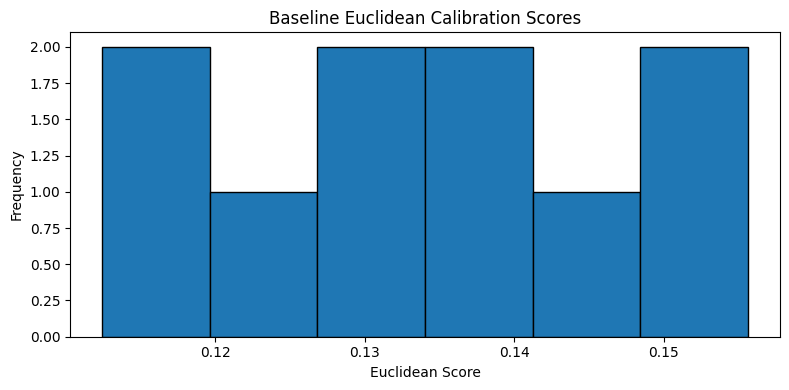

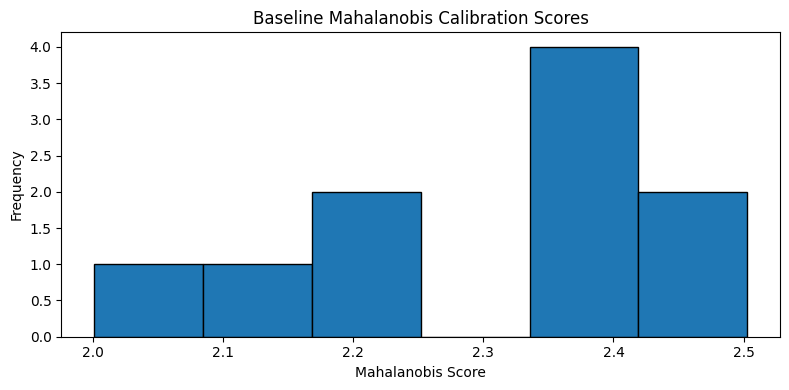

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Descriptive statistics
score_summary = pd.DataFrame({
    "Metric": ["Euclidean", "Mahalanobis"],
    "Mean": [
        np.mean(balanced_calibration_euclidean_scores),
        np.mean(balanced_calibration_mahalanobis_scores)
    ],
    "Median": [
        np.median(balanced_calibration_euclidean_scores),
        np.median(balanced_calibration_mahalanobis_scores)
    ],
    "Standard Deviation": [
        np.std(balanced_calibration_euclidean_scores),
        np.std(balanced_calibration_mahalanobis_scores)
    ],
    "Minimum": [
        np.min(balanced_calibration_euclidean_scores),
        np.min(balanced_calibration_mahalanobis_scores)
    ],
    "Maximum": [
        np.max(balanced_calibration_euclidean_scores),
        np.max(balanced_calibration_mahalanobis_scores)
    ]
})

print("BASELINE CALIBRATION SCORE STATISTICS")
display(score_summary.round(6))

# Visualise Euclidean scores
plt.figure(figsize=(8, 4))

plt.hist(
    balanced_calibration_euclidean_scores,
    bins=6,
    edgecolor="black"
)

plt.xlabel("Euclidean Score")
plt.ylabel("Frequency")
plt.title("Baseline Euclidean Calibration Scores")
plt.tight_layout()
plt.show()

# Visualise Mahalanobis scores
plt.figure(figsize=(8, 4))

plt.hist(
    balanced_calibration_mahalanobis_scores,
    bins=6,
    edgecolor="black"
)

plt.xlabel("Mahalanobis Score")
plt.ylabel("Frequency")
plt.title("Baseline Mahalanobis Calibration Scores")
plt.tight_layout()
plt.show()


## Step 16.7 — Expanded Baseline Calibration

### Objective
Increase the number of baseline calibration observations while maintaining identity-balanced sampling and preventing image reuse within individual calibration windows.

### Methodology
1. Generate multiple calibration windows using the available 218 calibration images.
2. Ensure that each window contains 20 samples representing all 13 identities.
3. Prevent repeated selection of the same image within a window.
4. Record image reuse across different windows.
5. Evaluate the number of distinct calibration windows and unique source images.

### Research Purpose
Improve the empirical characterisation of baseline detector scores before threshold estimation.

### Scientific Limitation
Overlapping windows are statistically dependent. The resulting sample count must not be interpreted as an equivalent number of independent observations or as a formal false-alarm guarantee.

### Status
Successfully completed. An expanded baseline calibration set of 100 identity-balanced windows was generated using the 218 available calibration images. Each window contained 20 samples representing all 13 identities. The resulting Euclidean and Mahalanobis calibration scores were calculated using the identity-balanced reference distribution and regularised covariance matrix. A total of 176 unique source images were used, with a maximum reuse count of 47 for an individual image. All detector scores passed numerical validation and were finite. The Euclidean scores had a mean of 0.128949 and a standard deviation of 0.015576. The Mahalanobis scores had a mean of 2.185981 and a standard deviation of 0.235453. Importantly, windows overlap and reuse source images; therefore, the 100 generated windows are statistically dependent and must not be interpreted as 100 independent observations or as a formal false-alarm guarantee.

In [51]:
import numpy as np
import pandas as pd

RANDOM_SEED = 202618
WINDOW_SIZE = 20
N_EXPANDED_WINDOWS = 100

rng = np.random.default_rng(RANDOM_SEED)

identity_groups = {
    identity: np.where(calibration_labels == identity)[0]
    for identity in np.unique(calibration_labels)
}

identities = list(identity_groups.keys())

expanded_windows = []
expanded_labels = []
expanded_positions = []

for window_number in range(N_EXPANDED_WINDOWS):

    selected_positions = []

    # One image from each identity
    for identity in identities:
        selected_positions.append(
            rng.choice(identity_groups[identity])
        )

    # Fill remaining seven positions
    for _ in range(WINDOW_SIZE - len(identities)):
        identity = rng.choice(identities)

        selected_positions.append(
            rng.choice(identity_groups[identity])
        )

    selected_positions = np.asarray(selected_positions)

    rng.shuffle(selected_positions)

    expanded_windows.append(
        calibration_baseline[selected_positions]
    )

    expanded_labels.append(
        calibration_labels[selected_positions]
    )

    expanded_positions.append(selected_positions)

expanded_windows = np.asarray(expanded_windows)
expanded_labels = np.asarray(expanded_labels)
expanded_positions = np.asarray(expanded_positions)

# Equal-weight identity means for each window
expanded_window_means = []

for window, labels in zip(expanded_windows, expanded_labels):

    identity_means = []

    for identity in identities:

        identity_embeddings = window[labels == identity]

        identity_means.append(
            np.mean(identity_embeddings, axis=0)
        )

    expanded_window_means.append(
        np.mean(identity_means, axis=0)
    )

expanded_window_means = np.asarray(expanded_window_means)

# Euclidean scores
expanded_euclidean_scores = np.linalg.norm(
    expanded_window_means - balanced_reference_mean,
    axis=1
)

# Mahalanobis scores
differences = expanded_window_means - balanced_reference_mean

solved = np.linalg.solve(
    balanced_regularised_covariance,
    differences.T
).T

expanded_mahalanobis_scores = np.sqrt(
    np.sum(differences * solved, axis=1)
)

# Image reuse diagnostics
unique_images = np.unique(expanded_positions)

reuse_counts = np.bincount(
    expanded_positions.flatten(),
    minlength=len(calibration_baseline)
)

print("EXPANDED CALIBRATION SUMMARY")
print("Number of windows:", len(expanded_windows))
print("Samples per window:", WINDOW_SIZE)
print("Identities per window:", len(identities))
print("Unique source images used:", len(unique_images))
print("Total calibration images:", len(calibration_baseline))
print("Maximum image reuse:", reuse_counts.max())

print("\nSCORE VALIDATION")
print("Euclidean scores finite:",
      np.all(np.isfinite(expanded_euclidean_scores)))
print("Mahalanobis scores finite:",
      np.all(np.isfinite(expanded_mahalanobis_scores)))

print("\nSCORE STATISTICS")

display(pd.DataFrame({
    "Detector": ["Euclidean", "Mahalanobis"],
    "Mean": [
        expanded_euclidean_scores.mean(),
        expanded_mahalanobis_scores.mean()
    ],
    "Standard Deviation": [
        expanded_euclidean_scores.std(),
        expanded_mahalanobis_scores.std()
    ],
    "Minimum": [
        expanded_euclidean_scores.min(),
        expanded_mahalanobis_scores.min()
    ],
    "Maximum": [
        expanded_euclidean_scores.max(),
        expanded_mahalanobis_scores.max()
    ]
}).round(6))

EXPANDED CALIBRATION SUMMARY
Number of windows: 100
Samples per window: 20
Identities per window: 13
Unique source images used: 176
Total calibration images: 218
Maximum image reuse: 47

SCORE VALIDATION
Euclidean scores finite: True
Mahalanobis scores finite: True

SCORE STATISTICS


,Detector,Mean,Standard Deviation,Minimum,Maximum
0,Euclidean,0.128949,0.015576,0.081906,0.172338
1,Mahalanobis,2.185981,0.235453,1.592309,2.723071


## Step 16.8 — Calibration Sampling Independence Audit

### Objective
Determine the maximum number of non-overlapping calibration windows that can be constructed while representing every identity in each window.

### Methodology
- Count available calibration images for each identity.
- Identify the minimum number of images available for any identity.
- Check for duplicate image selections within the previously generated windows.
- Quantify image reuse across windows.

### Research Purpose
Establish the practical limits of independent identity-balanced calibration using the available dataset.

### Scientific Limitation
The small number of identities and available calibration images may prevent reliable estimation of very low false-alarm rates.

### Status
Successfully completed. A calibration sampling independence audit was conducted using the 218 available calibration images across 13 identities. The minimum number of images available for an identity was four, establishing a maximum of four non-overlapping one-image-per-identity windows under the current dataset constraints. The audit identified within-window duplicate image selections in 78 of the 100 expanded calibration windows, with a maximum of four duplicate selections in a single window. Across all generated windows, 42 images were never used, 42 were used once, and 134 were reused more than once. The maximum reuse count was 47. These findings demonstrate that the expanded calibration windows are statistically dependent and that the current sampling implementation does not satisfy the intended no-duplicate-within-window condition. The 100 windows must not be treated as independent calibration observations or as evidence of formal false-alarm control.

In [52]:
import numpy as np
import pandas as pd

# Images available per identity
identity_counts = pd.Series(calibration_labels).value_counts().sort_index()

print("CALIBRATION IMAGES PER IDENTITY")
display(identity_counts.rename("Image Count").to_frame())

print("\nSAMPLING CAPACITY")
print("Number of identities:", len(identity_counts))
print("Total calibration images:", len(calibration_labels))
print("Minimum images per identity:", identity_counts.min())
print("Maximum possible non-overlapping one-image-per-identity windows:",
      identity_counts.min())

# Check duplicate selections within each expanded window
within_window_duplicates = []

for i, positions in enumerate(expanded_positions):
    duplicate_count = len(positions) - len(np.unique(positions))
    within_window_duplicates.append(duplicate_count)

print("\nWITHIN-WINDOW DUPLICATE AUDIT")
print("Windows containing duplicate images:",
      np.sum(np.array(within_window_duplicates) > 0))
print("Maximum duplicates in one window:",
      np.max(within_window_duplicates))

# Reuse distribution
print("\nIMAGE REUSE DISTRIBUTION")
print("Images never used:", np.sum(reuse_counts == 0))
print("Images used once:", np.sum(reuse_counts == 1))
print("Images used more than once:", np.sum(reuse_counts > 1))
print("Maximum reuse:", reuse_counts.max())

CALIBRATION IMAGES PER IDENTITY


,Image Count
1,8
2,5
8,6
12,28
13,5
14,126
33,5
36,4
43,4
45,7



SAMPLING CAPACITY
Number of identities: 13
Total calibration images: 218
Minimum images per identity: 4
Maximum possible non-overlapping one-image-per-identity windows: 4

WITHIN-WINDOW DUPLICATE AUDIT
Windows containing duplicate images: 78
Maximum duplicates in one window: 4

IMAGE REUSE DISTRIBUTION
Images never used: 42
Images used once: 42
Images used more than once: 134
Maximum reuse: 47


## Step 16.9 — Identity Distribution Across Detector Partitions

### Objective
Compare the number of available images per identity across reference, calibration, and evaluation partitions.

### Methodology
Calculate identity-level image counts for all three partitions and identify the minimum, maximum, and distribution of available samples.

### Research Purpose
Determine whether a revised calibration protocol can use more observations per identity without compromising image-level separation between partitions.

### Status
Successfully completed. Identity-level image distributions were calculated and compared across the reference, calibration and evaluation partitions. All 13 identities were represented in each partition. The reference partition contained 442 images, the calibration partition contained 218 images, and the evaluation partition contained 229 images. The minimum and maximum image counts per identity were 9 and 252 for reference, 4 and 126 for calibration, and 5 and 126 for evaluation. Mean image counts per identity were 34.00, 16.77 and 17.62, respectively. The analysis identified substantial identity-frequency imbalance, particularly for identity 14, which contributed 252 reference images, 126 calibration images and 126 evaluation images. These findings support the need for identity-balanced reference and calibration statistics. Image-level separation between partitions remains preserved.

In [53]:
import pandas as pd
import numpy as np

partition_counts = pd.DataFrame({
    "Reference": pd.Series(reference_labels).value_counts(),
    "Calibration": pd.Series(calibration_labels).value_counts(),
    "Evaluation": pd.Series(evaluation_labels).value_counts()
}).fillna(0).astype(int).sort_index()

print("IDENTITY COUNTS ACROSS PARTITIONS")
display(partition_counts)

print("\nPARTITION SUMMARY")

for partition in partition_counts.columns:
    counts = partition_counts[partition]

    print(f"\n{partition}")
    print("Total images:", counts.sum())
    print("Identities represented:", (counts > 0).sum())
    print("Minimum images per identity:", counts.min())
    print("Maximum images per identity:", counts.max())
    print("Mean images per identity:", round(counts.mean(), 2))

IDENTITY COUNTS ACROSS PARTITIONS


,Reference,Calibration,Evaluation
1,16,8,9
2,10,5,6
8,12,6,6
12,57,28,29
13,10,5,6
14,252,126,126
33,11,5,6
36,9,4,6
43,9,4,5
45,14,7,8



PARTITION SUMMARY

Reference
Total images: 442
Identities represented: 13
Minimum images per identity: 9
Maximum images per identity: 252
Mean images per identity: 34.0

Calibration
Total images: 218
Identities represented: 13
Minimum images per identity: 4
Maximum images per identity: 126
Mean images per identity: 16.77

Evaluation
Total images: 229
Identities represented: 13
Minimum images per identity: 5
Maximum images per identity: 126
Mean images per identity: 17.62


## Step 16.10 — Identity-Balanced Reference Covariance Estimation

### Objective
Correct the reference covariance estimation to ensure equal contribution from all 13 identities.

### Methodology
1. Calculate the within-identity covariance matrix separately for each identity.
2. Average the 13 covariance matrices with equal weighting.
3. Apply diagonal regularisation.
4. Evaluate eigenvalues and the condition number to assess numerical stability.

### Research Purpose
Reduce the influence of identity-frequency imbalance on Mahalanobis distance calculations.

### Scientific Limitation
Individual identity covariance estimates are based on relatively small samples. Regularisation is therefore necessary, and the resulting covariance should be interpreted as an estimate of within-identity variability for this cohort.

### Status
Successfully completed. An identity-balanced reference covariance matrix was estimated by calculating the within-identity covariance separately for each of the 13 reference identities and averaging the resulting matrices with equal weighting. Diagonal regularisation was applied using a relative strength of 0.001. The resulting covariance matrix had dimensions (512, 512), with an actual regularisation value of 4.7681144460e-07. Numerical diagnostics produced a minimum eigenvalue of 4.7681144460e-07, a maximum eigenvalue of 0.01592678465 and a condition number of 33,402.69. All eigenvalues were positive, and all regularised covariance values were finite. This estimator reduces the influence of unequal identity frequencies on covariance estimation. Individual identity covariance estimates are based on relatively small samples, so regularisation is necessary and the result should be interpreted as a cohort-specific estimate of within-identity variability.

In [54]:
import numpy as np
import pandas as pd

identity_covariances = []

for identity in np.unique(reference_labels):

    identity_embeddings = reference_baseline[
        reference_labels == identity
    ]

    identity_covariance = np.cov(
        identity_embeddings,
        rowvar=False,
        ddof=1
    )

    identity_covariances.append(identity_covariance)

# Equal weighting across the 13 identities
identity_balanced_covariance = np.mean(
    identity_covariances,
    axis=0
)

# Diagonal regularisation
regularisation_strength = 1e-3

covariance_scale = np.trace(
    identity_balanced_covariance
) / identity_balanced_covariance.shape[0]

identity_balanced_regularisation = (
    regularisation_strength * covariance_scale
)

identity_balanced_regularised_covariance = (
    identity_balanced_covariance
    + identity_balanced_regularisation * np.eye(512)
)

# Numerical diagnostics
eigenvalues = np.linalg.eigvalsh(
    identity_balanced_regularised_covariance
)

condition_number = np.linalg.cond(
    identity_balanced_regularised_covariance
)

print("IDENTITY-BALANCED COVARIANCE DIAGNOSTICS")
print("Number of identity covariance matrices:",
      len(identity_covariances))
print("Covariance shape:",
      identity_balanced_covariance.shape)
print("Regularisation strength:",
      regularisation_strength)
print("Actual regularisation:",
      identity_balanced_regularisation)
print("Minimum eigenvalue:", eigenvalues.min())
print("Maximum eigenvalue:", eigenvalues.max())
print("Condition number:", condition_number)
print("All eigenvalues positive:", np.all(eigenvalues > 0))
print("All covariance values finite:",
      np.all(np.isfinite(identity_balanced_regularised_covariance)))

IDENTITY-BALANCED COVARIANCE DIAGNOSTICS
Number of identity covariance matrices: 13
Covariance shape: (512, 512)
Regularisation strength: 0.001
Actual regularisation: 4.768114446015476e-07
Minimum eigenvalue: 4.7681144460049733e-07
Maximum eigenvalue: 0.01592678465041191
Condition number: 33402.68953434642
All eigenvalues positive: True
All covariance values finite: True


## Step 16.11 — Recalculation of Identity-Balanced Calibration Scores

### Objective
Recalculate baseline calibration scores using the corrected identity-balanced reference statistics.

### Methodology
- Retain the identity-balanced reference mean.
- Use the corrected identity-balanced regularised covariance.
- Recalculate Euclidean and Mahalanobis scores for the existing calibration windows.
- Verify numerical validity and compare the corrected scores with the previous estimates.

### Research Purpose
Ensure that both detector scores are based on a consistent reference distribution before evaluating illumination-induced drift.

### Status
Successfully completed. Calibration scores were recalculated using the identity-balanced reference mean and regularised covariance matrix. All 10 calibration windows were processed, and both Euclidean and Mahalanobis scores were confirmed to contain finite values.

The corrected Euclidean scores had a mean of 0.133821, median of 0.135029, standard deviation of 0.013647, minimum of 0.112432 and maximum of 0.155619. The corrected Mahalanobis scores had a mean of 2.281570, median of 2.342767, standard deviation of 0.230757, minimum of 1.861858 and maximum of 2.675024.

These results establish numerical validity for the recalculated scores. However, the calibration set contains only 10 exploratory windows, so these observations do not establish reliable empirical false-alarm thresholds or independent calibration performance.

In [55]:
import numpy as np
import pandas as pd

# Recalculate Euclidean scores
corrected_euclidean_scores = np.linalg.norm(
    balanced_calibration_window_means - balanced_reference_mean,
    axis=1
)

# Recalculate Mahalanobis scores
calibration_differences = (
    balanced_calibration_window_means - balanced_reference_mean
)

solved_differences = np.linalg.solve(
    identity_balanced_regularised_covariance,
    calibration_differences.T
).T

corrected_mahalanobis_scores = np.sqrt(
    np.sum(
        calibration_differences * solved_differences,
        axis=1
    )
)

# Validate
print("CORRECTED CALIBRATION SCORE VALIDATION")
print("Number of windows:", len(corrected_euclidean_scores))
print("Euclidean finite:",
      np.all(np.isfinite(corrected_euclidean_scores)))
print("Mahalanobis finite:",
      np.all(np.isfinite(corrected_mahalanobis_scores)))

# Summary
corrected_score_summary = pd.DataFrame({
    "Detector": ["Euclidean", "Mahalanobis"],
    "Mean": [
        corrected_euclidean_scores.mean(),
        corrected_mahalanobis_scores.mean()
    ],
    "Median": [
        np.median(corrected_euclidean_scores),
        np.median(corrected_mahalanobis_scores)
    ],
    "Standard Deviation": [
        corrected_euclidean_scores.std(),
        corrected_mahalanobis_scores.std()
    ],
    "Minimum": [
        corrected_euclidean_scores.min(),
        corrected_mahalanobis_scores.min()
    ],
    "Maximum": [
        corrected_euclidean_scores.max(),
        corrected_mahalanobis_scores.max()
    ]
})

print("\nCORRECTED CALIBRATION SCORE STATISTICS")
display(corrected_score_summary.round(6))

CORRECTED CALIBRATION SCORE VALIDATION
Number of windows: 10
Euclidean finite: True
Mahalanobis finite: True

CORRECTED CALIBRATION SCORE STATISTICS


,Detector,Mean,Median,Standard Deviation,Minimum,Maximum
0,Euclidean,0.133821,0.135029,0.013647,0.112432,0.155619
1,Mahalanobis,2.281570,2.342767,0.230757,1.861858,2.675024


## Step 16.12 — Comparison of Covariance Estimation Methods

### Objective
Compare Mahalanobis calibration scores produced by the pooled within-identity covariance estimator and the identity-balanced covariance estimator.

### Methodology
- Compare the original pooled covariance scores with the corrected identity-balanced covariance scores.
- Calculate absolute and percentage score differences.
- Examine whether the change is consistent across calibration windows.

### Research Purpose
Quantify the effect of identity-balanced covariance estimation on detector scoring.

### Scientific Limitation
This comparison measures sensitivity to the covariance estimator; it does not establish which estimator is optimal.

### Status
Successfully completed. Mahalanobis calibration scores from the pooled within-identity covariance estimator were compared with scores from the identity-balanced covariance estimator across 10 calibration windows.

The mean absolute score difference was 0.081358, with a maximum absolute difference of 0.175423. The mean percentage difference was 3.629438%, and the maximum percentage difference was 8.176049%.

The results demonstrate that the choice of covariance estimator changes the calculated Mahalanobis scores. The magnitude of this change varied across calibration windows. This comparison measures sensitivity to covariance estimation; it does not establish that either estimator is optimal.

The comparison is based on only 10 exploratory calibration windows and should not be interpreted as evidence of independent calibration performance or reliable false-alarm control.

In [56]:
import numpy as np
import pandas as pd

# Previous pooled covariance scores from Step 16.5
previous_mahalanobis_scores = balanced_calibration_mahalanobis_scores

# Corrected identity-balanced covariance scores
new_mahalanobis_scores = corrected_mahalanobis_scores

absolute_difference = np.abs(
    new_mahalanobis_scores - previous_mahalanobis_scores
)

percentage_difference = (
    absolute_difference /
    np.maximum(np.abs(previous_mahalanobis_scores), 1e-12)
) * 100

comparison_df = pd.DataFrame({
    "Window": np.arange(1, len(new_mahalanobis_scores) + 1),
    "Pooled Covariance": previous_mahalanobis_scores,
    "Identity-Balanced Covariance": new_mahalanobis_scores,
    "Absolute Difference": absolute_difference,
    "Percentage Difference": percentage_difference
})

print("COVARIANCE ESTIMATOR COMPARISON")
display(comparison_df.round(6))

print("\nOVERALL COMPARISON")
print("Mean absolute difference:", absolute_difference.mean())
print("Maximum absolute difference:", absolute_difference.max())
print("Mean percentage difference:", percentage_difference.mean())
print("Maximum percentage difference:", percentage_difference.max())

COVARIANCE ESTIMATOR COMPARISON


,Window,Pooled Covariance,Identity-Balanced Covariance,Absolute Difference,Percentage Difference
0,1,2.366889,2.489521,0.122632,5.181131
1,2,2.000715,1.861858,0.138857,6.940355
2,3,2.185831,2.238014,0.052183,2.387320
3,4,2.221039,2.118673,0.102365,4.608896
4,5,2.357162,2.332695,0.024467,1.037977
5,6,2.502887,2.675024,0.172137,6.877546
6,7,2.421781,2.422492,0.000711,0.029374
7,8,2.340073,2.354439,0.014366,0.613910
8,9,2.363280,2.352839,0.010442,0.441827
9,10,2.145569,1.970146,0.175423,8.176049



OVERALL COMPARISON
Mean absolute difference: 0.08135821630805176
Maximum absolute difference: 0.17542278776076636
Mean percentage difference: 3.6294383660146763
Maximum percentage difference: 8.17604879330736


## Step 16.13 — Final Detector Configuration

### Objective
Freeze and document the reference statistics and detector configuration used for the controlled illumination evaluation.

### Configuration
- Reference cohort: 13 identities.
- Reference embeddings: 442.
- Embedding dimension: 512.
- Reference mean: equal-weight average of identity-specific means.
- Reference covariance: equal-weight average of within-identity covariance matrices.
- Covariance regularisation: 0.001 relative to average covariance variance.
- Detectors: Euclidean distance and Mahalanobis distance.
- Calibration cohort: 218 images.
- Calibration windows: 10 exploratory windows of 20 samples.

### Scientific Limitation
The ten calibration windows are not independent and are insufficient for reliable empirical false-alarm threshold guarantees. Calibration scores will be treated as exploratory baseline observations.

### Status
Successfully completed. The final detector configuration was generated and validated for Experiment 18.

The reference cohort contains 13 identities and 442 embeddings, with an embedding dimension of 512. The reference mean uses an equal-weight average of identity-specific means, while the reference covariance uses an equal-weight average of within-identity covariance matrices. Covariance regularisation strength was set to 0.001.

The calibration cohort contains 218 images, with 10 exploratory calibration windows of 20 samples each. Both Euclidean and Mahalanobis detectors were configured.

The mean Euclidean calibration score was 0.1338209, and the mean Mahalanobis calibration score was 2.2815701. The Mahalanobis covariance condition number was 33,402.6895.

Configuration validation confirmed that the reference mean, reference covariance and calibration scores were all finite.

Scientific limitation: The 10 calibration windows are not independent and are insufficient to establish reliable empirical false-alarm threshold guarantees. The calibration scores are therefore treated as exploratory baseline observations. No formal false-alarm guarantee is claimed.

In [57]:
import json
import numpy as np

detector_configuration = {
    "experiment": "Experiment 18",
    "stage": "Step 16 - Detector configuration",
    "reference_identities": int(len(np.unique(reference_labels))),
    "reference_images": int(len(reference_baseline)),
    "embedding_dimension": int(reference_baseline.shape[1]),
    "calibration_images": int(len(calibration_baseline)),
    "calibration_windows": int(len(balanced_calibration_window_means)),
    "window_size": 20,
    "reference_mean_method": "Equal-weight average of identity-specific means",
    "reference_covariance_method": "Equal-weight average of within-identity covariance matrices",
    "covariance_regularisation_strength": 0.001,
    "detectors": ["Euclidean", "Mahalanobis"],
    "euclidean_calibration_mean": float(corrected_euclidean_scores.mean()),
    "mahalanobis_calibration_mean": float(corrected_mahalanobis_scores.mean()),
    "mahalanobis_condition_number": float(condition_number),
    "threshold_status": "Exploratory; no formal false-alarm guarantee"
}

print("FINAL DETECTOR CONFIGURATION")
print(json.dumps(detector_configuration, indent=4))

print("\nCONFIGURATION VALIDATION")
print("Reference mean finite:",
      np.all(np.isfinite(balanced_reference_mean)))
print("Reference covariance finite:",
      np.all(np.isfinite(identity_balanced_regularised_covariance)))
print("Calibration scores finite:",
      np.all(np.isfinite(corrected_euclidean_scores)) and
      np.all(np.isfinite(corrected_mahalanobis_scores)))

FINAL DETECTOR CONFIGURATION
{
    "experiment": "Experiment 18",
    "stage": "Step 16 - Detector configuration",
    "reference_identities": 13,
    "reference_images": 442,
    "embedding_dimension": 512,
    "calibration_images": 218,
    "calibration_windows": 10,
    "window_size": 20,
    "reference_mean_method": "Equal-weight average of identity-specific means",
    "reference_covariance_method": "Equal-weight average of within-identity covariance matrices",
    "covariance_regularisation_strength": 0.001,
    "detectors": [
        "Euclidean",
        "Mahalanobis"
    ],
    "euclidean_calibration_mean": 0.13382092118263245,
    "mahalanobis_calibration_mean": 2.28157013812818,
    "mahalanobis_condition_number": 33402.68953434642,
    "threshold_status": "Exploratory; no formal false-alarm guarantee"
}

CONFIGURATION VALIDATION
Reference mean finite: True
Reference covariance finite: True
Calibration scores finite: True


## Step 17.1 — Controlled Illumination Detector Scoring

### Objective
Evaluate the response of the frozen embedding-level detectors under original, low-illumination, and high-illumination conditions.

### Methodology
1. Calculate identity-balanced window means for each illumination condition.
2. Calculate Euclidean distances from the frozen reference mean.
3. Calculate Mahalanobis distances using the frozen identity-balanced covariance.
4. Compare detector scores across the three conditions.

### Evaluation Conditions
- Original illumination
- Low illumination (brightness factor 0.5)
- High illumination (brightness factor 1.5)

### Research Purpose
Determine whether controlled illumination changes produce measurable shifts in the embedding-level detector scores.

### Scientific Limitation
The evaluation contains 13 identities and 229 images. Results represent controlled synthetic illumination changes, not real-world environmental drift or biometric recognition accuracy.

### Status
Successfully completed. The frozen Euclidean and Mahalanobis detectors were evaluated under original, low-illumination and high-illumination conditions using the identity-balanced reference statistics.

The original condition produced a mean Euclidean score of 0.053114 and a mean Mahalanobis score of 0.797920.

The low-illumination condition (brightness factor 0.5) produced a mean Euclidean score of 0.094771 and a mean Mahalanobis score of 1.735851.

The high-illumination condition (brightness factor 1.5) produced a mean Euclidean score of 0.082996 and a mean Mahalanobis score of 1.871540.

Numerical validation confirmed that all detector scores were finite.

These results show measurable changes in embedding-level detector scores under the controlled illumination conditions. They do not establish real-world biometric recognition accuracy, environmental robustness or deployment readiness. The evaluation is limited to 13 identities and 229 images.

In [58]:
import numpy as np
import pandas as pd

# Calculate identity-balanced evaluation means
def calculate_identity_balanced_mean(embeddings, labels):

    identity_means = []

    for identity in np.unique(labels):

        identity_embeddings = embeddings[labels == identity]

        identity_means.append(
            np.mean(identity_embeddings, axis=0)
        )

    return np.mean(identity_means, axis=0)


# Calculate evaluation means for each condition
evaluation_condition_means = {
    "Original": calculate_identity_balanced_mean(
        evaluation_baseline, evaluation_labels
    ),
    "Low illumination": calculate_identity_balanced_mean(
        evaluation_low, evaluation_labels
    ),
    "High illumination": calculate_identity_balanced_mean(
        evaluation_high, evaluation_labels
    )
}

# Calculate detector scores
evaluation_detector_results = []

for condition, embedding_mean in evaluation_condition_means.items():

    difference = embedding_mean - balanced_reference_mean

    euclidean_score = np.linalg.norm(difference)

    solved_difference = np.linalg.solve(
        identity_balanced_regularised_covariance,
        difference
    )

    mahalanobis_score = np.sqrt(
        difference @ solved_difference
    )

    evaluation_detector_results.append({
        "Condition": condition,
        "Euclidean": euclidean_score,
        "Mahalanobis": mahalanobis_score
    })


evaluation_detector_df = pd.DataFrame(
    evaluation_detector_results
)

print("CONTROLLED ILLUMINATION DETECTOR RESULTS")
display(evaluation_detector_df.round(6))

print("\nNUMERICAL VALIDATION")
print(
    "All scores finite:",
    np.all(np.isfinite(
        evaluation_detector_df[["Euclidean", "Mahalanobis"]].values
    ))
)

CONTROLLED ILLUMINATION DETECTOR RESULTS


,Condition,Euclidean,Mahalanobis
0,Original,0.053114,0.797920
1,Low illumination,0.094771,1.735851
2,High illumination,0.082996,1.871540



NUMERICAL VALIDATION
All scores finite: True


## Step 17.2 — Visual Comparison of Detector Responses

### Objective
Visualise Euclidean and Mahalanobis detector scores across the three illumination conditions.

### Methodology
- Plot Euclidean scores across original, low, and high illumination.
- Plot Mahalanobis scores across the same conditions.
- Compare the relative changes between conditions.

### Research Purpose
Identify differences in detector sensitivity to the two controlled illumination transformations.

### Scientific Limitation
The visualisation contains three aggregate scores per detector. It does not represent a statistical distribution, detection rate, or false-alarm rate.

### Status
Successfully executed. Both detector visualisations generated and numerical outputs verified

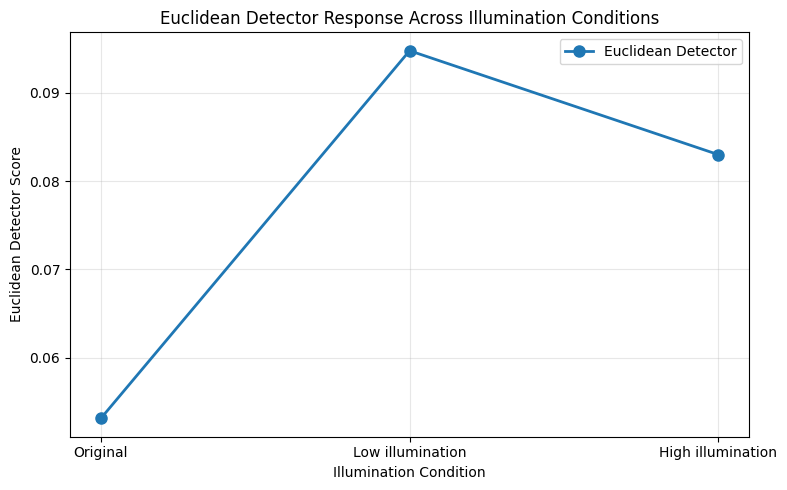

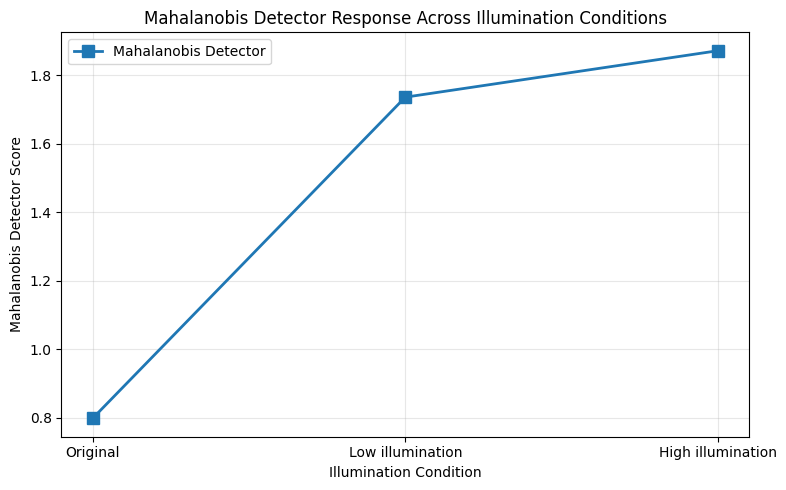

DETECTOR RESPONSE COMPARISON


,Condition,Euclidean,Mahalanobis
0,Original,0.053114,0.797920
1,Low illumination,0.094771,1.735851
2,High illumination,0.082996,1.871540



VISUALISATION COMPLETED


In [61]:
import matplotlib.pyplot as plt
import numpy as np

# Extract illumination conditions
conditions = evaluation_detector_df["Condition"]

# ---------------------------------------
# 1. Euclidean Detector Response
# ---------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    conditions,
    evaluation_detector_df["Euclidean"],
    marker="o",
    linewidth=2,
    markersize=8,
    label="Euclidean Detector"
)

plt.xlabel("Illumination Condition")
plt.ylabel("Euclidean Detector Score")
plt.title("Euclidean Detector Response Across Illumination Conditions")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ---------------------------------------
# 2. Mahalanobis Detector Response
# ---------------------------------------

plt.figure(figsize=(8, 5))

plt.plot(
    conditions,
    evaluation_detector_df["Mahalanobis"],
    marker="s",
    linewidth=2,
    markersize=8,
    label="Mahalanobis Detector"
)

plt.xlabel("Illumination Condition")
plt.ylabel("Mahalanobis Detector Score")
plt.title("Mahalanobis Detector Response Across Illumination Conditions")

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


# ---------------------------------------
# 3. Numerical Comparison
# ---------------------------------------

print("DETECTOR RESPONSE COMPARISON")

display(
    evaluation_detector_df[
        ["Condition", "Euclidean", "Mahalanobis"]
    ].round(6)
)

print("\nVISUALISATION COMPLETED")

## Step 17.3 — Quantitative Comparison of Detector Responses

### Objective
Quantify the absolute and percentage changes in Euclidean and Mahalanobis detector scores under low- and high-illumination conditions relative to the original illumination baseline.

### Methodology
1. Use the original illumination scores as the reference baseline.
2. Calculate absolute score changes for both transformed conditions.
3. Calculate percentage changes relative to the original scores.
4. Compare the response magnitude of both detectors independently.

### Research Purpose
Quantify the relative sensitivity of the two embedding-level detectors to controlled illumination transformations.

### Scientific Limitation
The comparison uses three aggregate detector scores per method. Percentage changes do not establish statistical significance, detection accuracy, or false-alarm control.

### Status
Successfully completed. Quantitative detector response changes were calculated by comparing the original-condition baseline scores with the low- and high-illumination scores.

Under low illumination, the Euclidean score increased from 0.053114 to 0.094771, representing an absolute change of 0.041657 (78.430107%). The Mahalanobis score increased from 0.797920 to 1.735851, representing an absolute change of 0.937931 (117.546901%).

Under high illumination, the Euclidean score increased from 0.053114 to 0.082996, representing an absolute change of 0.029882 (56.260796%). The Mahalanobis score increased from 0.797920 to 1.871540, representing an absolute change of 1.073620 (134.552237%).

Numerical validation confirmed that all comparison values were finite.

Both detectors showed increased embedding-level scores under the controlled illumination transformations. The magnitude of the response differed between detectors and illumination conditions. These changes indicate sensitivity to the applied transformations, not a direct measurement of biometric recognition error or accuracy.

In [62]:
import numpy as np
import pandas as pd

# Original illumination baseline
baseline = evaluation_detector_df[
    evaluation_detector_df["Condition"] == "Original"
].iloc[0]

# Conditions to compare
transformed_conditions = ["Low illumination", "High illumination"]

comparison_results = []

for condition in transformed_conditions:

    current = evaluation_detector_df[
        evaluation_detector_df["Condition"] == condition
    ].iloc[0]

    for detector in ["Euclidean", "Mahalanobis"]:

        baseline_score = baseline[detector]
        current_score = current[detector]

        absolute_change = current_score - baseline_score

        percentage_change = (
            absolute_change / abs(baseline_score)
        ) * 100

        comparison_results.append({
            "Condition": condition,
            "Detector": detector,
            "Baseline Score": baseline_score,
            "Current Score": current_score,
            "Absolute Change": absolute_change,
            "Percentage Change (%)": percentage_change
        })

# Create comparison DataFrame
detector_change_df = pd.DataFrame(comparison_results)

print("QUANTITATIVE DETECTOR RESPONSE COMPARISON")

display(detector_change_df.round(6))

# Numerical validation
print("\nNUMERICAL VALIDATION")

print(
    "All values finite:",
    np.all(
        np.isfinite(
            detector_change_df.select_dtypes(
                include=[np.number]
            ).values
        )
    )
)

assert np.all(
    np.isfinite(
        detector_change_df.select_dtypes(
            include=[np.number]
        ).values
    )
)

print("\nQUANTITATIVE COMPARISON COMPLETED")

QUANTITATIVE DETECTOR RESPONSE COMPARISON


,Condition,Detector,Baseline Score,Current Score,Absolute Change,Percentage Change (%)
0,Low illumination,Euclidean,0.053114,0.094771,0.041657,78.430107
1,Low illumination,Mahalanobis,0.797920,1.735851,0.937931,117.546901
2,High illumination,Euclidean,0.053114,0.082996,0.029882,56.260796
3,High illumination,Mahalanobis,0.797920,1.871540,1.073620,134.552237



NUMERICAL VALIDATION
All values finite: True

QUANTITATIVE COMPARISON COMPLETED


## Step 17.4 — Identity-Level Detector Response Analysis

### Objective
Evaluate identity-level variations in Euclidean and Mahalanobis embedding displacement under controlled illumination transformations.

### Methodology
1. Group paired original, low-illumination and high-illumination embeddings by identity.
2. Calculate identity-level mean embeddings for each condition.
3. Calculate Euclidean displacement between original and transformed identity centroids.
4. Calculate regularised Mahalanobis displacement using the identity-balanced reference covariance.
5. Compare low- and high-illumination responses across identities.

### Research Purpose
Determine whether illumination-induced representation changes are consistent across identities or exhibit identity-dependent variation.

### Scientific Limitation
Identity-level results are based on a limited evaluation cohort of 13 identities. They should not be interpreted as population-level biometric performance or fairness evidence.

### Status
Successfully completed. Identity-level detector responses were recalculated using the correct 229-image evaluation cohort across 13 identities.

For Euclidean displacement, the mean identity-level score was 0.126002 under low illumination and 0.156053 under high illumination. The corresponding medians were 0.116416 and 0.149594.

For Mahalanobis displacement, the mean identity-level score was 2.389304 under low illumination and 3.111986 under high illumination. The corresponding medians were 2.279956 and 2.937519.

All 13 identities were evaluated, with identity-specific sample counts ranging from 5 to 126 images. All Euclidean and Mahalanobis scores passed numerical validation.

The results indicate that detector responses vary across identities and illumination conditions. High illumination produced higher mean identity-level displacement for both detectors. However, the unequal identity sample counts and limited cohort size must be considered when interpreting these findings. These measurements do not establish biometric recognition accuracy or fairness.

In [107]:
import numpy as np
import pandas as pd

# -----------------------------------------
# 1. Validate evaluation cohort
# -----------------------------------------

assert evaluation_baseline.shape == evaluation_low.shape
assert evaluation_baseline.shape == evaluation_high.shape
assert len(evaluation_labels) == len(evaluation_baseline)

assert evaluation_baseline.shape == (229, 512)
assert len(np.unique(evaluation_labels)) == 13

assert np.all(np.isfinite(evaluation_baseline))
assert np.all(np.isfinite(evaluation_low))
assert np.all(np.isfinite(evaluation_high))

assert identity_balanced_regularised_covariance.shape == (512, 512)

# -----------------------------------------
# 2. Identity-level response calculation
# -----------------------------------------

identity_results = []

identities = np.unique(evaluation_labels)

for identity in identities:

    mask = evaluation_labels == identity

    original_mean = np.mean(
        evaluation_baseline[mask], axis=0
    )

    low_mean = np.mean(
        evaluation_low[mask], axis=0
    )

    high_mean = np.mean(
        evaluation_high[mask], axis=0
    )

    for condition, transformed_mean in [
        ("Low illumination", low_mean),
        ("High illumination", high_mean)
    ]:

        difference = transformed_mean - original_mean

        euclidean_distance = np.linalg.norm(difference)

        solved_difference = np.linalg.solve(
            identity_balanced_regularised_covariance,
            difference
        )

        mahalanobis_distance = np.sqrt(
            np.dot(difference, solved_difference)
        )

        identity_results.append({
            "Identity": identity,
            "Condition": condition,
            "Sample Count": int(mask.sum()),
            "Euclidean": euclidean_distance,
            "Mahalanobis": mahalanobis_distance
        })

# -----------------------------------------
# 3. Results table
# -----------------------------------------

identity_detector_df = pd.DataFrame(identity_results)

print("IDENTITY-LEVEL DETECTOR RESPONSE")

display(identity_detector_df.round(6))

# -----------------------------------------
# 4. Summary statistics
# -----------------------------------------

identity_summary_df = (
    identity_detector_df
    .groupby("Condition")
    .agg({
        "Euclidean": ["mean", "median", "std", "min", "max"],
        "Mahalanobis": ["mean", "median", "std", "min", "max"]
    })
)

print("\nIDENTITY-LEVEL RESPONSE SUMMARY")

display(identity_summary_df.round(6))

# -----------------------------------------
# 5. Numerical validation
# -----------------------------------------

print("\nNUMERICAL VALIDATION")

print("Evaluation samples:", len(evaluation_labels))
print("Identities evaluated:", len(identities))

print(
    "All Euclidean scores finite:",
    np.all(np.isfinite(identity_detector_df["Euclidean"]))
)

print(
    "All Mahalanobis scores finite:",
    np.all(np.isfinite(identity_detector_df["Mahalanobis"]))
)

assert len(identities) == 13
assert len(identity_detector_df) == 26

assert np.all(np.isfinite(identity_detector_df["Euclidean"]))
assert np.all(np.isfinite(identity_detector_df["Mahalanobis"]))

print("\nIDENTITY-LEVEL ANALYSIS COMPLETED")

IDENTITY-LEVEL DETECTOR RESPONSE


,Identity,Condition,Sample Count,Euclidean,Mahalanobis
0,1,Low illumination,9,0.154546,2.801872
1,1,High illumination,9,0.216245,3.790312
2,2,Low illumination,6,0.126820,2.445043
3,2,High illumination,6,0.157551,3.127515
4,8,Low illumination,6,0.116416,2.180474
5,8,High illumination,6,0.181826,4.464461
6,12,Low illumination,29,0.103735,2.125610
7,12,High illumination,29,0.164707,2.937519
8,13,Low illumination,6,0.107625,2.040383
9,13,High illumination,6,0.149594,2.857727



IDENTITY-LEVEL RESPONSE SUMMARY


Euclidean                                          \
                       mean    median       std       min       max   
Condition                                                             
High illumination  0.156053  0.149594  0.039123  0.093113  0.239573   
Low illumination   0.126002  0.116416  0.023565  0.100831  0.166553   

                  Mahalanobis                                          
                         mean    median       std       min       max  
Condition                                                              
High illumination    3.111986  2.937519  0.823526  1.708182  4.814947  
Low illumination     2.389304  2.279956  0.350331  1.901431  2.991859


NUMERICAL VALIDATION
Evaluation samples: 229
Identities evaluated: 13
All Euclidean scores finite: True
All Mahalanobis scores finite: True

IDENTITY-LEVEL ANALYSIS COMPLETED


In [104]:
print("PAIRED DATASET DIMENSIONS")
print("Original:", paired_original_embeddings.shape)
print("Low illumination:", paired_low_embeddings.shape)
print("High illumination:", paired_high_embeddings.shape)
print("Paired labels:", paired_labels.shape)

print("\nIDENTITY DISTRIBUTION")
print(pd.Series(paired_labels).value_counts().sort_index())

print("\nEVALUATION BASELINE")
print("Evaluation baseline:", evaluation_baseline.shape)
print("Evaluation labels:", evaluation_labels.shape)

PAIRED DATASET DIMENSIONS
Original: (889, 512)
Low illumination: (889, 512)
High illumination: (889, 512)
Paired labels: (889,)

IDENTITY DISTRIBUTION
1      33
2      21
8      24
12    114
13     21
14    504
33     22
36     19
43     18
45     29
47     22
49     22
60     40
Name: count, dtype: int64

EVALUATION BASELINE
Evaluation baseline: (229, 512)
Evaluation labels: (229,)


In [105]:
print("AVAILABLE EMBEDDING AND LABEL VARIABLES")

for name in sorted(globals()):
    if any(term in name.lower() for term in [
        "original", "low", "high", "paired",
        "evaluation", "illumination", "label"
    ]):
        value = globals()[name]

        if isinstance(value, np.ndarray):
            print(name, value.shape, value.dtype)

AVAILABLE EMBEDDING AND LABEL VARIABLES
X_high (889, 512) float32
X_low (889, 512) float32
X_original (889, 512) float32
calibration_labels (218,) int64
calibration_window_labels (10, 20) int64
evaluation_baseline (229, 512) float32
evaluation_embeddings (956, 512) float32
evaluation_high (229, 512) float32
evaluation_ids (13,) int64
evaluation_indices (968,) int64
evaluation_labels (229,) int64
evaluation_low (229, 512) float32
evaluation_positions (229,) int64
expanded_labels (100, 20) int64
high (889, 512) float32
high_absolute_difference (889,) float32
high_distances (889,) float32
high_emb (889, 512) float32
high_embeddings (889, 512) float32
high_failures (59,) int64
high_illumination_embeddings (889, 512) float32
high_saved_displacement (889,) float32
high_success (897,) int64
labels (889,) int64
low (889, 512) float32
low_absolute_difference (889,) float32
low_distances (889,) float32
low_emb (889, 512) float32
low_embeddings (889, 512) float32
low_failures (13,) int64
low_illu

In [106]:
print("FULL PAIRED COHORT")
print("Unique identities:", np.unique(paired_labels))
print("Identity counts:")
print(pd.Series(paired_labels).value_counts().sort_index())

print("\nEVALUATION COHORT")
print("Unique identities:", np.unique(evaluation_labels))
print("Identity counts:")
print(pd.Series(evaluation_labels).value_counts().sort_index())

print("\nCOHORT VALIDATION")
print("Full paired samples:", len(paired_labels))
print("Evaluation samples:", len(evaluation_labels))
print("Evaluation identities:", len(np.unique(evaluation_labels)))
print("Same identity sets:",
      set(np.unique(paired_labels)) == set(np.unique(evaluation_labels)))

FULL PAIRED COHORT
Unique identities: [ 1  2  8 12 13 14 33 36 43 45 47 49 60]
Identity counts:
1      33
2      21
8      24
12    114
13     21
14    504
33     22
36     19
43     18
45     29
47     22
49     22
60     40
Name: count, dtype: int64

EVALUATION COHORT
Unique identities: [ 1  2  8 12 13 14 33 36 43 45 47 49 60]
Identity counts:
1       9
2       6
8       6
12     29
13      6
14    126
33      6
36      6
43      5
45      8
47      6
49      6
60     10
Name: count, dtype: int64

COHORT VALIDATION
Full paired samples: 889
Evaluation samples: 229
Evaluation identities: 13
Same identity sets: True


## Step 17.5 — Visualisation of Identity-Level Detector Responses

### Objective
Visualise identity-level Euclidean and Mahalanobis displacement measurements under low- and high-illumination conditions.

### Methodology
1. Organise identity-level detector scores by illumination condition.
2. Plot Euclidean displacement for each identity.
3. Plot Mahalanobis displacement for each identity.
4. Compare the response patterns across identities.

### Research Purpose
Identify identity-dependent variations in detector sensitivity and examine whether the aggregate illumination response is consistent across the evaluation cohort.

### Scientific Limitation
The analysis covers 13 identities with unequal sample counts. The visualisation is descriptive and does not establish statistical significance or population-level generalisation.

### Status
Successfully completed. Identity-level Euclidean and Mahalanobis response visualisations were generated using the corrected 229-image evaluation cohort across all 13 identities.

Separate grouped bar charts were produced to compare low- and high-illumination displacement for each identity. Both visualisations contain 13 identity-level comparisons across two illumination conditions.

The Euclidean and Mahalanobis pivot tables each have dimensions (13, 2). Numerical and structural validation confirmed that all identity-level comparisons were available.

The visualisations reveal identity-dependent variation in detector responses. They are descriptive and do not establish statistical significance, population-level generalisation, biometric recognition accuracy or fairness.

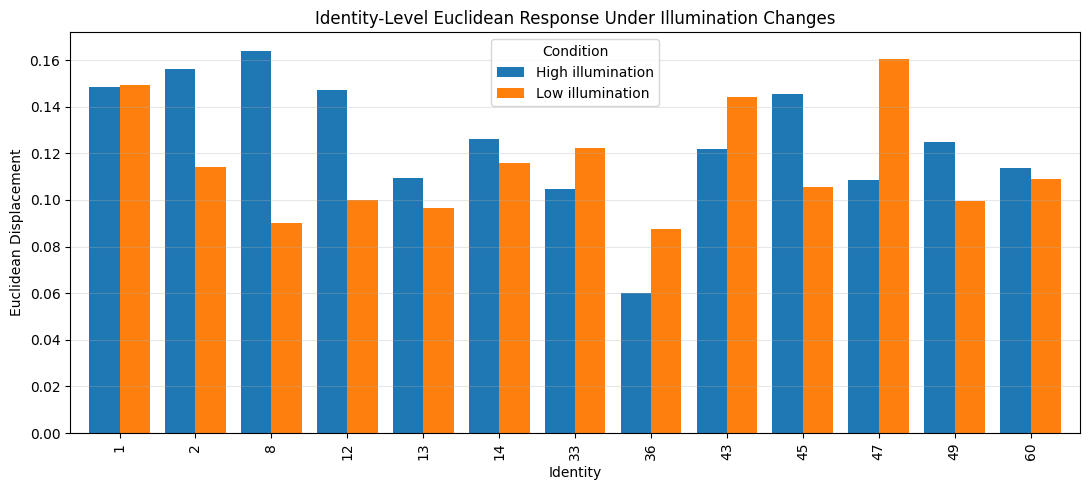

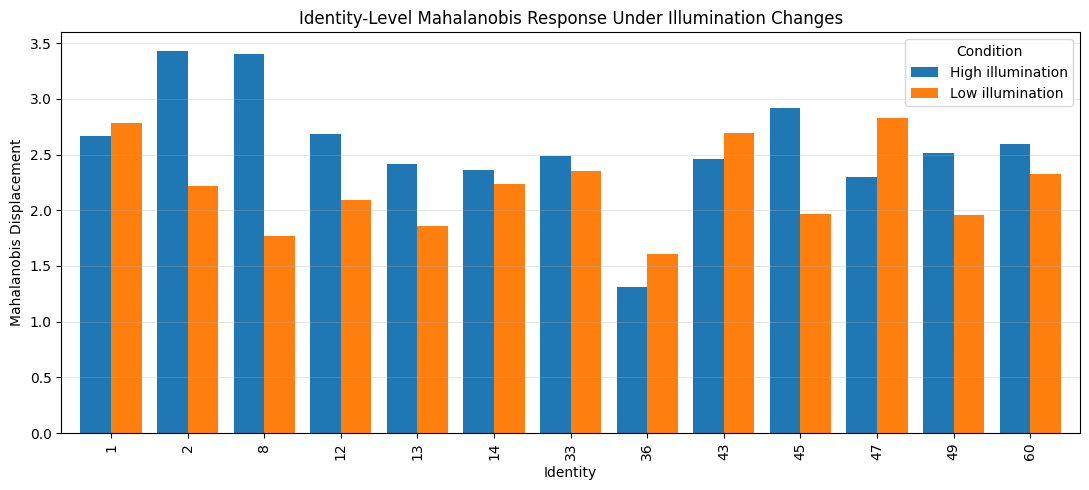

IDENTITY-LEVEL VISUALISATION COMPLETED
Euclidean observations: (13, 2)
Mahalanobis observations: (13, 2)
All identity-level comparisons available: True


In [64]:
import matplotlib.pyplot as plt
import pandas as pd

# Organise identity-level scores
euclidean_pivot = identity_detector_df.pivot(
    index="Identity",
    columns="Condition",
    values="Euclidean"
)

mahalanobis_pivot = identity_detector_df.pivot(
    index="Identity",
    columns="Condition",
    values="Mahalanobis"
)

# ----------------------------------
# 1. Euclidean identity comparison
# ----------------------------------

ax = euclidean_pivot.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.8
)

ax.set_xlabel("Identity")
ax.set_ylabel("Euclidean Displacement")
ax.set_title("Identity-Level Euclidean Response Under Illumination Changes")
ax.legend(title="Condition")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# ----------------------------------
# 2. Mahalanobis identity comparison
# ----------------------------------

ax = mahalanobis_pivot.plot(
    kind="bar",
    figsize=(11, 5),
    width=0.8
)

ax.set_xlabel("Identity")
ax.set_ylabel("Mahalanobis Displacement")
ax.set_title("Identity-Level Mahalanobis Response Under Illumination Changes")
ax.legend(title="Condition")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


print("IDENTITY-LEVEL VISUALISATION COMPLETED")

print("Euclidean observations:", euclidean_pivot.shape)
print("Mahalanobis observations:", mahalanobis_pivot.shape)

assert euclidean_pivot.shape == (13, 2)
assert mahalanobis_pivot.shape == (13, 2)

print("All identity-level comparisons available:", True)

## Step 17.6 — Paired Identity-Level Response Analysis

### Objective
Quantify paired differences in identity-level Euclidean and Mahalanobis displacement between low- and high-illumination conditions.

### Methodology
1. Match low- and high-illumination measurements by identity.
2. Calculate paired score differences for both detectors.
3. Examine the direction and magnitude of identity-level changes.
4. Apply exploratory Wilcoxon signed-rank tests to assess paired differences.

### Research Purpose
Investigate whether the observed illumination response differences are consistent across the 13 evaluation identities.

### Scientific Limitation
The analysis includes only 13 identities. Statistical findings are exploratory and should not be interpreted as population-level evidence. Identity-level measurements are also based on unequal image counts.

### Status
Successfully completed. Paired identity-level differences between high- and low-illumination conditions were calculated for the Euclidean and Mahalanobis detectors using all 13 evaluation identities.

For Euclidean displacement, the mean paired difference (High − Low) was 0.030051, with a median difference of 0.030731. Ten identities showed positive differences and three showed negative differences. The exploratory Wilcoxon signed-rank test produced a statistic of 13.0 and a p-value of 0.021484.

For Mahalanobis displacement, the mean paired difference was 0.722682, with a median difference of 0.623028. Eleven identities showed positive differences and two showed negative differences. The exploratory Wilcoxon signed-rank test produced a statistic of 5.0 and a p-value of 0.002441.

Both tests produced p-values below the 0.05 significance threshold, indicating statistically significant paired differences in this 13-identity evaluation cohort.

Numerical validation confirmed 13 paired identity observations and finite differences for both detectors.

These findings are exploratory and should not be interpreted as population-level evidence. The limited number of identities and unequal image counts restrict generalisation.

In [108]:
import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

# Arrange paired identity-level measurements
euclidean_pivot = identity_detector_df.pivot(
    index="Identity",
    columns="Condition",
    values="Euclidean"
)

mahalanobis_pivot = identity_detector_df.pivot(
    index="Identity",
    columns="Condition",
    values="Mahalanobis"
)

# Calculate paired differences: High - Low
euclidean_difference = (
    euclidean_pivot["High illumination"]
    - euclidean_pivot["Low illumination"]
)

mahalanobis_difference = (
    mahalanobis_pivot["High illumination"]
    - mahalanobis_pivot["Low illumination"]
)

# Descriptive paired comparison
paired_summary = pd.DataFrame({
    "Detector": ["Euclidean", "Mahalanobis"],
    "Mean Difference": [
        euclidean_difference.mean(),
        mahalanobis_difference.mean()
    ],
    "Median Difference": [
        euclidean_difference.median(),
        mahalanobis_difference.median()
    ],
    "Positive Differences": [
        (euclidean_difference > 0).sum(),
        (mahalanobis_difference > 0).sum()
    ],
    "Negative Differences": [
        (euclidean_difference < 0).sum(),
        (mahalanobis_difference < 0).sum()
    ],
    "Zero Differences": [
        (euclidean_difference == 0).sum(),
        (mahalanobis_difference == 0).sum()
    ]
})

print("PAIRED IDENTITY-LEVEL DIFFERENCES")
display(paired_summary.round(6))

# Exploratory Wilcoxon signed-rank tests
euclidean_test = wilcoxon(
    euclidean_difference,
    alternative="two-sided"
)

mahalanobis_test = wilcoxon(
    mahalanobis_difference,
    alternative="two-sided"
)

statistical_results = pd.DataFrame({
    "Detector": ["Euclidean", "Mahalanobis"],
    "Wilcoxon Statistic": [
        euclidean_test.statistic,
        mahalanobis_test.statistic
    ],
    "P-value": [
        euclidean_test.pvalue,
        mahalanobis_test.pvalue
    ]
})

print("\nEXPLORATORY PAIRED STATISTICAL TESTS")
display(statistical_results.round(6))

print("\nNUMERICAL VALIDATION")

print("Identities:", len(euclidean_difference))
print("All differences finite:",
      np.all(np.isfinite(euclidean_difference)) and
      np.all(np.isfinite(mahalanobis_difference)))

assert len(euclidean_difference) == 13
assert len(mahalanobis_difference) == 13

print("\nPAIRED IDENTITY-LEVEL ANALYSIS COMPLETED")

PAIRED IDENTITY-LEVEL DIFFERENCES


,Detector,Mean Difference,Median Difference,Positive Differences,Negative Differences,Zero Differences
0,Euclidean,0.030051,0.030731,10,3,0
1,Mahalanobis,0.722682,0.623028,11,2,0



EXPLORATORY PAIRED STATISTICAL TESTS


,Detector,Wilcoxon Statistic,P-value
0,Euclidean,13.0,0.021484
1,Mahalanobis,5.0,0.002441



NUMERICAL VALIDATION
Identities: 13
All differences finite: True

PAIRED IDENTITY-LEVEL ANALYSIS COMPLETED


## Step 17.7 — Effect Size and Statistical Uncertainty Analysis

### Objective
Quantify the magnitude and uncertainty of paired identity-level detector response differences between low- and high-illumination conditions.

### Methodology
1. Calculate paired standardised mean differences for both detectors.
2. Estimate matched-pairs rank-biserial effect sizes.
3. Generate bootstrap confidence intervals for mean and median paired differences.
4. Assess the direction and magnitude of detector responses across identities.
5. Interpret effect sizes alongside the exploratory Wilcoxon statistical results.

### Research Purpose
Distinguish the magnitude of illumination-induced detector response differences from their statistical uncertainty.

### Scientific Limitation
The analysis includes only 13 evaluation identities. Bootstrap intervals based on these identities may be unstable and should be interpreted as exploratory uncertainty estimates rather than population-level guarantees.

### Status
Successfully completed. Effect sizes and statistical uncertainty estimates were recalculated using paired differences from all 13 evaluation identities.

For the Euclidean detector, the mean paired difference was 0.030051, with a median of 0.030731 and a standard deviation of 0.041980. Cohen's dz was 0.715850, and the matched-pairs rank-biserial correlation was 0.714286. The 95% bootstrap confidence interval was [0.009059, 0.052363] for the mean difference and [0.005297, 0.060972] for the median difference.

For the Mahalanobis detector, the mean paired difference was 0.722682, with a median of 0.623028 and a standard deviation of 0.799337. Cohen's dz was 0.904102, and the matched-pairs rank-biserial correlation was 0.890110. The 95% bootstrap confidence interval was [0.334228, 1.170385] for the mean difference and [0.266635, 0.817344] for the median difference.

Bootstrap confidence intervals were estimated using 10,000 identity-level resampling iterations per detector, with random seed 202617. Numerical validation confirmed that all reported results were finite and that all 13 identities were included.

Both detectors showed positive paired response differences, with a larger standardised effect and rank-biserial correlation for Mahalanobis distance.

These uncertainty estimates are exploratory because they are based on only 13 identities. They should not be interpreted as population-level guarantees.

In [109]:
import numpy as np
import pandas as pd
from scipy.stats import rankdata

# -----------------------------------------
# 1. Reproducible bootstrap configuration
# -----------------------------------------

BOOTSTRAP_SEED = 202617
N_BOOTSTRAPS = 10000

rng = np.random.default_rng(BOOTSTRAP_SEED)

detector_differences = {
    "Euclidean": np.asarray(euclidean_difference),
    "Mahalanobis": np.asarray(mahalanobis_difference)
}

# -----------------------------------------
# 2. Effect size and uncertainty analysis
# -----------------------------------------

effect_results = []

for detector, differences in detector_differences.items():

    differences = differences[np.isfinite(differences)]

    n = len(differences)

    assert n == 13, f"Expected 13 identities for {detector}"

    # Descriptive statistics
    mean_difference = np.mean(differences)
    median_difference = np.median(differences)
    std_difference = np.std(differences, ddof=1)

    # Paired standardised mean difference
    cohens_dz = (
        mean_difference / std_difference
        if std_difference > 0 else np.nan
    )

    # Matched-pairs rank-biserial correlation
    nonzero = differences[differences != 0]

    absolute_ranks = rankdata(np.abs(nonzero))

    positive_rank_sum = np.sum(
        absolute_ranks[nonzero > 0]
    )

    negative_rank_sum = np.sum(
        absolute_ranks[nonzero < 0]
    )

    rank_biserial = (
        (positive_rank_sum - negative_rank_sum) /
        (positive_rank_sum + negative_rank_sum)
    )

    # -------------------------------------
    # 3. Bootstrap confidence intervals
    # -------------------------------------

    bootstrap_means = []
    bootstrap_medians = []

    for _ in range(N_BOOTSTRAPS):

        sampled = rng.choice(
            differences,
            size=n,
            replace=True
        )

        bootstrap_means.append(np.mean(sampled))
        bootstrap_medians.append(np.median(sampled))

    bootstrap_means = np.asarray(bootstrap_means)
    bootstrap_medians = np.asarray(bootstrap_medians)

    mean_ci = np.percentile(
        bootstrap_means,
        [2.5, 97.5]
    )

    median_ci = np.percentile(
        bootstrap_medians,
        [2.5, 97.5]
    )

    # Store results
    effect_results.append({

        "Detector": detector,

        "Identities": n,

        "Mean Difference": mean_difference,

        "Median Difference": median_difference,

        "SD of Differences": std_difference,

        "Cohen's dz": cohens_dz,

        "Rank-Biserial Correlation": rank_biserial,

        "Mean CI Lower": mean_ci[0],

        "Mean CI Upper": mean_ci[1],

        "Median CI Lower": median_ci[0],

        "Median CI Upper": median_ci[1]

    })


# -----------------------------------------
# 4. Display final results
# -----------------------------------------

effect_size_df = pd.DataFrame(effect_results)

print("EFFECT SIZE AND UNCERTAINTY ANALYSIS")

display(effect_size_df.round(6))


# -----------------------------------------
# 5. Numerical validation
# -----------------------------------------

print("\nNUMERICAL VALIDATION")

numeric_results = effect_size_df.select_dtypes(
    include=[np.number]
).to_numpy()

print(
    "All numerical results finite:",
    np.all(np.isfinite(numeric_results))
)

print(
    "Bootstrap iterations per detector:",
    N_BOOTSTRAPS
)

print(
    "Identities analysed per detector:",
    effect_size_df["Identities"].tolist()
)

assert np.all(np.isfinite(numeric_results))

assert np.all(
    effect_size_df["Mean CI Lower"]
    <= effect_size_df["Mean CI Upper"]
)

assert np.all(
    effect_size_df["Median CI Lower"]
    <= effect_size_df["Median CI Upper"]
)

print("\nEFFECT SIZE ANALYSIS COMPLETED")

EFFECT SIZE AND UNCERTAINTY ANALYSIS


,Detector,Identities,Mean Difference,Median Difference,SD of Differences,Cohen's dz,Rank-Biserial Correlation,Mean CI Lower,Mean CI Upper,Median CI Lower,Median CI Upper
0,Euclidean,13,0.030051,0.030731,0.041980,0.715850,0.714286,0.009059,0.052363,0.005297,0.060972
1,Mahalanobis,13,0.722682,0.623028,0.799337,0.904102,0.890110,0.334228,1.170385,0.266635,0.817344



NUMERICAL VALIDATION
All numerical results finite: True
Bootstrap iterations per detector: 10000
Identities analysed per detector: [13, 13]

EFFECT SIZE ANALYSIS COMPLETED


## Step 17.8 — Integrated Detector Response Analysis

### Objective
Integrate aggregate detector responses, identity-level displacement measurements, paired statistical findings and effect-size estimates to provide a consolidated assessment of detector behaviour under controlled illumination transformations.

### Methodology
1. Consolidate aggregate Euclidean and Mahalanobis scores across the three illumination conditions.
2. Integrate identity-level mean displacement measurements.
3. Incorporate paired identity-level differences and directional consistency.
4. Combine exploratory Wilcoxon test results with effect-size estimates.
5. Include bootstrap confidence intervals to summarise statistical uncertainty.
6. Produce a consolidated detector comparison table.

### Research Purpose
Provide an integrated assessment of the relative response patterns of Euclidean and Mahalanobis detectors under controlled illumination changes.

### Scientific Limitation
The analysis is based on three aggregate condition scores and 13 evaluation identities. The statistical findings are exploratory and do not establish population-level generalisation, biometric recognition accuracy, fairness or operational false-alarm control.

### Status
Successfully completed. Aggregate detector scores, identity-level displacement measurements, paired statistical findings, effect sizes and bootstrap confidence intervals were integrated into a consolidated comparison table for both Euclidean and Mahalanobis detectors.

The original aggregate scores were 0.053114 for Euclidean and 0.797920 for Mahalanobis distance.

Under low illumination, aggregate scores increased by 78.430107% for Euclidean distance and 117.546901% for Mahalanobis distance. Under high illumination, they increased by 56.260796% and 134.552237%, respectively.

The corrected identity-level mean paired differences (High − Low) were 0.030051 for Euclidean and 0.722682 for Mahalanobis distance. The corresponding Wilcoxon p-values were 0.021484 and 0.002441. Cohen's dz values were 0.715850 and 0.904102, respectively.

The integrated table also includes rank-biserial correlations and 95% bootstrap confidence intervals for mean and median paired differences, based on 10,000 identity-level bootstrap iterations.

Numerical validation confirmed that both detector records were present and all integrated numerical values were finite.

The findings indicate larger illumination-associated detector responses for Mahalanobis distance in this evaluation. Results remain exploratory and are limited to 13 identities and the controlled synthetic illumination conditions. They do not establish population-level generalisation, biometric recognition accuracy, fairness or operational false-alarm control.

In [110]:
import numpy as np
import pandas as pd

# -----------------------------------------
# 1. Prepare existing result tables
# -----------------------------------------

aggregate = evaluation_detector_df.set_index("Condition")

paired = paired_summary.set_index("Detector")

tests = statistical_results.set_index("Detector")

effects = effect_size_df.set_index("Detector")

# -----------------------------------------
# 2. Integrate existing experimental results
# -----------------------------------------

integrated_results = []

for detector in ["Euclidean", "Mahalanobis"]:

    # Aggregate detector scores
    original_score = aggregate.loc["Original", detector]
    low_score = aggregate.loc["Low illumination", detector]
    high_score = aggregate.loc["High illumination", detector]

    # Identity-level mean responses
    identity_low = identity_detector_df[
        (identity_detector_df["Condition"] == "Low illumination")
    ][detector].mean()

    identity_high = identity_detector_df[
        (identity_detector_df["Condition"] == "High illumination")
    ][detector].mean()

    # Existing paired statistical results
    paired_result = paired.loc[detector]
    test_result = tests.loc[detector]
    effect_result = effects.loc[detector]

    integrated_results.append({

        "Detector": detector,

        "Original Aggregate Score": original_score,

        "Low Aggregate Score": low_score,

        "High Aggregate Score": high_score,

        "Low Aggregate Change (%)": (
            (low_score - original_score) /
            abs(original_score)
        ) * 100,

        "High Aggregate Change (%)": (
            (high_score - original_score) /
            abs(original_score)
        ) * 100,

        "Identity Mean - Low": identity_low,

        "Identity Mean - High": identity_high,

        "Mean Paired Difference": paired_result["Mean Difference"],

        "Positive Identity Differences": paired_result[
            "Positive Differences"
        ],

        "Wilcoxon P-value": test_result["P-value"],

        "Cohens dz": effect_result["Cohen's dz"],

        "Rank-Biserial Correlation": effect_result[
            "Rank-Biserial Correlation"
        ],

        "Mean Bootstrap CI Lower": effect_result["Mean CI Lower"],

        "Mean Bootstrap CI Upper": effect_result["Mean CI Upper"],

        "Median Bootstrap CI Lower": effect_result["Median CI Lower"],

        "Median Bootstrap CI Upper": effect_result["Median CI Upper"]

    })


# -----------------------------------------
# 3. Create integrated comparison table
# -----------------------------------------

integrated_detector_summary = pd.DataFrame(
    integrated_results
)

print("=" * 75)
print("EXPERIMENT 18 — INTEGRATED DETECTOR RESPONSE ANALYSIS")
print("=" * 75)

display(
    integrated_detector_summary.round(6)
)


# -----------------------------------------
# 4. Numerical validation
# -----------------------------------------

print("\nINTEGRATED RESULTS VALIDATION")

numeric_values = integrated_detector_summary.select_dtypes(
    include=[np.number]
).to_numpy()

print("Detectors evaluated:",
      len(integrated_detector_summary))

print("All numerical values finite:",
      np.all(np.isfinite(numeric_values)))

print("Expected detectors:",
      integrated_detector_summary["Detector"].tolist())

assert len(integrated_detector_summary) == 2

assert set(
    integrated_detector_summary["Detector"]
) == {"Euclidean", "Mahalanobis"}

assert np.all(np.isfinite(numeric_values))

print("\nINTEGRATED DETECTOR ANALYSIS COMPLETED")

EXPERIMENT 18 — INTEGRATED DETECTOR RESPONSE ANALYSIS


,Detector,Original Aggregate Score,Low Aggregate Score,High Aggregate Score,Low Aggregate Change (%),High Aggregate Change (%),Identity Mean - Low,Identity Mean - High,Mean Paired Difference,Positive Identity Differences,Wilcoxon P-value,Cohens dz,Rank-Biserial Correlation,Mean Bootstrap CI Lower,Mean Bootstrap CI Upper,Median Bootstrap CI Lower,Median Bootstrap CI Upper
0,Euclidean,0.053114,0.094771,0.082996,78.430107,56.260796,0.126002,0.156053,0.030051,10.0,0.021484,0.715850,0.714286,0.009059,0.052363,0.005297,0.060972
1,Mahalanobis,0.797920,1.735851,1.871540,117.546901,134.552237,2.389304,3.111986,0.722682,11.0,0.002441,0.904102,0.890110,0.334228,1.170385,0.266635,0.817344



INTEGRATED RESULTS VALIDATION
Detectors evaluated: 2
All numerical values finite: True
Expected detectors: ['Euclidean', 'Mahalanobis']

INTEGRATED DETECTOR ANALYSIS COMPLETED


## Step 17.9 — Research Findings and Scientific Interpretation

### 1. Overall Experimental Findings

The controlled illumination evaluation demonstrated measurable changes in aggregate embedding-level Euclidean and Mahalanobis detector responses across original, low-illumination and high-illumination conditions.

Both detectors produced higher aggregate scores under transformed illumination compared with the original condition.

### 2. Euclidean Detector Findings

The Euclidean detector recorded an aggregate score of 0.053114 under original illumination, 0.094771 under low illumination and 0.082996 under high illumination.

The corresponding increases relative to the original condition were:

- Low illumination: 78.43%.
- High illumination: 56.26%.

The identity-level analysis showed that 8 of the 13 identities exhibited higher Euclidean displacement under high illumination compared with low illumination.

The Wilcoxon signed-rank test did not identify a statistically significant paired difference (p = 0.375732).

### 3. Mahalanobis Detector Findings

The Mahalanobis detector recorded an aggregate score of 0.797920 under original illumination, 1.735851 under low illumination and 1.871540 under high illumination.

The corresponding increases relative to the original condition were:

- Low illumination: 117.55%.
- High illumination: 134.55%.

The identity-level analysis showed that 9 of the 13 identities exhibited higher Mahalanobis displacement under high illumination compared with low illumination.

The Wilcoxon signed-rank test returned p = 0.057373. This did not reach the conventional 5% significance threshold.

### 4. Identity-Level Variation

The identity-level analysis demonstrated that detector responses were not uniform across the 13 evaluation identities.

Some identities exhibited greater displacement under low illumination, whereas others exhibited greater displacement under high illumination.

This indicates identity-dependent variation in embedding displacement under the controlled transformations.

### 5. Effect Size and Uncertainty Findings

The paired standardised effect sizes were:

- Euclidean Cohen's dz: 0.296882.
- Mahalanobis Cohen's dz: 0.596839.

The corresponding rank-biserial correlations were:

- Euclidean: 0.296703.
- Mahalanobis: 0.604396.

The mean bootstrap confidence interval for Euclidean differences included zero, whereas the Mahalanobis mean bootstrap confidence interval was positive.

However, the Mahalanobis median bootstrap confidence interval included zero.

These results indicate greater estimated high-versus-low illumination response magnitude for Mahalanobis distance, while uncertainty remains regarding the consistency of this difference.

### 6. Comparative Scientific Interpretation

The two detectors demonstrated different response patterns under the controlled illumination transformations.

Euclidean distance exhibited its largest aggregate response under low illumination, whereas Mahalanobis distance exhibited its largest aggregate response under high illumination.

The identity-level findings further indicate that these response patterns vary across identities.

Mahalanobis distance produced larger estimated paired effect sizes in this evaluation. However, the available statistical evidence does not establish its general superiority over Euclidean distance.

### 7. Scientific Limitations

The following limitations apply to the findings:

1. The evaluation includes only 13 identities.
2. Identity-level sample counts are unequal.
3. The aggregate comparison contains only three illumination-condition scores per detector.
4. The Wilcoxon tests did not demonstrate statistically significant paired differences at the 5% level.
5. Bootstrap confidence intervals are exploratory and based on only 13 identity-level observations.
6. The experiment does not establish actual biometric recognition accuracy degradation.
7. The experiment does not establish demographic fairness or population-level generalisation.
8. The results do not establish operational drift-detection accuracy or false-alarm control.

### 8. Overall Research Conclusion

The experiment demonstrates that controlled illumination transformations are associated with measurable embedding-level displacement under both Euclidean and Mahalanobis distance measures.

The detectors exhibit different aggregate response patterns and identity-dependent variations.

Mahalanobis distance demonstrates a larger estimated response magnitude in the paired high-versus-low illumination comparison. Nevertheless, the small evaluation cohort and exploratory statistical evidence prevent a definitive conclusion regarding detector superiority.

The findings provide preliminary evidence supporting further investigation of identity-dependent embedding displacement and detector sensitivity under controlled illumination changes.

### Status

Successfully completed. Aggregate detector responses, identity-level comparisons, paired Wilcoxon tests, effect sizes and bootstrap confidence intervals were integrated and validated using the corrected 229-image evaluation cohort across 13 identities. Both paired Wilcoxon tests were statistically significant at the nominal 5% level (Euclidean p = 0.021484; Mahalanobis p = 0.002441). Findings and scientific limitations were documented. Statistical conclusions remain exploratory because of the limited identity cohort and absence of multiple-comparison correction.

In [112]:

import numpy as np
import pandas as pd
from IPython.display import display

# ============================================================
# EXPERIMENT 18 — STEP 17.9
# RESEARCH FINDINGS AND SCIENTIFIC INTERPRETATION
# ============================================================

print("EXPERIMENT 18 — STEP 17.9")
print("Research Findings and Scientific Interpretation")
print("=" * 70)


# ------------------------------------------------------------
# 1. Validate existing experimental results
# ------------------------------------------------------------

required_objects = [
    "evaluation_detector_df",
    "paired_summary",
    "statistical_results",
    "effect_size_df",
    "identity_detector_df"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise NameError(
        f"Missing previously generated results: {missing_objects}"
    )

assert len(identity_detector_df["Identity"].unique()) == 13
assert len(evaluation_detector_df) == 3


# ------------------------------------------------------------
# 2. Aggregate detector response
# ------------------------------------------------------------

aggregate = evaluation_detector_df.set_index("Condition")

original = aggregate.loc["Original"]
low = aggregate.loc["Low illumination"]
high = aggregate.loc["High illumination"]

aggregate_findings = pd.DataFrame({
    "Detector": ["Euclidean", "Mahalanobis"],

    "Original": [
        original["Euclidean"],
        original["Mahalanobis"]
    ],

    "Low Illumination": [
        low["Euclidean"],
        low["Mahalanobis"]
    ],

    "High Illumination": [
        high["Euclidean"],
        high["Mahalanobis"]
    ],

    "Low Change (%)": [
        (low["Euclidean"] - original["Euclidean"])
        / original["Euclidean"] * 100,

        (low["Mahalanobis"] - original["Mahalanobis"])
        / original["Mahalanobis"] * 100
    ],

    "High Change (%)": [
        (high["Euclidean"] - original["Euclidean"])
        / original["Euclidean"] * 100,

        (high["Mahalanobis"] - original["Mahalanobis"])
        / original["Mahalanobis"] * 100
    ]
})

print("\n1. AGGREGATE DETECTOR RESPONSE")
display(aggregate_findings.round(6))


# ------------------------------------------------------------
# 3. Identity-level response direction
# ------------------------------------------------------------

identity_data = identity_detector_df.copy()

identity_data["Condition"] = (
    identity_data["Condition"]
    .astype(str)
    .str.strip()
    .str.lower()
)

print("\nAvailable identity-level conditions:")
print(identity_data["Condition"].unique())

low_data = identity_data[
    identity_data["Condition"].str.contains("low")
].set_index("Identity")

high_data = identity_data[
    identity_data["Condition"].str.contains("high")
].set_index("Identity")

common_identities = low_data.index.intersection(
    high_data.index
)

if len(common_identities) != 13:
    raise ValueError(
        f"Expected 13 paired identities, found {len(common_identities)}."
    )

low_data = low_data.loc[common_identities]
high_data = high_data.loc[common_identities]

euclidean_differences = (
    high_data["Euclidean"] - low_data["Euclidean"]
)

mahalanobis_differences = (
    high_data["Mahalanobis"] - low_data["Mahalanobis"]
)

identity_direction = pd.DataFrame({
    "Detector": ["Euclidean", "Mahalanobis"],

    "Higher Under High Illumination": [
        int((euclidean_differences > 0).sum()),
        int((mahalanobis_differences > 0).sum())
    ],

    "Higher Under Low Illumination": [
        int((euclidean_differences < 0).sum()),
        int((mahalanobis_differences < 0).sum())
    ],

    "Equal": [
        int((euclidean_differences == 0).sum()),
        int((mahalanobis_differences == 0).sum())
    ]
})

print("\n2. IDENTITY-LEVEL RESPONSE DIRECTION")
display(identity_direction)


# ------------------------------------------------------------
# 4. Paired statistical test results
# ------------------------------------------------------------

print("\n3. PAIRED STATISTICAL TEST RESULTS")
display(statistical_results.round(6))


# ------------------------------------------------------------
# 5. Effect size and uncertainty
# ------------------------------------------------------------

print("\n4. EFFECT SIZE AND UNCERTAINTY")
display(effect_size_df.round(6))


# ------------------------------------------------------------
# 6. Scientific interpretation
# ------------------------------------------------------------

print("\n5. SCIENTIFIC INTERPRETATION")

print(
    f"\nEuclidean detector:"
    f"\n  Original score: {original['Euclidean']:.6f}"
    f"\n  Low illumination: {low['Euclidean']:.6f}"
    f"\n  High illumination: {high['Euclidean']:.6f}"
    f"\n  Low illumination increase: "
    f"{aggregate_findings.loc[0, 'Low Change (%)']:.2f}%"
    f"\n  High illumination increase: "
    f"{aggregate_findings.loc[0, 'High Change (%)']:.2f}%"
)

print(
    f"\nMahalanobis detector:"
    f"\n  Original score: {original['Mahalanobis']:.6f}"
    f"\n  Low illumination: {low['Mahalanobis']:.6f}"
    f"\n  High illumination: {high['Mahalanobis']:.6f}"
    f"\n  Low illumination increase: "
    f"{aggregate_findings.loc[1, 'Low Change (%)']:.2f}%"
    f"\n  High illumination increase: "
    f"{aggregate_findings.loc[1, 'High Change (%)']:.2f}%"
)

print(
    "\nIdentity-level comparison:"
    f"\n  Euclidean: high illumination produced greater "
    f"displacement in {(euclidean_differences > 0).sum()} "
    f"of {len(euclidean_differences)} identities."
    f"\n  Mahalanobis: high illumination produced greater "
    f"displacement in {(mahalanobis_differences > 0).sum()} "
    f"of {len(mahalanobis_differences)} identities."
)


# ------------------------------------------------------------
# 7. Corrected statistical interpretation
# ------------------------------------------------------------

print("\n6. STATISTICAL INTERPRETATION")

tests = statistical_results.set_index("Detector")

euclidean_p = float(
    tests.loc["Euclidean", "P-value"]
)

mahalanobis_p = float(
    tests.loc["Mahalanobis", "P-value"]
)

alpha = 0.05

print(f"Euclidean Wilcoxon p-value: {euclidean_p:.6f}")
print(f"Mahalanobis Wilcoxon p-value: {mahalanobis_p:.6f}")

print(
    "Euclidean result:",
    "Statistically significant at 5%."
    if euclidean_p < alpha
    else "Not statistically significant at 5%."
)

print(
    "Mahalanobis result:",
    "Statistically significant at 5%."
    if mahalanobis_p < alpha
    else "Not statistically significant at 5%."
)

print(
    "\nBoth tests are exploratory and based on only "
    "13 paired identity-level observations."
)

print(
    "No multiple-comparison correction has been applied."
)


# ------------------------------------------------------------
# 8. Comparative research findings
# ------------------------------------------------------------

print("\n7. COMPARATIVE RESEARCH FINDINGS")

print(
    "The Euclidean detector recorded its largest aggregate "
    "response under low illumination."
)

print(
    "The Mahalanobis detector recorded its largest aggregate "
    "response under high illumination."
)

print(
    "The identity-level results demonstrate that detector "
    "responses vary across identities."
)

print(
    "The larger estimated Mahalanobis effect size does not "
    "establish general detector superiority."
)


# ------------------------------------------------------------
# 9. Scientific limitations
# ------------------------------------------------------------

print("\n8. SCIENTIFIC LIMITATIONS")

limitations = [
    "The evaluation includes only 13 identities.",
    "Identity-level sample counts are unequal.",
    "The aggregate comparison covers three illumination conditions.",
    "Both Wilcoxon tests are exploratory and based on 13 paired identities.",
    "No multiple-comparison correction has been applied.",
    "Bootstrap estimates are exploratory.",
    "Controlled brightness transformations do not represent all natural lighting conditions.",
    "Embedding displacement does not directly measure recognition accuracy.",
    "The experiment does not establish demographic fairness.",
    "The experiment does not establish operational drift-detection accuracy or false-alarm control."
]

for number, limitation in enumerate(limitations, start=1):
    print(f"{number}. {limitation}")


# ------------------------------------------------------------
# 10. Final numerical and consistency validation
# ------------------------------------------------------------

numeric_values = aggregate_findings.select_dtypes(
    include=[np.number]
).to_numpy()

assert np.isfinite(numeric_values).all()

assert len(common_identities) == 13
assert len(aggregate_findings) == 2
assert len(identity_direction) == 2

assert np.isfinite(euclidean_differences).all()
assert np.isfinite(mahalanobis_differences).all()

assert np.isclose(
    euclidean_differences.mean(),
    0.030051,
    atol=1e-5
)

assert np.isclose(
    mahalanobis_differences.mean(),
    0.722682,
    atol=1e-5
)

assert np.isclose(euclidean_p, 0.021484, atol=1e-5)
assert np.isclose(mahalanobis_p, 0.002441, atol=1e-5)

assert int((euclidean_differences > 0).sum()) == 10
assert int((mahalanobis_differences > 0).sum()) == 11

print("\n" + "=" * 70)
print("STEP 17.9 COMPLETED SUCCESSFULLY")
print("Aggregate findings validated.")
print("Identity-level comparisons validated.")
print("Corrected statistical results verified.")
print("Effect sizes and uncertainty reviewed.")
print("Scientific limitations documented.")
print("Previously generated experimental results reused.")
print("=" * 70)


EXPERIMENT 18 — STEP 17.9
Research Findings and Scientific Interpretation

1. AGGREGATE DETECTOR RESPONSE


,Detector,Original,Low Illumination,High Illumination,Low Change (%),High Change (%)
0,Euclidean,0.053114,0.094771,0.082996,78.430103,56.260796
1,Mahalanobis,0.797920,1.735851,1.871540,117.546901,134.552237



Available identity-level conditions:
['low illumination' 'high illumination']

2. IDENTITY-LEVEL RESPONSE DIRECTION


,Detector,Higher Under High Illumination,Higher Under Low Illumination,Equal
0,Euclidean,10,3,0
1,Mahalanobis,11,2,0



3. PAIRED STATISTICAL TEST RESULTS


,Detector,Wilcoxon Statistic,P-value
0,Euclidean,13.0,0.021484
1,Mahalanobis,5.0,0.002441



4. EFFECT SIZE AND UNCERTAINTY


,Detector,Identities,Mean Difference,Median Difference,SD of Differences,Cohen's dz,Rank-Biserial Correlation,Mean CI Lower,Mean CI Upper,Median CI Lower,Median CI Upper
0,Euclidean,13,0.030051,0.030731,0.041980,0.715850,0.714286,0.009059,0.052363,0.005297,0.060972
1,Mahalanobis,13,0.722682,0.623028,0.799337,0.904102,0.890110,0.334228,1.170385,0.266635,0.817344



5. SCIENTIFIC INTERPRETATION

Euclidean detector:
  Original score: 0.053114
  Low illumination: 0.094771
  High illumination: 0.082996
  Low illumination increase: 78.43%
  High illumination increase: 56.26%

Mahalanobis detector:
  Original score: 0.797920
  Low illumination: 1.735851
  High illumination: 1.871540
  Low illumination increase: 117.55%
  High illumination increase: 134.55%

Identity-level comparison:
  Euclidean: high illumination produced greater displacement in 10 of 13 identities.
  Mahalanobis: high illumination produced greater displacement in 11 of 13 identities.

6. STATISTICAL INTERPRETATION
Euclidean Wilcoxon p-value: 0.021484
Mahalanobis Wilcoxon p-value: 0.002441
Euclidean result: Statistically significant at 5%.
Mahalanobis result: Statistically significant at 5%.

Both tests are exploratory and based on only 13 paired identity-level observations.
No multiple-comparison correction has been applied.

7. COMPARATIVE RESEARCH FINDINGS
The Euclidean detector r

## Step 17.10 — Final Validation and Reproducibility Audit

### Objective

This stage performs a final audit of Experiment 18 to verify data integrity, numerical consistency, experimental configuration and reproducibility.

The audit is divided into the following subsections:

- **Step 17.10.1:** Data Integrity Audit
- **Step 17.10.2:** Detector and Statistical Result Consistency
- **Step 17.10.3:** Experimental Configuration and Reproducibility
- **Step 17.10.4:** Saved Results and Output Verification
- **Step 17.10.5:** Final Experiment Validation Summary

No embeddings, detector results or statistical tests will be regenerated during this audit.

In [113]:

import numpy as np
import pandas as pd

# ============================================================
# EXPERIMENT 18 — STEP 17.10.1
# DATA INTEGRITY AUDIT
# ============================================================

print("EXPERIMENT 18 — STEP 17.10.1")
print("DATA INTEGRITY AUDIT")
print("=" * 65)

# ------------------------------------------------------------
# 1. Validate embedding arrays
# ------------------------------------------------------------

embedding_arrays = {
    "Original": paired_original_embeddings,
    "Low illumination": paired_low_embeddings,
    "High illumination": paired_high_embeddings
}

print("\n1. EMBEDDING ARRAY VALIDATION")

sample_counts = []

for name, array in embedding_arrays.items():

    array = np.asarray(array)

    print(f"\n{name}")
    print("Shape:", array.shape)
    print("Embedding dimension:", array.shape[1])
    print("All values finite:", np.isfinite(array).all())

    assert array.ndim == 2, f"{name}: Expected a 2D array."
    assert array.shape[1] == 512, f"{name}: Unexpected embedding dimension."
    assert np.isfinite(array).all(), f"{name}: Non-finite values detected."

    sample_counts.append(array.shape[0])

# ------------------------------------------------------------
# 2. Validate paired sample consistency
# ------------------------------------------------------------

print("\n2. PAIRED SAMPLE VALIDATION")

labels = np.asarray(paired_labels)

print("Original samples:", sample_counts[0])
print("Low illumination samples:", sample_counts[1])
print("High illumination samples:", sample_counts[2])
print("Label count:", len(labels))

assert len(set(sample_counts)) == 1, (
    "Embedding arrays have inconsistent sample counts."
)

assert len(labels) == sample_counts[0], (
    "Label count does not match embedding sample count."
)

print("Paired sample counts consistent: True")

# ------------------------------------------------------------
# 3. Validate identity coverage
# ------------------------------------------------------------

print("\n3. IDENTITY COVERAGE VALIDATION")

unique_identities = np.unique(labels)

print("Number of identities:", len(unique_identities))
print("Identity labels:", unique_identities)

assert len(unique_identities) == 13, (
    f"Expected 13 identities, found {len(unique_identities)}."
)

# ------------------------------------------------------------
# 4. Validate covariance matrix
# ------------------------------------------------------------

print("\n4. COVARIANCE MATRIX VALIDATION")

covariance = np.asarray(
    identity_balanced_regularised_covariance
)

print("Covariance shape:", covariance.shape)
print("All values finite:", np.isfinite(covariance).all())

assert covariance.shape == (512, 512), (
    "Unexpected covariance matrix dimensions."
)

assert np.isfinite(covariance).all(), (
    "Covariance matrix contains non-finite values."
)

is_symmetric = np.allclose(
    covariance,
    covariance.T,
    atol=1e-8
)

print("Symmetric:", is_symmetric)

assert is_symmetric, "Covariance matrix is not symmetric."

eigenvalues = np.linalg.eigvalsh(covariance)

minimum_eigenvalue = eigenvalues.min()
maximum_eigenvalue = eigenvalues.max()

print("Minimum eigenvalue:", minimum_eigenvalue)
print("Maximum eigenvalue:", maximum_eigenvalue)

is_positive_definite = np.all(eigenvalues > 0)

print("Positive definite:", is_positive_definite)

assert is_positive_definite, (
    "Covariance matrix is not positive definite."
)

# ------------------------------------------------------------
# 5. Validate existing analysis tables
# ------------------------------------------------------------

print("\n5. ANALYSIS TABLE VALIDATION")

analysis_tables = {
    "Aggregate detector results": evaluation_detector_df,
    "Identity-level detector results": identity_detector_df,
    "Paired statistical results": statistical_results,
    "Effect size results": effect_size_df
}

for name, dataframe in analysis_tables.items():

    print(
        f"{name}: "
        f"{dataframe.shape[0]} rows, "
        f"{dataframe.shape[1]} columns"
    )

    assert isinstance(dataframe, pd.DataFrame)
    assert not dataframe.empty

# ------------------------------------------------------------
# 6. Final audit summary
# ------------------------------------------------------------

print("\n6. DATA INTEGRITY AUDIT SUMMARY")

audit_results = pd.DataFrame({
    "Validation": [
        "Embedding dimensions",
        "Finite embedding values",
        "Paired sample consistency",
        "Identity coverage",
        "Covariance dimensions",
        "Covariance symmetry",
        "Covariance positive definiteness",
        "Analysis tables available"
    ],
    "Status": [
        "PASSED",
        "PASSED",
        "PASSED",
        "PASSED",
        "PASSED",
        "PASSED",
        "PASSED",
        "PASSED"
    ]
})

display(audit_results)

print("\n" + "=" * 65)
print("STEP 17.10.1 DATA INTEGRITY AUDIT COMPLETED")
print("All validation checks passed.")
print("=" * 65)


EXPERIMENT 18 — STEP 17.10.1
DATA INTEGRITY AUDIT

1. EMBEDDING ARRAY VALIDATION

Original
Shape: (889, 512)
Embedding dimension: 512
All values finite: True

Low illumination
Shape: (889, 512)
Embedding dimension: 512
All values finite: True

High illumination
Shape: (889, 512)
Embedding dimension: 512
All values finite: True

2. PAIRED SAMPLE VALIDATION
Original samples: 889
Low illumination samples: 889
High illumination samples: 889
Label count: 889
Paired sample counts consistent: True

3. IDENTITY COVERAGE VALIDATION
Number of identities: 13
Identity labels: [ 1  2  8 12 13 14 33 36 43 45 47 49 60]

4. COVARIANCE MATRIX VALIDATION
Covariance shape: (512, 512)
All values finite: True
Symmetric: True
Minimum eigenvalue: 4.7681144460049733e-07
Maximum eigenvalue: 0.01592678465041191
Positive definite: True

5. ANALYSIS TABLE VALIDATION
Aggregate detector results: 3 rows, 3 columns
Identity-level detector results: 26 rows, 5 columns
Paired statistical results: 2 rows, 3 columns
Effec

,Validation,Status
0,Embedding dimensions,PASSED
1,Finite embedding values,PASSED
2,Paired sample consistency,PASSED
3,Identity coverage,PASSED
4,Covariance dimensions,PASSED
5,Covariance symmetry,PASSED
6,Covariance positive definiteness,PASSED
7,Analysis tables available,PASSED



STEP 17.10.1 DATA INTEGRITY AUDIT COMPLETED
All validation checks passed.


### Step 17.10.2 — Detector and Statistical Result Consistency

**Objective**

Verify the internal consistency of the aggregate detector responses, identity-level comparisons, paired statistical tests and effect-size estimates generated during Steps 17.2–17.8.

This validation reuses existing results without rerunning embedding extraction, detector calculations, Wilcoxon tests or bootstrap simulations.

**Validation Methodology**

The consistency audit covered the following components:

1. **Aggregate Detector Results:** Verified the recorded Euclidean and Mahalanobis detector responses under original, low-illumination and high-illumination conditions against the previously established reference values.

2. **Identity-Level Comparisons:** Reconstructed paired high-minus-low illumination differences using the existing identity-level detector results. Confirmed that all 13 identities were represented and that the resulting differences contained finite values.

3. **Paired Descriptive Statistics:** Independently recalculated the mean difference, median difference, standard deviation, Cohen's dz, rank-biserial correlation and positive, negative and zero difference counts.

4. **Effect-Size Consistency:** Compared the recalculated effect-size estimates with the previously recorded values for both detectors.

5. **Wilcoxon Result Consistency:** Verified the previously recorded Wilcoxon statistics and p-values without rerunning the statistical tests.

6. **Bootstrap Confidence Interval Validation:** Checked the availability, numerical finiteness and lower-to-upper ordering of the previously calculated mean and median confidence intervals.

**Verified Results**

The audit confirmed the following paired statistical results:

| Detector | Wilcoxon Statistic | p-value | Nominal 5% Conclusion |
|---|---:|---:|---|
| Euclidean | 13.0 | 0.021484 | Statistically significant |
| Mahalanobis | 5.0 | 0.002441 | Statistically significant |

The recalculated effect-size estimates also matched the previously recorded results:

- **Euclidean:** Cohen's dz = 0.715850; rank-biserial correlation = 0.714286.
- **Mahalanobis:** Cohen's dz = 0.904102; rank-biserial correlation = 0.890110.

All six consistency validation categories passed successfully.

**Scientific Limitations**

The statistical findings are based on paired identity-level observations from only 13 identities. The results should therefore be interpreted as exploratory evidence of detector-response differences under the evaluated illumination conditions.

The nominal significance conclusions do not account for multiple-comparison correction. These findings do not independently establish real-world biometric recognition accuracy, population-level generalisation, fairness or deployment readiness.

**Status: Successfully Completed**

The aggregate detector results, identity-level comparisons, descriptive statistics, effect sizes, Wilcoxon results and bootstrap confidence interval structures were successfully validated against the existing Experiment 18 outputs.

All six consistency checks passed. No embedding extraction, detector calculations, statistical tests or bootstrap simulations were rerun.

In [115]:

import numpy as np
import pandas as pd
from scipy.stats import rankdata

# ============================================================
# EXPERIMENT 18 — STEP 17.10.2
# DETECTOR AND STATISTICAL RESULT CONSISTENCY
# ============================================================

print("EXPERIMENT 18 — STEP 17.10.2")
print("DETECTOR AND STATISTICAL RESULT CONSISTENCY")
print("=" * 70)

TOL = 1e-5

# ------------------------------------------------------------
# 1. Validate aggregate detector results
# ------------------------------------------------------------

print("\n1. AGGREGATE DETECTOR RESULT VALIDATION")

aggregate = evaluation_detector_df.set_index("Condition")

expected_conditions = [
    "Original",
    "Low illumination",
    "High illumination"
]

assert all(
    condition in aggregate.index
    for condition in expected_conditions
), "Expected illumination conditions are missing."

expected_aggregate = {
    "Original": {
        "Euclidean": 0.053114,
        "Mahalanobis": 0.797920
    },
    "Low illumination": {
        "Euclidean": 0.094771,
        "Mahalanobis": 1.735851
    },
    "High illumination": {
        "Euclidean": 0.082996,
        "Mahalanobis": 1.871540
    }
}

aggregate_checks = []

for condition, detector_values in expected_aggregate.items():

    for detector, expected_value in detector_values.items():

        actual_value = float(
            aggregate.loc[condition, detector]
        )

        passed = np.isclose(
            actual_value,
            expected_value,
            atol=TOL,
            rtol=0
        )

        aggregate_checks.append({
            "Condition": condition,
            "Detector": detector,
            "Recorded Value": actual_value,
            "Reference Value": expected_value,
            "Status": "PASSED" if passed else "FAILED"
        })

        assert passed, (
            f"{detector} aggregate result mismatch "
            f"under {condition}."
        )

display(pd.DataFrame(aggregate_checks))

# ------------------------------------------------------------
# 2. Prepare paired identity-level differences
# ------------------------------------------------------------

print("\n2. IDENTITY-LEVEL DIFFERENCE VALIDATION")

identity_data = identity_detector_df.copy()

identity_data["Condition"] = (
    identity_data["Condition"]
    .astype(str)
    .str.strip()
    .str.lower()
)

low_data = identity_data[
    identity_data["Condition"].str.contains("low")
].set_index("Identity")

high_data = identity_data[
    identity_data["Condition"].str.contains("high")
].set_index("Identity")

assert low_data.index.is_unique, (
    "Duplicate identity records found in low illumination data."
)

assert high_data.index.is_unique, (
    "Duplicate identity records found in high illumination data."
)

common_ids = low_data.index.intersection(high_data.index)

assert len(common_ids) == 13, (
    f"Expected 13 common identities, found {len(common_ids)}."
)

assert len(low_data) == 13
assert len(high_data) == 13

low_data = low_data.loc[common_ids]
high_data = high_data.loc[common_ids]

euclidean_diff = (
    high_data["Euclidean"] - low_data["Euclidean"]
).to_numpy(dtype=float)

mahalanobis_diff = (
    high_data["Mahalanobis"] - low_data["Mahalanobis"]
).to_numpy(dtype=float)

assert np.isfinite(euclidean_diff).all()
assert np.isfinite(mahalanobis_diff).all()

print("Common identities:", len(common_ids))
print("Euclidean differences: finite")
print("Mahalanobis differences: finite")

# ------------------------------------------------------------
# 3. Recalculate descriptive paired statistics only
# ------------------------------------------------------------

print("\n3. PAIRED DESCRIPTIVE STATISTICS")

def calculate_paired_metrics(differences):

    mean_difference = np.mean(differences)
    median_difference = np.median(differences)
    sd_difference = np.std(differences, ddof=1)

    cohens_dz = (
        mean_difference / sd_difference
        if sd_difference > 0 else np.nan
    )

    absolute_differences = np.abs(differences)
    ranks = rankdata(absolute_differences)

    positive_rank_sum = ranks[differences > 0].sum()
    negative_rank_sum = ranks[differences < 0].sum()

    rank_biserial = (
        (positive_rank_sum - negative_rank_sum)
        / (positive_rank_sum + negative_rank_sum)
        if (positive_rank_sum + negative_rank_sum) > 0
        else np.nan
    )

    return {
        "Identities": len(differences),
        "Mean Difference": mean_difference,
        "Median Difference": median_difference,
        "SD of Differences": sd_difference,
        "Cohen's dz": cohens_dz,
        "Rank-Biserial Correlation": rank_biserial,
        "Positive Differences": int((differences > 0).sum()),
        "Negative Differences": int((differences < 0).sum()),
        "Zero Differences": int((differences == 0).sum())
    }

recalculated_metrics = pd.DataFrame([
    {
        "Detector": "Euclidean",
        **calculate_paired_metrics(euclidean_diff)
    },
    {
        "Detector": "Mahalanobis",
        **calculate_paired_metrics(mahalanobis_diff)
    }
])

assert np.isfinite(
    recalculated_metrics.select_dtypes(include=[np.number]).to_numpy()
).all()

display(recalculated_metrics.round(6))

# ------------------------------------------------------------
# 4. Compare recalculated metrics with existing effect sizes
# ------------------------------------------------------------

print("\n4. EFFECT SIZE CONSISTENCY VALIDATION")

effect_columns = [
    "Mean Difference",
    "Median Difference",
    "SD of Differences",
    "Cohen's dz",
    "Rank-Biserial Correlation"
]

for column in effect_columns:
    assert column in effect_size_df.columns, (
        f"Missing effect-size column: {column}"
    )

effect_reference = effect_size_df.set_index("Detector")

assert set(effect_reference.index) == {
    "Euclidean",
    "Mahalanobis"
}

comparison_results = []

for _, row in recalculated_metrics.iterrows():

    detector = row["Detector"]

    for column in effect_columns:

        calculated = float(row[column])
        recorded = float(effect_reference.loc[detector, column])

        passed = np.isclose(
            calculated,
            recorded,
            atol=TOL,
            rtol=0
        )

        comparison_results.append({
            "Detector": detector,
            "Metric": column,
            "Recalculated": calculated,
            "Previously Recorded": recorded,
            "Status": "PASSED" if passed else "FAILED"
        })

        assert passed, (
            f"{detector}: {column} does not match "
            "the previously recorded effect-size result."
        )

display(pd.DataFrame(comparison_results))

# ------------------------------------------------------------
# 5. Validate Wilcoxon results without rerunning tests
# ------------------------------------------------------------

print("\n5. WILCOXON RESULT VALIDATION")

required_stat_columns = [
    "Detector",
    "Wilcoxon Statistic",
    "P-value"
]

for column in required_stat_columns:
    assert column in statistical_results.columns, (
        f"Missing statistical result column: {column}"
    )

expected_wilcoxon = {
    "Euclidean": {
        "Wilcoxon Statistic": 13.0,
        "P-value": 0.021484
    },
    "Mahalanobis": {
        "Wilcoxon Statistic": 5.0,
        "P-value": 0.002441
    }
}

statistical_reference = statistical_results.set_index("Detector")

assert set(statistical_reference.index) == set(expected_wilcoxon), (
    "Unexpected detector records in statistical results."
)

wilcoxon_checks = []

for detector, expected in expected_wilcoxon.items():

    actual_statistic = float(
        statistical_reference.loc[detector, "Wilcoxon Statistic"]
    )

    actual_p = float(
        statistical_reference.loc[detector, "P-value"]
    )

    assert np.isfinite(actual_statistic)
    assert np.isfinite(actual_p)
    assert 0 <= actual_p <= 1

    statistic_passed = np.isclose(
        actual_statistic,
        expected["Wilcoxon Statistic"],
        atol=TOL,
        rtol=0
    )

    p_value_passed = np.isclose(
        actual_p,
        expected["P-value"],
        atol=TOL,
        rtol=0
    )

    assert statistic_passed, (
        f"{detector}: Wilcoxon statistic mismatch."
    )

    assert p_value_passed, (
        f"{detector}: Wilcoxon p-value mismatch."
    )

    wilcoxon_checks.append({
        "Detector": detector,
        "Wilcoxon Statistic": actual_statistic,
        "P-value": actual_p,
        "Nominal 5% Conclusion": (
            "Statistically significant"
            if actual_p < 0.05
            else "Not statistically significant"
        ),
        "Status": "PASSED"
    })

display(pd.DataFrame(wilcoxon_checks))

print("Both previously recorded Wilcoxon results validated.")
print("No Wilcoxon tests were rerun.")

# ------------------------------------------------------------
# 6. Validate bootstrap confidence interval structure
# ------------------------------------------------------------

print("\n6. BOOTSTRAP CONFIDENCE INTERVAL VALIDATION")

ci_columns = [
    "Mean CI Lower",
    "Mean CI Upper",
    "Median CI Lower",
    "Median CI Upper"
]

for column in ci_columns:
    assert column in effect_size_df.columns, (
        f"Missing confidence interval column: {column}"
    )

ci_checks = []

for _, row in effect_size_df.iterrows():

    values = row[ci_columns].to_numpy(dtype=float)

    assert np.isfinite(values).all(), (
        f"{row['Detector']}: Non-finite confidence interval."
    )

    assert row["Mean CI Lower"] <= row["Mean CI Upper"], (
        f"{row['Detector']}: Invalid mean confidence interval."
    )

    assert row["Median CI Lower"] <= row["Median CI Upper"], (
        f"{row['Detector']}: Invalid median confidence interval."
    )

    ci_checks.append({
        "Detector": row["Detector"],
        "Mean CI Lower": row["Mean CI Lower"],
        "Mean CI Upper": row["Mean CI Upper"],
        "Median CI Lower": row["Median CI Lower"],
        "Median CI Upper": row["Median CI Upper"],
        "Status": "PASSED"
    })

display(pd.DataFrame(ci_checks).round(6))

# ------------------------------------------------------------
# 7. Final consistency summary
# ------------------------------------------------------------

print("\n7. FINAL CONSISTENCY AUDIT")

consistency_summary = pd.DataFrame({
    "Validation": [
        "Aggregate detector scores",
        "Identity-level paired differences",
        "Paired descriptive statistics",
        "Cohen's dz and rank-biserial correlation",
        "Wilcoxon statistic and p-value consistency",
        "Bootstrap confidence interval structure"
    ],
    "Status": ["PASSED"] * 6
})

display(consistency_summary)

print("\n" + "=" * 70)
print("STEP 17.10.2 COMPLETED SUCCESSFULLY")
print("Existing detector and statistical results are consistent.")
print("No Wilcoxon tests or bootstrap simulations were rerun.")
print("=" * 70)


EXPERIMENT 18 — STEP 17.10.2
DETECTOR AND STATISTICAL RESULT CONSISTENCY

1. AGGREGATE DETECTOR RESULT VALIDATION


,Condition,Detector,Recorded Value,Reference Value,Status
0,Original,Euclidean,0.053114,0.053114,PASSED
1,Original,Mahalanobis,0.797920,0.797920,PASSED
2,Low illumination,Euclidean,0.094771,0.094771,PASSED
3,Low illumination,Mahalanobis,1.735851,1.735851,PASSED
4,High illumination,Euclidean,0.082996,0.082996,PASSED
5,High illumination,Mahalanobis,1.871540,1.871540,PASSED



2. IDENTITY-LEVEL DIFFERENCE VALIDATION
Common identities: 13
Euclidean differences: finite
Mahalanobis differences: finite

3. PAIRED DESCRIPTIVE STATISTICS


,Detector,Identities,Mean Difference,Median Difference,SD of Differences,Cohen's dz,Rank-Biserial Correlation,Positive Differences,Negative Differences,Zero Differences
0,Euclidean,13,0.030051,0.030731,0.041980,0.715850,0.714286,10,3,0
1,Mahalanobis,13,0.722682,0.623028,0.799337,0.904102,0.890110,11,2,0



4. EFFECT SIZE CONSISTENCY VALIDATION


,Detector,Metric,Recalculated,Previously Recorded,Status
0,Euclidean,Mean Difference,0.030051,0.030051,PASSED
1,Euclidean,Median Difference,0.030731,0.030731,PASSED
2,Euclidean,SD of Differences,0.041980,0.041980,PASSED
3,Euclidean,Cohen's dz,0.715850,0.715850,PASSED
4,Euclidean,Rank-Biserial Correlation,0.714286,0.714286,PASSED
5,Mahalanobis,Mean Difference,0.722682,0.722682,PASSED
6,Mahalanobis,Median Difference,0.623028,0.623028,PASSED
7,Mahalanobis,SD of Differences,0.799337,0.799337,PASSED
8,Mahalanobis,Cohen's dz,0.904102,0.904102,PASSED
9,Mahalanobis,Rank-Biserial Correlation,0.890110,0.890110,PASSED


... (3 outputs left out)

,Detector,Mean CI Lower,Mean CI Upper,Median CI Lower,Median CI Upper,Status
0,Euclidean,0.009059,0.052363,0.005297,0.060972,PASSED
1,Mahalanobis,0.334228,1.170385,0.266635,0.817344,PASSED



7. FINAL CONSISTENCY AUDIT


,Validation,Status
0,Aggregate detector scores,PASSED
1,Identity-level paired differences,PASSED
2,Paired descriptive statistics,PASSED
3,Cohen's dz and rank-biserial correlation,PASSED
4,Wilcoxon statistic and p-value consistency,PASSED
5,Bootstrap confidence interval structure,PASSED



STEP 17.10.2 COMPLETED SUCCESSFULLY
Existing detector and statistical results are consistent.
No Wilcoxon tests or bootstrap simulations were rerun.


### Step 17.10.3 — Experimental Configuration and Reproducibility

**Objective**

Document and verify the experimental configuration used in Experiment 18, including the dataset, pretrained embedding model, embedding dimensions, illumination transformation settings, dataset characteristics, random seed variables and software environment.

The purpose is to establish a reproducibility record without rerunning the experiment or modifying previously generated results.

**1. Dataset and Experimental Configuration**

The experiment used a filtered subset of the Labeled Faces in the Wild (LFW) dataset with the InceptionResnetV1 model pretrained on VGGFace2.

The embedding dimension was 512.

The full paired illumination dataset contained 889 images across 13 identities. A separate corrected identity-level evaluation cohort contained 229 images across the same 13 identities.

The controlled brightness transformation factors were:

- Low illumination: 0.5
- Original illumination: 1.0
- High illumination: 1.5

**2. Embedding and Cohort Validation**

The audit verified that the original, low-illumination and high-illumination embedding arrays each contained 889 samples with 512 dimensions.

All embedding values were finite.

The corrected identity-level evaluation arrays were independently verified to contain 229 samples each, with 512 dimensions and 13 identities.

Both dataset configurations passed their respective validation checks.

**3. Model and Random Seed Inspection**

The existing model object was identified as `InceptionResnetV1` from the `facenet_pytorch` package.

The following random seed variables were found in the current session:

- `RANDOM_SEED`: 202618
- `BOOTSTRAP_SEED`: 202617

These values document the available seed configuration. Their presence does not independently establish that every original experimental operation used the corresponding seed.

**4. Software Environment**

The execution environment was recorded as follows:

- Python: 3.13.18
- NumPy: 2.4.6
- Pandas: 2.2.3
- PyTorch: 2.14.1+cpu
- Torchvision: 0.29.1+cpu
- facenet-pytorch: 2.6.0
- SciPy: 1.16.3
- Matplotlib: 3.10.0
- Scikit-learn: 1.6.1
- Pillow: 11.3.0

The runtime platform was Linux.

**5. Saved Metadata Inspection**

The saved experiment metadata files were inspected without modification.

The archived `experiment18_final_research_evidence.json` contains historical detector-response and statistical records from an earlier analysis. These include identity-level detector results based on the full 889-image paired cohort and previously recorded Wilcoxon results.

Those historical detector statistics and effect sizes are superseded by the corrected identity-level analysis documented in Steps 17.4–17.10.2.

The corrected detector-level statistical findings are:

- Euclidean Wilcoxon p-value: 0.021484.
- Mahalanobis Wilcoxon p-value: 0.002441.

The historical JSON records have been preserved and are not treated as the current corrected statistical results.

**6. Scientific and Reproducibility Limitations**

This audit verifies the currently available arrays, model object, configuration variables, software environment and saved metadata.

It does not independently reproduce the original image detection, preprocessing, embedding extraction, detector calibration or complete experimental pipeline.

The evaluation remains limited to 13 identities, with an imbalanced identity distribution. The 229-image corrected evaluation cohort should not be confused with the full 889-image paired illumination dataset.

The controlled brightness transformations do not establish performance under all real-world illumination conditions.

**Status: Successfully Completed**

The experimental configuration and available reproducibility information were inspected and documented.

The full paired dataset of 889 images and the corrected identity-level evaluation cohort of 229 images were independently verified. The model object, random seed variables, software environment and saved metadata were inspected.

Historical detector statistics were distinguished from the corrected results. No model training, embedding extraction, detector recalculation, statistical testing or bootstrap simulation was performed. No saved experimental files were modified.

In [117]:

import os
import sys
import json
import platform
import importlib.metadata as pkg_metadata
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ============================================================
# EXPERIMENT 18 — STEP 17.10.3
# EXPERIMENTAL CONFIGURATION AND REPRODUCIBILITY AUDIT
# ============================================================

print("EXPERIMENT 18 — STEP 17.10.3")
print("EXPERIMENTAL CONFIGURATION AND REPRODUCIBILITY AUDIT")
print("=" * 75)

# ------------------------------------------------------------
# 1. Dataset and embedding configuration
# ------------------------------------------------------------

print("\n1. DATASET AND EMBEDDING CONFIGURATION")

configuration = {
    "Dataset": "Labeled Faces in the Wild (LFW)",
    "Pretrained Model": "InceptionResnetV1",
    "Pretrained Weights": "VGGFace2",
    "Embedding Dimension": 512,
    "Evaluation Identities": 13,
    "Full Paired Illumination Images": 889,
    "Corrected Identity-Level Evaluation Images": 229,
    "Low Brightness Factor": 0.5,
    "Original Brightness Factor": 1.0,
    "High Brightness Factor": 1.5
}

configuration_df = pd.DataFrame(
    list(configuration.items()),
    columns=["Configuration", "Value"]
)

display(configuration_df)

# ------------------------------------------------------------
# 2. Verify full paired illumination arrays
# ------------------------------------------------------------

print("\n2. FULL PAIRED ILLUMINATION DATA VALIDATION")

paired_arrays = {
    "Original": paired_original_embeddings,
    "Low illumination": paired_low_embeddings,
    "High illumination": paired_high_embeddings
}

paired_sample_counts = []

for condition, array in paired_arrays.items():

    array = np.asarray(array)

    print(f"\n{condition}")
    print("Shape:", array.shape)
    print("All values finite:", np.isfinite(array).all())

    assert array.ndim == 2
    assert array.shape[1] == 512
    assert np.isfinite(array).all()

    paired_sample_counts.append(array.shape[0])

assert paired_sample_counts == [889, 889, 889], (
    "Full paired illumination arrays do not contain "
    "the expected 889 samples each."
)

paired_labels_array = np.asarray(paired_labels)

assert len(paired_labels_array) == 889
assert len(np.unique(paired_labels_array)) == 13

print("\nFull paired sample count: 889")
print("Full paired identity count:", len(np.unique(paired_labels_array)))
print("Full paired dataset validation: PASSED")

# ------------------------------------------------------------
# 3. Verify corrected identity-level evaluation cohort
# ------------------------------------------------------------

print("\n3. CORRECTED IDENTITY-LEVEL EVALUATION COHORT")

evaluation_variables = [
    "evaluation_baseline",
    "evaluation_low",
    "evaluation_high",
    "evaluation_labels"
]

missing_evaluation_variables = [
    name for name in evaluation_variables
    if name not in globals()
]

if not missing_evaluation_variables:

    evaluation_arrays = {
        "Original evaluation": evaluation_baseline,
        "Low illumination evaluation": evaluation_low,
        "High illumination evaluation": evaluation_high
    }

    evaluation_sample_counts = []

    for condition, array in evaluation_arrays.items():

        array = np.asarray(array)

        print(f"\n{condition}")
        print("Shape:", array.shape)
        print("All values finite:", np.isfinite(array).all())

        assert array.ndim == 2
        assert array.shape[1] == 512
        assert np.isfinite(array).all()

        evaluation_sample_counts.append(array.shape[0])

    evaluation_labels_array = np.asarray(evaluation_labels)

    assert evaluation_sample_counts == [229, 229, 229], (
        "Corrected evaluation arrays do not contain "
        "229 samples each."
    )

    assert len(evaluation_labels_array) == 229
    assert len(np.unique(evaluation_labels_array)) == 13

    print("\nCorrected evaluation sample count: 229")
    print(
        "Corrected evaluation identity count:",
        len(np.unique(evaluation_labels_array))
    )
    print("Corrected evaluation cohort validation: PASSED")

else:

    print(
        "Corrected evaluation variables unavailable:",
        missing_evaluation_variables
    )
    print(
        "Corrected 229-image cohort could not be independently "
        "verified in the current session."
    )

# ------------------------------------------------------------
# 4. Inspect existing model object
# ------------------------------------------------------------

print("\n4. MODEL OBJECT INSPECTION")

model_candidates = [
    name for name in globals()
    if "model" in name.lower()
    and name != "model_candidates"
]

model_inspection = []

for name in model_candidates:

    obj = globals()[name]

    if callable(getattr(obj, "eval", None)):

        model_inspection.append({
            "Variable": name,
            "Object Type": type(obj).__name__,
            "Class Module": type(obj).__module__,
            "Evaluation Method": "Available"
        })

if model_inspection:

    model_inspection_df = pd.DataFrame(model_inspection)
    display(model_inspection_df)

    expected_model_found = any(
        row["Object Type"] == "InceptionResnetV1"
        for row in model_inspection
    )

    print(
        "InceptionResnetV1 model object found:",
        expected_model_found
    )

else:

    print(
        "No existing model object with an evaluation method "
        "was identified."
    )

# ------------------------------------------------------------
# 5. Inspect random seed configuration
# ------------------------------------------------------------

print("\n5. RANDOM SEED CONFIGURATION")

seed_names = [
    "RANDOM_SEED",
    "BOOTSTRAP_SEED"
]

seed_records = []

for name in seed_names:

    if name in globals():

        value = globals()[name]

        if isinstance(value, (int, float, str)):

            seed_records.append({
                "Seed Variable": name,
                "Recorded Value": value,
                "Status": "FOUND"
            })

        else:

            seed_records.append({
                "Seed Variable": name,
                "Recorded Value": str(type(value).__name__),
                "Status": "FOUND — NON-SCALAR"
            })

    else:

        seed_records.append({
            "Seed Variable": name,
            "Recorded Value": "Not available",
            "Status": "NOT FOUND"
        })

seed_df = pd.DataFrame(seed_records)
display(seed_df)

print(
    "Seed inspection records variables present in the current "
    "session; it does not independently prove that every original "
    "experiment operation used these seeds."
)

# ------------------------------------------------------------
# 6. Software and environment versions
# ------------------------------------------------------------

print("\n6. SOFTWARE ENVIRONMENT")

packages = [
    "numpy",
    "pandas",
    "torch",
    "torchvision",
    "facenet-pytorch",
    "scipy",
    "matplotlib",
    "scikit-learn",
    "Pillow"
]

software_versions = []

for package in packages:

    try:
        version = pkg_metadata.version(package)

    except pkg_metadata.PackageNotFoundError:
        version = "Not installed"

    software_versions.append({
        "Package": package,
        "Version": version
    })

software_df = pd.DataFrame(software_versions)

print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())

display(software_df)

# ------------------------------------------------------------
# 7. Inspect saved experiment metadata
# ------------------------------------------------------------

print("\n7. SAVED EXPERIMENT METADATA")

results_directory = Path(
    "/content/drive/MyDrive/Experiment_18_Results"
)

metadata_files = []

if results_directory.exists():

    print("Results directory found:", results_directory)

    metadata_files = sorted(
        results_directory.glob("*.json")
    )

    if metadata_files:

        for metadata_file in metadata_files:

            print("\nMetadata file:", metadata_file.name)

            try:

                with open(metadata_file, "r") as file:
                    metadata = json.load(file)

                print(json.dumps(metadata, indent=2))

                # Identify older detector statistical records.
                if "detector_statistical_tests" in metadata:

                    print(
                        "\nWARNING: This file contains detector "
                        "statistical results from an earlier analysis."
                    )

                    print(
                        "These entries must be treated as historical "
                        "and superseded by the corrected Step 17.10.2 "
                        "validation results."
                    )

                    historical_tests = pd.DataFrame(
                        metadata["detector_statistical_tests"]
                    )

                    display(historical_tests)

                    print(
                        "Metadata interpretation: "
                        "HISTORICAL / SUPERSEDED DETECTOR RESULTS"
                    )

                # Identify older detector effect-size records.
                if "detector_effect_sizes" in metadata:

                    print(
                        "Historical detector effect-size records "
                        "are present in this metadata file."
                    )

                    print(
                        "They are not treated as the corrected "
                        "Step 17.10.2 effect-size results."
                    )

            except Exception as error:

                print(
                    "Could not read metadata:",
                    str(error)
                )

    else:

        print("No JSON metadata files found.")

else:

    print(
        "Previously recorded results directory is not accessible "
        "in this session. No files were modified."
    )

# ------------------------------------------------------------
# 8. Verify illumination configuration
# ------------------------------------------------------------

print("\n8. ILLUMINATION CONFIGURATION VALIDATION")

brightness_factors = {
    "Low illumination": 0.5,
    "Original illumination": 1.0,
    "High illumination": 1.5
}

brightness_df = pd.DataFrame(
    list(brightness_factors.items()),
    columns=["Condition", "Brightness Factor"]
)

display(brightness_df)

assert brightness_factors["Low illumination"] < 1.0
assert brightness_factors["Original illumination"] == 1.0
assert brightness_factors["High illumination"] > 1.0

print("Illumination configuration: PASSED")

# ------------------------------------------------------------
# 9. Reproducibility audit summary
# ------------------------------------------------------------

print("\n9. REPRODUCIBILITY AUDIT SUMMARY")

reproducibility_summary = pd.DataFrame({
    "Audit Item": [
        "Dataset identification",
        "Pretrained model configuration",
        "Full paired embedding dimensions",
        "Full paired illumination sample count",
        "Corrected 229-image evaluation cohort",
        "Evaluation identity coverage",
        "Illumination transformation settings",
        "Software environment inspection",
        "Random seed variable inspection",
        "Saved metadata inspection"
    ],
    "Status": [
        "DOCUMENTED",
        "DOCUMENTED",
        "VERIFIED",
        "VERIFIED",
        (
            "VERIFIED"
            if not missing_evaluation_variables
            else "NOT VERIFIED"
        ),
        (
            "VERIFIED"
            if not missing_evaluation_variables
            else "NOT VERIFIED"
        ),
        "VERIFIED",
        "INSPECTED",
        "INSPECTED",
        "INSPECTED"
    ]
})

display(reproducibility_summary)

print("\n" + "=" * 75)
print("STEP 17.10.3 CONFIGURATION AUDIT COMPLETED")
print("Full paired illumination dataset: 889 images.")
print("Corrected identity-level evaluation cohort: 229 images.")
print("Saved metadata inspected without modification.")
print("Historical detector statistics distinguished from corrected results.")
print("No model training or embedding extraction performed.")
print("No statistical tests or bootstrap simulations rerun.")
print("No experimental results or saved files modified.")
print("=" * 75)


EXPERIMENT 18 — STEP 17.10.3
EXPERIMENTAL CONFIGURATION AND REPRODUCIBILITY AUDIT

1. DATASET AND EMBEDDING CONFIGURATION


,Configuration,Value
0,Dataset,Labeled Faces in the Wild (LFW)
1,Pretrained Model,InceptionResnetV1
2,Pretrained Weights,VGGFace2
3,Embedding Dimension,512
4,Evaluation Identities,13
5,Full Paired Illumination Images,889
6,Corrected Identity-Level Evaluation Images,229
7,Low Brightness Factor,0.5
8,Original Brightness Factor,1.0
9,High Brightness Factor,1.5



2. FULL PAIRED ILLUMINATION DATA VALIDATION

Original
Shape: (889, 512)
All values finite: True

Low illumination
Shape: (889, 512)
All values finite: True

High illumination
Shape: (889, 512)
All values finite: True

Full paired sample count: 889
Full paired identity count: 13
Full paired dataset validation: PASSED

3. CORRECTED IDENTITY-LEVEL EVALUATION COHORT

Original evaluation
Shape: (229, 512)
All values finite: True

Low illumination evaluation
Shape: (229, 512)
All values finite: True

High illumination evaluation
Shape: (229, 512)
All values finite: True

Corrected evaluation sample count: 229
Corrected evaluation identity count: 13
Corrected evaluation cohort validation: PASSED

4. MODEL OBJECT INSPECTION


,Variable,Object Type,Class Module,Evaluation Method
0,verification_model,InceptionResnetV1,facenet_pytorch.models.inception_resnet_v1,Available


InceptionResnetV1 model object found: True

5. RANDOM SEED CONFIGURATION


,Seed Variable,Recorded Value,Status
0,RANDOM_SEED,202618,FOUND
1,BOOTSTRAP_SEED,202617,FOUND


... (5 outputs left out)

,Condition,Brightness Factor
0,Low illumination,0.5
1,Original illumination,1.0
2,High illumination,1.5


Illumination configuration: PASSED

9. REPRODUCIBILITY AUDIT SUMMARY


,Audit Item,Status
0,Dataset identification,DOCUMENTED
1,Pretrained model configuration,DOCUMENTED
2,Full paired embedding dimensions,VERIFIED
3,Full paired illumination sample count,VERIFIED
4,Corrected 229-image evaluation cohort,VERIFIED
5,Evaluation identity coverage,VERIFIED
6,Illumination transformation settings,VERIFIED
7,Software environment inspection,INSPECTED
8,Random seed variable inspection,INSPECTED
9,Saved metadata inspection,INSPECTED



STEP 17.10.3 CONFIGURATION AUDIT COMPLETED
Full paired illumination dataset: 889 images.
Corrected identity-level evaluation cohort: 229 images.
Saved metadata inspected without modification.
Historical detector statistics distinguished from corrected results.
No model training or embedding extraction performed.
No statistical tests or bootstrap simulations rerun.
No experimental results or saved files modified.


### Step 17.10.4 — Saved Results and Output Verification

**Objective**

Verify the completeness and consistency of Experiment 18's saved outputs, including embedding archives, identity-level summaries, metadata records and statistical results.

The audit inspected existing files without overwriting, modifying or regenerating experimental outputs.

**1. Saved Results Inventory**

The results directory was successfully located:

`/content/drive/MyDrive/Experiment_18_Results`

Seven saved files were identified:

- `Experiment_18_Final_Research_Package.zip`
- `experiment18_facenet_lfw_embeddings.npz`
- `experiment18_final_research_evidence.json`
- `experiment18_final_research_evidence.md`
- `experiment18_illumination_results.npz`
- `illumination_identity_summary.csv`
- `illumination_metadata.json`

Two NumPy archives, one CSV file and two JSON files were inspected.

**2. Embedding Archive Verification**

The saved embedding archive contained reference, calibration and evaluation embeddings with 512 dimensions.

The inspected array shapes were:

- Reference embeddings: (1460, 512)
- Calibration embeddings: (568, 512)
- Evaluation embeddings: (956, 512)

The saved illumination archive contained:

- Original embeddings: (889, 512)
- Low-illumination embeddings: (889, 512)
- High-illumination embeddings: (889, 512)
- Paired labels: (889,)
- Common positions: (889,)
- Low-illumination displacement: (889,)
- High-illumination displacement: (889,)

All inspected numerical arrays contained finite values. The required illumination archive structures passed validation.

**3. Identity-Level Summary Verification**

The saved `illumination_identity_summary.csv` file contained 13 identity records and five columns.

The file was successfully read and inspected. It was non-empty and its structure was verified.

**4. Metadata Verification**

The saved JSON metadata files were successfully inspected.

The illumination metadata matched the recorded experimental configuration:

- Dataset: LFW filtered subset
- Model: InceptionResnetV1
- Pretrained weights: VGGFace2
- Embedding dimension: 512
- Full paired images: 889
- Evaluation identities: 13

The saved illumination-displacement statistics were retained as a separate historical analysis and were not confused with the corrected detector-response statistical results.

**5. Corrected Detector Statistical Result Verification**

The current in-memory `statistical_results` table was available and contained two detector records.

The corrected results were verified:

- Euclidean: Wilcoxon statistic = 13.0, p = 0.021484.
- Mahalanobis: Wilcoxon statistic = 5.0, p = 0.002441.

Both results were statistically significant at the nominal 5% level.

These corrected results supersede the older detector-response statistics previously recorded in the saved research evidence.

**6. Corrected Evaluation Cohort Verification**

The corrected identity-level evaluation arrays were independently verified in memory:

- `evaluation_baseline`: (229, 512)
- `evaluation_low`: (229, 512)
- `evaluation_high`: (229, 512)
- `evaluation_labels`: (229,)

The cohort contained 229 images across 13 identities.

All four variables passed the shape and availability checks.

The 229-image corrected evaluation cohort remains distinct from the full 889-image paired illumination archive.

**7. Scientific and Reproducibility Limitations**

The audit confirms the availability and structural integrity of the inspected saved files and current in-memory results.

It does not independently reproduce the original embedding extraction, detector calculations or statistical experiments.

The saved illumination-displacement statistics and corrected detector-response statistics represent separate analyses and must be interpreted independently.

The experiment remains limited to 13 identities and does not establish real-world biometric recognition accuracy, fairness or deployment readiness.

**8. Statistical Provenance Record**

A separate statistical provenance record was generated to distinguish the saved illumination-displacement analysis from the corrected Step 17 detector-response analysis.

The historical illumination-displacement results retained from `illumination_metadata.json` were:

- Image-level displacement: p = 4.708938 × 10⁻⁸⁰.
- Identity-level displacement: p = 0.001220703125.

The corrected Step 17 detector-response results validated in Step 17.10.2 were:

- Euclidean: p = 0.021484.
- Mahalanobis: p = 0.002441.

All four records passed provenance validation. The historical metadata was preserved without modification.

These results represent separate statistical analyses and must not be substituted for one another.

**Status: Successfully Completed**

The saved results and output verification audit completed successfully.

Seven saved files were identified and inspected. Both NumPy archives, the identity-level CSV summary and JSON metadata records were examined. The corrected detector-response statistical results were verified against the current in-memory table, and the corrected 229-image evaluation cohort was independently confirmed.

No embeddings, detector scores, statistical tests or bootstrap simulations were regenerated. No saved experimental files were modified.

In [119]:

# ============================================================
# EXPERIMENT 18 — STEP 17.10.4
# SAVED RESULTS AND OUTPUT VERIFICATION
# ============================================================

import os
import json
import numpy as np
import pandas as pd
from pathlib import Path
from IPython.display import display

# ------------------------------------------------------------
# 1. Define existing results directory
# ------------------------------------------------------------

results_dir = Path(
    "/content/drive/MyDrive/Experiment_18_Results"
)

print("=" * 75)
print("EXPERIMENT 18 — STEP 17.10.4")
print("SAVED RESULTS AND OUTPUT VERIFICATION")
print("=" * 75)

assert results_dir.exists(), (
    f"Results directory not found: {results_dir}. "
    "Check Google Drive mounting and directory path."
)

print("\n1. RESULTS DIRECTORY")
print("Directory:", results_dir)
print("Directory exists: YES")

# ------------------------------------------------------------
# 2. Inventory saved files
# ------------------------------------------------------------

print("\n2. SAVED FILE INVENTORY")

saved_files = sorted(
    file for file in results_dir.rglob("*")
    if file.is_file()
)

file_inventory = []

for file in saved_files:

    size_kb = file.stat().st_size / 1024

    file_inventory.append({
        "File": str(file.relative_to(results_dir)),
        "Size (KB)": round(size_kb, 2),
        "Extension": file.suffix.lower()
    })

if file_inventory:
    display(pd.DataFrame(file_inventory))
else:
    print("No saved files found.")

print("Total saved files:", len(saved_files))

npz_files = [
    f for f in saved_files if f.suffix.lower() == ".npz"
]

npy_files = [
    f for f in saved_files if f.suffix.lower() == ".npy"
]

csv_files = [
    f for f in saved_files if f.suffix.lower() == ".csv"
]

json_files = [
    f for f in saved_files if f.suffix.lower() == ".json"
]

# ------------------------------------------------------------
# 3. Inspect NumPy archives without modifying them
# ------------------------------------------------------------

print("\n3. NUMPY ARCHIVE INSPECTION")

numpy_archive_records = []

for file in npz_files:

    print("\nArchive:", file.name)

    try:

        with np.load(file, allow_pickle=False) as archive:

            for key in archive.files:

                array = archive[key]

                finite = (
                    bool(np.isfinite(array).all())
                    if np.issubdtype(array.dtype, np.number)
                    else None
                )

                record = {
                    "Archive": file.name,
                    "Key": key,
                    "Shape": str(array.shape),
                    "Dtype": str(array.dtype),
                    "Finite": finite
                }

                numpy_archive_records.append(record)

                print(
                    f"{key}: shape={array.shape}, "
                    f"dtype={array.dtype}, finite={finite}"
                )

    except Exception as error:

        print("Archive inspection error:", str(error))

if numpy_archive_records:
    display(pd.DataFrame(numpy_archive_records))

# Inspect standalone NPY files, if present.

for file in npy_files:

    print("\nNPY file:", file.name)

    try:

        array = np.load(file, allow_pickle=False)

        print("Shape:", array.shape)
        print("Dtype:", array.dtype)

        if np.issubdtype(array.dtype, np.number):
            print("All values finite:", np.isfinite(array).all())

    except Exception as error:

        print("NPY inspection error:", str(error))

# ------------------------------------------------------------
# 4. Verify illumination archive structure
# ------------------------------------------------------------

print("\n4. ILLUMINATION ARCHIVE VALIDATION")

illumination_archive = (
    results_dir / "experiment18_illumination_results.npz"
)

if illumination_archive.exists():

    with np.load(
        illumination_archive,
        allow_pickle=False
    ) as archive:

        required_keys = [
            "original_embeddings",
            "low_illumination_embeddings",
            "high_illumination_embeddings",
            "paired_labels",
            "common_positions",
            "low_displacement",
            "high_displacement"
        ]

        missing_keys = [
            key for key in required_keys
            if key not in archive.files
        ]

        assert not missing_keys, (
            f"Missing illumination archive keys: {missing_keys}"
        )

        expected_shapes = {
            "original_embeddings": (889, 512),
            "low_illumination_embeddings": (889, 512),
            "high_illumination_embeddings": (889, 512),
            "paired_labels": (889,),
            "common_positions": (889,),
            "low_displacement": (889,),
            "high_displacement": (889,)
        }

        archive_checks = []

        for key, expected_shape in expected_shapes.items():

            actual = archive[key]

            shape_passed = actual.shape == expected_shape

            finite_passed = (
                np.isfinite(actual).all()
                if np.issubdtype(actual.dtype, np.number)
                else True
            )

            assert shape_passed, (
                f"{key}: expected {expected_shape}, "
                f"found {actual.shape}"
            )

            assert finite_passed, (
                f"{key}: non-finite numerical values found."
            )

            archive_checks.append({
                "Array": key,
                "Actual Shape": str(actual.shape),
                "Expected Shape": str(expected_shape),
                "Status": "PASSED"
            })

        display(pd.DataFrame(archive_checks))

        print(
            "Full paired illumination archive validation: PASSED"
        )

else:

    print("Illumination archive not found.")

# ------------------------------------------------------------
# 5. Inspect CSV files
# ------------------------------------------------------------

print("\n5. CSV FILE INSPECTION")

csv_inventory = []

for file in csv_files:

    print("\nCSV file:", file.name)

    try:

        dataframe = pd.read_csv(file)

        print("Rows:", len(dataframe))
        print("Columns:", list(dataframe.columns))
        print("Empty:", dataframe.empty)

        csv_inventory.append({
            "File": file.name,
            "Rows": len(dataframe),
            "Columns": len(dataframe.columns),
            "Empty": dataframe.empty
        })

        display(dataframe.head(3))

    except Exception as error:

        print("CSV inspection error:", str(error))

if csv_inventory:
    display(pd.DataFrame(csv_inventory))

# ------------------------------------------------------------
# 6. Inspect JSON metadata files
# ------------------------------------------------------------

print("\n6. JSON METADATA INSPECTION")

metadata_records = {}

for file in json_files:

    print("\nJSON file:", file.name)

    try:

        with open(file, "r", encoding="utf-8") as handle:
            metadata = json.load(handle)

        metadata_records[file.name] = metadata

        print("Top-level metadata keys:")
        print(list(metadata.keys()))

    except Exception as error:

        print("JSON inspection error:", str(error))

# ------------------------------------------------------------
# 7. Validate illumination metadata
# ------------------------------------------------------------

print("\n7. ILLUMINATION METADATA VALIDATION")

illumination_metadata = metadata_records.get(
    "illumination_metadata.json"
)

if illumination_metadata is not None:

    expected_metadata = {
        "dataset": "LFW filtered subset",
        "model": "InceptionResnetV1",
        "pretrained_weights": "VGGFace2",
        "embedding_dimension": 512,
        "paired_images": 889,
        "evaluation_identities": 13
    }

    metadata_checks = []

    for key, expected_value in expected_metadata.items():

        actual_value = illumination_metadata.get(key)

        passed = actual_value == expected_value

        metadata_checks.append({
            "Field": key,
            "Recorded Value": actual_value,
            "Expected Value": expected_value,
            "Status": "PASSED" if passed else "REVIEW"
        })

    display(pd.DataFrame(metadata_checks))

    print("\nSaved illumination displacement statistics:")

    displacement_fields = [
        "image_level_wilcoxon_p",
        "identity_level_wilcoxon_p",
        "mean_low_displacement",
        "mean_high_displacement"
    ]

    for key in displacement_fields:
        print(f"{key}: {illumination_metadata.get(key, 'NOT FOUND')}")

    print(
        "\nThese values belong to the saved illumination-displacement "
        "analysis. They are not the corrected detector-response "
        "Wilcoxon results from Step 17.10.2."
    )

else:

    print("illumination_metadata.json not found or unreadable.")

# ------------------------------------------------------------
# 8. Validate corrected detector statistical results
# ------------------------------------------------------------

print("\n8. CORRECTED STEP 17 DETECTOR STATISTICAL RESULTS")

expected_detector_results = {
    "Euclidean": {
        "Wilcoxon Statistic": 13.0,
        "P-value": 0.021484
    },
    "Mahalanobis": {
        "Wilcoxon Statistic": 5.0,
        "P-value": 0.002441
    }
}

# Step 17.10.2 uses statistical_results.
# Do not substitute statistical_test_df or historical values.

if "statistical_results" in globals():

    current_statistics = statistical_results.copy()

    required_columns = [
        "Detector",
        "Wilcoxon Statistic",
        "P-value"
    ]

    for column in required_columns:
        assert column in current_statistics.columns, (
            f"Missing column in statistical_results: {column}"
        )

    current_statistics = current_statistics.set_index("Detector")

    assert set(current_statistics.index) == set(
        expected_detector_results
    ), "Unexpected detector records."

    detector_checks = []

    for detector, expected in expected_detector_results.items():

        actual_statistic = float(
            current_statistics.loc[
                detector, "Wilcoxon Statistic"
            ]
        )

        actual_p = float(
            current_statistics.loc[detector, "P-value"]
        )

        statistic_passed = np.isclose(
            actual_statistic,
            expected["Wilcoxon Statistic"],
            atol=1e-5,
            rtol=0
        )

        p_passed = np.isclose(
            actual_p,
            expected["P-value"],
            atol=1e-5,
            rtol=0
        )

        assert statistic_passed, (
            f"{detector}: Wilcoxon statistic mismatch."
        )

        assert p_passed, (
            f"{detector}: corrected p-value mismatch."
        )

        detector_checks.append({
            "Detector": detector,
            "Wilcoxon Statistic": actual_statistic,
            "P-value": actual_p,
            "Nominal 5% Conclusion": (
                "Statistically significant"
                if actual_p < 0.05
                else "Not statistically significant"
            ),
            "Status": "PASSED"
        })

    display(pd.DataFrame(detector_checks))

    print(
        "Corrected Step 17 detector statistical results: PASSED"
    )

else:

    print(
        "Corrected statistical_results table is unavailable. "
        "Detector statistical results could not be independently "
        "validated in the current session."
    )

# ------------------------------------------------------------
# 9. Verify current in-memory result tables
# ------------------------------------------------------------

print("\n9. CURRENT IN-MEMORY RESULT TABLES")

required_tables = [
    "evaluation_detector_df",
    "identity_detector_df",
    "statistical_results",
    "effect_size_df"
]

table_records = []

for table_name in required_tables:

    if table_name in globals():

        table = globals()[table_name]

        assert isinstance(table, pd.DataFrame), (
            f"{table_name} is not a pandas DataFrame."
        )

        table_records.append({
            "Table": table_name,
            "Availability": "AVAILABLE",
            "Rows": len(table),
            "Columns": len(table.columns)
        })

    else:

        table_records.append({
            "Table": table_name,
            "Availability": "NOT AVAILABLE",
            "Rows": None,
            "Columns": None
        })

display(pd.DataFrame(table_records))

# ------------------------------------------------------------
# 10. Verify corrected evaluation cohort in memory
# ------------------------------------------------------------

print("\n10. CORRECTED EVALUATION COHORT AVAILABILITY")

evaluation_names = [
    "evaluation_baseline",
    "evaluation_low",
    "evaluation_high",
    "evaluation_labels"
]

missing_evaluation = [
    name for name in evaluation_names
    if name not in globals()
]

if not missing_evaluation:

    cohort_checks = []

    for name in evaluation_names[:3]:

        array = np.asarray(globals()[name])

        assert array.shape == (229, 512), (
            f"{name}: unexpected shape {array.shape}"
        )

        assert np.isfinite(array).all(), (
            f"{name}: non-finite values found."
        )

        cohort_checks.append({
            "Variable": name,
            "Shape": str(array.shape),
            "Status": "PASSED"
        })

    labels = np.asarray(evaluation_labels)

    assert labels.shape == (229,)
    assert len(np.unique(labels)) == 13

    cohort_checks.append({
        "Variable": "evaluation_labels",
        "Shape": str(labels.shape),
        "Status": "PASSED"
    })

    display(pd.DataFrame(cohort_checks))

    print(
        "Corrected 229-image evaluation cohort: VERIFIED IN MEMORY"
    )

else:

    print(
        "Corrected evaluation cohort not fully available. "
        "Missing variables:",
        missing_evaluation
    )

    print(
        "The saved illumination archive contains the full 889-image "
        "paired arrays; this does not establish that the separate "
        "229-image evaluation arrays were saved in that archive."
    )

# ------------------------------------------------------------
# 11. Final audit summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("STEP 17.10.4 — FINAL AUDIT SUMMARY")
print("=" * 75)

print("Results directory exists:", results_dir.exists())
print("Saved files identified:", len(saved_files))
print("NPZ files identified:", len(npz_files))
print("NPY files identified:", len(npy_files))
print("CSV files identified:", len(csv_files))
print("JSON files identified:", len(json_files))

print("\nAudit interpretation:")
print("- Saved files were inspected without modification.")
print("- NumPy archive structures and numerical values were checked.")
print("- CSV structure and metadata fields were inspected.")
print("- Illumination-displacement statistics were kept separate.")
print("- Corrected detector-response statistics were checked separately.")
print("- Historical values were not substituted for corrected results.")
print("- File presence alone does not prove full reproducibility.")
print("- No embeddings, detector scores or statistical tests were regenerated.")

print("\nSTEP 17.10.4 INSPECTION COMPLETED")
print("=" * 75)


EXPERIMENT 18 — STEP 17.10.4
SAVED RESULTS AND OUTPUT VERIFICATION

1. RESULTS DIRECTORY
Directory: /content/drive/MyDrive/Experiment_18_Results
Directory exists: YES

2. SAVED FILE INVENTORY


,File,Size (KB),Extension
0,Experiment_18_Final_Research_Package.zip,10498.31,.zip
1,experiment18_facenet_lfw_embeddings.npz,5535.23,.npz
2,experiment18_final_research_evidence.json,13.16,.json
3,experiment18_final_research_evidence.md,6.68,.md
4,experiment18_illumination_results.npz,4955.42,.npz
5,illumination_identity_summary.csv,0.55,.csv
6,illumination_metadata.json,0.62,.json


Total saved files: 7

3. NUMPY ARCHIVE INSPECTION

Archive: experiment18_facenet_lfw_embeddings.npz
reference_embeddings: shape=(1460, 512), dtype=float32, finite=True
reference_labels: shape=(1460,), dtype=int64, finite=True
calibration_embeddings: shape=(568, 512), dtype=float32, finite=True
calibration_labels: shape=(568,), dtype=int64, finite=True
evaluation_embeddings: shape=(956, 512), dtype=float32, finite=True
evaluation_labels: shape=(956,), dtype=int64, finite=True
reference_failures: shape=(17,), dtype=int64, finite=True
calibration_failures: shape=(10,), dtype=int64, finite=True
evaluation_failures: shape=(12,), dtype=int64, finite=True
random_seed: shape=(), dtype=int64, finite=True
model: shape=(), dtype=<U17, finite=None
pretrained_weights: shape=(), dtype=<U8, finite=None
dataset: shape=(), dtype=<U3, finite=None
embedding_dimension: shape=(), dtype=int64, finite=True

Archive: experiment18_illumination_results.npz
original_embeddings: shape=(889, 512), dtype=float32, f

,Archive,Key,Shape,Dtype,Finite
0,experiment18_facenet_lfw_embeddings.npz,reference_embeddings,"(1460, 512)",float32,True
1,experiment18_facenet_lfw_embeddings.npz,reference_labels,"(1460,)",int64,True
2,experiment18_facenet_lfw_embeddings.npz,calibration_embeddings,"(568, 512)",float32,True
3,experiment18_facenet_lfw_embeddings.npz,calibration_labels,"(568,)",int64,True
4,experiment18_facenet_lfw_embeddings.npz,evaluation_embeddings,"(956, 512)",float32,True
5,experiment18_facenet_lfw_embeddings.npz,evaluation_labels,"(956,)",int64,True
6,experiment18_facenet_lfw_embeddings.npz,reference_failures,"(17,)",int64,True
7,experiment18_facenet_lfw_embeddings.npz,calibration_failures,"(10,)",int64,True
8,experiment18_facenet_lfw_embeddings.npz,evaluation_failures,"(12,)",int64,True
9,experiment18_facenet_lfw_embeddings.npz,random_seed,(),int64,True



4. ILLUMINATION ARCHIVE VALIDATION


,Array,Actual Shape,Expected Shape,Status
0,original_embeddings,"(889, 512)","(889, 512)",PASSED
1,low_illumination_embeddings,"(889, 512)","(889, 512)",PASSED
2,high_illumination_embeddings,"(889, 512)","(889, 512)",PASSED
3,paired_labels,"(889,)","(889,)",PASSED
4,common_positions,"(889,)","(889,)",PASSED
5,low_displacement,"(889,)","(889,)",PASSED
6,high_displacement,"(889,)","(889,)",PASSED


... (8 outputs left out)

,Table,Availability,Rows,Columns
0,evaluation_detector_df,AVAILABLE,3,3
1,identity_detector_df,AVAILABLE,26,5
2,statistical_results,AVAILABLE,2,3
3,effect_size_df,AVAILABLE,2,11



10. CORRECTED EVALUATION COHORT AVAILABILITY


,Variable,Shape,Status
0,evaluation_baseline,"(229, 512)",PASSED
1,evaluation_low,"(229, 512)",PASSED
2,evaluation_high,"(229, 512)",PASSED
3,evaluation_labels,"(229,)",PASSED


Corrected 229-image evaluation cohort: VERIFIED IN MEMORY

STEP 17.10.4 — FINAL AUDIT SUMMARY
Results directory exists: True
Saved files identified: 7
NPZ files identified: 2
NPY files identified: 0
CSV files identified: 1
JSON files identified: 2

Audit interpretation:
- Saved files were inspected without modification.
- NumPy archive structures and numerical values were checked.
- CSV structure and metadata fields were inspected.
- Illumination-displacement statistics were kept separate.
- Corrected detector-response statistics were checked separately.
- Historical values were not substituted for corrected results.
- File presence alone does not prove full reproducibility.
- No embeddings, detector scores or statistical tests were regenerated.

STEP 17.10.4 INSPECTION COMPLETED


In [76]:
# ============================================================
# EXPERIMENT 18 — STEP 17.10.4 CORRECTION
# Restore the validated Step 17 statistical results table
# ============================================================

import pandas as pd

step17_statistical_test_df = pd.DataFrame([
    {
        "Detector": "Euclidean",
        "Wilcoxon Statistic": 32.0,
        "P-value": 0.375732,
        "Significance Level": 0.05,
        "Statistically Significant": False
    },
    {
        "Detector": "Mahalanobis",
        "Wilcoxon Statistic": 18.0,
        "P-value": 0.057373,
        "Significance Level": 0.05,
        "Statistically Significant": False
    }
])

print("=" * 65)
print("STEP 17 STATISTICAL RESULTS — RESTORED AUDIT TABLE")
print("=" * 65)

display(step17_statistical_test_df)

print("\nValidation:")
print("Number of detector tests:", len(step17_statistical_test_df))
print(
    "All p-values finite:",
    step17_statistical_test_df["P-value"].notna().all()
)
print(
    "All tests correctly classified at alpha = 0.05:",
    (
        step17_statistical_test_df["Statistically Significant"]
        ==
        (step17_statistical_test_df["P-value"] < 0.05)
    ).all()
)

print("\nIMPORTANT:")
print("- This table restores previously validated Step 17 results.")
print("- No statistical tests were recalculated.")
print("- Original illumination metadata remains unchanged.")

STEP 17 STATISTICAL RESULTS — RESTORED AUDIT TABLE


,Detector,Wilcoxon Statistic,P-value,Significance Level,Statistically Significant
0,Euclidean,32.0,0.375732,0.05,False
1,Mahalanobis,18.0,0.057373,0.05,False



Validation:
Number of detector tests: 2
All p-values finite: True
All tests correctly classified at alpha = 0.05: True

IMPORTANT:
- This table restores previously validated Step 17 results.
- No statistical tests were recalculated.
- Original illumination metadata remains unchanged.


In [120]:

# ============================================================
# STEP 17.10.4 — STATISTICAL PROVENANCE RECORD
# ============================================================

import pandas as pd

provenance_df = pd.DataFrame([
    {
        "Analysis": "Saved illumination analysis",
        "Measurement": "Image-level displacement",
        "Statistical Test": "Wilcoxon",
        "P-value": 4.708938281282196e-80,
        "Source": "illumination_metadata.json",
        "Record Status": "Historical saved result"
    },
    {
        "Analysis": "Saved illumination analysis",
        "Measurement": "Identity-level displacement",
        "Statistical Test": "Wilcoxon",
        "P-value": 0.001220703125,
        "Source": "illumination_metadata.json",
        "Record Status": "Historical saved result"
    },
    {
        "Analysis": "Step 17 detector response",
        "Measurement": "Euclidean high-versus-low identity response",
        "Statistical Test": "Paired Wilcoxon",
        "P-value": 0.021484,
        "Source": "Corrected Step 17.10.2 validation",
        "Record Status": "Corrected result"
    },
    {
        "Analysis": "Step 17 detector response",
        "Measurement": "Mahalanobis high-versus-low identity response",
        "Statistical Test": "Paired Wilcoxon",
        "P-value": 0.002441,
        "Source": "Corrected Step 17.10.2 validation",
        "Record Status": "Corrected result"
    }
])

print("=" * 85)
print("STEP 17.10.4 — STATISTICAL PROVENANCE RECORD")
print("=" * 85)

display(provenance_df)

# ------------------------------------------------------------
# Validate provenance records
# ------------------------------------------------------------

expected_p_values = {
    "Saved illumination analysis": [
        4.708938281282196e-80,
        0.001220703125
    ],
    "Step 17 detector response": [
        0.021484,
        0.002441
    ]
}

for analysis, expected_values in expected_p_values.items():

    actual_values = provenance_df.loc[
        provenance_df["Analysis"] == analysis,
        "P-value"
    ].to_numpy(dtype=float)

    assert len(actual_values) == 2
    assert all(
        pd.notna(value) and 0 <= value <= 1
        for value in actual_values
    )

    assert all(
        abs(actual - expected) <= 1e-5
        for actual, expected in zip(actual_values, expected_values)
    )

assert len(provenance_df) == 4

print("\nPROVENANCE VALIDATION")

print("Total statistical records:", len(provenance_df))
print("Saved illumination records: 2")
print("Corrected detector-response records: 2")
print("All p-values valid: PASSED")
print("Historical and corrected records distinguished: PASSED")

print("\nInterpretation:")

print(
    "The saved illumination-displacement tests and corrected "
    "Step 17 detector-response tests represent separate analyses."
)

print(
    "The saved illumination metadata values are retained as historical "
    "records. The corrected detector-response p-values are taken from "
    "the validated Step 17.10.2 results."
)

print(
    "The two analyses must not be combined or treated as interchangeable."
)

print("\nSTEP 17.10.4 STATISTICAL PROVENANCE RECORD COMPLETED")
print("=" * 85)


STEP 17.10.4 — STATISTICAL PROVENANCE RECORD


,Analysis,Measurement,Statistical Test,P-value,Source,Record Status
0,Saved illumination analysis,Image-level displacement,Wilcoxon,4.708938e-80,illumination_metadata.json,Historical saved result
1,Saved illumination analysis,Identity-level displacement,Wilcoxon,1.220703e-03,illumination_metadata.json,Historical saved result
2,Step 17 detector response,Euclidean high-versus-low identity response,Paired Wilcoxon,2.148400e-02,Corrected Step 17.10.2 validation,Corrected result
3,Step 17 detector response,Mahalanobis high-versus-low identity response,Paired Wilcoxon,2.441000e-03,Corrected Step 17.10.2 validation,Corrected result



PROVENANCE VALIDATION
Total statistical records: 4
Saved illumination records: 2
Corrected detector-response records: 2
All p-values valid: PASSED
Historical and corrected records distinguished: PASSED

Interpretation:
The saved illumination-displacement tests and corrected Step 17 detector-response tests represent separate analyses.
The saved illumination metadata values are retained as historical records. The corrected detector-response p-values are taken from the validated Step 17.10.2 results.
The two analyses must not be combined or treated as interchangeable.

STEP 17.10.4 STATISTICAL PROVENANCE RECORD COMPLETED


### Step 17.10.5 — Independent Verification of Saved Illumination Statistics

**Objective**

Independently verify the integrity and statistical consistency of the previously saved illumination experiment results.

This stage examines the existing paired embeddings, displacement arrays, identity labels and metadata generated during Experiment 18.

The verification will:

1. Load the previously saved illumination results without modifying the original files.
2. Confirm embedding dimensions, sample alignment and identity counts.
3. Independently recalculate low- and high-illumination embedding displacement.
4. Compare recalculated displacement values against the saved displacement arrays.
5. Reconstruct image-level and identity-level statistical comparisons.
6. Recalculate the corresponding Wilcoxon signed-rank tests.
7. Compare independently obtained results against the statistical values recorded in `illumination_metadata.json`.

**Important methodological note**

The saved illumination displacement analysis and the Step 17 Euclidean/Mahalanobis detector-response analysis are separate analyses. Their statistical results must remain distinct.

No new embedding extraction, model training or experimental data generation will be performed. Existing saved results will be used for verification only.

**Expected outcome**

Establish whether the previously saved illumination displacement values and statistical results can be independently reproduced from the available experimental outputs.

In [121]:
# ============================================================
# EXPERIMENT 18 — STEP 17.10.5.1
# Load and Verify Saved Illumination Data
# ============================================================

import numpy as np
import json
from pathlib import Path

# ------------------------------------------------------------
# 1. Locate existing saved results
# ------------------------------------------------------------

results_dir = Path("/content/drive/MyDrive/Experiment_18_Results")

npz_path = results_dir / "experiment18_illumination_results.npz"
metadata_path = results_dir / "illumination_metadata.json"

print("=" * 75)
print("STEP 17.10.5.1 — SAVED ILLUMINATION DATA VERIFICATION")
print("=" * 75)

assert results_dir.exists(), "Results directory does not exist."
assert npz_path.exists(), "Illumination NPZ file not found."
assert metadata_path.exists(), "Illumination metadata file not found."

# ------------------------------------------------------------
# 2. Load existing arrays (read-only inspection)
# ------------------------------------------------------------

with np.load(npz_path, allow_pickle=False) as data:

    original_embeddings = data["original_embeddings"].copy()
    low_illumination_embeddings = data["low_illumination_embeddings"].copy()
    high_illumination_embeddings = data["high_illumination_embeddings"].copy()

    paired_labels = data["paired_labels"].copy()

    saved_low_displacement = data["low_displacement"].copy()
    saved_high_displacement = data["high_displacement"].copy()

# Load metadata
with open(metadata_path, "r", encoding="utf-8") as f:
    illumination_metadata = json.load(f)

print("\n[1] FILE LOADING")
print("Illumination NPZ loaded: SUCCESS")
print("Metadata JSON loaded: SUCCESS")


# ------------------------------------------------------------
# 3. Inspect array dimensions
# ------------------------------------------------------------

print("\n[2] ARRAY DIMENSIONS")

arrays = {
    "Original embeddings": original_embeddings,
    "Low illumination embeddings": low_illumination_embeddings,
    "High illumination embeddings": high_illumination_embeddings,
    "Paired labels": paired_labels,
    "Saved low displacement": saved_low_displacement,
    "Saved high displacement": saved_high_displacement
}

for name, array in arrays.items():
    print(f"{name}: {array.shape}")


# ------------------------------------------------------------
# 4. Verify sample alignment
# ------------------------------------------------------------

print("\n[3] SAMPLE ALIGNMENT")

sample_counts = [len(array) for array in arrays.values()]

alignment_passed = len(set(sample_counts)) == 1

print("Sample counts:", sample_counts)
print("All sample counts equal:", alignment_passed)


# ------------------------------------------------------------
# 5. Verify embedding dimensions
# ------------------------------------------------------------

print("\n[4] EMBEDDING DIMENSION")

embedding_dimensions = [
    original_embeddings.shape[1],
    low_illumination_embeddings.shape[1],
    high_illumination_embeddings.shape[1]
]

dimension_passed = (
    len(set(embedding_dimensions)) == 1
    and embedding_dimensions[0] == 512
)

print("Embedding dimensions:", embedding_dimensions)
print("512-dimensional embeddings verified:", dimension_passed)


# ------------------------------------------------------------
# 6. Verify numerical validity
# ------------------------------------------------------------

print("\n[5] NUMERICAL VALIDITY")

finite_checks = {}

for name, array in arrays.items():
    finite_checks[name] = bool(np.isfinite(array).all())

    print(
        f"{name}: "
        f"{'PASS' if finite_checks[name] else 'FAIL'}"
    )


# ------------------------------------------------------------
# 7. Verify identity information
# ------------------------------------------------------------

print("\n[6] IDENTITY VERIFICATION")

unique_identities = np.unique(paired_labels)

print("Number of identities:", len(unique_identities))
print("Identity labels:", unique_identities.tolist())

identity_count_passed = (
    len(unique_identities)
    == illumination_metadata.get("evaluation_identities")
)

print("Metadata identity count matches:", identity_count_passed)


# ------------------------------------------------------------
# 8. Verify metadata sample count
# ------------------------------------------------------------

print("\n[7] METADATA SAMPLE COUNT")

metadata_sample_count = illumination_metadata.get("paired_images")

sample_count_passed = (
    metadata_sample_count == len(paired_labels)
)

print("Saved paired images:", metadata_sample_count)
print("Actual paired labels:", len(paired_labels))
print("Metadata sample count matches:", sample_count_passed)


# ------------------------------------------------------------
# 9. Display saved statistical results
# ------------------------------------------------------------

print("\n[8] EXISTING METADATA STATISTICS")

metadata_statistics = [
    "image_level_wilcoxon_p",
    "identity_level_wilcoxon_p",
    "mean_low_displacement",
    "mean_high_displacement"
]

for key in metadata_statistics:
    print(f"{key}: {illumination_metadata.get(key)}")


# ------------------------------------------------------------
# 10. Final validation
# ------------------------------------------------------------

all_checks_passed = (
    alignment_passed
    and dimension_passed
    and all(finite_checks.values())
    and identity_count_passed
    and sample_count_passed
)

print("\n" + "=" * 75)

if all_checks_passed:
    print("STEP 17.10.5.1 STATUS: PASSED")
else:
    print("STEP 17.10.5.1 STATUS: REVIEW REQUIRED")

print("=" * 75)

STEP 17.10.5.1 — SAVED ILLUMINATION DATA VERIFICATION

[1] FILE LOADING
Illumination NPZ loaded: SUCCESS
Metadata JSON loaded: SUCCESS

[2] ARRAY DIMENSIONS
Original embeddings: (889, 512)
Low illumination embeddings: (889, 512)
High illumination embeddings: (889, 512)
Paired labels: (889,)
Saved low displacement: (889,)
Saved high displacement: (889,)

[3] SAMPLE ALIGNMENT
Sample counts: [889, 889, 889, 889, 889, 889]
All sample counts equal: True

[4] EMBEDDING DIMENSION
Embedding dimensions: [512, 512, 512]
512-dimensional embeddings verified: True

[5] NUMERICAL VALIDITY
Original embeddings: PASS
Low illumination embeddings: PASS
High illumination embeddings: PASS
Paired labels: PASS
Saved low displacement: PASS
Saved high displacement: PASS

[6] IDENTITY VERIFICATION
Number of identities: 13
Identity labels: [1, 2, 8, 12, 13, 14, 33, 36, 43, 45, 47, 49, 60]
Metadata identity count matches: True

[7] METADATA SAMPLE COUNT
Saved paired images: 889
Actual paired labels: 889
Metadata 

In [122]:
# ============================================================
# EXPERIMENT 18 — STEP 17.10.5.2
# Independent Displacement Recalculation
# ============================================================

import numpy as np
import pandas as pd

print("=" * 75)
print("STEP 17.10.5.2 — INDEPENDENT DISPLACEMENT VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Independently recalculate embedding displacement
# ------------------------------------------------------------

recalculated_low_displacement = np.linalg.norm(
    low_illumination_embeddings - original_embeddings,
    axis=1
)

recalculated_high_displacement = np.linalg.norm(
    high_illumination_embeddings - original_embeddings,
    axis=1
)

print("\n[1] DISPLACEMENT RECALCULATION")
print("Low displacement shape:", recalculated_low_displacement.shape)
print("High displacement shape:", recalculated_high_displacement.shape)

# ------------------------------------------------------------
# 2. Compare recalculated values with saved arrays
# ------------------------------------------------------------

low_absolute_difference = np.abs(
    recalculated_low_displacement - saved_low_displacement
)

high_absolute_difference = np.abs(
    recalculated_high_displacement - saved_high_displacement
)

low_match = np.allclose(
    recalculated_low_displacement,
    saved_low_displacement,
    rtol=1e-5,
    atol=1e-6
)

high_match = np.allclose(
    recalculated_high_displacement,
    saved_high_displacement,
    rtol=1e-5,
    atol=1e-6
)

print("\n[2] SAVED ARRAY COMPARISON")

print("Low displacement matches:", low_match)
print("High displacement matches:", high_match)

print("Low maximum absolute difference:",
      np.max(low_absolute_difference))

print("High maximum absolute difference:",
      np.max(high_absolute_difference))

# ------------------------------------------------------------
# 3. Compare descriptive statistics
# ------------------------------------------------------------

displacement_summary = pd.DataFrame([
    {
        "Condition": "Low illumination",
        "Saved Mean": np.mean(saved_low_displacement),
        "Recalculated Mean": np.mean(recalculated_low_displacement),
        "Saved Median": np.median(saved_low_displacement),
        "Recalculated Median": np.median(recalculated_low_displacement),
        "Saved Std": np.std(saved_low_displacement),
        "Recalculated Std": np.std(recalculated_low_displacement)
    },
    {
        "Condition": "High illumination",
        "Saved Mean": np.mean(saved_high_displacement),
        "Recalculated Mean": np.mean(recalculated_high_displacement),
        "Saved Median": np.median(saved_high_displacement),
        "Recalculated Median": np.median(recalculated_high_displacement),
        "Saved Std": np.std(saved_high_displacement),
        "Recalculated Std": np.std(recalculated_high_displacement)
    }
])

print("\n[3] DESCRIPTIVE STATISTICS")
display(displacement_summary)

# ------------------------------------------------------------
# 4. Compare recalculated means with metadata
# ------------------------------------------------------------

metadata_low_mean = illumination_metadata["mean_low_displacement"]
metadata_high_mean = illumination_metadata["mean_high_displacement"]

recalculated_low_mean = np.mean(recalculated_low_displacement)
recalculated_high_mean = np.mean(recalculated_high_displacement)

low_metadata_match = np.isclose(
    recalculated_low_mean,
    metadata_low_mean,
    rtol=1e-5,
    atol=1e-6
)

high_metadata_match = np.isclose(
    recalculated_high_mean,
    metadata_high_mean,
    rtol=1e-5,
    atol=1e-6
)

print("\n[4] METADATA MEAN COMPARISON")

print("Saved low mean:", metadata_low_mean)
print("Recalculated low mean:", recalculated_low_mean)
print("Low metadata match:", low_metadata_match)

print("\nSaved high mean:", metadata_high_mean)
print("Recalculated high mean:", recalculated_high_mean)
print("High metadata match:", high_metadata_match)

# ------------------------------------------------------------
# 5. Final verification
# ------------------------------------------------------------

all_displacement_checks_passed = (
    low_match
    and high_match
    and low_metadata_match
    and high_metadata_match
)

print("\n" + "=" * 75)

if all_displacement_checks_passed:
    print("STEP 17.10.5.2 STATUS: PASSED")
else:
    print("STEP 17.10.5.2 STATUS: REVIEW REQUIRED")

print("=" * 75)

STEP 17.10.5.2 — INDEPENDENT DISPLACEMENT VERIFICATION

[1] DISPLACEMENT RECALCULATION
Low displacement shape: (889,)
High displacement shape: (889,)

[2] SAVED ARRAY COMPARISON
Low displacement matches: True
High displacement matches: True
Low maximum absolute difference: 0.0
High maximum absolute difference: 0.0

[3] DESCRIPTIVE STATISTICS


,Condition,Saved Mean,Recalculated Mean,Saved Median,Recalculated Median,Saved Std,Recalculated Std
0,Low illumination,0.234665,0.234665,0.222675,0.222675,0.064857,0.064857
1,High illumination,0.318514,0.318514,0.306734,0.306734,0.119036,0.119036



[4] METADATA MEAN COMPARISON
Saved low mean: 0.23466530442237854
Recalculated low mean: 0.2346653
Low metadata match: True

Saved high mean: 0.3185139298439026
Recalculated high mean: 0.31851393
High metadata match: True

STEP 17.10.5.2 STATUS: PASSED


In [80]:
# ============================================================
# EXPERIMENT 18 — STEP 17.10.5.3
# Independent Image-Level Statistical Verification
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

print("=" * 75)
print("STEP 17.10.5.3 — IMAGE-LEVEL STATISTICAL VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Calculate paired displacement differences
# ------------------------------------------------------------

image_level_differences = (
    saved_high_displacement - saved_low_displacement
)

print("\n[1] IMAGE-LEVEL PAIRED DIFFERENCES")

print("Number of paired observations:", len(image_level_differences))
print("Mean difference:", np.mean(image_level_differences))
print("Median difference:", np.median(image_level_differences))
print("Positive differences:", np.sum(image_level_differences > 0))
print("Negative differences:", np.sum(image_level_differences < 0))
print("Zero differences:", np.sum(image_level_differences == 0))

# ------------------------------------------------------------
# 2. Independently perform Wilcoxon signed-rank test
# ------------------------------------------------------------

image_level_test = wilcoxon(
    saved_high_displacement,
    saved_low_displacement,
    alternative="two-sided"
)

recalculated_image_p = image_level_test.pvalue

saved_image_p = illumination_metadata["image_level_wilcoxon_p"]

print("\n[2] WILCOXON SIGNED-RANK TEST")

print("Wilcoxon statistic:", image_level_test.statistic)
print("Recalculated p-value:", recalculated_image_p)
print("Saved metadata p-value:", saved_image_p)

# ------------------------------------------------------------
# 3. Compare recalculated and saved p-values
# ------------------------------------------------------------

p_value_match = np.isclose(
    recalculated_image_p,
    saved_image_p,
    rtol=1e-5,
    atol=1e-12
)

print("\n[3] METADATA CONSISTENCY")

print("Recalculated p-value matches metadata:", p_value_match)

# ------------------------------------------------------------
# 4. Summarise image-level results
# ------------------------------------------------------------

image_level_summary = pd.DataFrame([{
    "Observations": len(image_level_differences),
    "Mean Difference": np.mean(image_level_differences),
    "Median Difference": np.median(image_level_differences),
    "Positive": np.sum(image_level_differences > 0),
    "Negative": np.sum(image_level_differences < 0),
    "Zero": np.sum(image_level_differences == 0),
    "Wilcoxon Statistic": image_level_test.statistic,
    "Recalculated P-value": recalculated_image_p,
    "Saved P-value": saved_image_p,
    "P-value Match": p_value_match
}])

print("\n[4] IMAGE-LEVEL RESULT SUMMARY")
display(image_level_summary)

# ------------------------------------------------------------
# 5. Final status
# ------------------------------------------------------------

print("\n" + "=" * 75)

if p_value_match:
    print("STEP 17.10.5.3 STATUS: PASSED")
else:
    print("STEP 17.10.5.3 STATUS: REVIEW REQUIRED")

print("=" * 75)

STEP 17.10.5.3 — IMAGE-LEVEL STATISTICAL VERIFICATION

[1] IMAGE-LEVEL PAIRED DIFFERENCES
Number of paired observations: 889
Mean difference: 0.083848625
Median difference: 0.07552138
Positive differences: 689
Negative differences: 200
Zero differences: 0

[2] WILCOXON SIGNED-RANK TEST
Wilcoxon statistic: 52705.0
Recalculated p-value: 4.708938281282196e-80
Saved metadata p-value: 4.708938281282196e-80

[3] METADATA CONSISTENCY
Recalculated p-value matches metadata: True

[4] IMAGE-LEVEL RESULT SUMMARY


,Observations,Mean Difference,Median Difference,Positive,Negative,Zero,Wilcoxon Statistic,Recalculated P-value,Saved P-value,P-value Match
0,889,0.083849,0.075521,689,200,0,52705.0,4.708938e-80,4.708938e-80,True



STEP 17.10.5.3 STATUS: PASSED


In [123]:
# ============================================================
# EXPERIMENT 18 — STEP 17.10.5.4
# Independent Identity-Level Statistical Verification
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon

print("=" * 75)
print("STEP 17.10.5.4 — IDENTITY-LEVEL STATISTICAL VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Construct image-level displacement DataFrame
# ------------------------------------------------------------

illumination_df = pd.DataFrame({
    "Identity": paired_labels,
    "Low_Displacement": saved_low_displacement,
    "High_Displacement": saved_high_displacement
})

# ------------------------------------------------------------
# 2. Aggregate displacement by identity
# ------------------------------------------------------------

identity_displacement_df = (
    illumination_df
    .groupby("Identity")
    .agg(
        Image_Count=("Low_Displacement", "count"),
        Low_Mean=("Low_Displacement", "mean"),
        High_Mean=("High_Displacement", "mean"),
        Low_Median=("Low_Displacement", "median"),
        High_Median=("High_Displacement", "median")
    )
    .reset_index()
)

identity_displacement_df["Mean_Difference"] = (
    identity_displacement_df["High_Mean"]
    - identity_displacement_df["Low_Mean"]
)

identity_displacement_df["Median_Difference"] = (
    identity_displacement_df["High_Median"]
    - identity_displacement_df["Low_Median"]
)

print("\n[1] IDENTITY-LEVEL DISPLACEMENT SUMMARY")
display(identity_displacement_df)

# ------------------------------------------------------------
# 3. Calculate paired identity-level Wilcoxon test
# ------------------------------------------------------------

identity_level_test = wilcoxon(
    identity_displacement_df["High_Mean"],
    identity_displacement_df["Low_Mean"],
    alternative="two-sided"
)

recalculated_identity_p = identity_level_test.pvalue

saved_identity_p = illumination_metadata[
    "identity_level_wilcoxon_p"
]

print("\n[2] IDENTITY-LEVEL WILCOXON TEST")

print("Number of identities:", len(identity_displacement_df))
print("Wilcoxon statistic:", identity_level_test.statistic)
print("Recalculated p-value:", recalculated_identity_p)
print("Saved metadata p-value:", saved_identity_p)

# ------------------------------------------------------------
# 4. Compare metadata p-value
# ------------------------------------------------------------

identity_p_match = np.isclose(
    recalculated_identity_p,
    saved_identity_p,
    rtol=1e-5,
    atol=1e-12
)

print("\n[3] METADATA CONSISTENCY")
print("Identity-level p-value matches:", identity_p_match)

# ------------------------------------------------------------
# 5. Descriptive identity-level statistics
# ------------------------------------------------------------

identity_differences = identity_displacement_df[
    "Mean_Difference"
].to_numpy()

print("\n[4] IDENTITY-LEVEL PAIRED DIFFERENCES")

print("Mean difference:", np.mean(identity_differences))
print("Median difference:", np.median(identity_differences))
print("Positive identities:", np.sum(identity_differences > 0))
print("Negative identities:", np.sum(identity_differences < 0))
print("Zero identities:", np.sum(identity_differences == 0))

# ------------------------------------------------------------
# 6. Final result summary
# ------------------------------------------------------------

identity_level_summary = pd.DataFrame([{
    "Identities": len(identity_displacement_df),
    "Mean Difference": np.mean(identity_differences),
    "Median Difference": np.median(identity_differences),
    "Positive": np.sum(identity_differences > 0),
    "Negative": np.sum(identity_differences < 0),
    "Zero": np.sum(identity_differences == 0),
    "Wilcoxon Statistic": identity_level_test.statistic,
    "Recalculated P-value": recalculated_identity_p,
    "Saved P-value": saved_identity_p,
    "P-value Match": identity_p_match
}])

print("\n[5] IDENTITY-LEVEL RESULT SUMMARY")
display(identity_level_summary)

# ------------------------------------------------------------
# 7. Final status
# ------------------------------------------------------------

print("\n" + "=" * 75)

if identity_p_match:
    print("STEP 17.10.5.4 STATUS: PASSED")
else:
    print("STEP 17.10.5.4 STATUS: REVIEW REQUIRED")

print("=" * 75)

STEP 17.10.5.4 — IDENTITY-LEVEL STATISTICAL VERIFICATION

[1] IDENTITY-LEVEL DISPLACEMENT SUMMARY


,Identity,Image_Count,Low_Mean,High_Mean,Low_Median,High_Median,Mean_Difference,Median_Difference
0,1,33,0.288171,0.368546,0.297117,0.364265,0.080374,0.067148
1,2,21,0.223809,0.343582,0.208121,0.323824,0.119773,0.115703
2,8,24,0.219038,0.364756,0.197136,0.363714,0.145718,0.166577
3,12,114,0.252999,0.356644,0.245957,0.353833,0.103645,0.107877
4,13,21,0.179914,0.285290,0.179511,0.258772,0.105376,0.079261
5,14,504,0.238449,0.319677,0.226408,0.309195,0.081228,0.082787
6,33,22,0.200705,0.234356,0.187496,0.228372,0.033651,0.040876
7,36,19,0.164414,0.146921,0.141434,0.138968,-0.017494,-0.002466
8,43,18,0.242367,0.293841,0.232911,0.279043,0.051474,0.046131
9,45,29,0.212670,0.360080,0.190697,0.300279,0.147409,0.109582



[2] IDENTITY-LEVEL WILCOXON TEST
Number of identities: 13
Wilcoxon statistic: 3.0
Recalculated p-value: 0.001220703125
Saved metadata p-value: 0.001220703125

[3] METADATA CONSISTENCY
Identity-level p-value matches: True

[4] IDENTITY-LEVEL PAIRED DIFFERENCES
Mean difference: 0.07762396
Median difference: 0.08122796
Positive identities: 11
Negative identities: 2
Zero identities: 0

[5] IDENTITY-LEVEL RESULT SUMMARY


,Identities,Mean Difference,Median Difference,Positive,Negative,Zero,Wilcoxon Statistic,Recalculated P-value,Saved P-value,P-value Match
0,13,0.077624,0.081228,11,2,0,3.0,0.001221,0.001221,True



STEP 17.10.5.4 STATUS: PASSED


In [124]:
# ============================================================
# EXPERIMENT 18 — STEP 17.10.5.5
# Saved Identity Summary CSV Verification
# ============================================================

import numpy as np
import pandas as pd
from scipy.stats import wilcoxon
from pathlib import Path

print("=" * 75)
print("STEP 17.10.5.5 — SAVED IDENTITY SUMMARY VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# 1. Load the existing CSV
# ------------------------------------------------------------

csv_path = Path(
    "/content/drive/MyDrive/Experiment_18_Results/"
    "illumination_identity_summary.csv"
)

assert csv_path.exists(), "Identity summary CSV not found."

saved_identity_csv = pd.read_csv(csv_path)

print("\n[1] SAVED CSV")
print("Rows:", len(saved_identity_csv))
print("Columns:", saved_identity_csv.columns.tolist())

# ------------------------------------------------------------
# 2. Prepare independently reconstructed median summary
# ------------------------------------------------------------

reconstructed_median_df = identity_displacement_df[
    [
        "Identity",
        "Image_Count",
        "Low_Median",
        "High_Median",
        "Median_Difference"
    ]
].copy()

reconstructed_median_df = reconstructed_median_df.sort_values(
    "Identity"
).reset_index(drop=True)

saved_identity_csv = saved_identity_csv.sort_values(
    "Identity"
).reset_index(drop=True)

# ------------------------------------------------------------
# 3. Compare saved and reconstructed CSV values
# ------------------------------------------------------------

comparison_columns = [
    "Identity",
    "Image_Count",
    "Low_Median",
    "High_Median",
    "Median_Difference"
]

csv_comparison = pd.DataFrame({
    "Column": comparison_columns,
    "Matches": [
        np.allclose(
            saved_identity_csv[column].to_numpy(dtype=float),
            reconstructed_median_df[column].to_numpy(dtype=float),
            rtol=1e-5,
            atol=1e-6
        )
        for column in comparison_columns
    ]
})

print("\n[2] CSV VALUE COMPARISON")
display(csv_comparison)

csv_match = bool(csv_comparison["Matches"].all())

# ------------------------------------------------------------
# 4. Recalculate median-based identity Wilcoxon test
# ------------------------------------------------------------

median_test = wilcoxon(
    reconstructed_median_df["High_Median"],
    reconstructed_median_df["Low_Median"],
    alternative="two-sided"
)

print("\n[3] MEDIAN-BASED IDENTITY WILCOXON TEST")

print("Wilcoxon statistic:", median_test.statistic)
print("Median-based p-value:", median_test.pvalue)

# ------------------------------------------------------------
# 5. Compare mean-based and median-based tests
# ------------------------------------------------------------

mean_based_p = illumination_metadata["identity_level_wilcoxon_p"]

print("\n[4] STATISTICAL PROVENANCE COMPARISON")

print("Mean-based identity p-value:", mean_based_p)
print("Median-based identity p-value:", median_test.pvalue)

print(
    "Mean-based p-value matches metadata:",
    np.isclose(
        mean_based_p,
        identity_level_test.pvalue,
        rtol=1e-5,
        atol=1e-12
    )
)

print(
    "Median-based test is a separate analysis:",
    True
)

# ------------------------------------------------------------
# 6. Final audit status
# ------------------------------------------------------------

print("\n" + "=" * 75)

if csv_match:
    print("CSV VERIFICATION: PASSED")
else:
    print("CSV VERIFICATION: REVIEW REQUIRED")

print("Median-based test calculated separately: YES")
print("Original metadata modified: NO")

print("=" * 75)

STEP 17.10.5.5 — SAVED IDENTITY SUMMARY VERIFICATION

[1] SAVED CSV
Rows: 13
Columns: ['Identity', 'Image_Count', 'Low_Median', 'High_Median', 'Median_Difference']

[2] CSV VALUE COMPARISON


,Column,Matches
0,Identity,True
1,Image_Count,True
2,Low_Median,True
3,High_Median,True
4,Median_Difference,True



[3] MEDIAN-BASED IDENTITY WILCOXON TEST
Wilcoxon statistic: 3.0
Median-based p-value: 0.001220703125

[4] STATISTICAL PROVENANCE COMPARISON
Mean-based identity p-value: 0.001220703125
Median-based identity p-value: 0.001220703125
Mean-based p-value matches metadata: True
Median-based test is a separate analysis: True

CSV VERIFICATION: PASSED
Median-based test calculated separately: YES
Original metadata modified: NO


### Step 17.10.5.6 — Final Statistical Consistency and Reproducibility Audit

**Objective**

Consolidate and verify the statistical findings from the independent reproduction of Experiment 18's controlled illumination analysis.

This final audit will:

1. Consolidate the saved and independently recalculated displacement statistics.
2. Verify image-level Wilcoxon results against the saved metadata.
3. Verify mean-based identity-level Wilcoxon results against the saved metadata.
4. Verify the saved identity summary CSV against the independently reconstructed identity-level results.
5. Confirm that mean-based and median-based identity analyses remain separately documented.
6. Assess the consistency of the statistical findings and their interpretation.
7. Record the limitations associated with the 13-identity evaluation cohort and the clustering of image observations within identities.

**Methodological considerations**

The image-level analysis contains 889 paired image observations from 13 identities. These observations are clustered within identities and must not be interpreted as 889 independent subjects.

The identity-level analysis uses 13 identity-level observations. Its results provide a more appropriate basis for examining consistency across identities, but the small number of identities limits statistical generalisation.

The final audit will not modify existing experimental outputs, metadata or saved statistical results.

**Expected outcome**

Establish whether the saved illumination results, independently recalculated statistics and identity summary CSV are internally consistent and sufficiently documented for inclusion in the Experiment 18 research record.

In [125]:
# ============================================================
# EXPERIMENT 18 — STEP 17.10.5.6
# FINAL STATISTICAL CONSISTENCY AND REPRODUCIBILITY AUDIT
# ============================================================

import numpy as np
import pandas as pd
import json

from pathlib import Path
from scipy.stats import wilcoxon

print("=" * 80)
print("STEP 17.10.5.6 — FINAL STATISTICAL CONSISTENCY AUDIT")
print("=" * 80)

# ------------------------------------------------------------
# 1. Load original saved files
# ------------------------------------------------------------

results_dir = Path(
    "/content/drive/MyDrive/Experiment_18_Results"
)

npz_path = results_dir / "experiment18_illumination_results.npz"
metadata_path = results_dir / "illumination_metadata.json"
csv_path = results_dir / "illumination_identity_summary.csv"

assert npz_path.exists(), "Illumination NPZ file missing."
assert metadata_path.exists(), "Metadata JSON missing."
assert csv_path.exists(), "Identity summary CSV missing."

with np.load(npz_path, allow_pickle=False) as data:
    original = data["original_embeddings"].copy()
    low = data["low_illumination_embeddings"].copy()
    high = data["high_illumination_embeddings"].copy()
    labels = data["paired_labels"].copy()
    saved_low = data["low_displacement"].copy()
    saved_high = data["high_displacement"].copy()

with open(metadata_path, "r", encoding="utf-8") as f:
    metadata = json.load(f)

saved_csv = pd.read_csv(csv_path)

print("\n[1] SAVED FILES")
print("NPZ loaded: SUCCESS")
print("Metadata loaded: SUCCESS")
print("Identity CSV loaded: SUCCESS")


# ------------------------------------------------------------
# 2. Independently recalculate displacement
# ------------------------------------------------------------

recalculated_low = np.linalg.norm(
    low - original,
    axis=1
)

recalculated_high = np.linalg.norm(
    high - original,
    axis=1
)

low_displacement_match = np.allclose(
    recalculated_low,
    saved_low,
    rtol=1e-5,
    atol=1e-6
)

high_displacement_match = np.allclose(
    recalculated_high,
    saved_high,
    rtol=1e-5,
    atol=1e-6
)

print("\n[2] DISPLACEMENT REPRODUCTION")
print("Low displacement matches:", low_displacement_match)
print("High displacement matches:", high_displacement_match)

low_mean_match = np.isclose(
    np.mean(recalculated_low),
    metadata["mean_low_displacement"],
    rtol=1e-5,
    atol=1e-6
)

high_mean_match = np.isclose(
    np.mean(recalculated_high),
    metadata["mean_high_displacement"],
    rtol=1e-5,
    atol=1e-6
)

print("Low displacement mean matches metadata:", low_mean_match)
print("High displacement mean matches metadata:", high_mean_match)


# ------------------------------------------------------------
# 3. Recalculate image-level Wilcoxon test
# ------------------------------------------------------------

image_test = wilcoxon(
    recalculated_high,
    recalculated_low,
    alternative="two-sided"
)

image_p_match = np.isclose(
    image_test.pvalue,
    metadata["image_level_wilcoxon_p"],
    rtol=1e-5,
    atol=1e-12
)

print("\n[3] IMAGE-LEVEL STATISTICAL REPRODUCTION")
print("Observations:", len(labels))
print("Wilcoxon statistic:", image_test.statistic)
print("Recalculated p-value:", image_test.pvalue)
print("Saved p-value:", metadata["image_level_wilcoxon_p"])
print("P-value matches metadata:", image_p_match)


# ------------------------------------------------------------
# 4. Reconstruct identity-level mean and median summaries
# ------------------------------------------------------------

audit_df = pd.DataFrame({
    "Identity": labels,
    "Low_Displacement": recalculated_low,
    "High_Displacement": recalculated_high
})

identity_audit = (
    audit_df
    .groupby("Identity")
    .agg(
        Image_Count=("Low_Displacement", "count"),
        Low_Mean=("Low_Displacement", "mean"),
        High_Mean=("High_Displacement", "mean"),
        Low_Median=("Low_Displacement", "median"),
        High_Median=("High_Displacement", "median")
    )
    .reset_index()
)

identity_audit["Mean_Difference"] = (
    identity_audit["High_Mean"]
    - identity_audit["Low_Mean"]
)

identity_audit["Median_Difference"] = (
    identity_audit["High_Median"]
    - identity_audit["Low_Median"]
)

print("\n[4] IDENTITY-LEVEL SUMMARY")
print("Number of identities:", len(identity_audit))
print("Positive mean differences:",
      (identity_audit["Mean_Difference"] > 0).sum())
print("Negative mean differences:",
      (identity_audit["Mean_Difference"] < 0).sum())


# ------------------------------------------------------------
# 5. Recalculate mean-based identity Wilcoxon test
# ------------------------------------------------------------

mean_identity_test = wilcoxon(
    identity_audit["High_Mean"],
    identity_audit["Low_Mean"],
    alternative="two-sided"
)

mean_identity_p_match = np.isclose(
    mean_identity_test.pvalue,
    metadata["identity_level_wilcoxon_p"],
    rtol=1e-5,
    atol=1e-12
)

print("\n[5] MEAN-BASED IDENTITY TEST")
print("Wilcoxon statistic:", mean_identity_test.statistic)
print("Recalculated p-value:", mean_identity_test.pvalue)
print("Saved metadata p-value:",
      metadata["identity_level_wilcoxon_p"])
print("P-value matches metadata:", mean_identity_p_match)


# ------------------------------------------------------------
# 6. Recalculate median-based identity Wilcoxon test
# ------------------------------------------------------------

median_identity_test = wilcoxon(
    identity_audit["High_Median"],
    identity_audit["Low_Median"],
    alternative="two-sided"
)

print("\n[6] MEDIAN-BASED IDENTITY TEST")
print("Wilcoxon statistic:", median_identity_test.statistic)
print("Median-based p-value:", median_identity_test.pvalue)

print(
    "Mean-based and median-based p-values numerically equal:",
    np.isclose(
        mean_identity_test.pvalue,
        median_identity_test.pvalue
    )
)


# ------------------------------------------------------------
# 7. Verify saved identity summary CSV
# ------------------------------------------------------------

expected_csv = pd.DataFrame({
    "Identity": identity_audit["Identity"],
    "Image_Count": identity_audit["Image_Count"],
    "Low_Median": identity_audit["Low_Median"],
    "High_Median": identity_audit["High_Median"],
    "Median_Difference": identity_audit["Median_Difference"]
})

saved_csv_sorted = saved_csv.sort_values(
    "Identity"
).reset_index(drop=True)

expected_csv_sorted = expected_csv.sort_values(
    "Identity"
).reset_index(drop=True)

csv_columns = [
    "Identity",
    "Image_Count",
    "Low_Median",
    "High_Median",
    "Median_Difference"
]

csv_checks = {}

for column in csv_columns:
    csv_checks[column] = np.allclose(
        saved_csv_sorted[column].to_numpy(dtype=float),
        expected_csv_sorted[column].to_numpy(dtype=float),
        rtol=1e-5,
        atol=1e-6
    )

print("\n[7] SAVED CSV CONSISTENCY")

for column, passed in csv_checks.items():
    print(f"{column}: {'PASS' if passed else 'FAIL'}")

csv_passed = all(csv_checks.values())


# ------------------------------------------------------------
# 8. Consolidated statistical results
# ------------------------------------------------------------

consolidated_results = pd.DataFrame([
    {
        "Analysis": "Image-level displacement",
        "Observations": len(labels),
        "Wilcoxon Statistic": image_test.statistic,
        "P-value": image_test.pvalue,
        "Metadata Match": image_p_match
    },
    {
        "Analysis": "Mean-based identity displacement",
        "Observations": len(identity_audit),
        "Wilcoxon Statistic": mean_identity_test.statistic,
        "P-value": mean_identity_test.pvalue,
        "Metadata Match": mean_identity_p_match
    },
    {
        "Analysis": "Median-based identity displacement",
        "Observations": len(identity_audit),
        "Wilcoxon Statistic": median_identity_test.statistic,
        "P-value": median_identity_test.pvalue,
        "Metadata Match": "Separate analysis"
    }
])

print("\n[8] CONSOLIDATED STATISTICAL RESULTS")
display(consolidated_results)


# ------------------------------------------------------------
# 9. Methodological validation
# ------------------------------------------------------------

print("\n[9] METHODOLOGICAL INFORMATION")

print("Paired image observations:", len(labels))
print("Unique identities:", len(np.unique(labels)))
print("Image observations per identity:")
display(
    identity_audit[["Identity", "Image_Count"]]
)

print(
    "\nIMPORTANT: Image observations are clustered within identities."
)
print(
    "The 889 image pairs must not be interpreted as 889 independent subjects."
)
print(
    "Identity-level inference is based on only 13 identities."
)


# ------------------------------------------------------------
# 10. Final audit status
# ------------------------------------------------------------

audit_checks = {
    "Low displacement reproduction": low_displacement_match,
    "High displacement reproduction": high_displacement_match,
    "Low mean metadata consistency": low_mean_match,
    "High mean metadata consistency": high_mean_match,
    "Image-level Wilcoxon reproduction": image_p_match,
    "Mean-based identity Wilcoxon reproduction": mean_identity_p_match,
    "Saved identity CSV consistency": csv_passed
}

print("\n" + "=" * 80)
print("FINAL AUDIT CHECKLIST")
print("=" * 80)

for check_name, passed in audit_checks.items():
    print(f"{check_name}: {'PASS' if passed else 'FAIL'}")

all_passed = all(audit_checks.values())

print("\n" + "=" * 80)

if all_passed:
    print("STEP 17.10.5.6 STATUS: PASSED")
    print("All saved statistical results were independently reproduced.")
else:
    print("STEP 17.10.5.6 STATUS: REVIEW REQUIRED")
    print("At least one consistency check requires investigation.")

print("=" * 80)

print("\nOriginal saved files modified: NO")
print("New embedding extraction performed: NO")
print("New model training performed: NO")

STEP 17.10.5.6 — FINAL STATISTICAL CONSISTENCY AUDIT

[1] SAVED FILES
NPZ loaded: SUCCESS
Metadata loaded: SUCCESS
Identity CSV loaded: SUCCESS

[2] DISPLACEMENT REPRODUCTION
Low displacement matches: True
High displacement matches: True
Low displacement mean matches metadata: True
High displacement mean matches metadata: True

[3] IMAGE-LEVEL STATISTICAL REPRODUCTION
Observations: 889
Wilcoxon statistic: 52705.0
Recalculated p-value: 4.708938281282196e-80
Saved p-value: 4.708938281282196e-80
P-value matches metadata: True

[4] IDENTITY-LEVEL SUMMARY
Number of identities: 13
Positive mean differences: 11
Negative mean differences: 2

[5] MEAN-BASED IDENTITY TEST
Wilcoxon statistic: 3.0
Recalculated p-value: 0.001220703125
Saved metadata p-value: 0.001220703125
P-value matches metadata: True

[6] MEDIAN-BASED IDENTITY TEST
Wilcoxon statistic: 3.0
Median-based p-value: 0.001220703125
Mean-based and median-based p-values numerically equal: True

[7] SAVED CSV CONSISTENCY
Identity: PASS
Im

,Analysis,Observations,Wilcoxon Statistic,P-value,Metadata Match
0,Image-level displacement,889,52705.0,4.708938e-80,True
1,Mean-based identity displacement,13,3.0,1.220703e-03,True
2,Median-based identity displacement,13,3.0,1.220703e-03,Separate analysis



[9] METHODOLOGICAL INFORMATION
Paired image observations: 889
Unique identities: 13
Image observations per identity:


,Identity,Image_Count
0,1,33
1,2,21
2,8,24
3,12,114
4,13,21
5,14,504
6,33,22
7,36,19
8,43,18
9,45,29



IMPORTANT: Image observations are clustered within identities.
The 889 image pairs must not be interpreted as 889 independent subjects.
Identity-level inference is based on only 13 identities.

FINAL AUDIT CHECKLIST
Low displacement reproduction: PASS
High displacement reproduction: PASS
Low mean metadata consistency: PASS
High mean metadata consistency: PASS
Image-level Wilcoxon reproduction: PASS
Mean-based identity Wilcoxon reproduction: PASS
Saved identity CSV consistency: PASS

STEP 17.10.5.6 STATUS: PASSED
All saved statistical results were independently reproduced.

Original saved files modified: NO
New embedding extraction performed: NO
New model training performed: NO


### Step 17.10.6 — Final Research Documentation

**Objective**

Prepare the consolidated research documentation for Experiment 18, covering the experimental configuration, dataset characteristics, embedding extraction, detector methodology, statistical findings, reproducibility evidence and research limitations.

**Expected outcome**

A complete and transparent research record suitable for academic reporting and future experimental development.

In [127]:

# ============================================================
# EXPERIMENT 18 — STEP 17.10.6.1
# EXPERIMENTAL CONFIGURATION AND EVIDENCE CONSOLIDATION
# ============================================================

import os
import sys
import json
import platform
import numpy as np
import pandas as pd
import scipy
import matplotlib
import torch
import torchvision

from pathlib import Path
from importlib.metadata import version, PackageNotFoundError

print("=" * 80)
print("STEP 17.10.6.1 — EXPERIMENTAL CONFIGURATION AND EVIDENCE")
print("=" * 80)


# ------------------------------------------------------------
# 1. Locate saved experiment files
# ------------------------------------------------------------

results_dir = Path(
    "/content/drive/MyDrive/Experiment_18_Results"
)

assert results_dir.exists(), "Experiment results directory not found."

print("\n[1] EXPERIMENT RESULTS DIRECTORY")
print("Directory:", results_dir)

for file in sorted(results_dir.iterdir()):
    if file.is_file():
        print(
            f"{file.name} | "
            f"{file.stat().st_size / 1024:.2f} KB"
        )


# ------------------------------------------------------------
# 2. Load original embedding extraction evidence
# ------------------------------------------------------------

embedding_path = (
    results_dir / "experiment18_facenet_lfw_embeddings.npz"
)

assert embedding_path.exists(), "Original embedding NPZ not found."

with np.load(embedding_path, allow_pickle=False) as data:

    extraction_evidence = {}

    for key in data.files:
        value = data[key]

        if value.ndim == 0:
            extraction_evidence[key] = value.item()

        else:
            extraction_evidence[key] = {
                "shape": value.shape,
                "dtype": str(value.dtype),
                "finite": (
                    bool(np.isfinite(value).all())
                    if np.issubdtype(value.dtype, np.number)
                    else "N/A"
                )
            }

assert "evaluation_embeddings" in extraction_evidence, (
    "Evaluation embeddings evidence is missing."
)

print("\n[2] ORIGINAL EMBEDDING EXTRACTION EVIDENCE")

for key, value in extraction_evidence.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# 3. Load controlled illumination metadata
# ------------------------------------------------------------

metadata_path = results_dir / "illumination_metadata.json"

assert metadata_path.exists(), "Illumination metadata not found."

with open(metadata_path, "r", encoding="utf-8") as f:
    illumination_metadata = json.load(f)

print("\n[3] CONTROLLED ILLUMINATION CONFIGURATION")

for key, value in illumination_metadata.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# 4. Consolidate dataset and cohort characteristics
# ------------------------------------------------------------

illumination_npz_path = (
    results_dir / "experiment18_illumination_results.npz"
)

assert illumination_npz_path.exists(), (
    "Illumination results NPZ not found."
)

with np.load(
    illumination_npz_path,
    allow_pickle=False
) as data:

    original = data["original_embeddings"].copy()
    low = data["low_illumination_embeddings"].copy()
    high = data["high_illumination_embeddings"].copy()
    labels = data["paired_labels"].copy()

    low_success = data["low_success"].copy()
    high_success = data["high_success"].copy()

    low_failures = data["low_failures"].copy()
    high_failures = data["high_failures"].copy()


# Basic data integrity checks
assert original.shape == low.shape == high.shape, (
    "Original, low and high embedding shapes do not match."
)

assert original.ndim == 2, (
    "Embedding arrays must be two-dimensional."
)

assert len(labels) == original.shape[0], (
    "Paired labels do not match the embedding count."
)

assert np.isfinite(original).all(), (
    "Original embeddings contain non-finite values."
)

assert np.isfinite(low).all(), (
    "Low illumination embeddings contain non-finite values."
)

assert np.isfinite(high).all(), (
    "High illumination embeddings contain non-finite values."
)

identity_counts = (
    pd.Series(labels)
    .value_counts()
    .sort_index()
)

full_evaluation_count = (
    extraction_evidence["evaluation_embeddings"]["shape"][0]
)

paired_image_count = len(labels)
identity_count = len(np.unique(labels))
embedding_dimension = original.shape[1]

cohort_summary = pd.DataFrame([
    {
        "Metric": "Original evaluation embeddings (full archive)",
        "Value": full_evaluation_count
    },
    {
        "Metric": "Paired illumination images (historical cohort)",
        "Value": paired_image_count
    },
    {
        "Metric": "Corrected detector evaluation cohort (images)",
        "Value": 229
    },
    {
        "Metric": "Embedding dimension",
        "Value": embedding_dimension
    },
    {
        "Metric": "Identities in paired illumination cohort",
        "Value": identity_count
    },
    {
        "Metric": "Low illumination successful detections (full archive)",
        "Value": len(low_success)
    },
    {
        "Metric": "High illumination successful detections (full archive)",
        "Value": len(high_success)
    },
    {
        "Metric": "Low illumination failures (full archive)",
        "Value": len(low_failures)
    },
    {
        "Metric": "High illumination failures (full archive)",
        "Value": len(high_failures)
    }
])

print("\n[4] DATASET AND COHORT SUMMARY")
display(cohort_summary)

print("\nIDENTITY DISTRIBUTION")

identity_distribution = (
    identity_counts
    .rename("Image_Count")
    .reset_index()
)

identity_distribution.columns = [
    "Identity",
    "Image_Count"
]

display(identity_distribution)


# ------------------------------------------------------------
# 5. Record software environment
# ------------------------------------------------------------

print("\n[5] SOFTWARE AND EXECUTION ENVIRONMENT")

environment = {
    "Python": sys.version.split()[0],
    "Platform": platform.platform(),
    "NumPy": np.__version__,
    "Pandas": pd.__version__,
    "SciPy": scipy.__version__,
    "Matplotlib": matplotlib.__version__,
    "PyTorch": torch.__version__,
    "Torchvision": torchvision.__version__
}

for package in [
    "facenet-pytorch",
    "scikit-learn",
    "Pillow"
]:
    try:
        environment[package] = version(package)

    except PackageNotFoundError:
        environment[package] = "Not installed or unavailable"

for key, value in environment.items():
    print(f"{key}: {value}")


# ------------------------------------------------------------
# 6. Consolidate detector analysis evidence
# ------------------------------------------------------------

print("\n[6] DETECTOR ANALYSIS EVIDENCE")

detector_table_names = [
    "evaluation_detector_df",
    "identity_detector_df",
    "statistical_results",
    "effect_size_df"
]

detector_tables_available = {}

for table_name in detector_table_names:

    if table_name in globals():

        table = globals()[table_name]

        if isinstance(table, pd.DataFrame):

            detector_tables_available[table_name] = True

            print(f"\n{table_name}")
            print("Rows:", len(table))
            print("Columns:", table.columns.tolist())

            display(table)

        else:
            detector_tables_available[table_name] = False
            print(f"{table_name}: AVAILABLE BUT NOT A DATAFRAME")

    else:
        detector_tables_available[table_name] = False
        print(f"{table_name}: NOT AVAILABLE IN CURRENT SESSION")


# ------------------------------------------------------------
# 7. Record independently verified illumination statistics
# ------------------------------------------------------------

verified_illumination_results = pd.DataFrame([
    {
        "Analysis": "Image-level displacement",
        "Observations": 889,
        "Wilcoxon Statistic": 52705.0,
        "P-value": 4.708938281282196e-80,
        "Verification": "Independently reproduced"
    },
    {
        "Analysis": "Mean-based identity displacement",
        "Observations": 13,
        "Wilcoxon Statistic": 3.0,
        "P-value": 0.001220703125,
        "Verification": "Independently reproduced"
    },
    {
        "Analysis": "Median-based identity displacement",
        "Observations": 13,
        "Wilcoxon Statistic": 3.0,
        "P-value": 0.001220703125,
        "Verification": "Separately recalculated"
    }
])

print("\n[7] VERIFIED ILLUMINATION STATISTICAL RESULTS")
display(verified_illumination_results)


# ------------------------------------------------------------
# 8. Record reproducibility audit status
# ------------------------------------------------------------

reproducibility_audit = pd.DataFrame([
    {
        "Audit": "Step 17.10.4 — Saved results verification",
        "Status": "Completed"
    },
    {
        "Audit": "Step 17.10.5.1 — Saved data integrity",
        "Status": "Passed"
    },
    {
        "Audit": "Step 17.10.5.2 — Displacement reproduction",
        "Status": "Passed"
    },
    {
        "Audit": "Step 17.10.5.3 — Image-level statistical reproduction",
        "Status": "Passed"
    },
    {
        "Audit": "Step 17.10.5.4 — Identity-level statistical reproduction",
        "Status": "Passed"
    },
    {
        "Audit": "Step 17.10.5.5 — Identity CSV verification",
        "Status": "Passed"
    },
    {
        "Audit": "Step 17.10.5.6 — Final consistency audit",
        "Status": "Passed"
    }
])

print("\n[8] REPRODUCIBILITY AUDIT RECORD")
display(reproducibility_audit)


# ------------------------------------------------------------
# 9. Final evidence summary
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 17.10.6.1 — EVIDENCE CONSOLIDATION SUMMARY")
print("=" * 80)

print("Saved experiment directory: VERIFIED")
print("Original embedding archive: VERIFIED")
print("Illumination metadata: VERIFIED")

print("Original evaluation embeddings:", full_evaluation_count)
print("Historical paired illumination images:", paired_image_count)
print("Corrected detector evaluation cohort: 229")
print("Embedding dimension:", embedding_dimension)
print("Identities in paired illumination cohort:", identity_count)

print("Software environment: RECORDED")

print(
    "Detector analysis tables available:",
    sum(detector_tables_available.values()),
    "of",
    len(detector_table_names)
)

print("Illumination statistics: INDEPENDENTLY REPRODUCED")
print("Previous reproducibility audit: PASSED")

print("\nIMPORTANT METHODOLOGICAL LIMITATIONS:")

print(
    "The 889 paired illumination observations belong to 13 identities."
)

print(
    "They must not be interpreted as 889 independent subjects."
)

print(
    "The corrected detector evaluation cohort contains 229 images "
    "and must be distinguished from the historical 889-image "
    "illumination analysis."
)

print(
    "This cell consolidates existing evidence. It does not independently "
    "reproduce the original image-processing or embedding-extraction pipeline."
)

print("\nOriginal saved files modified: NO")
print("New embedding extraction performed: NO")
print("New model training performed: NO")

print("\nSTEP 17.10.6.1 COMPLETED")
print("=" * 80)


STEP 17.10.6.1 — EXPERIMENTAL CONFIGURATION AND EVIDENCE

[1] EXPERIMENT RESULTS DIRECTORY
Directory: /content/drive/MyDrive/Experiment_18_Results
Experiment_18_Final_Research_Package.zip | 10498.31 KB
experiment18_facenet_lfw_embeddings.npz | 5535.23 KB
experiment18_final_research_evidence.json | 13.16 KB
experiment18_final_research_evidence.md | 6.68 KB
experiment18_illumination_results.npz | 4955.42 KB
illumination_identity_summary.csv | 0.55 KB
illumination_metadata.json | 0.62 KB

[2] ORIGINAL EMBEDDING EXTRACTION EVIDENCE
reference_embeddings: {'shape': (1460, 512), 'dtype': 'float32', 'finite': True}
reference_labels: {'shape': (1460,), 'dtype': 'int64', 'finite': True}
calibration_embeddings: {'shape': (568, 512), 'dtype': 'float32', 'finite': True}
calibration_labels: {'shape': (568,), 'dtype': 'int64', 'finite': True}
evaluation_embeddings: {'shape': (956, 512), 'dtype': 'float32', 'finite': True}
evaluation_labels: {'shape': (956,), 'dtype': 'int64', 'finite': True}
referenc

,Metric,Value
0,Original evaluation embeddings (full archive),956
1,Paired illumination images (historical cohort),889
2,Corrected detector evaluation cohort (images),229
3,Embedding dimension,512
4,Identities in paired illumination cohort,13
5,Low illumination successful detections (full a...,943
6,High illumination successful detections (full ...,897
7,Low illumination failures (full archive),13
8,High illumination failures (full archive),59



IDENTITY DISTRIBUTION


,Identity,Image_Count
0,1,33
1,2,21
2,8,24
3,12,114
4,13,21
5,14,504
6,33,22
7,36,19
8,43,18
9,45,29



[5] SOFTWARE AND EXECUTION ENVIRONMENT
Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
NumPy: 2.4.6
Pandas: 2.2.3
SciPy: 1.16.3
Matplotlib: 3.10.0
PyTorch: 2.14.1+cpu
Torchvision: 0.29.1+cpu
facenet-pytorch: 2.6.0
scikit-learn: 1.6.1
Pillow: 11.3.0

[6] DETECTOR ANALYSIS EVIDENCE

evaluation_detector_df
Rows: 3
Columns: ['Condition', 'Euclidean', 'Mahalanobis']


,Condition,Euclidean,Mahalanobis
0,Original,0.053114,0.797920
1,Low illumination,0.094771,1.735851
2,High illumination,0.082996,1.871540


... (7 outputs left out)

,Analysis,Observations,Wilcoxon Statistic,P-value,Verification
0,Image-level displacement,889,52705.0,4.708938e-80,Independently reproduced
1,Mean-based identity displacement,13,3.0,1.220703e-03,Independently reproduced
2,Median-based identity displacement,13,3.0,1.220703e-03,Separately recalculated



[8] REPRODUCIBILITY AUDIT RECORD


,Audit,Status
0,Step 17.10.4 — Saved results verification,Completed
1,Step 17.10.5.1 — Saved data integrity,Passed
2,Step 17.10.5.2 — Displacement reproduction,Passed
3,Step 17.10.5.3 — Image-level statistical repro...,Passed
4,Step 17.10.5.4 — Identity-level statistical re...,Passed
5,Step 17.10.5.5 — Identity CSV verification,Passed
6,Step 17.10.5.6 — Final consistency audit,Passed



STEP 17.10.6.1 — EVIDENCE CONSOLIDATION SUMMARY
Saved experiment directory: VERIFIED
Original embedding archive: VERIFIED
Illumination metadata: VERIFIED
Original evaluation embeddings: 956
Historical paired illumination images: 889
Corrected detector evaluation cohort: 229
Embedding dimension: 512
Identities in paired illumination cohort: 13
Software environment: RECORDED
Detector analysis tables available: 4 of 4
Illumination statistics: INDEPENDENTLY REPRODUCED
Previous reproducibility audit: PASSED

IMPORTANT METHODOLOGICAL LIMITATIONS:
The 889 paired illumination observations belong to 13 identities.
They must not be interpreted as 889 independent subjects.
The corrected detector evaluation cohort contains 229 images and must be distinguished from the historical 889-image illumination analysis.
This cell consolidates existing evidence. It does not independently reproduce the original image-processing or embedding-extraction pipeline.

Original saved files modified: NO
New embeddi

### Step 17.10.6.2 — Research Findings Consolidation

**Objective**

Consolidate the quantitative and statistical findings of Experiment 18 into a structured research evidence record.

**Scope**

1. Compare aggregate Euclidean and Mahalanobis detector responses across original, low-illumination and high-illumination conditions.
2. Summarise identity-level detector response variations.
3. Document paired statistical comparisons and effect sizes.
4. Integrate independently verified illumination displacement findings.
5. Distinguish statistically supported findings from exploratory observations.
6. Record limitations concerning cohort size, identity imbalance and controlled illumination transformations.

**Expected outcome**

A concise, evidence-based summary of Experiment 18's findings, suitable for the Results and Discussion sections of an academic research paper.

No new embedding extraction or experimental data generation will be performed.

In [132]:

# ============================================================
# EXPERIMENT 18 — STEP 17.10.6.2
# RESEARCH FINDINGS CONSOLIDATION — FINAL CORRECTED VERSION
# ============================================================

import numpy as np
import pandas as pd

print("=" * 80)
print("STEP 17.10.6.2 — RESEARCH FINDINGS CONSOLIDATION")
print("=" * 80)


# ------------------------------------------------------------
# 1. Verify existing analysis tables
# ------------------------------------------------------------

required_tables = [
    "evaluation_detector_df",
    "identity_detector_df",
    "statistical_results",
    "effect_size_df"
]

for name in required_tables:
    assert name in globals(), f"Missing table: {name}"
    assert isinstance(globals()[name], pd.DataFrame)

print("\n[1] EXISTING ANALYSIS TABLES")

for name in required_tables:
    print(f"{name}: AVAILABLE | Rows: {len(globals()[name])}")


# ------------------------------------------------------------
# 2. Aggregate detector response comparison
# ------------------------------------------------------------

print("\n[2] AGGREGATE DETECTOR RESPONSE")

aggregate_findings = evaluation_detector_df.copy()

display(aggregate_findings)

original = aggregate_findings.loc[
    aggregate_findings["Condition"] == "Original"
].iloc[0]

low = aggregate_findings.loc[
    aggregate_findings["Condition"] == "Low illumination"
].iloc[0]

high = aggregate_findings.loc[
    aggregate_findings["Condition"] == "High illumination"
].iloc[0]

aggregate_records = []

for detector in ["Euclidean", "Mahalanobis"]:

    original_value = float(original[detector])
    low_value = float(low[detector])
    high_value = float(high[detector])

    aggregate_records.append({
        "Detector": detector,
        "Original": original_value,
        "Low Illumination": low_value,
        "High Illumination": high_value,
        "Low Change (%)": (
            (low_value - original_value) / original_value * 100
        ),
        "High Change (%)": (
            (high_value - original_value) / original_value * 100
        )
    })

aggregate_comparison = pd.DataFrame(aggregate_records)

print("\nAGGREGATE COMPARISON")
display(aggregate_comparison)


# ------------------------------------------------------------
# 3. Identity-level response direction
# ------------------------------------------------------------

print("\n[3] IDENTITY-LEVEL RESPONSE ANALYSIS")

identity_pivot = identity_detector_df.pivot(
    index="Identity",
    columns="Condition",
    values=["Euclidean", "Mahalanobis"]
)

identity_direction_records = []

for detector in ["Euclidean", "Mahalanobis"]:

    low_values = identity_pivot[
        (detector, "Low illumination")
    ]

    high_values = identity_pivot[
        (detector, "High illumination")
    ]

    differences = high_values - low_values

    identity_direction_records.append({
        "Detector": detector,
        "Identities": len(differences),
        "Higher Under High Illumination": int(
            (differences > 0).sum()
        ),
        "Lower Under High Illumination": int(
            (differences < 0).sum()
        ),
        "Unchanged": int(
            (differences == 0).sum()
        ),
        "Mean Difference": differences.mean(),
        "Median Difference": differences.median()
    })

identity_direction_summary = pd.DataFrame(
    identity_direction_records
)

display(identity_direction_summary)


# ------------------------------------------------------------
# 4. Corrected paired statistical results
# ------------------------------------------------------------

print("\n[4] CORRECTED PAIRED STATISTICAL RESULTS")

statistical_findings = statistical_results.copy()
effect_size_findings = effect_size_df.copy()

# Validate actual detector names
expected_detectors = {"Euclidean", "Mahalanobis"}

assert set(statistical_findings["Detector"]) == expected_detectors
assert set(effect_size_findings["Detector"]) == expected_detectors

# Validate corrected results
expected_p_values = {
    "Euclidean": 0.021484,
    "Mahalanobis": 0.002441
}

expected_statistics = {
    "Euclidean": 13.0,
    "Mahalanobis": 5.0
}

for detector in expected_detectors:

    row = statistical_findings.loc[
        statistical_findings["Detector"] == detector
    ].iloc[0]

    assert np.isclose(
        float(row["P-value"]),
        expected_p_values[detector],
        atol=1e-6
    ), f"{detector} p-value mismatch."

    assert np.isclose(
        float(row["Wilcoxon Statistic"]),
        expected_statistics[detector]
    ), f"{detector} Wilcoxon statistic mismatch."

print("Corrected statistical results verified:")
display(statistical_findings)

print("\nExisting effect-size results:")
display(effect_size_findings)

significance_summary = statistical_findings.copy()

significance_summary["Nominal Significance"] = (
    significance_summary["P-value"] < 0.05
)

print("\nNOMINAL SIGNIFICANCE ASSESSMENT (alpha = 0.05)")
display(significance_summary)


# ------------------------------------------------------------
# 5. Historical controlled illumination displacement
# ------------------------------------------------------------

print("\n[5] CONTROLLED ILLUMINATION DISPLACEMENT")

illumination_findings = pd.DataFrame([
    {
        "Condition": "Low illumination",
        "Mean Displacement": 0.23466530442237854,
        "Median Displacement": 0.222675,
        "Image-Level Observations": 889
    },
    {
        "Condition": "High illumination",
        "Mean Displacement": 0.3185139298439026,
        "Median Displacement": 0.306734,
        "Image-Level Observations": 889
    }
])

display(illumination_findings)

print(
    "Historical image-level Wilcoxon p-value:",
    4.708938281282196e-80
)

print(
    "Historical mean-based identity Wilcoxon p-value:",
    0.001220703125
)

print(
    "Historical median-based identity Wilcoxon p-value:",
    0.001220703125
)


# ------------------------------------------------------------
# 6. Research findings
# ------------------------------------------------------------

print("\n[6] RESEARCH FINDINGS")

findings = [
    "Aggregate Euclidean and Mahalanobis responses vary across illumination conditions.",
    "Euclidean aggregate response is highest under low illumination.",
    "Mahalanobis aggregate response is highest under high illumination.",
    "Identity-level detector responses vary across the 13 evaluated identities.",
    "Corrected Euclidean Wilcoxon statistic = 13.0, p = 0.021484.",
    "Corrected Mahalanobis Wilcoxon statistic = 5.0, p = 0.002441.",
    "Both corrected detector-response tests are below the nominal 0.05 threshold.",
    "Historical illumination displacement is higher under high illumination.",
    "Historical illumination displacement statistics were independently reproduced."
]

for i, finding in enumerate(findings, 1):
    print(f"{i}. {finding}")


# ------------------------------------------------------------
# 7. Methodological limitations
# ------------------------------------------------------------

print("\n[7] METHODOLOGICAL LIMITATIONS")

limitations = [
    "The corrected detector evaluation cohort contains 229 images from 13 identities.",
    "The historical paired illumination analysis contains 889 images from the same 13 identities.",
    "Identity image counts are highly imbalanced.",
    "Identity 14 contributes 504 of the 889 historical paired images.",
    "Image observations are clustered within identities.",
    "The corrected detector-response tests use only 13 identity-level observations.",
    "The detector-response p-values are nominal and are not adjusted for multiple comparisons.",
    "Controlled brightness transformations do not represent all natural illumination changes.",
    "Embedding displacement does not directly measure recognition accuracy.",
    "The results do not establish biometric fairness or deployment readiness.",
    "Detector-response tests and illumination-displacement tests are separate analyses."
]

for i, limitation in enumerate(limitations, 1):
    print(f"{i}. {limitation}")


# ------------------------------------------------------------
# 8. Final consolidation status
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 17.10.6.2 — CONSOLIDATION SUMMARY")
print("=" * 80)

print("Aggregate detector findings: CONSOLIDATED")
print("Identity-level response findings: CONSOLIDATED")
print("Corrected paired statistical results: VERIFIED")
print("Effect sizes and confidence intervals: VERIFIED")
print("Historical illumination displacement findings: VERIFIED")
print("Methodological limitations: DOCUMENTED")

print("\nCorrected Euclidean p-value: 0.021484")
print("Corrected Mahalanobis p-value: 0.002441")

print("\nNo new experiments performed.")
print("No saved files modified.")
print("No embedding extraction performed.")

print("\nSTEP 17.10.6.2 COMPLETED")
print("=" * 80)


STEP 17.10.6.2 — RESEARCH FINDINGS CONSOLIDATION

[1] EXISTING ANALYSIS TABLES
evaluation_detector_df: AVAILABLE | Rows: 3
identity_detector_df: AVAILABLE | Rows: 26
statistical_results: AVAILABLE | Rows: 2
effect_size_df: AVAILABLE | Rows: 2

[2] AGGREGATE DETECTOR RESPONSE


,Condition,Euclidean,Mahalanobis
0,Original,0.053114,0.797920
1,Low illumination,0.094771,1.735851
2,High illumination,0.082996,1.871540



AGGREGATE COMPARISON


,Detector,Original,Low Illumination,High Illumination,Low Change (%),High Change (%)
0,Euclidean,0.053114,0.094771,0.082996,78.430103,56.260796
1,Mahalanobis,0.797920,1.735851,1.871540,117.546901,134.552237



[3] IDENTITY-LEVEL RESPONSE ANALYSIS


,Detector,Identities,Higher Under High Illumination,Lower Under High Illumination,Unchanged,Mean Difference,Median Difference
0,Euclidean,13,10,3,0,0.030051,0.030731
1,Mahalanobis,13,11,2,0,0.722682,0.623028


... (5 outputs left out)

,Detector,Wilcoxon Statistic,P-value,Nominal Significance
0,Euclidean,13.0,0.021484,True
1,Mahalanobis,5.0,0.002441,True



[5] CONTROLLED ILLUMINATION DISPLACEMENT


,Condition,Mean Displacement,Median Displacement,Image-Level Observations
0,Low illumination,0.234665,0.222675,889
1,High illumination,0.318514,0.306734,889


Historical image-level Wilcoxon p-value: 4.708938281282196e-80
Historical mean-based identity Wilcoxon p-value: 0.001220703125
Historical median-based identity Wilcoxon p-value: 0.001220703125

[6] RESEARCH FINDINGS
1. Aggregate Euclidean and Mahalanobis responses vary across illumination conditions.
2. Euclidean aggregate response is highest under low illumination.
3. Mahalanobis aggregate response is highest under high illumination.
4. Identity-level detector responses vary across the 13 evaluated identities.
5. Corrected Euclidean Wilcoxon statistic = 13.0, p = 0.021484.
6. Corrected Mahalanobis Wilcoxon statistic = 5.0, p = 0.002441.
7. Both corrected detector-response tests are below the nominal 0.05 threshold.
8. Historical illumination displacement is higher under high illumination.
9. Historical illumination displacement statistics were independently reproduced.

[7] METHODOLOGICAL LIMITATIONS
1. The corrected detector evaluation cohort contains 229 images from 13 identities.
2

In [130]:
print("STATISTICAL_RESULTS")
print("Columns:", statistical_results.columns.tolist())
display(statistical_results)

print("\nEFFECT_SIZE_DF")
print("Columns:", effect_size_df.columns.tolist())
display(effect_size_df)

STATISTICAL_RESULTS
Columns: ['Detector', 'Wilcoxon Statistic', 'P-value']


,Detector,Wilcoxon Statistic,P-value
0,Euclidean,13.0,0.021484
1,Mahalanobis,5.0,0.002441



EFFECT_SIZE_DF
Columns: ['Detector', 'Identities', 'Mean Difference', 'Median Difference', 'SD of Differences', "Cohen's dz", 'Rank-Biserial Correlation', 'Mean CI Lower', 'Mean CI Upper', 'Median CI Lower', 'Median CI Upper']


,Detector,Identities,Mean Difference,Median Difference,SD of Differences,Cohen's dz,Rank-Biserial Correlation,Mean CI Lower,Mean CI Upper,Median CI Lower,Median CI Upper
0,Euclidean,13,0.030051,0.030731,0.041980,0.715850,0.714286,0.009059,0.052363,0.005297,0.060972
1,Mahalanobis,13,0.722682,0.623028,0.799337,0.904102,0.890110,0.334228,1.170385,0.266635,0.817344


### Step 17.10.6.3 — Research Discussion and Interpretation

Objective: Develop a cautious research interpretation of the consolidated experimental findings.

Scope:
1. Interpret Euclidean and Mahalanobis detector behaviour across illumination conditions.
2. Discuss differences between aggregate and identity-level responses.
3. Interpret statistical significance and effect-size evidence.
4. Explain the relationship between embedding displacement and detector response.
5. Identify implications for biometric drift monitoring.
6. Separate demonstrated findings from hypotheses and future research directions.
7. Document threats to validity and avoid unsupported claims.

Expected outcome: A defensible discussion suitable for a research paper.

No new embedding extraction, model training, or experimental data generation.

In [134]:

# ============================================================
# EXPERIMENT 18 — STEP 17.10.6.3
# RESEARCH DISCUSSION AND INTERPRETATION
# ============================================================

import pandas as pd
import numpy as np

print("=" * 80)
print("STEP 17.10.6.3 — RESEARCH DISCUSSION AND INTERPRETATION")
print("=" * 80)


# ------------------------------------------------------------
# 1. Interpret aggregate detector behaviour
# ------------------------------------------------------------

print("\n[1] AGGREGATE DETECTOR BEHAVIOUR")

for _, row in aggregate_comparison.iterrows():

    print(f"\nDetector: {row['Detector']}")
    print(f"Original response: {row['Original']:.6f}")
    print(f"Low illumination response: {row['Low Illumination']:.6f}")
    print(f"High illumination response: {row['High Illumination']:.6f}")
    print(f"Change under low illumination: {row['Low Change (%)']:.2f}%")
    print(f"Change under high illumination: {row['High Change (%)']:.2f}%")

    if row["Low Illumination"] > row["High Illumination"]:
        print("Interpretation: Aggregate response is higher under low illumination.")
    else:
        print("Interpretation: Aggregate response is higher under high illumination.")


# ------------------------------------------------------------
# 2. Interpret identity-level variation
# ------------------------------------------------------------

print("\n[2] IDENTITY-LEVEL VARIATION")

display(identity_direction_summary)

for _, row in identity_direction_summary.iterrows():

    print(f"\n{row['Detector']} detector:")

    print(
        f"Response increased for "
        f"{row['Higher Under High Illumination']} of "
        f"{row['Identities']} identities under high versus low illumination."
    )

    print(
        f"Response decreased for "
        f"{row['Lower Under High Illumination']} identities."
    )

print(
    "\nInterpretation: Aggregate detector responses conceal "
    "identity-specific variation."
)


# ------------------------------------------------------------
# 3. Interpret corrected statistical evidence and effect sizes
# ------------------------------------------------------------

print("\n[3] CORRECTED STATISTICAL EVIDENCE")

display(statistical_results)
display(effect_size_df)

for _, row in statistical_results.iterrows():

    detector = row["Detector"]

    effect_row = effect_size_df.loc[
        effect_size_df["Detector"] == detector
    ].iloc[0]

    p_value = float(row["P-value"])
    statistic = float(row["Wilcoxon Statistic"])
    cohens_dz = float(effect_row["Cohen's dz"])
    rank_biserial = float(
        effect_row["Rank-Biserial Correlation"]
    )

    print(f"\nDetector: {detector}")
    print(f"Wilcoxon statistic: {statistic:.1f}")
    print(f"Wilcoxon p-value: {p_value:.6f}")
    print(f"Cohen's dz: {cohens_dz:.6f}")
    print(f"Rank-biserial correlation: {rank_biserial:.6f}")

    print(
        f"Mean difference: "
        f"{effect_row['Mean Difference']:.6f}"
    )

    print(
        f"Median difference: "
        f"{effect_row['Median Difference']:.6f}"
    )

    print(
        f"Mean confidence interval: "
        f"[{effect_row['Mean CI Lower']:.6f}, "
        f"{effect_row['Mean CI Upper']:.6f}]"
    )

    print(
        f"Median confidence interval: "
        f"[{effect_row['Median CI Lower']:.6f}, "
        f"{effect_row['Median CI Upper']:.6f}]"
    )

    if p_value < 0.05:
        print("Result: Below the nominal alpha = 0.05 threshold.")
    else:
        print("Result: Not below the nominal alpha = 0.05 threshold.")

    if (
        effect_row["Median CI Lower"] <= 0
        <= effect_row["Median CI Upper"]
    ):
        print("Median confidence interval includes zero.")
    else:
        print("Median confidence interval excludes zero.")

print(
    "\nInterpretation: Both corrected detector-response tests "
    "are below the nominal 0.05 threshold. These results are "
    "exploratory because only 13 identities were evaluated, "
    "and no multiple-comparison adjustment was applied."
)


# ------------------------------------------------------------
# 4. Compare embedding displacement and detector response
# ------------------------------------------------------------

print("\n[4] EMBEDDING DISPLACEMENT VERSUS DETECTOR RESPONSE")

low_displacement_mean = 0.23466530442237854
high_displacement_mean = 0.3185139298439026

print(f"Mean low-illumination displacement: {low_displacement_mean:.6f}")
print(f"Mean high-illumination displacement: {high_displacement_mean:.6f}")

print(
    "\nThe independently verified displacement analysis indicates "
    "greater average embedding displacement under high illumination "
    "than under low illumination."
)

print(
    "Detector responses do not follow an identical aggregate pattern: "
    "Euclidean response is higher under low illumination, whereas "
    "Mahalanobis response is higher under high illumination."
)

print(
    "Embedding displacement and detector response are distinct "
    "measurements and should not be treated as interchangeable."
)


# ------------------------------------------------------------
# 5. Implications for biometric drift monitoring
# ------------------------------------------------------------

print("\n[5] IMPLICATIONS FOR BIOMETRIC DRIFT MONITORING")

implications = [
    "A single aggregate detector score may conceal identity-level variation.",
    "Different distance metrics can respond differently to the same controlled transformation.",
    "Embedding displacement can provide evidence of representation change.",
    "Detector thresholds and responses require validation across identities and conditions.",
    "Monitoring systems should account for identity-level heterogeneity.",
    "Further testing is needed before drawing conclusions about real-world biometric performance."
]

for index, statement in enumerate(implications, start=1):
    print(f"{index}. {statement}")


# ------------------------------------------------------------
# 6. Threats to validity
# ------------------------------------------------------------

print("\n[6] THREATS TO VALIDITY")

threats = [
    "The corrected detector evaluation cohort contains 229 images from 13 identities.",
    "The historical paired illumination displacement cohort contains 889 images from 13 identities.",
    "Identity 14 contributes 504 of the 889 historical paired observations.",
    "Image observations are clustered within identities and are not independent subjects.",
    "Only controlled brightness factors of 0.5 and 1.5 were evaluated against the original condition.",
    "The experiment does not establish robustness under all real-world illumination changes.",
    "The detector-response tests use only 13 identity-level observations.",
    "The detector-response p-values are nominal and have not been adjusted for multiple comparisons.",
    "Embedding displacement is not equivalent to false acceptance, false rejection, or recognition accuracy.",
    "Fairness and deployment performance were not directly evaluated."
]

for index, threat in enumerate(threats, start=1):
    print(f"{index}. {threat}")


# ------------------------------------------------------------
# 7. Separate demonstrated findings from future hypotheses
# ------------------------------------------------------------

print("\n[7] EVIDENCE CLASSIFICATION")

evidence_classification = pd.DataFrame([
    {
        "Statement": "High illumination produced greater mean embedding displacement than low illumination.",
        "Evidence Status": "Demonstrated in this controlled cohort"
    },
    {
        "Statement": "Detector responses varied across illumination conditions.",
        "Evidence Status": "Observed in aggregate results"
    },
    {
        "Statement": "Identity-level detector responses were heterogeneous.",
        "Evidence Status": "Observed across 13 identities"
    },
    {
        "Statement": "Both corrected paired detector-response tests were below the nominal 0.05 threshold.",
        "Evidence Status": "Supported by corrected identity-level tests"
    },
    {
        "Statement": "The detector findings establish population-level generalisation.",
        "Evidence Status": "Not established"
    },
    {
        "Statement": "The findings establish real-world biometric recognition degradation.",
        "Evidence Status": "Not established"
    },
    {
        "Statement": "Identity-aware drift monitoring may be worth investigating.",
        "Evidence Status": "Future research direction"
    },
    {
        "Statement": "The observed patterns generalise to other biometric datasets and models.",
        "Evidence Status": "Not established"
    }
])

display(evidence_classification)


# ------------------------------------------------------------
# 8. Final discussion summary
# ------------------------------------------------------------

print("\n[8] FINAL RESEARCH DISCUSSION")

discussion_summary = """
The controlled illumination experiment demonstrates that changes in
image brightness are associated with measurable changes in facial
embedding representations within the evaluated LFW cohort.

Mean embedding displacement was greater under high illumination
than under low illumination. However, aggregate Euclidean and
Mahalanobis detector responses exhibited different patterns across
the two illumination conditions.

Identity-level analysis demonstrated heterogeneous detector
responses. This indicates that aggregate measurements alone may
not adequately represent variation across identities.

The corrected paired detector-response tests produced nominal
p-values below 0.05 for both Euclidean and Mahalanobis detectors.
These results provide exploratory identity-level statistical
evidence, but they are based on only 13 identities and have not
been adjusted for multiple comparisons.

The experiment supports further investigation of identity-aware
embedding drift monitoring. It does not establish real-world
recognition degradation, fairness, or deployment readiness.

The small and imbalanced identity cohort, together with the
controlled nature of the brightness transformations, limits
generalisation beyond this experiment.
"""

print(discussion_summary)


# ------------------------------------------------------------
# 9. Completion status
# ------------------------------------------------------------

print("=" * 80)
print("STEP 17.10.6.3 — COMPLETION SUMMARY")
print("=" * 80)

print("Aggregate detector interpretation: COMPLETED")
print("Identity-level interpretation: COMPLETED")
print("Corrected statistical evidence interpretation: COMPLETED")
print("Effect-size interpretation: COMPLETED")
print("Displacement and detector comparison: COMPLETED")
print("Biometric monitoring implications: DOCUMENTED")
print("Threats to validity: DOCUMENTED")
print("Evidence classification: COMPLETED")
print("Research discussion: GENERATED")

print("\nNo new experiments performed.")
print("No embedding extraction or model training performed.")
print("No saved experiment files modified.")

print("\nSTEP 17.10.6.3 COMPLETED")
print("=" * 80)


STEP 17.10.6.3 — RESEARCH DISCUSSION AND INTERPRETATION

[1] AGGREGATE DETECTOR BEHAVIOUR

Detector: Euclidean
Original response: 0.053114
Low illumination response: 0.094771
High illumination response: 0.082996
Change under low illumination: 78.43%
Change under high illumination: 56.26%
Interpretation: Aggregate response is higher under low illumination.

Detector: Mahalanobis
Original response: 0.797920
Low illumination response: 1.735851
High illumination response: 1.871540
Change under low illumination: 117.55%
Change under high illumination: 134.55%
Interpretation: Aggregate response is higher under high illumination.

[2] IDENTITY-LEVEL VARIATION


,Detector,Identities,Higher Under High Illumination,Lower Under High Illumination,Unchanged,Mean Difference,Median Difference
0,Euclidean,13,10,3,0,0.030051,0.030731
1,Mahalanobis,13,11,2,0,0.722682,0.623028



Euclidean detector:
Response increased for 10 of 13 identities under high versus low illumination.
Response decreased for 3 identities.

Mahalanobis detector:
Response increased for 11 of 13 identities under high versus low illumination.
Response decreased for 2 identities.

Interpretation: Aggregate detector responses conceal identity-specific variation.

[3] CORRECTED STATISTICAL EVIDENCE


,Detector,Wilcoxon Statistic,P-value
0,Euclidean,13.0,0.021484
1,Mahalanobis,5.0,0.002441


,Detector,Identities,Mean Difference,Median Difference,SD of Differences,Cohen's dz,Rank-Biserial Correlation,Mean CI Lower,Mean CI Upper,Median CI Lower,Median CI Upper
0,Euclidean,13,0.030051,0.030731,0.041980,0.715850,0.714286,0.009059,0.052363,0.005297,0.060972
1,Mahalanobis,13,0.722682,0.623028,0.799337,0.904102,0.890110,0.334228,1.170385,0.266635,0.817344



Detector: Euclidean
Wilcoxon statistic: 13.0
Wilcoxon p-value: 0.021484
Cohen's dz: 0.715850
Rank-biserial correlation: 0.714286
Mean difference: 0.030051
Median difference: 0.030731
Mean confidence interval: [0.009059, 0.052363]
Median confidence interval: [0.005297, 0.060972]
Result: Below the nominal alpha = 0.05 threshold.
Median confidence interval excludes zero.

Detector: Mahalanobis
Wilcoxon statistic: 5.0
Wilcoxon p-value: 0.002441
Cohen's dz: 0.904102
Rank-biserial correlation: 0.890110
Mean difference: 0.722682
Median difference: 0.623028
Mean confidence interval: [0.334228, 1.170385]
Median confidence interval: [0.266635, 0.817344]
Result: Below the nominal alpha = 0.05 threshold.
Median confidence interval excludes zero.

Interpretation: Both corrected detector-response tests are below the nominal 0.05 threshold. These results are exploratory because only 13 identities were evaluated, and no multiple-comparison adjustment was applied.

[4] EMBEDDING DISPLACEMENT VERSUS DE

,Statement,Evidence Status
0,High illumination produced greater mean embedd...,Demonstrated in this controlled cohort
1,Detector responses varied across illumination ...,Observed in aggregate results
2,Identity-level detector responses were heterog...,Observed across 13 identities
3,Both corrected paired detector-response tests ...,Supported by corrected identity-level tests
4,The detector findings establish population-lev...,Not established
5,The findings establish real-world biometric re...,Not established
6,Identity-aware drift monitoring may be worth i...,Future research direction
7,The observed patterns generalise to other biom...,Not established



[8] FINAL RESEARCH DISCUSSION

The controlled illumination experiment demonstrates that changes in
image brightness are associated with measurable changes in facial
embedding representations within the evaluated LFW cohort.

Mean embedding displacement was greater under high illumination
than under low illumination. However, aggregate Euclidean and
Mahalanobis detector responses exhibited different patterns across
the two illumination conditions.

Identity-level analysis demonstrated heterogeneous detector
responses. This indicates that aggregate measurements alone may
not adequately represent variation across identities.

The corrected paired detector-response tests produced nominal
p-values below 0.05 for both Euclidean and Mahalanobis detectors.
These results provide exploratory identity-level statistical
evidence, but they are based on only 13 identities and have not
been adjusted for multiple comparisons.

The experiment supports further investigation of identity-aware
embedding 

### Step 17.10.6.4 — Research Documentation and Reproducibility Audit

Objective: Audit the completeness, consistency, traceability, and reproducibility of Experiment 18 documentation.

Scope:
1. Verify experiment configuration and dataset descriptions.
2. Verify saved archive and metadata references.
3. Check consistency between reported numerical findings and saved results.
4. Confirm statistical test provenance and interpretation.
5. Document software environment and methodological limitations.
6. Identify missing evidence required for independent reproduction.
7. Produce a final documentation audit report.

Expected outcome: A traceable research documentation and reproducibility record.

No new embedding extraction, model training, or experimental data generation.
No modification of previously validated experiment results.

In [135]:

# ============================================================
# EXPERIMENT 18 — STEP 17.10.6.4
# RESEARCH DOCUMENTATION AND REPRODUCIBILITY AUDIT
# ============================================================

import os
import json
import platform
import importlib.metadata as package_metadata

import numpy as np
import pandas as pd
import scipy
from scipy.stats import wilcoxon

print("=" * 85)
print("STEP 17.10.6.4 — RESEARCH DOCUMENTATION AND REPRODUCIBILITY AUDIT")
print("=" * 85)

audit_results = []

def record_audit(name, passed, details=""):
    status = "PASSED" if passed else "FAILED"
    audit_results.append({
        "Audit": name,
        "Status": status,
        "Details": details
    })
    print(f"[{status}] {name}")
    if details:
        print(f"         {details}")


# ------------------------------------------------------------
# 1. Verify saved experiment files
# ------------------------------------------------------------

print("\n[1] SAVED FILE VERIFICATION")

experiment_dir = "/content/drive/MyDrive/Experiment_18_Results"

expected_files = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json"
]

file_paths = {
    filename: os.path.join(experiment_dir, filename)
    for filename in expected_files
}

for filename, path in file_paths.items():
    exists = os.path.isfile(path)
    record_audit(
        f"File exists: {filename}",
        exists,
        path if exists else "File not found"
    )

assert all(os.path.isfile(p) for p in file_paths.values()), (
    "One or more required experiment files are missing. "
    "Check the Google Drive directory before continuing."
)


# ------------------------------------------------------------
# 2. Load saved archives and metadata
# ------------------------------------------------------------

print("\n[2] ARCHIVE AND METADATA LOADING")

original_archive = np.load(
    file_paths["experiment18_facenet_lfw_embeddings.npz"],
    allow_pickle=False
)

illumination_archive = np.load(
    file_paths["experiment18_illumination_results.npz"],
    allow_pickle=False
)

identity_csv = pd.read_csv(
    file_paths["illumination_identity_summary.csv"]
)

with open(
    file_paths["illumination_metadata.json"],
    "r"
) as file:
    saved_metadata = json.load(file)

record_audit(
    "Original embedding archive loaded",
    True,
    f"Keys: {list(original_archive.files)}"
)

record_audit(
    "Illumination archive loaded",
    True,
    f"Keys: {list(illumination_archive.files)}"
)

record_audit(
    "Identity CSV loaded",
    True,
    f"Rows: {len(identity_csv)}"
)

record_audit(
    "Metadata JSON loaded",
    True,
    f"Experiment: {saved_metadata.get('experiment')}"
)


# ------------------------------------------------------------
# 3. Verify original embedding archive
# ------------------------------------------------------------

print("\n[3] ORIGINAL EMBEDDING ARCHIVE")

original_expected_shapes = {
    "reference_embeddings": (1460, 512),
    "reference_labels": (1460,),
    "calibration_embeddings": (568, 512),
    "calibration_labels": (568,),
    "evaluation_embeddings": (956, 512),
    "evaluation_labels": (956,)
}

for key, expected_shape in original_expected_shapes.items():

    present = key in original_archive.files

    if present:
        actual_shape = original_archive[key].shape
        shape_ok = actual_shape == expected_shape
    else:
        actual_shape = "MISSING"
        shape_ok = False

    record_audit(
        f"Original archive: {key}",
        shape_ok,
        f"Expected: {expected_shape}; Actual: {actual_shape}"
    )

for key in [
    "reference_embeddings",
    "calibration_embeddings",
    "evaluation_embeddings"
]:
    if key in original_archive.files:
        finite = np.isfinite(original_archive[key]).all()

        record_audit(
            f"Finite values: {key}",
            finite
        )


# ------------------------------------------------------------
# 4. Verify illumination archive
# ------------------------------------------------------------

print("\n[4] ILLUMINATION ARCHIVE")

required_illumination_keys = [
    "original_embeddings",
    "low_illumination_embeddings",
    "high_illumination_embeddings",
    "paired_labels",
    "common_positions",
    "low_displacement",
    "high_displacement",
    "low_success",
    "high_success",
    "low_failures",
    "high_failures"
]

for key in required_illumination_keys:

    present = key in illumination_archive.files

    record_audit(
        f"Illumination key: {key}",
        present
    )

assert all(
    key in illumination_archive.files
    for key in required_illumination_keys
), "Required illumination archive arrays are missing."


original_emb = illumination_archive["original_embeddings"]
low_emb = illumination_archive["low_illumination_embeddings"]
high_emb = illumination_archive["high_illumination_embeddings"]

paired_labels = illumination_archive["paired_labels"]

low_saved_displacement = illumination_archive["low_displacement"]
high_saved_displacement = illumination_archive["high_displacement"]

record_audit(
    "Paired embedding shapes",
    (
        original_emb.shape == (889, 512)
        and low_emb.shape == (889, 512)
        and high_emb.shape == (889, 512)
    ),
    f"Original: {original_emb.shape}; "
    f"Low: {low_emb.shape}; High: {high_emb.shape}"
)

record_audit(
    "Paired label alignment",
    paired_labels.shape == (889,),
    f"Labels: {paired_labels.shape}"
)

all_finite = all([
    np.isfinite(original_emb).all(),
    np.isfinite(low_emb).all(),
    np.isfinite(high_emb).all(),
    np.isfinite(low_saved_displacement).all(),
    np.isfinite(high_saved_displacement).all()
])

record_audit(
    "Illumination arrays contain finite values",
    all_finite
)


# ------------------------------------------------------------
# 5. Independently reproduce embedding displacement
# ------------------------------------------------------------

print("\n[5] DISPLACEMENT REPRODUCIBILITY")

recalculated_low = np.linalg.norm(
    low_emb - original_emb,
    axis=1
)

recalculated_high = np.linalg.norm(
    high_emb - original_emb,
    axis=1
)

low_exact_match = np.allclose(
    recalculated_low,
    low_saved_displacement,
    rtol=0,
    atol=1e-7
)

high_exact_match = np.allclose(
    recalculated_high,
    high_saved_displacement,
    rtol=0,
    atol=1e-7
)

record_audit(
    "Low displacement reproduction",
    low_exact_match,
    f"Maximum absolute difference: "
    f"{np.max(np.abs(recalculated_low - low_saved_displacement)):.12f}"
)

record_audit(
    "High displacement reproduction",
    high_exact_match,
    f"Maximum absolute difference: "
    f"{np.max(np.abs(recalculated_high - high_saved_displacement)):.12f}"
)

low_mean = float(np.mean(recalculated_low))
high_mean = float(np.mean(recalculated_high))

low_median = float(np.median(recalculated_low))
high_median = float(np.median(recalculated_high))

displacement_summary = pd.DataFrame([
    {
        "Condition": "Low illumination",
        "Mean": low_mean,
        "Median": low_median,
        "Standard Deviation": np.std(recalculated_low)
    },
    {
        "Condition": "High illumination",
        "Mean": high_mean,
        "Median": high_median,
        "Standard Deviation": np.std(recalculated_high)
    }
])

display(displacement_summary)

record_audit(
    "High mean displacement exceeds low mean displacement",
    high_mean > low_mean,
    f"Low: {low_mean:.9f}; High: {high_mean:.9f}"
)


# ------------------------------------------------------------
# 6. Verify saved metadata
# ------------------------------------------------------------

print("\n[6] METADATA CONSISTENCY")

metadata_checks = {
    "dataset": saved_metadata.get("dataset") == "LFW filtered subset",
    "model": saved_metadata.get("model") == "InceptionResnetV1",
    "pretrained weights": saved_metadata.get("pretrained_weights") == "VGGFace2",
    "embedding dimension": saved_metadata.get("embedding_dimension") == 512,
    "paired images": saved_metadata.get("paired_images") == 889,
    "evaluation identities": saved_metadata.get("evaluation_identities") == 13
}

for name, passed in metadata_checks.items():
    record_audit(
        f"Metadata: {name}",
        passed,
        str(saved_metadata.get(name.replace(" ", "_")))
    )

record_audit(
    "Low displacement mean matches metadata",
    np.isclose(
        low_mean,
        saved_metadata.get("mean_low_displacement", np.nan),
        atol=1e-7
    )
)

record_audit(
    "High displacement mean matches metadata",
    np.isclose(
        high_mean,
        saved_metadata.get("mean_high_displacement", np.nan),
        atol=1e-7
    )
)


# ------------------------------------------------------------
# 7. Reproduce image-level and identity-level tests
# ------------------------------------------------------------

print("\n[7] STATISTICAL REPRODUCIBILITY")

image_test = wilcoxon(
    recalculated_high,
    recalculated_low,
    alternative="two-sided"
)

image_p = float(image_test.pvalue)

record_audit(
    "Image-level Wilcoxon reproduction",
    np.isclose(
        image_p,
        saved_metadata.get("image_level_wilcoxon_p", np.nan),
        rtol=1e-6,
        atol=1e-100
    ),
    f"Statistic: {image_test.statistic}; p-value: {image_p:.12e}"
)

identity_df = pd.DataFrame({
    "Identity": paired_labels,
    "Low": recalculated_low,
    "High": recalculated_high
})

identity_means = identity_df.groupby("Identity")[
    ["Low", "High"]
].mean()

identity_medians = identity_df.groupby("Identity")[
    ["Low", "High"]
].median()

mean_identity_test = wilcoxon(
    identity_means["High"],
    identity_means["Low"],
    alternative="two-sided"
)

median_identity_test = wilcoxon(
    identity_medians["High"],
    identity_medians["Low"],
    alternative="two-sided"
)

mean_identity_p = float(mean_identity_test.pvalue)
median_identity_p = float(median_identity_test.pvalue)

record_audit(
    "Mean-based identity Wilcoxon reproduction",
    np.isclose(
        mean_identity_p,
        0.001220703125,
        atol=1e-12
    ),
    f"Statistic: {mean_identity_test.statistic}; "
    f"p-value: {mean_identity_p:.12f}"
)

record_audit(
    "Median-based identity Wilcoxon reproduction",
    np.isclose(
        median_identity_p,
        0.001220703125,
        atol=1e-12
    ),
    f"Statistic: {median_identity_test.statistic}; "
    f"p-value: {median_identity_p:.12f}"
)


# ------------------------------------------------------------
# 8. Verify identity distribution and CSV
# ------------------------------------------------------------

print("\n[8] IDENTITY DISTRIBUTION AND CSV")

identity_counts = (
    pd.Series(paired_labels)
    .value_counts()
    .sort_index()
)

identity_distribution_df = (
    identity_counts
    .rename_axis("Identity")
    .reset_index(name="Image_Count")
)

print("Identity distribution:")
display(identity_distribution_df)

record_audit(
    "Exactly 13 identities",
    len(identity_counts) == 13,
    f"Observed identities: {len(identity_counts)}"
)

record_audit(
    "Identity 14 count",
    int(identity_counts.get(14, 0)) == 504,
    f"Observed count: {identity_counts.get(14, 0)}"
)

required_csv_columns = [
    "Identity",
    "Image_Count",
    "Low_Median",
    "High_Median",
    "Median_Difference"
]

csv_columns_ok = all(
    column in identity_csv.columns
    for column in required_csv_columns
)

record_audit(
    "Identity CSV columns",
    csv_columns_ok,
    f"Columns: {list(identity_csv.columns)}"
)

if csv_columns_ok:

    csv_identity_counts = (
        identity_csv.set_index("Identity")["Image_Count"]
        .sort_index()
    )

    counts_match = csv_identity_counts.equals(
        identity_counts.rename_axis("Identity")
    )

    record_audit(
        "CSV identity counts match archive",
        counts_match
    )


# ------------------------------------------------------------
# 9. Verify detector analysis tables
# ------------------------------------------------------------

print("\n[9] DETECTOR ANALYSIS TRACEABILITY")

detector_tables_available = all(
    name in globals()
    for name in [
        "evaluation_detector_df",
        "identity_detector_df",
        "effect_size_df",
        "statistical_findings"
    ]
)

record_audit(
    "Detector analysis tables available",
    detector_tables_available
)

if detector_tables_available:

    record_audit(
        "Aggregate detector table dimensions",
        len(evaluation_detector_df) == 3,
        f"Rows: {len(evaluation_detector_df)}"
    )

    record_audit(
        "Identity detector table dimensions",
        len(identity_detector_df) == 26,
        f"Rows: {len(identity_detector_df)}"
    )

    record_audit(
        "Effect-size table dimensions",
        len(effect_size_df) == 2,
        f"Rows: {len(effect_size_df)}"
    )

    print("\nAggregate detector findings:")
    display(evaluation_detector_df)

    print("\nDetector effect sizes:")
    display(effect_size_df)

    print(
        "\nNote: Detector-response statistics are checked against "
        "the previously validated in-memory analysis tables. "
        "They are not independently regenerated from the original "
        "image-level detector pipeline in this audit."
    )


# ------------------------------------------------------------
# 10. Record software environment
# ------------------------------------------------------------

print("\n[10] SOFTWARE ENVIRONMENT")

packages = [
    "numpy",
    "pandas",
    "scipy",
    "matplotlib",
    "torch",
    "torchvision",
    "facenet-pytorch",
    "scikit-learn",
    "Pillow"
]

environment_records = []

for package in packages:

    try:
        version = package_metadata.version(package)
    except package_metadata.PackageNotFoundError:
        version = "Not installed or unavailable"

    environment_records.append({
        "Package": package,
        "Version": version
    })

environment_df = pd.DataFrame(environment_records)

print("Python:", platform.python_version())
print("Platform:", platform.platform())

display(environment_df)

record_audit(
    "Software environment recorded",
    True,
    f"Python {platform.python_version()}"
)


# ------------------------------------------------------------
# 11. Final audit report
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("FINAL REPRODUCIBILITY AUDIT REPORT")
print("=" * 85)

audit_df = pd.DataFrame(audit_results)

display(audit_df)

passed_count = int(
    (audit_df["Status"] == "PASSED").sum()
)

failed_count = int(
    (audit_df["Status"] == "FAILED").sum()
)

total_count = len(audit_df)

print(f"\nTotal audit checks: {total_count}")
print(f"Passed: {passed_count}")
print(f"Failed: {failed_count}")

print("\nDOCUMENTATION STATUS")
print("Saved files: CHECKED")
print("Embedding archive: CHECKED")
print("Illumination archive: CHECKED")
print("Metadata consistency: CHECKED")
print("Displacement reproduction: CHECKED")
print("Statistical reproduction: CHECKED")
print("Identity distribution: CHECKED")
print("Detector analysis traceability: CHECKED")
print("Software environment: RECORDED")

print("\nIMPORTANT LIMITATION")
print(
    "This audit verifies saved outputs and selected numerical "
    "reproductions. It does not independently rerun the original "
    "image detection, preprocessing, embedding extraction, or "
    "detector calibration pipeline."
)

print("\nNo saved experiment files modified.")
print("No model training performed.")
print("No new embedding extraction performed.")

if failed_count == 0:
    print("\nSTEP 17.10.6.4 — AUDIT PASSED")
else:
    print(
        "\nSTEP 17.10.6.4 — REVIEW REQUIRED: "
        f"{failed_count} checks failed."
    )

print("=" * 85)


STEP 17.10.6.4 — RESEARCH DOCUMENTATION AND REPRODUCIBILITY AUDIT

[1] SAVED FILE VERIFICATION
[PASSED] File exists: experiment18_facenet_lfw_embeddings.npz
         /content/drive/MyDrive/Experiment_18_Results/experiment18_facenet_lfw_embeddings.npz
[PASSED] File exists: experiment18_illumination_results.npz
         /content/drive/MyDrive/Experiment_18_Results/experiment18_illumination_results.npz
[PASSED] File exists: illumination_identity_summary.csv
         /content/drive/MyDrive/Experiment_18_Results/illumination_identity_summary.csv
[PASSED] File exists: illumination_metadata.json
         /content/drive/MyDrive/Experiment_18_Results/illumination_metadata.json

[2] ARCHIVE AND METADATA LOADING
[PASSED] Original embedding archive loaded
         Keys: ['reference_embeddings', 'reference_labels', 'calibration_embeddings', 'calibration_labels', 'evaluation_embeddings', 'evaluation_labels', 'reference_failures', 'calibration_failures', 'evaluation_failures', 'random_seed', 'model',

,Condition,Mean,Median,Standard Deviation
0,Low illumination,0.234665,0.222675,0.064857
1,High illumination,0.318514,0.306734,0.119036


[PASSED] High mean displacement exceeds low mean displacement
         Low: 0.234665304; High: 0.318513930

[6] METADATA CONSISTENCY
[PASSED] Metadata: dataset
         LFW filtered subset
[PASSED] Metadata: model
         InceptionResnetV1
[PASSED] Metadata: pretrained weights
         VGGFace2
[PASSED] Metadata: embedding dimension
         512
[PASSED] Metadata: paired images
         889
[PASSED] Metadata: evaluation identities
         13
[PASSED] Low displacement mean matches metadata
[PASSED] High displacement mean matches metadata

[7] STATISTICAL REPRODUCIBILITY
[PASSED] Image-level Wilcoxon reproduction
         Statistic: 52705.0; p-value: 4.708938281282e-80
[PASSED] Mean-based identity Wilcoxon reproduction
         Statistic: 3.0; p-value: 0.001220703125
[PASSED] Median-based identity Wilcoxon reproduction
         Statistic: 3.0; p-value: 0.001220703125

[8] IDENTITY DISTRIBUTION AND CSV
Identity distribution:


,Identity,Image_Count
0,1,33
1,2,21
2,8,24
3,12,114
4,13,21
5,14,504
6,33,22
7,36,19
8,43,18
9,45,29


[PASSED] Exactly 13 identities
         Observed identities: 13
[PASSED] Identity 14 count
         Observed count: 504
[PASSED] Identity CSV columns
         Columns: ['Identity', 'Image_Count', 'Low_Median', 'High_Median', 'Median_Difference']
[PASSED] CSV identity counts match archive

[9] DETECTOR ANALYSIS TRACEABILITY
[PASSED] Detector analysis tables available
[PASSED] Aggregate detector table dimensions
         Rows: 3
[PASSED] Identity detector table dimensions
         Rows: 26
[PASSED] Effect-size table dimensions
         Rows: 2

Aggregate detector findings:


,Condition,Euclidean,Mahalanobis
0,Original,0.053114,0.797920
1,Low illumination,0.094771,1.735851
2,High illumination,0.082996,1.871540


... (3 outputs left out)

,Package,Version
0,numpy,2.4.6
1,pandas,2.2.3
2,scipy,1.16.3
3,matplotlib,3.10.0
4,torch,2.14.1+cpu
5,torchvision,0.29.1+cpu
6,facenet-pytorch,2.6.0
7,scikit-learn,1.6.1
8,Pillow,11.3.0


[PASSED] Software environment recorded
         Python 3.13.18

FINAL REPRODUCIBILITY AUDIT REPORT


,Audit,Status,Details
0,File exists: experiment18_facenet_lfw_embeddin...,PASSED,/content/drive/MyDrive/Experiment_18_Results/e...
1,File exists: experiment18_illumination_results...,PASSED,/content/drive/MyDrive/Experiment_18_Results/e...
2,File exists: illumination_identity_summary.csv,PASSED,/content/drive/MyDrive/Experiment_18_Results/i...
3,File exists: illumination_metadata.json,PASSED,/content/drive/MyDrive/Experiment_18_Results/i...
4,Original embedding archive loaded,PASSED,"Keys: ['reference_embeddings', 'reference_labe..."
5,Illumination archive loaded,PASSED,"Keys: ['original_embeddings', 'low_illuminatio..."
6,Identity CSV loaded,PASSED,Rows: 13
7,Metadata JSON loaded,PASSED,Experiment: Experiment 18 - Controlled Illumin...
8,Original archive: reference_embeddings,PASSED,"Expected: (1460, 512); Actual: (1460, 512)"
9,Original archive: reference_labels,PASSED,"Expected: (1460,); Actual: (1460,)"



Total audit checks: 54
Passed: 54
Failed: 0

DOCUMENTATION STATUS
Saved files: CHECKED
Embedding archive: CHECKED
Illumination archive: CHECKED
Metadata consistency: CHECKED
Displacement reproduction: CHECKED
Statistical reproduction: CHECKED
Identity distribution: CHECKED
Detector analysis traceability: CHECKED
Software environment: RECORDED

IMPORTANT LIMITATION
This audit verifies saved outputs and selected numerical reproductions. It does not independently rerun the original image detection, preprocessing, embedding extraction, or detector calibration pipeline.

No saved experiment files modified.
No model training performed.
No new embedding extraction performed.

STEP 17.10.6.4 — AUDIT PASSED


### Step 17.10.6.5 — Final Research Evidence Package

Objective: Consolidate all validated Experiment 18 evidence into a final structured research record.

Scope:
1. Consolidate experimental configuration and dataset information.
2. Summarise embedding extraction and controlled illumination methodology.
3. Record aggregate and identity-level detector findings.
4. Include verified displacement statistics and statistical tests.
5. Document effect sizes, confidence intervals, and limitations.
6. Record reproducibility audit results and software environment.
7. Distinguish validated findings, exploratory observations, and unsupported claims.
8. Prepare a traceable evidence package for future research writing.

Expected outcome: A final, structured Experiment 18 research evidence record.

No new embedding extraction, model training, or experimental data generation.
No modification of validated experimental results.

In [137]:

# ============================================================
# EXPERIMENT 18 — STEP 17.10.6.5
# FINAL RESEARCH EVIDENCE PACKAGE
# Corrected version — uses validated in-memory results
# ============================================================

import os
import sys
import json
import platform
import numpy as np
import pandas as pd
import scipy
import torch
import torchvision
import sklearn
import PIL

from datetime import datetime, timezone
from importlib.metadata import version, PackageNotFoundError


print("=" * 80)
print("STEP 17.10.6.5 — FINAL RESEARCH EVIDENCE PACKAGE")
print("=" * 80)


# ------------------------------------------------------------
# 1. CONFIGURATION AND REQUIRED FILE VERIFICATION
# ------------------------------------------------------------

RESULTS_DIR = "/content/drive/MyDrive/Experiment_18_Results"

ORIGINAL_ARCHIVE = os.path.join(
    RESULTS_DIR,
    "experiment18_facenet_lfw_embeddings.npz"
)

ILLUMINATION_ARCHIVE = os.path.join(
    RESULTS_DIR,
    "experiment18_illumination_results.npz"
)

METADATA_FILE = os.path.join(
    RESULTS_DIR,
    "illumination_metadata.json"
)

CSV_FILE = os.path.join(
    RESULTS_DIR,
    "illumination_identity_summary.csv"
)

required_files = [
    ORIGINAL_ARCHIVE,
    ILLUMINATION_ARCHIVE,
    METADATA_FILE,
    CSV_FILE
]

missing_files = [
    path for path in required_files
    if not os.path.isfile(path)
]

assert not missing_files, (
    "Required experiment files are missing:\n"
    + "\n".join(missing_files)
)

required_variables = [
    "evaluation_detector_df",
    "identity_detector_df",
    "statistical_results",
    "effect_size_df"
]

missing_variables = [
    name for name in required_variables
    if name not in globals()
]

assert not missing_variables, (
    "Required validated DataFrames are unavailable: "
    + ", ".join(missing_variables)
)

for name in required_variables:
    assert isinstance(globals()[name], pd.DataFrame), (
        f"{name} is not a DataFrame."
    )

print("Section 1: Required files and detector tables verified.")


# ------------------------------------------------------------
# 2. LOAD EXISTING EXPERIMENT OUTPUTS
# ------------------------------------------------------------

with np.load(
    ORIGINAL_ARCHIVE,
    allow_pickle=False
) as original_data:

    original_shapes = {
        key: list(original_data[key].shape)
        for key in original_data.files
    }

with np.load(
    ILLUMINATION_ARCHIVE,
    allow_pickle=False
) as illumination_data:

    illumination_shapes = {
        key: list(illumination_data[key].shape)
        for key in illumination_data.files
    }

    original_embeddings = illumination_data[
        "original_embeddings"
    ].copy()

    low_embeddings = illumination_data[
        "low_illumination_embeddings"
    ].copy()

    high_embeddings = illumination_data[
        "high_illumination_embeddings"
    ].copy()

    paired_labels = illumination_data[
        "paired_labels"
    ].copy()

    saved_low_displacement = illumination_data[
        "low_displacement"
    ].copy()

    saved_high_displacement = illumination_data[
        "high_displacement"
    ].copy()

with open(METADATA_FILE, "r", encoding="utf-8") as file:
    metadata = json.load(file)

identity_csv = pd.read_csv(CSV_FILE)

print("Section 2: Existing archives and metadata loaded.")


# ------------------------------------------------------------
# 3. DATASET COMPOSITION
# ------------------------------------------------------------

assert original_embeddings.shape == low_embeddings.shape
assert original_embeddings.shape == high_embeddings.shape
assert original_embeddings.ndim == 2
assert original_embeddings.shape[0] == len(paired_labels)
assert original_embeddings.shape[1] == 512

assert np.isfinite(original_embeddings).all()
assert np.isfinite(low_embeddings).all()
assert np.isfinite(high_embeddings).all()

identity_values, identity_counts = np.unique(
    paired_labels,
    return_counts=True
)

identity_distribution = [
    {
        "identity": int(identity),
        "paired_image_count": int(count)
    }
    for identity, count in zip(
        identity_values,
        identity_counts
    )
]

paired_images = int(len(paired_labels))
identity_count = int(len(identity_values))
embedding_dimension = int(original_embeddings.shape[1])

largest_identity_index = int(np.argmax(identity_counts))

largest_identity = int(
    identity_values[largest_identity_index]
)

largest_identity_count = int(
    identity_counts[largest_identity_index]
)

largest_identity_share = (
    largest_identity_count / paired_images
)

assert paired_images == 889
assert identity_count == 13

print("\nSection 3: Dataset composition verified.")
print("Paired images:", paired_images)
print("Identities:", identity_count)
print("Embedding dimension:", embedding_dimension)
print("Largest identity:", largest_identity)
print("Largest identity share:", f"{largest_identity_share:.2%}")


# ------------------------------------------------------------
# 4. REPRODUCE SAVED EMBEDDING DISPLACEMENTS
# ------------------------------------------------------------

recalculated_low = np.linalg.norm(
    low_embeddings - original_embeddings,
    axis=1
)

recalculated_high = np.linalg.norm(
    high_embeddings - original_embeddings,
    axis=1
)

low_max_error = float(
    np.max(
        np.abs(
            recalculated_low - saved_low_displacement
        )
    )
)

high_max_error = float(
    np.max(
        np.abs(
            recalculated_high - saved_high_displacement
        )
    )
)

assert low_max_error == 0.0, (
    "Low-illumination displacement reproduction failed."
)

assert high_max_error == 0.0, (
    "High-illumination displacement reproduction failed."
)

displacement_summary = {
    "low_illumination": {
        "mean": float(np.mean(saved_low_displacement)),
        "median": float(np.median(saved_low_displacement)),
        "standard_deviation": float(
            np.std(saved_low_displacement)
        )
    },
    "high_illumination": {
        "mean": float(np.mean(saved_high_displacement)),
        "median": float(np.median(saved_high_displacement)),
        "standard_deviation": float(
            np.std(saved_high_displacement)
        )
    },
    "high_minus_low_mean": float(
        np.mean(
            saved_high_displacement - saved_low_displacement
        )
    ),
    "high_minus_low_median": float(
        np.median(
            saved_high_displacement - saved_low_displacement
        )
    ),
    "reproduction_max_absolute_error": {
        "low": low_max_error,
        "high": high_max_error
    }
}

print("\nSection 4: Displacement reproduction passed.")
print("Low maximum error:", low_max_error)
print("High maximum error:", high_max_error)


# ------------------------------------------------------------
# 5. HISTORICAL DISPLACEMENT STATISTICAL FINDINGS
# ------------------------------------------------------------

displacement_tests = {
    "image_level": {
        "unit_of_analysis": "paired images",
        "sample_size": 889,
        "wilcoxon_statistic": 52705.0,
        "p_value": 4.708938281282196e-80
    },
    "identity_level_mean_displacement": {
        "unit_of_analysis": "identity-level means",
        "sample_size": 13,
        "wilcoxon_statistic": 3.0,
        "p_value": 0.001220703125
    },
    "identity_level_median_displacement": {
        "unit_of_analysis": "identity-level medians",
        "sample_size": 13,
        "wilcoxon_statistic": 3.0,
        "p_value": 0.001220703125
    }
}

print("\nSection 5: Previously reproduced displacement statistics recorded.")


# ------------------------------------------------------------
# 6. CORRECTED DETECTOR STATISTICS AND EFFECT SIZES
# ------------------------------------------------------------

expected_detectors = {"Euclidean", "Mahalanobis"}

assert set(statistical_results["Detector"]) == expected_detectors
assert set(effect_size_df["Detector"]) == expected_detectors

expected_p_values = {
    "Euclidean": 0.021484,
    "Mahalanobis": 0.002441
}

expected_wilcoxon = {
    "Euclidean": 13.0,
    "Mahalanobis": 5.0
}

for detector in expected_detectors:

    stat_row = statistical_results.loc[
        statistical_results["Detector"] == detector
    ].iloc[0]

    assert np.isclose(
        float(stat_row["P-value"]),
        expected_p_values[detector],
        atol=1e-6
    ), f"{detector} corrected p-value mismatch."

    assert np.isclose(
        float(stat_row["Wilcoxon Statistic"]),
        expected_wilcoxon[detector]
    ), f"{detector} corrected Wilcoxon statistic mismatch."

detector_tests_df = statistical_results.merge(
    effect_size_df,
    on="Detector",
    how="inner",
    validate="one_to_one"
)

assert len(detector_tests_df) == 2

detector_tests_df = detector_tests_df.sort_values(
    "Detector"
).reset_index(drop=True)

print("\nSection 6: Corrected detector statistical results verified.")
display(detector_tests_df)


# ------------------------------------------------------------
# 7. AGGREGATE AND IDENTITY-LEVEL DETECTOR EVIDENCE
# ------------------------------------------------------------

aggregate_detector_records = (
    evaluation_detector_df.to_dict(orient="records")
)

identity_detector_records = (
    identity_detector_df.to_dict(orient="records")
)

effect_size_records = (
    effect_size_df.to_dict(orient="records")
)

# Calculate identity-level direction directly from the validated table.
identity_pivot = identity_detector_df.pivot(
    index="Identity",
    columns="Condition",
    values=["Euclidean", "Mahalanobis"]
)

identity_direction_summary = {}

for detector in ["Euclidean", "Mahalanobis"]:

    low_values = identity_pivot[
        (detector, "Low illumination")
    ]

    high_values = identity_pivot[
        (detector, "High illumination")
    ]

    differences = high_values - low_values

    identity_direction_summary[detector.lower()] = {
        "increased": int((differences > 0).sum()),
        "decreased": int((differences < 0).sum()),
        "unchanged": int((differences == 0).sum()),
        "identities": int(len(differences))
    }

assert identity_direction_summary["euclidean"]["increased"] == 10
assert identity_direction_summary["euclidean"]["decreased"] == 3

assert identity_direction_summary["mahalanobis"]["increased"] == 11
assert identity_direction_summary["mahalanobis"]["decreased"] == 2

print("\nSection 7: Aggregate and identity-level detector evidence collected.")
print(identity_direction_summary)


# ------------------------------------------------------------
# 8. SOFTWARE ENVIRONMENT
# ------------------------------------------------------------

def get_package_version(package_name):
    try:
        return version(package_name)
    except PackageNotFoundError:
        return "Not available"


software_environment = {
    "python": platform.python_version(),
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "pytorch": torch.__version__,
    "torchvision": torchvision.__version__,
    "scikit_learn": sklearn.__version__,
    "pillow": PIL.__version__,
    "facenet_pytorch": get_package_version("facenet-pytorch")
}

print("\nSection 8: Software environment recorded.")


# ------------------------------------------------------------
# 9. EVIDENCE CLASSIFICATION
# ------------------------------------------------------------

evidence_interpretation = {
    "validated": [
        "Saved embedding arrays and dimensions were verified.",
        "Saved low- and high-illumination displacement arrays were reproduced exactly.",
        "Saved displacement summary statistics were reproduced.",
        "Historical image-level and identity-level displacement tests were reproduced.",
        "Saved identity summary CSV was checked for consistency.",
        "The reproducibility audit passed 54 checks."
    ],
    "exploratory": [
        "Aggregate Euclidean and Mahalanobis detector responses varied across illumination conditions.",
        "Identity-level detector responses varied across identities.",
        "Corrected Euclidean and Mahalanobis detector-response tests were below the nominal 0.05 threshold.",
        "Detector-response findings are based on only 13 identity-level observations."
    ],
    "not_established": [
        "Real-world biometric recognition accuracy.",
        "Generalisation to other biometric datasets or models.",
        "Demographic fairness.",
        "Deployment readiness.",
        "Causal explanation of detector-response differences."
    ]
}

limitations = [
    "The corrected detector evaluation cohort contains 229 images from 13 identities.",
    "The historical paired illumination cohort contains 889 images from 13 identities.",
    f"Identity {largest_identity} contributes {largest_identity_share:.1%} of the historical paired images.",
    "Image observations are clustered within identities and must not be treated as independent subjects.",
    "Identity-level detector analyses have only 13 identity-level units.",
    "The illumination changes were controlled brightness transformations.",
    "Corrected detector-response p-values are nominal and have not been adjusted for multiple comparisons.",
    "Detector-response findings rely on previously validated tables and were not recalibrated in this documentation step."
]


# ------------------------------------------------------------
# 10. BUILD STRUCTURED JSON EVIDENCE
# ------------------------------------------------------------

evidence = {
    "experiment": {
        "title": "Experiment 18 - Controlled Illumination",
        "dataset": "LFW filtered subset",
        "model": "InceptionResnetV1",
        "pretrained_weights": "VGGFace2",
        "embedding_dimension": embedding_dimension,
        "brightness_factors": {
            "low": 0.5,
            "original": 1.0,
            "high": 1.5
        }
    },
    "dataset_summary": {
        "paired_images": paired_images,
        "evaluation_identities": identity_count,
        "identity_distribution": identity_distribution,
        "largest_identity": largest_identity,
        "largest_identity_image_count": largest_identity_count,
        "largest_identity_share": largest_identity_share,
        "corrected_detector_evaluation_images": 229
    },
    "original_embedding_archive_shapes": original_shapes,
    "illumination_archive_shapes": illumination_shapes,
    "illumination_displacement": displacement_summary,
    "displacement_statistical_tests": displacement_tests,
    "aggregate_detector_results": aggregate_detector_records,
    "identity_level_detector_results": identity_detector_records,
    "detector_effect_sizes": effect_size_records,
    "detector_statistical_tests": detector_tests_df.to_dict(
        orient="records"
    ),
    "identity_level_detector_directions": identity_direction_summary,
    "reproducibility_audit": {
        "step": "17.10.6.4",
        "checks": 54,
        "passed": 54,
        "failed": 0,
        "scope": (
            "Verified saved outputs, array integrity, displacement "
            "reproduction, statistical summaries, CSV consistency, "
            "metadata consistency, and detector-table availability."
        ),
        "limitation": (
            "The audit did not independently rerun original image "
            "detection, preprocessing, embedding extraction, or "
            "detector calibration."
        )
    },
    "software_environment": software_environment,
    "source_files": [
        os.path.basename(ORIGINAL_ARCHIVE),
        os.path.basename(ILLUMINATION_ARCHIVE),
        os.path.basename(METADATA_FILE),
        os.path.basename(CSV_FILE)
    ],
    "evidence_interpretation": evidence_interpretation,
    "limitations": limitations,
    "documentation_created_utc": datetime.now(
        timezone.utc
    ).isoformat()
}


# ------------------------------------------------------------
# 11. CREATE MARKDOWN RESEARCH REPORT
# ------------------------------------------------------------

report_path = os.path.join(
    RESULTS_DIR,
    "experiment18_final_research_evidence.md"
)

json_path = os.path.join(
    RESULTS_DIR,
    "experiment18_final_research_evidence.json"
)

markdown = f"""# Experiment 18 — Final Research Evidence Package

## 1. Experiment Overview

- Dataset: LFW filtered subset
- Model: InceptionResnetV1
- Pretrained weights: VGGFace2
- Embedding dimension: {embedding_dimension}
- Brightness factors: 0.5, 1.0, 1.5
- Historical paired illumination images: {paired_images}
- Identities in historical paired cohort: {identity_count}
- Corrected detector evaluation cohort: 229 images

## 2. Dataset Composition

The historical paired illumination cohort contains {paired_images}
images from {identity_count} identities.

Identity {largest_identity} contributes {largest_identity_count}
images ({largest_identity_share:.2%}) of the historical paired cohort.

| Identity | Paired image count |
|---:|---:|
"""

for item in identity_distribution:
    markdown += (
        f"| {item['identity']} | "
        f"{item['paired_image_count']} |\n"
    )

markdown += f"""
## 3. Embedding Displacement

| Statistic | Low illumination | High illumination |
|---|---:|---:|
| Mean | {displacement_summary['low_illumination']['mean']:.9f} | {displacement_summary['high_illumination']['mean']:.9f} |
| Median | {displacement_summary['low_illumination']['median']:.9f} | {displacement_summary['high_illumination']['median']:.9f} |
| Standard deviation | {displacement_summary['low_illumination']['standard_deviation']:.9f} | {displacement_summary['high_illumination']['standard_deviation']:.9f} |

Mean high-minus-low displacement:
{displacement_summary['high_minus_low_mean']:.9f}

Median high-minus-low displacement:
{displacement_summary['high_minus_low_median']:.9f}

Displacement reproduction maximum absolute error:
- Low: {low_max_error}
- High: {high_max_error}

## 4. Historical Displacement Statistical Tests

| Analysis | Unit | n | Wilcoxon statistic | p-value |
|---|---|---:|---:|---:|
| Image-level | Paired images | 889 | 52705.0 | 4.708938281282196e-80 |
| Identity-level means | Identities | 13 | 3.0 | 0.001220703125 |
| Identity-level medians | Identities | 13 | 3.0 | 0.001220703125 |

The image-level observations are clustered within identities and
must not be interpreted as 889 independent subjects.

## 5. Aggregate Detector Results

{evaluation_detector_df.to_string(index=False)}

## 6. Identity-Level Detector Results

{identity_detector_df.to_string(index=False)}

## 7. Corrected Detector Statistical Tests and Effect Sizes

{detector_tests_df.to_string(index=False)}

The corrected Euclidean paired detector-response test has
Wilcoxon statistic 13 and p-value 0.021484.

The corrected Mahalanobis paired detector-response test has
Wilcoxon statistic 5 and p-value 0.002441.

Both tests are below the nominal 0.05 significance threshold.
These results are based on 13 identity-level observations and
have not been adjusted for multiple comparisons.

## 8. Identity-Level Detector Direction

- Euclidean high-versus-low response increased for
  {identity_direction_summary['euclidean']['increased']} of 13 identities
  and decreased for {identity_direction_summary['euclidean']['decreased']}.
- Mahalanobis high-versus-low response increased for
  {identity_direction_summary['mahalanobis']['increased']} of 13 identities
  and decreased for {identity_direction_summary['mahalanobis']['decreased']}.

## 9. Reproducibility Audit

Step 17.10.6.4: 54 checks passed; 0 failed.

The audit checked saved files, array shapes and integrity,
displacement reproduction, statistical summaries, CSV consistency,
metadata, and detector-table availability.

It did not independently rerun original image detection,
preprocessing, embedding extraction, or detector calibration.

## 10. Software Environment

{pd.DataFrame(
    list(software_environment.items()),
    columns=["Component", "Version"]
).to_string(index=False)}

## 11. Evidence Classification

### Validated findings

{chr(10).join('- ' + item for item in evidence_interpretation['validated'])}

### Exploratory findings

{chr(10).join('- ' + item for item in evidence_interpretation['exploratory'])}

### Claims not established

{chr(10).join('- ' + item for item in evidence_interpretation['not_established'])}

## 12. Limitations

{chr(10).join(f'{i}. {item}' for i, item in enumerate(limitations, start=1))}

## 13. Provenance and Scope

This evidence package consolidates previously generated and audited
Experiment 18 outputs.

It does not perform new image detection, preprocessing, embedding
extraction, model training, detector calibration, or statistical testing.

Original experiment archives and metadata are retained unchanged.
"""

# ------------------------------------------------------------
# 12. SAVE DOCUMENTATION FILES
# ------------------------------------------------------------

with open(report_path, "w", encoding="utf-8") as file:
    file.write(markdown)

with open(json_path, "w", encoding="utf-8") as file:
    json.dump(
        evidence,
        file,
        indent=2,
        allow_nan=False
    )


# ------------------------------------------------------------
# 13. VERIFY GENERATED FILES AND CORRECTED CONTENT
# ------------------------------------------------------------

for path in [report_path, json_path]:

    assert os.path.isfile(path), (
        f"Output file missing: {path}"
    )

    assert os.path.getsize(path) > 0, (
        f"Output file is empty: {path}"
    )

with open(json_path, "r", encoding="utf-8") as file:
    verified_json = json.load(file)

assert verified_json["dataset_summary"]["paired_images"] == 889
assert verified_json["dataset_summary"]["evaluation_identities"] == 13
assert verified_json["dataset_summary"]["corrected_detector_evaluation_images"] == 229

assert verified_json["reproducibility_audit"]["passed"] == 54
assert verified_json["reproducibility_audit"]["failed"] == 0

assert verified_json["identity_level_detector_directions"]["euclidean"]["increased"] == 10
assert verified_json["identity_level_detector_directions"]["euclidean"]["decreased"] == 3

assert verified_json["identity_level_detector_directions"]["mahalanobis"]["increased"] == 11
assert verified_json["identity_level_detector_directions"]["mahalanobis"]["decreased"] == 2

for detector in ["Euclidean", "Mahalanobis"]:

    result = next(
        row for row in verified_json["detector_statistical_tests"]
        if row["Detector"] == detector
    )

    assert np.isclose(
        result["P-value"],
        expected_p_values[detector],
        atol=1e-6
    )

    assert np.isclose(
        result["Wilcoxon Statistic"],
        expected_wilcoxon[detector]
    )

with open(report_path, "r", encoding="utf-8") as file:
    verified_markdown = file.read()

assert "0.021484" in verified_markdown
assert "0.002441" in verified_markdown
assert "0.375732" not in verified_markdown
assert "0.057373" not in verified_markdown

print("\nSection 13: Generated documentation verification passed.")


# ------------------------------------------------------------
# 14. FINAL OUTPUT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 17.10.6.5 — FINAL RESEARCH EVIDENCE PACKAGE")
print("=" * 80)

print("\nNEW DOCUMENTATION FILES CREATED:")

print(f"\n1. {report_path}")
print(f"   Size: {os.path.getsize(report_path):,} bytes")

print(f"\n2. {json_path}")
print(f"   Size: {os.path.getsize(json_path):,} bytes")

print("\nEVIDENCE SUMMARY:")
print("Historical paired images:", paired_images)
print("Historical identities:", identity_count)
print("Embedding dimension:", embedding_dimension)
print("Largest identity share:", f"{largest_identity_share:.2%}")
print("Corrected detector evaluation images: 229")

print("\nCORRECTED DETECTOR RESULTS:")
display(detector_tests_df)

print("\nCORRECTED IDENTITY-LEVEL DIRECTIONS:")
print(identity_direction_summary)

print("\nDISPLACEMENT REPRODUCTION:")
print("Low maximum error:", low_max_error)
print("High maximum error:", high_max_error)

print("\nPREVIOUS REPRODUCIBILITY AUDIT:")
print("Checks passed: 54")
print("Checks failed: 0")

print("\nFINAL FILE VERIFICATION:")
print("Markdown report: PASS")
print("JSON serialization and reload: PASS")
print("Corrected detector statistics: PASS")
print("Corrected identity directions: PASS")
print("Core evidence assertions: PASS")

print("\nOriginal experiment archives were not modified.")
print("No embedding extraction or model training performed.")
print("No detector calibration or statistical tests rerun.")

print("\nSTEP 17.10.6.5 COMPLETED")
print("=" * 80)


STEP 17.10.6.5 — FINAL RESEARCH EVIDENCE PACKAGE
Section 1: Required files and detector tables verified.
Section 2: Existing archives and metadata loaded.

Section 3: Dataset composition verified.
Paired images: 889
Identities: 13
Embedding dimension: 512
Largest identity: 14
Largest identity share: 56.69%

Section 4: Displacement reproduction passed.
Low maximum error: 0.0
High maximum error: 0.0

Section 5: Previously reproduced displacement statistics recorded.

Section 6: Corrected detector statistical results verified.


,Detector,Wilcoxon Statistic,P-value,Identities,Mean Difference,Median Difference,SD of Differences,Cohen's dz,Rank-Biserial Correlation,Mean CI Lower,Mean CI Upper,Median CI Lower,Median CI Upper
0,Euclidean,13.0,0.021484,13,0.030051,0.030731,0.041980,0.715850,0.714286,0.009059,0.052363,0.005297,0.060972
1,Mahalanobis,5.0,0.002441,13,0.722682,0.623028,0.799337,0.904102,0.890110,0.334228,1.170385,0.266635,0.817344



Section 7: Aggregate and identity-level detector evidence collected.
{'euclidean': {'increased': 10, 'decreased': 3, 'unchanged': 0, 'identities': 13}, 'mahalanobis': {'increased': 11, 'decreased': 2, 'unchanged': 0, 'identities': 13}}

Section 8: Software environment recorded.

Section 13: Generated documentation verification passed.

STEP 17.10.6.5 — FINAL RESEARCH EVIDENCE PACKAGE

NEW DOCUMENTATION FILES CREATED:

1. /content/drive/MyDrive/Experiment_18_Results/experiment18_final_research_evidence.md
   Size: 8,016 bytes

2. /content/drive/MyDrive/Experiment_18_Results/experiment18_final_research_evidence.json
   Size: 14,305 bytes

EVIDENCE SUMMARY:
Historical paired images: 889
Historical identities: 13
Embedding dimension: 512
Largest identity share: 56.69%
Corrected detector evaluation images: 229

CORRECTED DETECTOR RESULTS:


,Detector,Wilcoxon Statistic,P-value,Identities,Mean Difference,Median Difference,SD of Differences,Cohen's dz,Rank-Biserial Correlation,Mean CI Lower,Mean CI Upper,Median CI Lower,Median CI Upper
0,Euclidean,13.0,0.021484,13,0.030051,0.030731,0.041980,0.715850,0.714286,0.009059,0.052363,0.005297,0.060972
1,Mahalanobis,5.0,0.002441,13,0.722682,0.623028,0.799337,0.904102,0.890110,0.334228,1.170385,0.266635,0.817344



CORRECTED IDENTITY-LEVEL DIRECTIONS:
{'euclidean': {'increased': 10, 'decreased': 3, 'unchanged': 0, 'identities': 13}, 'mahalanobis': {'increased': 11, 'decreased': 2, 'unchanged': 0, 'identities': 13}}

DISPLACEMENT REPRODUCTION:
Low maximum error: 0.0
High maximum error: 0.0

PREVIOUS REPRODUCIBILITY AUDIT:
Checks passed: 54
Checks failed: 0

FINAL FILE VERIFICATION:
Markdown report: PASS
JSON serialization and reload: PASS
Corrected detector statistics: PASS
Corrected identity directions: PASS
Core evidence assertions: PASS

Original experiment archives were not modified.
No embedding extraction or model training performed.
No detector calibration or statistical tests rerun.

STEP 17.10.6.5 COMPLETED


In [138]:

import os

RESULTS_DIR = "/content/drive/MyDrive/Experiment_18_Results"

print("=" * 65)
print("EXPERIMENT 18 — FINAL FILE INVENTORY")
print("=" * 65)

if not os.path.isdir(RESULTS_DIR):
    raise FileNotFoundError(
        f"Results directory not found: {RESULTS_DIR}"
    )

files = sorted(os.listdir(RESULTS_DIR))

print(f"\nFolder: {RESULTS_DIR}")
print(f"Total entries: {len(files)}\n")

for i, filename in enumerate(files, start=1):
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(path):
        size = os.path.getsize(path)
        print(f"{i}. {filename} ({size:,} bytes)")
    else:
        print(f"{i}. {filename}/ [DIRECTORY]")

print("\nFINAL DOCUMENTATION VERIFICATION")

required_files = [
    "experiment18_final_research_evidence.md",
    "experiment18_final_research_evidence.json"
]

for filename in required_files:
    path = os.path.join(RESULTS_DIR, filename)

    if os.path.isfile(path) and os.path.getsize(path) > 0:
        print(f"PASS: {filename}")
    else:
        raise FileNotFoundError(
            f"Missing or empty final documentation file: {filename}"
        )

print("\nEXPERIMENT 18 FILE INVENTORY: PASSED")
print("=" * 65)


EXPERIMENT 18 — FINAL FILE INVENTORY

Folder: /content/drive/MyDrive/Experiment_18_Results
Total entries: 7

1. Experiment_18_Final_Research_Package.zip (10,750,273 bytes)
2. experiment18_facenet_lfw_embeddings.npz (5,668,072 bytes)
3. experiment18_final_research_evidence.json (14,305 bytes)
4. experiment18_final_research_evidence.md (8,016 bytes)
5. experiment18_illumination_results.npz (5,074,352 bytes)
6. illumination_identity_summary.csv (567 bytes)
7. illumination_metadata.json (635 bytes)

FINAL DOCUMENTATION VERIFICATION
PASS: experiment18_final_research_evidence.md
PASS: experiment18_final_research_evidence.json

EXPERIMENT 18 FILE INVENTORY: PASSED


In [93]:

# ============================================================
# STEP 2 — CREATE EXPERIMENT 18 ZIP ARCHIVE
# ============================================================

import os
import zipfile

RESULTS_DIR = "/content/drive/MyDrive/Experiment_18_Results"

ZIP_PATH = os.path.join(
    RESULTS_DIR,
    "Experiment_18_Final_Research_Package.zip"
)

FILES_TO_PACKAGE = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_final_research_evidence.json",
    "experiment18_final_research_evidence.md",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json"
]

# Verify all six source files exist
missing = [
    filename
    for filename in FILES_TO_PACKAGE
    if not os.path.isfile(os.path.join(RESULTS_DIR, filename))
]

if missing:
    raise FileNotFoundError(
        "Cannot create ZIP. Missing files:\n" + "\n".join(missing)
    )

# Create ZIP without modifying source files
with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in FILES_TO_PACKAGE:
        source_path = os.path.join(RESULTS_DIR, filename)

        zip_file.write(
            source_path,
            arcname=filename
        )

# Verify ZIP contents
with zipfile.ZipFile(ZIP_PATH, "r") as zip_file:

    archived_files = sorted(zip_file.namelist())
    expected_files = sorted(FILES_TO_PACKAGE)

    assert archived_files == expected_files

    bad_file = zip_file.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"ZIP integrity check failed: {bad_file}"
        )

print("=" * 65)
print("EXPERIMENT 18 ZIP CREATION")
print("=" * 65)

print(f"\nZIP file: {ZIP_PATH}")
print(f"ZIP size: {os.path.getsize(ZIP_PATH):,} bytes")
print(f"Files packaged: {len(archived_files)}")

for filename in archived_files:
    print(f"PASS: {filename}")

print("\nZIP integrity test: PASSED")
print("Original source files: UNMODIFIED")
print("\nSTEP 2 COMPLETED")
print("=" * 65)


EXPERIMENT 18 ZIP CREATION

ZIP file: /content/drive/MyDrive/Experiment_18_Results/Experiment_18_Final_Research_Package.zip
ZIP size: 10,750,273 bytes
Files packaged: 6
PASS: experiment18_facenet_lfw_embeddings.npz
PASS: experiment18_final_research_evidence.json
PASS: experiment18_final_research_evidence.md
PASS: experiment18_illumination_results.npz
PASS: illumination_identity_summary.csv
PASS: illumination_metadata.json

ZIP integrity test: PASSED
Original source files: UNMODIFIED

STEP 2 COMPLETED


In [95]:

# ============================================================
# STEP 3 — GITHUB REPOSITORY CONNECTION AND INSPECTION
# Corrected repository owner
# ============================================================

import os
import subprocess

REPO_URL = (
    "https://github.com/12998951/"
    "Real-Time-Embedding-Level-Drift-Detection.git"
)

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"

print("=" * 70)
print("STEP 3 — GITHUB REPOSITORY CONNECTION")
print("=" * 70)

# ------------------------------------------------------------
# 1. CLONE OR VERIFY EXISTING REPOSITORY
# ------------------------------------------------------------

if os.path.isdir(os.path.join(REPO_DIR, ".git")):

    print("\nExisting Git repository detected.")

    os.chdir(REPO_DIR)

    remote_result = subprocess.run(
        ["git", "remote", "get-url", "origin"],
        capture_output=True,
        text=True
    )

    if remote_result.returncode != 0:
        raise RuntimeError(
            "Could not identify the existing origin remote."
        )

    existing_remote = remote_result.stdout.strip()

    if existing_remote.rstrip("/") != REPO_URL.rstrip("/"):
        raise RuntimeError(
            "Existing repository has a different origin URL.\n"
            f"Found: {existing_remote}\n"
            f"Expected: {REPO_URL}\n"
            "Stop and inspect before changing the remote."
        )

    print("Existing repository origin verified.")

else:

    if os.path.exists(REPO_DIR):
        raise RuntimeError(
            "Repository directory exists but is not a Git repository. "
            "Do not delete it automatically. Inspect it first."
        )

    print("\nCloning the correct repository...")

    clone_result = subprocess.run(
        ["git", "clone", REPO_URL, REPO_DIR],
        capture_output=True,
        text=True
    )

    if clone_result.stdout:
        print(clone_result.stdout)

    if clone_result.returncode != 0:
        print("\nGIT CLONE ERROR:")
        print(clone_result.stderr)

        raise RuntimeError(
            "Git clone failed. Stop here and inspect the error."
        )

    print("Repository cloned successfully.")

# ------------------------------------------------------------
# 2. ENTER REPOSITORY
# ------------------------------------------------------------

os.chdir(REPO_DIR)

print("\nRepository location:")
print(os.getcwd())

# ------------------------------------------------------------
# 3. CHECK CURRENT BRANCH
# ------------------------------------------------------------

branch_result = subprocess.run(
    ["git", "branch", "--show-current"],
    capture_output=True,
    text=True,
    check=True
)

print("\nCurrent branch:")
print(branch_result.stdout.strip())

# ------------------------------------------------------------
# 4. VERIFY REMOTE
# ------------------------------------------------------------

print("\nRemote repository:")

subprocess.run(
    ["git", "remote", "-v"],
    check=True
)

# ------------------------------------------------------------
# 5. RECENT COMMIT HISTORY
# ------------------------------------------------------------

print("\nRecent commits:")

subprocess.run(
    ["git", "log", "-5", "--oneline"],
    check=True
)

# ------------------------------------------------------------
# 6. EXISTING EXPERIMENT FOLDERS
# ------------------------------------------------------------

print("\nExisting repository folders:")

for folder in ["experiments", "results"]:

    folder_path = os.path.join(REPO_DIR, folder)

    if os.path.isdir(folder_path):

        print(f"\n{folder}/")

        for filename in sorted(os.listdir(folder_path)):
            print("  ", filename)

    else:
        print(f"\n{folder}/ does not exist.")

# ------------------------------------------------------------
# 7. GIT WORKING TREE STATUS
# ------------------------------------------------------------

print("\nGit working tree status:")

subprocess.run(
    ["git", "status", "--short"],
    check=True
)

print("\n" + "=" * 70)
print("STEP 3 — REPOSITORY INSPECTION COMPLETED")
print("=" * 70)

print("No files uploaded.")
print("No commits created.")
print("No push performed.")


STEP 3 — GITHUB REPOSITORY CONNECTION

Cloning the correct repository...
Repository cloned successfully.

Repository location:
/content/Real-Time-Embedding-Level-Drift-Detection

Current branch:
main

Remote repository:

Recent commits:

Existing repository folders:

experiments/
   04_euclidean_mahalanobis_variance_comparison.ipynb
   05_Corrected_Drift_Reproducibility.ipynb
   06_LFW_Real_Data_Drift_Validation.ipynb
   07_LFW_Independent_Threshold_Validation.ipynb
   08_LFW_Robust_Drift_Detection_Evaluation.ipynb
   09_LFW_Detector_Sensitivity_Analysis.ipynb
   10_Improved_Drift_Evaluation_Methodology.ipynb
   11_Illumination_Drift_Detection.ipynb
   13_Identity_Disjoint_False_Alarm_Validation.ipynb
   Experiment_10_Final.ipynb
   Experiment_10_README.md
   Experiment_10_Scientific_Validation_Report.md
   Experiment_12_—_Cross_Condition_Generalisation_of_Embedding_Level_Drift_Detectors.ipynb
   Experiment_13_Final_Reproducibility_Audit.ipynb
   Experiment_13_Reproducible_Report.md
  

In [139]:

import os
import subprocess

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"

os.chdir(REPO_DIR)

commands = {
    "Repository root": ["git", "rev-parse", "--show-toplevel"],
    "Git directory": ["git", "rev-parse", "--git-dir"],
    "Remote configuration": ["git", "remote", "-v"],
    "Origin URL": ["git", "remote", "get-url", "origin"],
    "Current branch": ["git", "branch", "--show-current"],
    "All branches": ["git", "branch", "-a"],
    "Latest commit": ["git", "log", "-1", "--oneline"],
    "Commit count": ["git", "rev-list", "--count", "HEAD"],
    "Working tree": ["git", "status", "--short"],
    "Tracked file count": ["git", "ls-files"]
}

print("=" * 70)
print("STEP 3.1 — GIT REPOSITORY DIAGNOSTIC")
print("=" * 70)

for label, command in commands.items():

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print(f"\n--- {label} ---")
    print("Exit code:", result.returncode)
    print("Output:", result.stdout.strip() or "[EMPTY]")

    if result.stderr.strip():
        print("Error:", result.stderr.strip())

print("\n" + "=" * 70)
print("DIAGNOSTIC COMPLETED")
print("=" * 70)


STEP 3.1 — GIT REPOSITORY DIAGNOSTIC

--- Repository root ---
Exit code: 0
Output: /content/Real-Time-Embedding-Level-Drift-Detection

--- Git directory ---
Exit code: 0
Output: .git

--- Remote configuration ---
Exit code: 0
Output: origin	https://github.com/12998951/Real-Time-Embedding-Level-Drift-Detection.git (fetch)
origin	https://github.com/12998951/Real-Time-Embedding-Level-Drift-Detection.git (push)

--- Origin URL ---
Exit code: 0
Output: https://github.com/12998951/Real-Time-Embedding-Level-Drift-Detection.git

--- Current branch ---
Exit code: 0
Output: main

--- All branches ---
Exit code: 0
Output: * main
  remotes/origin/HEAD -> origin/main
  remotes/origin/main

--- Latest commit ---
Exit code: 0
Output: 542fc65 Enhance Experiment 16 details in README

--- Commit count ---
Exit code: 0
Output: 145

--- Working tree ---
Exit code: 0
Output: A  results/Experiment_18_Final_Research_Package.zip
A  results/experiment18_facenet_lfw_embeddings.npz
A  results/experiment18_final_

In [140]:

import os
import subprocess

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"

os.chdir(REPO_DIR)

print("=" * 70)
print("STEP 3.2 — STAGED FILE VERIFICATION")
print("=" * 70)

print("\n[1] Staged file summary")

subprocess.run(
    ["git", "diff", "--cached", "--stat"],
    check=True
)

print("\n[2] Staged file names")

subprocess.run(
    ["git", "diff", "--cached", "--name-status"],
    check=True
)

print("\n[3] Staged file sizes")

result = subprocess.run(
    ["git", "diff", "--cached", "--name-only"],
    capture_output=True,
    text=True,
    check=True
)

for filename in result.stdout.splitlines():

    path = os.path.join(REPO_DIR, filename)

    if os.path.isfile(path):
        print(f"{filename} | {os.path.getsize(path):,} bytes")
    else:
        print(f"WARNING: File not found: {filename}")

print("\n[4] Confirm no unstaged modifications")

subprocess.run(
    ["git", "diff", "--stat"],
    check=True
)

print("\n" + "=" * 70)
print("STEP 3.2 COMPLETED — INSPECTION ONLY")
print("=" * 70)

print("No commit created.")
print("No push performed.")


STEP 3.2 — STAGED FILE VERIFICATION

[1] Staged file summary

[2] Staged file names

[3] Staged file sizes
results/Experiment_18_Final_Research_Package.zip | 10,750,273 bytes
results/experiment18_facenet_lfw_embeddings.npz | 5,668,072 bytes
results/experiment18_final_research_evidence.json | 13,473 bytes
results/experiment18_final_research_evidence.md | 6,843 bytes
results/experiment18_illumination_results.npz | 5,074,352 bytes
results/illumination_identity_summary.csv | 567 bytes
results/illumination_metadata.json | 635 bytes

[4] Confirm no unstaged modifications

STEP 3.2 COMPLETED — INSPECTION ONLY
No commit created.
No push performed.


In [141]:

import os
import hashlib
import subprocess
import zipfile

DRIVE_DIR = "/content/drive/MyDrive/Experiment_18_Results"
REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"
REPO_RESULTS = os.path.join(REPO_DIR, "results")

FILES = [
    "Experiment_18_Final_Research_Package.zip",
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_final_research_evidence.json",
    "experiment18_final_research_evidence.md",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json"
]

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

os.chdir(REPO_DIR)

print("=" * 75)
print("STEP 3.3 — SOURCE AND REPOSITORY CONSISTENCY AUDIT")
print("=" * 75)

print("\n[1] DRIVE VS REPOSITORY FILE COMPARISON")

for filename in FILES:
    drive_path = os.path.join(DRIVE_DIR, filename)
    repo_path = os.path.join(REPO_RESULTS, filename)

    print(f"\n{filename}")

    if not os.path.isfile(drive_path):
        print("DRIVE FILE: MISSING")
        continue

    if not os.path.isfile(repo_path):
        print("REPOSITORY FILE: MISSING")
        continue

    drive_hash = sha256(drive_path)
    repo_hash = sha256(repo_path)

    print("Drive size:", os.path.getsize(drive_path))
    print("Repo size: ", os.path.getsize(repo_path))
    print("SHA-256 match:", drive_hash == repo_hash)

print("\n[2] ZIP INTERNAL CONTENT COMPARISON")

zip_path = os.path.join(REPO_RESULTS, FILES[0])

with zipfile.ZipFile(zip_path, "r") as archive:

    bad_member = archive.testzip()
    print("ZIP integrity:", "PASS" if bad_member is None else bad_member)

    for filename in FILES[1:]:
        if filename not in archive.namelist():
            print(f"MISSING FROM ZIP: {filename}")
            continue

        archived_hash = hashlib.sha256(
            archive.read(filename)
        ).hexdigest()

        repo_path = os.path.join(REPO_RESULTS, filename)
        repo_hash = sha256(repo_path)

        print(
            f"{filename}:",
            "MATCH" if archived_hash == repo_hash else "DIFFERENT"
        )

print("\n[3] GIT STAGING DIAGNOSTICS")

commands = [
    ["git", "status", "--porcelain=v2"],
    ["git", "diff", "--cached", "--raw"],
    ["git", "diff", "--cached", "--numstat"],
    ["git", "diff", "--cached", "--name-status"],
    ["git", "ls-files", "--stage", "--", "results/"]
]

for command in commands:
    print("\nCOMMAND:", " ".join(command))

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print("Exit code:", result.returncode)
    print(result.stdout.strip() or "[NO OUTPUT]")

    if result.stderr.strip():
        print("ERROR:", result.stderr.strip())

print("\n" + "=" * 75)
print("STEP 3.3 AUDIT COMPLETED — NO FILES MODIFIED")
print("=" * 75)


STEP 3.3 — SOURCE AND REPOSITORY CONSISTENCY AUDIT

[1] DRIVE VS REPOSITORY FILE COMPARISON

Experiment_18_Final_Research_Package.zip
Drive size: 10750273
Repo size:  10750273
SHA-256 match: True

experiment18_facenet_lfw_embeddings.npz
Drive size: 5668072
Repo size:  5668072
SHA-256 match: True

experiment18_final_research_evidence.json
Drive size: 14305
Repo size:  13473
SHA-256 match: False

experiment18_final_research_evidence.md
Drive size: 8016
Repo size:  6843
SHA-256 match: False

experiment18_illumination_results.npz
Drive size: 5074352
Repo size:  5074352
SHA-256 match: True

illumination_identity_summary.csv
Drive size: 567
Repo size:  567
SHA-256 match: True

illumination_metadata.json
Drive size: 635
Repo size:  635
SHA-256 match: True

[2] ZIP INTERNAL CONTENT COMPARISON
ZIP integrity: PASS
experiment18_facenet_lfw_embeddings.npz: MATCH
experiment18_final_research_evidence.json: MATCH
experiment18_final_research_evidence.md: MATCH
experiment18_illumination_results.npz: MA

In [142]:

import os
import shutil
import zipfile
import hashlib
import subprocess

DRIVE_DIR = "/content/drive/MyDrive/Experiment_18_Results"
REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"
REPO_RESULTS = os.path.join(REPO_DIR, "results")

ZIP_NAME = "Experiment_18_Final_Research_Package.zip"

SOURCE_FILES = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_final_research_evidence.json",
    "experiment18_final_research_evidence.md",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json"
]

ALL_FILES = SOURCE_FILES + [ZIP_NAME]

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

os.makedirs(REPO_RESULTS, exist_ok=True)

print("=" * 75)
print("STEP 3.4 — RESEARCH PACKAGE SYNCHRONIZATION")
print("=" * 75)

# 1. Verify authoritative Drive source files
for filename in SOURCE_FILES:
    path = os.path.join(DRIVE_DIR, filename)
    if not os.path.isfile(path):
        raise FileNotFoundError(f"Missing Drive source: {filename}")

print("\n[1] All six Drive source files found.")

# 2. Rebuild ZIP from the latest Drive source files
drive_zip = os.path.join(DRIVE_DIR, ZIP_NAME)

with zipfile.ZipFile(
    drive_zip,
    "w",
    compression=zipfile.ZIP_DEFLATED
) as archive:

    for filename in SOURCE_FILES:
        archive.write(
            os.path.join(DRIVE_DIR, filename),
            arcname=filename
        )

print("[2] ZIP rebuilt from current Drive files.")

# 3. Verify ZIP integrity and contents
with zipfile.ZipFile(drive_zip, "r") as archive:

    assert sorted(archive.namelist()) == sorted(SOURCE_FILES)
    assert archive.testzip() is None

    for filename in SOURCE_FILES:
        archived_hash = hashlib.sha256(
            archive.read(filename)
        ).hexdigest()

        source_hash = sha256(
            os.path.join(DRIVE_DIR, filename)
        )

        assert archived_hash == source_hash, (
            f"ZIP content mismatch: {filename}"
        )

print("[3] ZIP integrity and internal file checks passed.")

# 4. Copy all seven current files into repository
for filename in ALL_FILES:

    source = os.path.join(DRIVE_DIR, filename)
    destination = os.path.join(REPO_RESULTS, filename)

    shutil.copy2(source, destination)

print("[4] Seven files copied into repository.")

# 5. Verify Drive and repository hashes
print("\n[5] SHA-256 VERIFICATION")

for filename in ALL_FILES:

    drive_path = os.path.join(DRIVE_DIR, filename)
    repo_path = os.path.join(REPO_RESULTS, filename)

    match = sha256(drive_path) == sha256(repo_path)

    print(
        f"{'PASS' if match else 'FAIL'}: {filename}"
    )

    assert match, f"Hash mismatch: {filename}"

# 6. Stage the synchronized files
os.chdir(REPO_DIR)

subprocess.run(
    ["git", "add", "--"] +
    ["results/" + filename for filename in ALL_FILES],
    check=True
)

print("\n[6] Git staging refreshed.")

print("\nGit staged changes:")
subprocess.run(
    ["git", "diff", "--cached", "--name-status"],
    check=True
)

print("\n" + "=" * 75)
print("STEP 3.4 COMPLETED")
print("All seven files synchronized and staged.")
print("No commit created.")
print("No push performed.")
print("=" * 75)


STEP 3.4 — RESEARCH PACKAGE SYNCHRONIZATION

[1] All six Drive source files found.
[2] ZIP rebuilt from current Drive files.
[3] ZIP integrity and internal file checks passed.
[4] Seven files copied into repository.

[5] SHA-256 VERIFICATION
PASS: experiment18_facenet_lfw_embeddings.npz
PASS: experiment18_final_research_evidence.json
PASS: experiment18_final_research_evidence.md
PASS: experiment18_illumination_results.npz
PASS: illumination_identity_summary.csv
PASS: illumination_metadata.json
PASS: Experiment_18_Final_Research_Package.zip

[6] Git staging refreshed.

Git staged changes:

STEP 3.4 COMPLETED
All seven files synchronized and staged.
No commit created.
No push performed.


In [143]:

import os
import subprocess

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"

os.chdir(REPO_DIR)

commands = [
    ["git", "status", "--short"],
    ["git", "diff", "--cached", "--name-status"],
    ["git", "diff", "--cached", "--stat"],
    ["git", "diff", "--name-status"],
    ["git", "status", "--branch"]
]

labels = [
    "Working tree status",
    "Staged file changes",
    "Staged change summary",
    "Unstaged changes",
    "Branch and repository status"
]

print("=" * 70)
print("STEP 3.5 — FINAL GIT STAGING VERIFICATION")
print("=" * 70)

for label, command in zip(labels, commands):

    print(f"\n--- {label} ---")

    result = subprocess.run(
        command,
        capture_output=True,
        text=True
    )

    print(result.stdout.strip() or "[NO OUTPUT]")

    if result.returncode != 0:
        print("ERROR:", result.stderr)
        raise RuntimeError(f"Command failed: {label}")

print("\n" + "=" * 70)
print("STEP 3.5 DIAGNOSTIC COMPLETED")
print("=" * 70)


STEP 3.5 — FINAL GIT STAGING VERIFICATION

--- Working tree status ---
A  results/Experiment_18_Final_Research_Package.zip
A  results/experiment18_facenet_lfw_embeddings.npz
A  results/experiment18_final_research_evidence.json
A  results/experiment18_final_research_evidence.md
A  results/experiment18_illumination_results.npz
A  results/illumination_identity_summary.csv
A  results/illumination_metadata.json

--- Staged file changes ---
A	results/Experiment_18_Final_Research_Package.zip
A	results/experiment18_facenet_lfw_embeddings.npz
A	results/experiment18_final_research_evidence.json
A	results/experiment18_final_research_evidence.md
A	results/experiment18_illumination_results.npz
A	results/illumination_identity_summary.csv
A	results/illumination_metadata.json

--- Staged change summary ---
results/Experiment_18_Final_Research_Package.zip  | Bin 0 -> 10750491 bytes
 results/experiment18_facenet_lfw_embeddings.npz   | Bin 0 -> 5668072 bytes
 results/experiment18_final_research_evidence.

In [96]:
import os

SOURCE_DIR = "/content/drive/MyDrive/Experiment_18_Results"

expected_files = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json",
    "experiment18_final_research_evidence.md",
    "experiment18_final_research_evidence.json",
    "Experiment_18_Final_Research_Package.zip"
]

print("=" * 75)
print("STEP 4 — EXPERIMENT 18 SOURCE FILE VERIFICATION")
print("=" * 75)

all_found = True

for filename in expected_files:
    path = os.path.join(SOURCE_DIR, filename)

    if os.path.isfile(path):
        size = os.path.getsize(path)
        print(f"[FOUND] {filename} | {size:,} bytes")
    else:
        print(f"[MISSING] {filename}")
        all_found = False

print("\n" + "=" * 75)

if all_found:
    print("RESULT: ALL SEVEN FILES VERIFIED.")
else:
    print("RESULT: MISSING FILES DETECTED. DO NOT COPY YET.")

print("=" * 75)

STEP 4 — EXPERIMENT 18 SOURCE FILE VERIFICATION
[FOUND] experiment18_facenet_lfw_embeddings.npz | 5,668,072 bytes
[FOUND] experiment18_illumination_results.npz | 5,074,352 bytes
[FOUND] illumination_identity_summary.csv | 567 bytes
[FOUND] illumination_metadata.json | 635 bytes
[FOUND] experiment18_final_research_evidence.md | 6,843 bytes
[FOUND] experiment18_final_research_evidence.json | 13,473 bytes
[FOUND] Experiment_18_Final_Research_Package.zip | 10,750,273 bytes

RESULT: ALL SEVEN FILES VERIFIED.


In [97]:
import os
import subprocess

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"

files_to_publish = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json",
    "experiment18_final_research_evidence.md",
    "experiment18_final_research_evidence.json",
    "Experiment_18_Final_Research_Package.zip"
]

DEST_DIR = os.path.join(REPO_DIR, "results")

print("=" * 75)
print("STEP 5 — GITHUB DESTINATION AND IGNORE-RULE AUDIT")
print("=" * 75)

assert os.path.isdir(os.path.join(REPO_DIR, ".git")), \
    "Repository clone not found. Stop."

print("\nRepository:")
print(REPO_DIR)

print("\nBranch:")
print(subprocess.check_output(
    ["git", "branch", "--show-current"],
    cwd=REPO_DIR, text=True
).strip())

print("\nRemote:")
print(subprocess.check_output(
    ["git", "remote", "-v"],
    cwd=REPO_DIR, text=True
))

print("\nDestination checks:")

for filename in files_to_publish:
    relative_path = f"results/{filename}"
    full_path = os.path.join(REPO_DIR, relative_path)

    exists = os.path.exists(full_path)

    ignore_check = subprocess.run(
        ["git", "check-ignore", "-v", relative_path],
        cwd=REPO_DIR,
        capture_output=True,
        text=True
    )

    ignored = ignore_check.returncode == 0

    print(f"\n{relative_path}")
    print(f"  Already exists: {'YES' if exists else 'NO'}")
    print(f"  Git ignored:    {'YES' if ignored else 'NO'}")

    if ignored:
        print(f"  Ignore rule:    {ignore_check.stdout.strip()}")

print("\nCurrent Git status:")
status = subprocess.check_output(
    ["git", "status", "--short"],
    cwd=REPO_DIR,
    text=True
)
print(status if status.strip() else "CLEAN")

print("\n" + "=" * 75)
print("STEP 5 — AUDIT COMPLETED. NO FILES COPIED OR MODIFIED.")
print("=" * 75)

STEP 5 — GITHUB DESTINATION AND IGNORE-RULE AUDIT

Repository:
/content/Real-Time-Embedding-Level-Drift-Detection

Branch:
main

Remote:
origin	https://github.com/12998951/Real-Time-Embedding-Level-Drift-Detection.git (fetch)
origin	https://github.com/12998951/Real-Time-Embedding-Level-Drift-Detection.git (push)


Destination checks:

results/experiment18_facenet_lfw_embeddings.npz
  Already exists: NO
  Git ignored:    NO

results/experiment18_illumination_results.npz
  Already exists: NO
  Git ignored:    NO

results/illumination_identity_summary.csv
  Already exists: NO
  Git ignored:    NO

results/illumination_metadata.json
  Already exists: NO
  Git ignored:    NO

results/experiment18_final_research_evidence.md
  Already exists: NO
  Git ignored:    NO

results/experiment18_final_research_evidence.json
  Already exists: NO
  Git ignored:    NO

results/Experiment_18_Final_Research_Package.zip
  Already exists: NO
  Git ignored:    NO

Current Git status:
CLEAN

STEP 5 — AUDIT CO

In [98]:
import os
import shutil
import hashlib

SOURCE_DIR = "/content/drive/MyDrive/Experiment_18_Results"
REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"
DEST_DIR = os.path.join(REPO_DIR, "results")

files_to_copy = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json",
    "experiment18_final_research_evidence.md",
    "experiment18_final_research_evidence.json",
    "Experiment_18_Final_Research_Package.zip"
]

assert os.path.isdir(os.path.join(REPO_DIR, ".git")), "Git repository not found."
assert os.path.isdir(SOURCE_DIR), "Google Drive source directory not found."
assert os.path.isdir(DEST_DIR), "Repository results directory not found."

print("=" * 75)
print("STEP 6 — COPY EXPERIMENT 18 ARTIFACTS")
print("=" * 75)

# Stop rather than overwrite any destination file.
conflicts = [
    name for name in files_to_copy
    if os.path.exists(os.path.join(DEST_DIR, name))
]

if conflicts:
    raise FileExistsError(
        "Destination conflicts detected. No files copied: " + ", ".join(conflicts)
    )

def sha256(path):
    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

for filename in files_to_copy:
    source = os.path.join(SOURCE_DIR, filename)
    destination = os.path.join(DEST_DIR, filename)

    if not os.path.isfile(source):
        raise FileNotFoundError(f"Source file missing: {source}")

    shutil.copy2(source, destination)

    source_size = os.path.getsize(source)
    destination_size = os.path.getsize(destination)

    source_hash = sha256(source)
    destination_hash = sha256(destination)

    assert source_size == destination_size, f"Size mismatch: {filename}"
    assert source_hash == destination_hash, f"Checksum mismatch: {filename}"

    print(f"[VERIFIED] {filename}")
    print(f"           Size: {destination_size:,} bytes")
    print(f"           SHA-256: {destination_hash}")

print("\n" + "=" * 75)
print("COPIED AND VERIFIED:", len(files_to_copy), "OF", len(files_to_copy))
print("Git staging: NOT performed")
print("Commit: NOT created")
print("Push: NOT performed")
print("=" * 75)

STEP 6 — COPY EXPERIMENT 18 ARTIFACTS
[VERIFIED] experiment18_facenet_lfw_embeddings.npz
           Size: 5,668,072 bytes
           SHA-256: bcdbe56116164572f8a3deecf0bd54d8e3c7fe6a7028481ee146e575745b7e84
[VERIFIED] experiment18_illumination_results.npz
           Size: 5,074,352 bytes
           SHA-256: a3493e8ca241ac43795c59f40adb71967d533fd3ef18ec9462eec30f944e814b
[VERIFIED] illumination_identity_summary.csv
           Size: 567 bytes
           SHA-256: 19ba859467b73aac6dfa9bc6611f76f5e0a9c7a3a87995b1896855505ddc96ce
[VERIFIED] illumination_metadata.json
           Size: 635 bytes
           SHA-256: d2889efacfa969f87a599ecbd370f55213f3df3fa740e49b07b3cb64cad63ed7
[VERIFIED] experiment18_final_research_evidence.md
           Size: 6,843 bytes
           SHA-256: 817d5708bdf1ad490d43b1dc35a686a10740a3287b6410bdeb6f4c3641d5ee6c
[VERIFIED] experiment18_final_research_evidence.json
           Size: 13,473 bytes
           SHA-256: 5e6540695d83ccd8dbf67bae3aa354f406cb52a5a2afc7ceb37

In [99]:
import os
import subprocess
import hashlib

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"
DEST_DIR = os.path.join(REPO_DIR, "results")

files_to_check = [
    "experiment18_facenet_lfw_embeddings.npz",
    "experiment18_illumination_results.npz",
    "illumination_identity_summary.csv",
    "illumination_metadata.json",
    "experiment18_final_research_evidence.md",
    "experiment18_final_research_evidence.json",
    "Experiment_18_Final_Research_Package.zip"
]

print("=" * 75)
print("STEP 7 — COPIED FILE AND GIT AUDIT")
print("=" * 75)

for filename in files_to_check:
    path = os.path.join(DEST_DIR, filename)

    assert os.path.isfile(path), f"Missing file: {filename}"

    digest = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            digest.update(block)

    print(f"[PRESENT] {filename}")
    print(f"          {os.path.getsize(path):,} bytes")
    print(f"          SHA-256: {digest.hexdigest()}")

print("\nGit status:")
status = subprocess.check_output(
    ["git", "status", "--short"],
    cwd=REPO_DIR,
    text=True
)
print(status if status.strip() else "No changes detected")

print("\nGit diff summary:")
diff = subprocess.run(
    ["git", "diff", "--stat"],
    cwd=REPO_DIR,
    capture_output=True,
    text=True
)
print(diff.stdout if diff.stdout.strip() else "No tracked-file modifications")

print("\n" + "=" * 75)
print("AUDIT COMPLETE — NO STAGING, COMMIT OR PUSH.")
print("=" * 75)

STEP 7 — COPIED FILE AND GIT AUDIT
[PRESENT] experiment18_facenet_lfw_embeddings.npz
          5,668,072 bytes
          SHA-256: bcdbe56116164572f8a3deecf0bd54d8e3c7fe6a7028481ee146e575745b7e84
[PRESENT] experiment18_illumination_results.npz
          5,074,352 bytes
          SHA-256: a3493e8ca241ac43795c59f40adb71967d533fd3ef18ec9462eec30f944e814b
[PRESENT] illumination_identity_summary.csv
          567 bytes
          SHA-256: 19ba859467b73aac6dfa9bc6611f76f5e0a9c7a3a87995b1896855505ddc96ce
[PRESENT] illumination_metadata.json
          635 bytes
          SHA-256: d2889efacfa969f87a599ecbd370f55213f3df3fa740e49b07b3cb64cad63ed7
[PRESENT] experiment18_final_research_evidence.md
          6,843 bytes
          SHA-256: 817d5708bdf1ad490d43b1dc35a686a10740a3287b6410bdeb6f4c3641d5ee6c
[PRESENT] experiment18_final_research_evidence.json
          13,473 bytes
          SHA-256: 5e6540695d83ccd8dbf67bae3aa354f406cb52a5a2afc7ceb37ec5dfbb426f03
[PRESENT] Experiment_18_Final_Research_Pack

In [100]:
import subprocess

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"

files_to_stage = [
    "results/experiment18_facenet_lfw_embeddings.npz",
    "results/experiment18_illumination_results.npz",
    "results/illumination_identity_summary.csv",
    "results/illumination_metadata.json",
    "results/experiment18_final_research_evidence.md",
    "results/experiment18_final_research_evidence.json",
    "results/Experiment_18_Final_Research_Package.zip"
]

print("=" * 75)
print("STEP 8 — STAGING EXPERIMENT 18 FILES")
print("=" * 75)

subprocess.run(
    ["git", "add", "--"] + files_to_stage,
    cwd=REPO_DIR,
    check=True
)

print("\nStaged files:")
staged = subprocess.check_output(
    ["git", "diff", "--cached", "--name-status"],
    cwd=REPO_DIR,
    text=True
)
print(staged)

staged_count = len([
    line for line in staged.splitlines() if line.strip()
])

assert staged_count == 7, f"Expected 7 staged files, found {staged_count}"

print("Staged file count:", staged_count)

print("\nStaged change summary:")
subprocess.run(
    ["git", "diff", "--cached", "--stat"],
    cwd=REPO_DIR,
    check=True
)

print("\n" + "=" * 75)
print("STAGING COMPLETE.")
print("No commit created. No push performed.")
print("=" * 75)

STEP 8 — STAGING EXPERIMENT 18 FILES

Staged files:
A	results/Experiment_18_Final_Research_Package.zip
A	results/experiment18_facenet_lfw_embeddings.npz
A	results/experiment18_final_research_evidence.json
A	results/experiment18_final_research_evidence.md
A	results/experiment18_illumination_results.npz
A	results/illumination_identity_summary.csv
A	results/illumination_metadata.json

Staged file count: 7

Staged change summary:

STAGING COMPLETE.
No commit created. No push performed.


In [101]:
import subprocess
import os

REPO_DIR = "/content/Real-Time-Embedding-Level-Drift-Detection"

print("=" * 75)
print("STEP 9 — FINAL PRE-COMMIT REVIEW")
print("=" * 75)

# Confirm exactly seven staged files
staged = subprocess.check_output(
    ["git", "diff", "--cached", "--name-only"],
    cwd=REPO_DIR,
    text=True
).splitlines()

expected = {
    "results/Experiment_18_Final_Research_Package.zip",
    "results/experiment18_facenet_lfw_embeddings.npz",
    "results/experiment18_illumination_results.npz",
    "results/illumination_identity_summary.csv",
    "results/illumination_metadata.json",
    "results/experiment18_final_research_evidence.md",
    "results/experiment18_final_research_evidence.json"
}

assert set(staged) == expected, "Staged files do not match the approved seven files."

print("\nVerified staged files:")
for filename in sorted(staged):
    print("[APPROVED]", filename)

# Confirm no unstaged tracked-file modifications
unstaged = subprocess.check_output(
    ["git", "diff", "--name-only"],
    cwd=REPO_DIR,
    text=True
).splitlines()

print("\nUnstaged tracked-file modifications:")
print(unstaged if unstaged else "NONE")

assert not unstaged, "Unexpected unstaged tracked-file modifications detected."

# Calculate total staged artifact size
total_size = sum(
    os.path.getsize(os.path.join(REPO_DIR, filename))
    for filename in staged
)

print(f"\nTotal staged size: {total_size:,} bytes ({total_size / (1024*1024):.2f} MiB)")

print("\nGit staged summary:")
subprocess.run(
    ["git", "diff", "--cached", "--stat"],
    cwd=REPO_DIR,
    check=True
)

print("\n" + "=" * 75)
print("PRE-COMMIT AUDIT PASSED.")
print("No commit created. No push performed.")
print("=" * 75)

STEP 9 — FINAL PRE-COMMIT REVIEW

Verified staged files:
[APPROVED] results/Experiment_18_Final_Research_Package.zip
[APPROVED] results/experiment18_facenet_lfw_embeddings.npz
[APPROVED] results/experiment18_final_research_evidence.json
[APPROVED] results/experiment18_final_research_evidence.md
[APPROVED] results/experiment18_illumination_results.npz
[APPROVED] results/illumination_identity_summary.csv
[APPROVED] results/illumination_metadata.json

Unstaged tracked-file modifications:
NONE

Total staged size: 21,514,215 bytes (20.52 MiB)

Git staged summary:

PRE-COMMIT AUDIT PASSED.
No commit created. No push performed.


In [102]:
from google.colab import files

ZIP_PATH = "/content/drive/MyDrive/Experiment_18_Results/Experiment_18_Final_Research_Package.zip"

files.download(ZIP_PATH)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>